# Prediction error and spatial analysis of SegFormer building-damage scores (Türkiye, 2023)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leeelyehezkel/Turkey-Building-Data/blob/main/notebooks/02_prediction_error_and_spatial_analysis.ipynb)

This is the second of two notebooks accompanying the manuscript. Notebook 01 (`01_segformer_training_and_evaluation.ipynb`) fine-tunes SegFormer-B2 to segment photographs of buildings taken after the February 2023 earthquakes in Türkiye into nine classes (0 background, 1 machinery, 2 personnel, 3 to 8 INSARAG triage levels A to F) and reduces each mask to an image-level damage score over classes 3 to 8, either as the dominant class (mode) or as the pixel-weighted average class. This notebook evaluates those scores. We measure image-level error on the test set and check whether class imbalance explains it. We then use the GPS position stored in each photograph to map damage: images are grouped with DBSCAN, their scores are interpolated into heatmaps with inverse distance weighting (IDW) and ordinary kriging, the interpolators are compared by leave-one-out cross-validation and by the agreement between heatmaps built from ground-truth scores and heatmaps built from model predictions, and the heatmaps are also compared after converting them back to damage labels. In the saved run the weighted-average score had a lower image-level error than the mode (MAE 0.565 against 1.000 on 59 test images, bias 0.027). The manuscript uses IDW with power 5 for its final heatmaps: over the full geotagged dataset the prediction-based heatmap had a 2D correlation of 0.808 with the ground-truth heatmap (MAE 0.365), the highest of the settings compared, and the heatmap error was not driven by distance from the photographs.

### About the saved outputs

The outputs stored in this notebook come from the original Colab run and were not regenerated for publication. That run read from and wrote to Google Drive, so printed paths begin with `/content/drive/MyDrive/segformer_checkpoints/...`. With the default configuration the same files are written under `/content/outputs/spatial_analysis/`, in sub-folders with the same names. Where a saved output differs from what the current code would print in more than its file paths, the text above the cell says so.

### Prerequisites

- A Google Colab runtime. A GPU is needed only for Section 7, which segments all 361 annotated images (the original run used a T4); the rest runs on CPU.
- A Kaggle account and API token, to download the datasets [`leeelyehezkel/turkey-gt-images`](https://www.kaggle.com/datasets/leeelyehezkel/turkey-gt-images) (383 photographs) and [`leeelyehezkel/turkey-gt-masks`](https://www.kaggle.com/datasets/leeelyehezkel/turkey-gt-masks) (361 annotated masks).
- The following files from notebook 01, placed in `NB01_OUTPUT_DIR` (default `/content/outputs`):

| File | Content | Used in |
|---|---|---|
| `merged_gt_pred_test_image_level_scores.csv` | One row per test image (59 rows) with `Filename_GT`, `Latitude_GT`, `Longitude_GT`, `Mode_GT`, `Mode_Pred`, `Weighted Average_GT`, `Weighted Average_Pred`, `GT Classes` and `Predicted Classes` | Sections 3, 4, 5 and 9 to 11 |
| `full_dataset_gt_image_level_aggregations_from_raw_masks.csv` | Ground-truth image-level aggregations, including `Mode`, for all 361 masks | Section 4 |
| `best_model.pt` | Trained SegFormer-B2 checkpoint (`model_state_dict`, `epoch`, `best_val_loss`) | Section 7 |

If `best_model.pt` is not present, Section 7 downloads it from the Hugging Face repository [`leeely/segformer-b2-turkey-building-damage`](https://huggingface.co/leeely/segformer-b2-turkey-building-damage). Every other table, including the image GPS coordinates, is created by this notebook.

### Contents

1. Setup and configuration
2. Data download and GPS extraction
3. Image-level prediction error
4. Data imbalance diagnostics
5. Spatial data and clustering
6. Choosing an interpolation method (LOOCV)
7. Predictions for the full dataset
8. Full-dataset heatmaps: ground truth against prediction
9. Test-set point errors and heatmap agreement
10. Label-level heatmap error
11. Heatmap error and distance to the nearest observation
12. Summary

### Where the manuscript results come from

Tables 2 to 4 and Figures 5 to 7 of the manuscript (dataset statistics, class pixel shares, and the pixel-level and image-level confusion matrices) are produced by notebook 01. The results of this notebook appear in the manuscript as follows.

| Manuscript | Content | Produced in |
|---|---|---|
| Table 5 | Per-label and overall image-level MAE for mode and weighted-average aggregation | Section 3, first evaluation run (overall and per-label tables) |
| Figure 8 | LOOCV MAE and RMSE against the IDW power | Section 6, LOOCV runs. The minimum at power 2 stated in the manuscript is that of the mode-score run; the weighted-average run has its minimum at power 1.5. |
| Table 6 | 2D correlation and MAE between ground-truth and predicted heatmaps for each interpolation method | Section 8, first cell (method comparison on the full dataset) |
| Figure 11 | Heatmap error against distance to the nearest observation | Section 11, IDW power 5 run |

Figures 9 and 10 of the manuscript are heatmap maps. This notebook displays the interactive ground-truth and predicted heatmaps for IDW powers 1, 2 and 5 in Section 8; which of these views were exported for the figures is not recorded in the notebook. Analyses not listed in the table are supplementary.

### Metrics

Throughout the notebook, error is prediction minus ground truth on the damage scale 3 (A) to 8 (F).

**MAE: Mean Absolute Error.** The average of the absolute differences between predicted and actual values. Gives average error magnitude without considering direction.

**RMSE: Root Mean Squared Error.** The square root of the average of the squared differences between predicted and actual values. Penalizes larger errors more than smaller ones, providing a measure of error magnitude.

**Bias.** The mean signed error. A negative bias means that damage is underestimated on average.

**Within-0.5 and within-1 rates.** The share of images (or grid cells) whose continuous score lies within 0.5 or within 1 damage level of the ground truth.

**Exact and adjacent accuracy.** After a continuous score or heatmap value is converted to an integer damage label, exact accuracy is the share of images or grid cells whose predicted label equals the ground-truth label, and adjacent accuracy is the share that is at most one label away.

**2D correlation.** The Pearson correlation between ground-truth and predicted heatmap values over all matched grid cells, or over the cells of one cluster. It measures whether the two surfaces rise and fall together and is insensitive to a constant offset between them.

**LOOCV (leave-one-out cross-validation).** Each observed image score is removed in turn and re-estimated from the other images of its cluster with the interpolation method under test. MAE and RMSE over all left-out images measure how well the method reconstructs known values.

## 1. Setup and configuration

The configuration cell holds all paths and the main analysis settings. By default, inputs are read from `/content/outputs` (where notebook 01 writes its results) and everything this notebook produces is written to `/content/outputs/spatial_analysis`. Both are on the Colab runtime disk, which is erased when the runtime ends. Setting `USE_DRIVE = True` mounts Google Drive and switches to the folder layout of the original run (`MyDrive/segformer_checkpoints/...`), which keeps results between sessions and matches the paths printed in the saved outputs.

The analysis settings are those used for the saved results: damage classes 3 to 8, DBSCAN with a 2 km radius and at least three images per cluster, and a 300 m buffer with a 300 × 300 interpolation grid for each cluster. The damage range 3 to 8 is also written into several helper functions (label maps such as `{3: "A", ..., 8: "F"}`, `range(3, 9)` and clipping with `valid_label_min=3, valid_label_max=8`). To use another damage scale, change `DAMAGE_LABELS` here and search the notebook for those patterns.

In [ ]:
import os

# Storage: False = Colab runtime disk (erased when the runtime ends), True = Google Drive
USE_DRIVE = False
DRIVE_ROOT = "/content/drive/MyDrive"

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    NB01_OUTPUT_DIR = os.path.join(DRIVE_ROOT, "segformer_checkpoints", "image_level_evaluation")
    CHECKPOINT_PATH = os.path.join(DRIVE_ROOT, "segformer_checkpoints", "best_model.pt")
    OUTPUT_DIR = os.path.join(DRIVE_ROOT, "segformer_checkpoints")
    GPS_DIR = os.path.join(DRIVE_ROOT, "Turkey_Building_Data")
else:
    NB01_OUTPUT_DIR = "/content/outputs"
    CHECKPOINT_PATH = os.path.join(NB01_OUTPUT_DIR, "best_model.pt")
    OUTPUT_DIR = "/content/outputs/spatial_analysis"
    GPS_DIR = OUTPUT_DIR

# Inputs written by notebook 01
MERGED_TEST_CSV = os.path.join(NB01_OUTPUT_DIR, "merged_gt_pred_test_image_level_scores.csv")
FULL_GT_AGG_CSV = os.path.join(NB01_OUTPUT_DIR, "full_dataset_gt_image_level_aggregations_from_raw_masks.csv")

# Trained model; downloaded from Hugging Face if CHECKPOINT_PATH does not exist
HF_REPO_ID = "leeely/segformer-b2-turkey-building-damage"
HF_CHECKPOINT_FILENAME = "best_model.pt"

# Kaggle datasets and where they are unpacked
IMAGES_DATASET = "leeelyehezkel/turkey-gt-images"
MASKS_DATASET = "leeelyehezkel/turkey-gt-masks"
DOWNLOAD_DIR = "/content"
IMAGE_DIR = "/content/turkey_gt_images"
MASK_DIR = "/content/turkey_gt_masks"
KAGGLE_JSON_PATH = None  # optional path to an existing kaggle.json, e.g. on Drive

# Output folders (same sub-folder names as the original run)
IMAGE_LEVEL_DIR = os.path.join(OUTPUT_DIR, "image_level_evaluation")
IMAGE_ERROR_DIR = os.path.join(IMAGE_LEVEL_DIR, "image_level_error_analysis")
IMBALANCE_DIR = os.path.join(IMAGE_LEVEL_DIR, "imbalance_analysis")
FULL_PRED_DIR = os.path.join(IMAGE_LEVEL_DIR, "full_dataset_predictions")
INTERP_EVAL_DIR = os.path.join(OUTPUT_DIR, "interpolation_evaluation")
LOOCV_DIR = os.path.join(INTERP_EVAL_DIR, "loocv")
SPATIAL_DIR = os.path.join(OUTPUT_DIR, "spatial_prediction_error_analysis")
HEATMAP_DIR = os.path.join(SPATIAL_DIR, "heatmaps")
HEATMAP_METHOD_COMPARISON_DIR = os.path.join(HEATMAP_DIR, "method_comparison")
HEATMAP_COMPARISON_DIR = os.path.join(SPATIAL_DIR, "heatmap_comparisons")
SENSITIVITY_DIR = os.path.join(SPATIAL_DIR, "sensitivity_check_full_pred")
POINT_ERROR_DIR = os.path.join(SPATIAL_DIR, "point_level_errors")
METHOD_SIMILARITY_DIR = os.path.join(SPATIAL_DIR, "interpolation_method_similarity")
TEST_HEATMAP_DIR = os.path.join(METHOD_SIMILARITY_DIR, "generated_heatmaps")
ERROR_DISTRIBUTION_DIR = os.path.join(SPATIAL_DIR, "heatmap_error_distribution")
CORRELATION_DIR = os.path.join(SPATIAL_DIR, "correlation_2d")
LABEL_ERROR_DIR = os.path.join(SPATIAL_DIR, "label_level_heatmap_error")
LABEL_BIAS_DIR = os.path.join(LABEL_ERROR_DIR, "bias_plots")
HEATMAP_LABEL_ERROR_DIR = os.path.join(SPATIAL_DIR, "heatmap_label_error")
DISTANCE_ERROR_DIR = os.path.join(SPATIAL_DIR, "distance_error_analysis")

# Tables created here and read again further down
GPS_CSV = os.path.join(GPS_DIR, "image_gps_coordinates.csv")
TEST_SPATIAL_ONLY_CSV = os.path.join(IMAGE_LEVEL_DIR, "merged_gt_pred_test_image_level_scores_spatial_only.csv")
ALL_GT_CLUSTERS_CSV = os.path.join(INTERP_EVAL_DIR, "all_gt_image_level_scores_with_gps_clusters.csv")
TEST_SPATIAL_CLUSTERED_CSV = os.path.join(SPATIAL_DIR, "test_gt_pred_weighted_average_spatial_only_with_clusters.csv")
FULL_GT_PRED_CSV = os.path.join(FULL_PRED_DIR, "full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv")
FULL_GT_PRED_VALID_CSV = os.path.join(
    FULL_PRED_DIR, "full_dataset_gt_pred_image_level_scores_with_gps_clusters_valid_predictions_only.csv"
)

# Analysis settings used for the saved results
DAMAGE_LABELS = [3, 4, 5, 6, 7, 8]  # damage levels A-F
DBSCAN_EPS_M = 2000                 # DBSCAN neighbourhood radius in metres (haversine)
DBSCAN_MIN_SAMPLES = 3
BUFFER_M = 300                      # margin added around each cluster before gridding
GRID_RES = 300                      # grid cells per axis, per cluster

for folder in [IMAGE_LEVEL_DIR, INTERP_EVAL_DIR, SPATIAL_DIR, GPS_DIR]:
    os.makedirs(folder, exist_ok=True)

Packages that are not preinstalled on Colab are installed next (`kaggle`, `pykrige`; `huggingface_hub` is listed so the notebook also runs outside Colab). `segmentation-models-pytorch` is installed in Section 7, where the model is loaded. All imports used by the analysis cells are collected in the cell after that.

In [ ]:
!pip install -q kaggle pykrige huggingface_hub

In [ ]:
import ast
import base64
import glob
import io
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import cm
from matplotlib.colors import Normalize
from PIL import Image, ExifTags
from IPython.display import display
from tqdm.auto import tqdm

import folium
from folium.raster_layers import ImageOverlay
from folium.plugins import MarkerCluster
from branca.colormap import LinearColormap

from scipy.spatial import cKDTree
from scipy.stats import pearsonr, spearmanr
from sklearn.cluster import DBSCAN
from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    from pykrige.ok import OrdinaryKriging
    from pykrige.uk import UniversalKriging
    PYKRIGE_AVAILABLE = True
except ImportError:
    PYKRIGE_AVAILABLE = False
    print("PyKrige is not installed; only IDW will work. Run: !pip install pykrige")

### Kaggle credentials

The datasets are downloaded with the Kaggle API, which needs a Kaggle username and API key. The cell below accepts them in any of three ways, checked in this order:

1. `KAGGLE_JSON_PATH` in the configuration points to an existing `kaggle.json`, for example on a mounted Drive.
2. Colab secrets. Open the key icon in Colab's left sidebar, add `KAGGLE_USERNAME` and `KAGGLE_KEY` (the two values in the `kaggle.json` file that Kaggle creates under Settings > API > Create New Token) and grant this notebook access.
3. Upload. If neither of the above is available, a file dialog asks for `kaggle.json`.

The credentials are written only to `~/.kaggle/kaggle.json` on the runtime.

In [ ]:
import json
import shutil

kaggle_dir = os.path.expanduser("~/.kaggle")
kaggle_json = os.path.join(kaggle_dir, "kaggle.json")
os.makedirs(kaggle_dir, exist_ok=True)

if KAGGLE_JSON_PATH and os.path.exists(KAGGLE_JSON_PATH):
    shutil.copy(KAGGLE_JSON_PATH, kaggle_json)

if not os.path.exists(kaggle_json):
    username = key = None
    try:
        from google.colab import userdata
        username = userdata.get("KAGGLE_USERNAME")
        key = userdata.get("KAGGLE_KEY")
    except Exception:
        pass  # not on Colab, or the secrets are not set

    if username and key:
        with open(kaggle_json, "w") as f:
            json.dump({"username": username, "key": key}, f)
    else:
        from google.colab import files as colab_files
        print("Upload kaggle.json (Kaggle > Settings > API > Create New Token)")
        uploaded = colab_files.upload()
        with open(kaggle_json, "wb") as f:
            f.write(uploaded["kaggle.json"])

os.chmod(kaggle_json, 0o600)

## 2. Data download and GPS extraction

The photographs and their annotation masks are downloaded from Kaggle and unpacked to `IMAGE_DIR` and `MASK_DIR`. Most photographs carry the camera position in their EXIF metadata. The first cell reads latitude and longitude from the EXIF `GPSInfo` tag, converts degrees, minutes and seconds to decimal degrees, applies the hemisphere reference, and writes one row per geotagged photograph to `GPS_CSV`. In the saved run 315 of the 383 photographs had coordinates. Photographs without coordinates are still used in the image-level evaluation but cannot be placed on a map.

For photographs from another event, any table with the columns `Filename`, `Latitude` and `Longitude` in decimal degrees can take the place of `GPS_CSV`, for example when positions were recorded separately from the camera.

In [ ]:
# Download the photographs from Kaggle and extract EXIF GPS coordinates

# 1. Download Kaggle dataset
dataset_slug = IMAGES_DATASET

download_dir = DOWNLOAD_DIR
zip_path = os.path.join(download_dir, "turkey-gt-images.zip")
extract_dir = IMAGE_DIR

!kaggle datasets download -d {dataset_slug} -p {download_dir} --force

print("✅ Dataset downloaded")


# 2. Unzip dataset
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("✅ Dataset extracted to:", extract_dir)


# 3. Inspect folder structure
print("\nFolder structure preview:")

for root, dirs, files in os.walk(extract_dir):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Example files:", files[:10])
    print("Subfolders:", dirs[:10])
    break


# 4. Find all image files recursively
valid_extensions = (".jpg", ".jpeg", ".JPG", ".JPEG")

image_paths = []

for root, dirs, files in os.walk(extract_dir):
    for file in files:
        if file.endswith(valid_extensions):
            image_paths.append(os.path.join(root, file))

print("\nNumber of image files found:", len(image_paths))

if len(image_paths) == 0:
    raise FileNotFoundError(
        "No JPG/JPEG images found. Check whether the dataset unzipped correctly."
    )


# 5. Define GPS extraction function
def extract_gps_coordinates(image_path):
    """
    Extract latitude and longitude from an image's EXIF GPS data.

    Returns
    -------
    tuple or None
        (latitude, longitude) in decimal degrees if GPS exists.
        None if GPS data is missing.
    """

    try:
        image = Image.open(image_path)
        exif_data = image._getexif()

        if not exif_data:
            return None

        exif = {
            ExifTags.TAGS.get(tag, tag): value
            for tag, value in exif_data.items()
        }

        if "GPSInfo" not in exif:
            return None

        gps_info = exif["GPSInfo"]

        latitude = gps_info.get(2)       # GPSLatitude
        latitude_ref = gps_info.get(1)   # N or S
        longitude = gps_info.get(4)      # GPSLongitude
        longitude_ref = gps_info.get(3)  # E or W

        if latitude is None or longitude is None:
            return None

        if latitude_ref is None or longitude_ref is None:
            return None

        lat = (
            float(latitude[0])
            + float(latitude[1]) / 60.0
            + float(latitude[2]) / 3600.0
        )

        lon = (
            float(longitude[0])
            + float(longitude[1]) / 60.0
            + float(longitude[2]) / 3600.0
        )

        if latitude_ref == "S":
            lat = -lat

        if longitude_ref == "W":
            lon = -lon

        return lat, lon

    except Exception as e:
        print(f"Error processing {image_path}: {e}")
        return None


# 6. Extract GPS data from images
image_gps_data = []

for image_path in image_paths:
    filename = os.path.basename(image_path)

    gps_coordinates = extract_gps_coordinates(image_path)

    if gps_coordinates is not None:
        image_gps_data.append({
            "Filename": filename,
            "Latitude": gps_coordinates[0],
            "Longitude": gps_coordinates[1],
            "Image_Path": image_path
        })


# 7. Convert to DataFrame
df_gps = pd.DataFrame(image_gps_data)

print("\nNumber of images with GPS coordinates:", len(df_gps))
print("Number of images without GPS coordinates:", len(image_paths) - len(df_gps))

display(df_gps.head())


# 8. Save GPS table
output_csv_path = GPS_CSV

df_gps.to_csv(output_csv_path, index=False)

print("\n✅ Saved GPS dataframe to Google Drive:")
print(output_csv_path)

Dataset URL: https://www.kaggle.com/datasets/leeelyehezkel/turkey-gt-images
License(s): unknown
100% 184M/184M [00:02<00:00, 81.9MB/s]

✅ Dataset downloaded
✅ Dataset extracted to: /content/turkey_gt_images

Folder structure preview:
Folder: /content/turkey_gt_images
Number of files: 383
Example files: ['440E99B0-8701-492A-BBC4-5DB76137C7CA.jpg', 'AC4030FC-9B72-4880-8439-9155510A1F49.jpg', 'E71A5C4A-AEDB-4A62-9E0D-E425ECCB21C8.jpg', '722D2712-501F-4188-9BD8-636D6F3B30CA.jpg', 'E31AE50A-1982-4A70-B59B-424B598D1A40.jpg', '61202A8E-4B72-4066-ABDB-7E19D342398A.jpg', '304989572422099.jpg', 'KURTULUS_GIRISI_-_panoramio.jpg.jpg', 'F0EF1E9D-1E57-47FC-8439-244452934513.jpg', 'DAF5BEB5-DBA2-4ECB-A473-3A5EBB8D297A.jpg']
Subfolders: []

Number of image files found: 383

Number of images with GPS coordinates: 315
Number of images without GPS coordinates: 68


,Filename,Latitude,Longitude,Image_Path
0,440E99B0-8701-492A-BBC4-5DB76137C7CA.jpg,36.566938,36.150801,/content/turkey_gt_images/440E99B0-8701-492A-B...
1,722D2712-501F-4188-9BD8-636D6F3B30CA.jpg,37.575219,36.933913,/content/turkey_gt_images/722D2712-501F-4188-9...
2,E31AE50A-1982-4A70-B59B-424B598D1A40.jpg,36.217373,36.171716,/content/turkey_gt_images/E31AE50A-1982-4A70-B...
3,61202A8E-4B72-4066-ABDB-7E19D342398A.jpg,37.591485,36.867229,/content/turkey_gt_images/61202A8E-4B72-4066-A...
4,304989572422099.jpg,36.235781,36.135347,/content/turkey_gt_images/304989572422099.jpg



✅ Saved GPS dataframe to Google Drive:
/content/drive/MyDrive/Turkey_Building_Data/image_gps_coordinates.csv


In [ ]:
# Download and extract the annotation masks
mask_zip_path = os.path.join(DOWNLOAD_DIR, "turkey-gt-masks.zip")

!kaggle datasets download -d {MASKS_DATASET} -p {DOWNLOAD_DIR} --force

os.makedirs(MASK_DIR, exist_ok=True)

with zipfile.ZipFile(mask_zip_path, "r") as zip_ref:
    zip_ref.extractall(MASK_DIR)

print("✅ Masks extracted to:", MASK_DIR)

# Inspect
for root, dirs, files in os.walk(MASK_DIR):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Example files:", files[:10])
    print("Subfolders:", dirs[:10])
    break

Dataset URL: https://www.kaggle.com/datasets/leeelyehezkel/turkey-gt-masks
License(s): unknown
100% 5.63M/5.63M [00:00<00:00, 47.5MB/s]

✅ Masks extracted to: /content/turkey_gt_masks
Folder: /content/turkey_gt_masks
Number of files: 361
Example files: ['Label_137_93CA0A7E-EF3F-43AC-BE9B-5C7EE7DBC5E7.png', 'Label_315_0A76082E-A7E6-49E8-B505-DF818E9CFFC7.png', 'Label_83_C2EEF875-FCC6-4CF2-A186-334FFC456E56.png', 'Label_28_EC63F45D-EE35-4AB7-8652-339A19EC0235.png', 'Label_157_83552A61-02F9-40ED-AE40-C2CC166BE169.png', 'Label_24_EE192091-FE28-442A-864F-5870AC9BBBB9.png', 'Label_289_1D243B10-5FA9-4BCE-8689-B2016E48726C.png', 'Label_330_152459546855874.png', 'Label_277_26BCBA63-E13F-4E7B-A019-BE7A4C63A053.png', 'Label_63_D301AEB0-492E-41E4-8D0C-009DEF9F0382.png']
Subfolders: []


## 3. Image-level prediction error

Notebook 01 reduces each ground-truth and predicted mask to one score per image using damage pixels only (classes 3 to 8; background, machinery and personnel are ignored). The mode is the most frequent damage class. The weighted average is the mean class index weighted by pixel count, $\sum_c c\,n_c / \sum_c n_c$, so a façade with equal areas of class 6 and class 8 scores 7. The mode is an integer label, whereas the weighted average is continuous and reflects mixed damage within one image.

For each test image we compute the error of both scores and summarise it overall and per true label. Mode errors are grouped by the true mode. Weighted-average errors are grouped by the true weighted average rounded to the nearest label, so that both tables use the same six groups (and the group sizes differ between the two). Tables and plots are also written to `IMAGE_ERROR_DIR`. The groups contain between 2 and 28 images, so the per-label values for the smaller groups, labels B and E in particular, are only indicative.

In [ ]:
# Image-level MAE/RMSE evaluation
# Overall + per-label results for Mode and Weighted Average
# Weighted Average per-label grouping uses rounded GT WA class
def evaluate_mode_and_wa_errors_from_merged_csv(
    merged_csv_path,
    output_folder=None,
    show_plots=True
):
    """
    Evaluates image-level prediction error from one merged GT + prediction CSV.

    Computes:
    1. Overall MAE/RMSE for Mode error:
       Mode_Pred - Mode_GT

    2. Overall MAE/RMSE for continuous Weighted Average error:
       Weighted Average_Pred - Weighted Average_GT

    3. Per-label Mode MAE/RMSE grouped by true Mode class.

    4. Per-label Weighted Average MAE/RMSE grouped by rounded true
       Weighted Average class.

    Expected columns:
    - Mode_GT
    - Mode_Pred
    - Weighted Average_GT
    - Weighted Average_Pred
    """

    # 1. Load merged CSV
    merged = pd.read_csv(merged_csv_path)
    merged.columns = merged.columns.str.strip()

    print("Loaded merged CSV:")
    print(merged_csv_path)
    print("Shape:", merged.shape)

    # 2. Check required columns
    required_cols = [
        "Mode_GT",
        "Mode_Pred",
        "Weighted Average_GT",
        "Weighted Average_Pred"
    ]

    missing_cols = [col for col in required_cols if col not in merged.columns]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}\n"
            f"Available columns: {list(merged.columns)}"
        )

    # 3. Convert values to numeric
    merged["Mode_true"] = pd.to_numeric(merged["Mode_GT"], errors="coerce")
    merged["Mode_pred"] = pd.to_numeric(merged["Mode_Pred"], errors="coerce")

    merged["WA_true"] = pd.to_numeric(merged["Weighted Average_GT"], errors="coerce")
    merged["WA_pred"] = pd.to_numeric(merged["Weighted Average_Pred"], errors="coerce")

    # Rounded GT WA class for grouping only
    merged["WA_true_rounded_class"] = merged["WA_true"].round()

    # 4. Keep valid rows
    eval_cols = [
        "Mode_true",
        "Mode_pred",
        "WA_true",
        "WA_pred",
        "WA_true_rounded_class"
    ]

    before_drop = len(merged)
    merged = merged.dropna(subset=eval_cols).copy()
    after_drop = len(merged)

    if before_drop != after_drop:
        print(f"Warning: dropped {before_drop - after_drop} rows with missing values.")

    if len(merged) == 0:
        raise ValueError("No valid rows remain after dropping missing values.")

    # Keep only valid triage classes for grouping
    valid_classes = [3, 4, 5, 6, 7, 8]
    class_name_map = {
        3: "A",
        4: "B",
        5: "C",
        6: "D",
        7: "E",
        8: "F"
    }

    merged["Mode_true"] = merged["Mode_true"].astype(int)
    merged["Mode_pred"] = merged["Mode_pred"].astype(int)
    merged["WA_true_rounded_class"] = merged["WA_true_rounded_class"].astype(int)

    # 5. Calculate continuous/numeric errors
    merged["mode_err"] = merged["Mode_pred"] - merged["Mode_true"]
    merged["wa_err"] = merged["WA_pred"] - merged["WA_true"]

    # 6. Helper function
    def error_metrics(err_series):
        err = err_series.dropna()

        if len(err) == 0:
            return pd.Series({
                "MAE": np.nan,
                "RMSE": np.nan,
                "Bias": np.nan,
                "n": 0
            })

        return pd.Series({
            "MAE": float(np.mean(np.abs(err))),
            "RMSE": float(np.sqrt(np.mean(err ** 2))),
            "Bias": float(np.mean(err)),
            "n": int(len(err))
        })

    # 7. Overall metrics
    overall = pd.DataFrame([
        {
            "Method": "Mode",
            **error_metrics(merged["mode_err"]).to_dict()
        },
        {
            "Method": "Weighted Average",
            **error_metrics(merged["wa_err"]).to_dict()
        }
    ])

    # 8. Per-label Mode MAE/RMSE grouped by true Mode class
    mode_per_label = (
        merged[merged["Mode_true"].isin(valid_classes)]
        .groupby("Mode_true")
        .apply(lambda g: error_metrics(g["mode_err"]))
        .reset_index()
        .rename(columns={"Mode_true": "True_Label_ID"})
    )

    mode_per_label["True_Label"] = mode_per_label["True_Label_ID"].map(class_name_map)
    mode_per_label.insert(0, "Method", "Mode")
    mode_per_label = mode_per_label[
        ["Method", "True_Label_ID", "True_Label", "MAE", "RMSE", "Bias", "n"]
    ]

    # 9. Per-label WA MAE/RMSE grouped by rounded true WA class
    wa_per_label = (
        merged[merged["WA_true_rounded_class"].isin(valid_classes)]
        .groupby("WA_true_rounded_class")
        .apply(lambda g: error_metrics(g["wa_err"]))
        .reset_index()
        .rename(columns={"WA_true_rounded_class": "True_Label_ID"})
    )

    wa_per_label["True_Label"] = wa_per_label["True_Label_ID"].map(class_name_map)
    wa_per_label.insert(0, "Method", "Weighted Average")
    wa_per_label = wa_per_label[
        ["Method", "True_Label_ID", "True_Label", "MAE", "RMSE", "Bias", "n"]
    ]

    # Combined per-label table
    per_label = pd.concat([mode_per_label, wa_per_label], ignore_index=True)

    # 10. Print results
    print("\nOverall MAE/RMSE/Bias:")
    display(overall)

    print("\nPer-label MAE/RMSE/Bias:")
    display(per_label)

    # 11. Save tables
    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        overall_path = os.path.join(
            output_folder,
            "overall_mode_wa_mae_rmse_bias.csv"
        )

        mode_per_label_path = os.path.join(
            output_folder,
            "mode_mae_rmse_by_true_mode_label.csv"
        )

        wa_per_label_path = os.path.join(
            output_folder,
            "wa_mae_rmse_by_rounded_true_wa_label.csv"
        )

        per_label_path = os.path.join(
            output_folder,
            "combined_per_label_mae_rmse_bias.csv"
        )

        merged_error_path = os.path.join(
            output_folder,
            "merged_image_level_with_mode_wa_errors.csv"
        )

        overall.to_csv(overall_path, index=False)
        mode_per_label.to_csv(mode_per_label_path, index=False)
        wa_per_label.to_csv(wa_per_label_path, index=False)
        per_label.to_csv(per_label_path, index=False)
        merged.to_csv(merged_error_path, index=False)

        print("\nSaved tables:")
        print(overall_path)
        print(mode_per_label_path)
        print(wa_per_label_path)
        print(per_label_path)
        print(merged_error_path)

    # 12. Plot Mode MAE by true Mode label
    plt.figure(figsize=(10, 5))
    plt.bar(mode_per_label["True_Label"], mode_per_label["MAE"])
    plt.xlabel("True Mode label")
    plt.ylabel("Mode MAE")
    plt.title(
        f"Mode MAE by True Mode Label | Overall Mode MAE = "
        f"{overall.loc[overall['Method'] == 'Mode', 'MAE'].iloc[0]:.4f}"
    )
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        plot_path = os.path.join(output_folder, "mode_mae_by_true_mode_label.png")
        plt.savefig(plot_path, dpi=300)
        print("Saved plot:", plot_path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # 13. Plot WA MAE by rounded true WA label
    plt.figure(figsize=(10, 5))
    plt.bar(wa_per_label["True_Label"], wa_per_label["MAE"])
    plt.xlabel("Rounded true Weighted Average label")
    plt.ylabel("Weighted Average MAE")
    plt.title(
        f"Weighted Average MAE by Rounded True WA Label | Overall WA MAE = "
        f"{overall.loc[overall['Method'] == 'Weighted Average', 'MAE'].iloc[0]:.4f}"
    )
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        plot_path = os.path.join(output_folder, "wa_mae_by_rounded_true_wa_label.png")
        plt.savefig(plot_path, dpi=300)
        print("Saved plot:", plot_path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    return overall, mode_per_label, wa_per_label, per_label, merged

Loaded merged CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/merged_gt_pred_test_image_level_scores.csv
Shape: (59, 18)

Overall MAE/RMSE/Bias:


/tmp/ipykernel_6090/346983826.py:171: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: error_metrics(g["mode_err"]))
/tmp/ipykernel_6090/346983826.py:189: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: error_metrics(g["wa_err"]))


,Method,MAE,RMSE,Bias,n
0,Mode,1.000000,1.432078,-0.118644,59.0
1,Weighted Average,0.564876,0.782236,0.027412,59.0



Per-label MAE/RMSE/Bias:


,Method,True_Label_ID,True_Label,MAE,RMSE,Bias,n
0,Mode,3,A,1.000000,1.414214,1.000000,8.0
1,Mode,4,B,1.000000,1.000000,1.000000,2.0
2,Mode,5,C,1.000000,1.647509,0.714286,7.0
3,Mode,6,D,1.300000,1.449138,0.700000,10.0
4,Mode,7,E,0.000000,0.000000,0.000000,4.0
5,Mode,8,F,1.035714,1.500000,-1.035714,28.0
6,Weighted Average,3,A,0.846477,1.038412,0.846477,8.0
7,Weighted Average,4,B,0.694091,0.757138,0.694091,2.0
8,Weighted Average,5,C,0.863900,1.363407,0.616170,5.0
9,Weighted Average,6,D,0.518629,0.653086,0.094916,15.0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/overall_mode_wa_mae_rmse_bias.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/mode_mae_rmse_by_true_mode_label.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/wa_mae_rmse_by_rounded_true_wa_label.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/combined_per_label_mae_rmse_bias.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/merged_image_level_with_mode_wa_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/mode_mae_by_true_mode_label.png


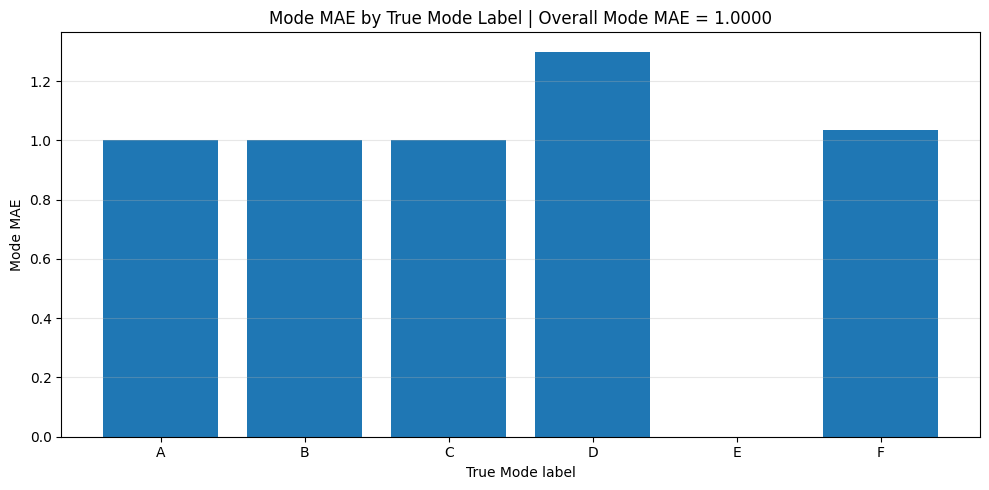

Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/wa_mae_by_rounded_true_wa_label.png


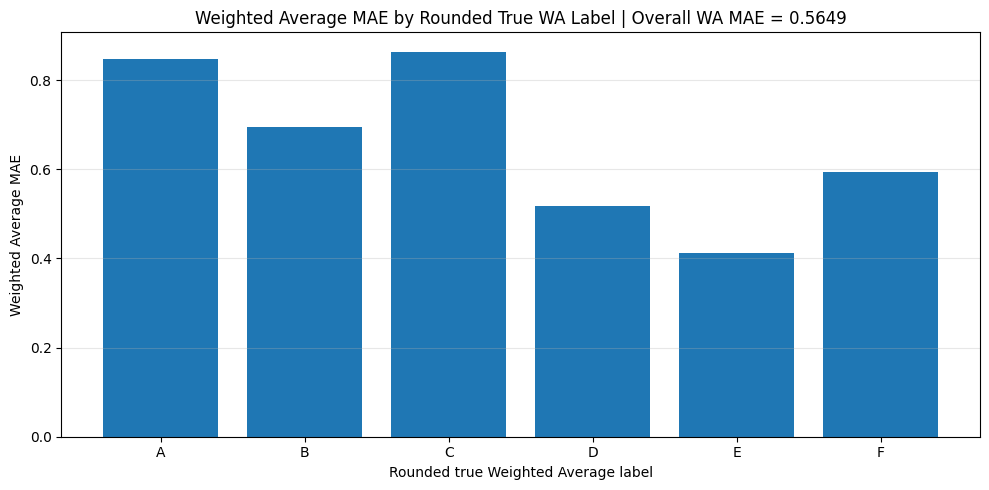

In [ ]:
# Run image-level MAE/RMSE evaluation
merged_csv_path = MERGED_TEST_CSV

output_folder = IMAGE_ERROR_DIR

overall, mode_per_label, wa_per_label, per_label, merged_with_errors = (
    evaluate_mode_and_wa_errors_from_merged_csv(
        merged_csv_path=merged_csv_path,
        output_folder=output_folder,
        show_plots=True
    )
)

Overall, the mode had an MAE of 1.000 class, while the weighted average had a lower MAE of 0.565 class and an RMSE of 0.782 (mode RMSE 1.432). The weighted-average bias was 0.027, close to zero, indicating little systematic over- or underestimation overall; the mode bias was −0.119. Per-label results (Table 5 of the manuscript) show that mode errors were largest for classes D (1.30) and F (1.04), while class E had zero error in this test set. The weighted average showed lower MAE than the mode for every class except E (0.41 against 0), with the largest reductions for classes D (from 1.30 to 0.52) and F (from 1.04 to 0.59). Its largest errors occurred in the lower classes A to C (0.85, 0.69 and 0.86), where it tended to overestimate severity (bias +0.85, +0.69 and +0.62), while E and F were underestimated (bias −0.34 and −0.55). Some groups are small (2 images for B and 4 for E under the mode), so the values for these classes should be read with caution.

A weighted average summarises the full distribution of classes in an image, so an image can receive a score of C without containing any C pixels. As the manuscript notes, the mode may therefore remain the more useful label operationally, even though its error is larger.

The second function examines the weighted-average errors image by image: their distribution, the share of images within 0.5 and within 1 damage level of the ground truth, the direction of the errors, and the ten images with the largest absolute error. Errors are grouped here by the true mode rather than by the rounded weighted average, which is why the per-label values differ from the weighted-average rows of the table above.

In [ ]:
# Image-level weighted-average error analysis
def analyze_image_level_weighted_average_errors(
    merged_csv_path,
    output_folder=None,
    top_n=10,
    show_plots=True
):
    """
    Analyzes image-level weighted-average prediction errors.

    Expected columns:
    - Filename_GT
    - Mode_GT
    - Mode_Pred
    - Weighted Average_GT
    - Weighted Average_Pred

    Returns
    -------
    df_error : pandas.DataFrame
        Full image-level table with weighted-average error columns.

    summary_df : pandas.DataFrame
        Overall error summary.

    per_label_df : pandas.DataFrame
        Error summary grouped by Mode_GT.

    worst_errors_df : pandas.DataFrame
        Top-N images with largest absolute weighted-average error.
    """

    # 1. Load data
    df = pd.read_csv(merged_csv_path)
    df.columns = df.columns.str.strip()

    print("Loaded merged CSV:")
    print(merged_csv_path)
    print("Shape:", df.shape)

    # 2. Check required columns
    required_cols = [
        "Filename_GT",
        "Mode_GT",
        "Mode_Pred",
        "Weighted Average_GT",
        "Weighted Average_Pred"
    ]

    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}\n"
            f"Available columns: {list(df.columns)}"
        )

    # 3. Convert columns to numeric
    numeric_cols = [
        "Mode_GT",
        "Mode_Pred",
        "Weighted Average_GT",
        "Weighted Average_Pred"
    ]

    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    before_drop = len(df)

    df = df.dropna(
        subset=[
            "Mode_GT",
            "Mode_Pred",
            "Weighted Average_GT",
            "Weighted Average_Pred"
        ]
    ).copy()

    after_drop = len(df)

    if before_drop != after_drop:
        print(f"Warning: dropped {before_drop - after_drop} rows with missing score values.")

    if len(df) == 0:
        raise ValueError("No valid rows remain after dropping missing score values.")

    # 4. Calculate weighted-average errors
    df["WA_Error"] = df["Weighted Average_Pred"] - df["Weighted Average_GT"]
    df["WA_Absolute_Error"] = df["WA_Error"].abs()
    df["WA_Squared_Error"] = df["WA_Error"] ** 2

    df["Mode_Error"] = df["Mode_Pred"] - df["Mode_GT"]
    df["Mode_Absolute_Error"] = df["Mode_Error"].abs()

    def classify_error_direction(err):
        if err > 0:
            return "Overestimate"
        elif err < 0:
            return "Underestimate"
        else:
            return "Exact"

    df["WA_Error_Direction"] = df["WA_Error"].apply(classify_error_direction)

    # Optional rounded versions for easier interpretation
    df["WA_GT_Rounded"] = np.rint(df["Weighted Average_GT"]).astype(int)
    df["WA_Pred_Rounded"] = np.rint(df["Weighted Average_Pred"]).astype(int)
    df["WA_Rounded_Error"] = df["WA_Pred_Rounded"] - df["WA_GT_Rounded"]

    # 5. Overall summary
    summary = {
        "N": len(df),
        "WA_MAE": df["WA_Absolute_Error"].mean(),
        "WA_RMSE": np.sqrt(df["WA_Squared_Error"].mean()),
        "WA_Bias": df["WA_Error"].mean(),
        "WA_Median_Absolute_Error": df["WA_Absolute_Error"].median(),
        "WA_Max_Absolute_Error": df["WA_Absolute_Error"].max(),
        "Overestimate_Rate": (df["WA_Error"] > 0).mean(),
        "Underestimate_Rate": (df["WA_Error"] < 0).mean(),
        "Within_0.5_Class_Rate": (df["WA_Absolute_Error"] <= 0.5).mean(),
        "Within_1_Class_Rate": (df["WA_Absolute_Error"] <= 1.0).mean(),
        "Mode_MAE": df["Mode_Absolute_Error"].mean(),
        "Mode_RMSE": np.sqrt((df["Mode_Error"] ** 2).mean())
    }

    summary_df = pd.DataFrame([summary])

    print("\nOverall weighted-average error summary:")
    display(summary_df)

    # 6. Per true Mode_GT label summary
    per_label_df = (
        df
        .groupby("Mode_GT")
        .agg(
            N=("WA_Error", "size"),
            WA_MAE=("WA_Absolute_Error", "mean"),
            WA_RMSE=("WA_Squared_Error", lambda x: np.sqrt(np.mean(x))),
            WA_Bias=("WA_Error", "mean"),
            WA_Median_Absolute_Error=("WA_Absolute_Error", "median"),
            WA_Max_Absolute_Error=("WA_Absolute_Error", "max"),
            Overestimate_Rate=("WA_Error", lambda x: (x > 0).mean()),
            Underestimate_Rate=("WA_Error", lambda x: (x < 0).mean()),
            Within_0_5_Class_Rate=("WA_Absolute_Error", lambda x: (x <= 0.5).mean()),
            Within_1_Class_Rate=("WA_Absolute_Error", lambda x: (x <= 1.0).mean()),
            Mode_MAE=("Mode_Absolute_Error", "mean")
        )
        .reset_index()
        .sort_values("Mode_GT")
    )

    print("\nWeighted-average error by true Mode_GT:")
    display(per_label_df)

    # 7. Worst image-level errors
    display_cols = [
        "Filename_GT",
        "Mode_GT",
        "Mode_Pred",
        "Weighted Average_GT",
        "Weighted Average_Pred",
        "WA_Error",
        "WA_Absolute_Error",
        "WA_Error_Direction",
        "GT Classes",
        "Predicted Classes"
    ]

    display_cols = [col for col in display_cols if col in df.columns]

    worst_errors_df = (
        df
        .sort_values("WA_Absolute_Error", ascending=False)
        .head(top_n)
        .copy()
    )

    print(f"\nTop {top_n} worst weighted-average image-level errors:")
    display(worst_errors_df[display_cols])

    # 8. Save tables
    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        full_error_path = os.path.join(
            output_folder,
            "image_level_weighted_average_errors_full.csv"
        )

        summary_path = os.path.join(
            output_folder,
            "image_level_weighted_average_errors_summary.csv"
        )

        per_label_path = os.path.join(
            output_folder,
            "image_level_weighted_average_errors_by_true_mode.csv"
        )

        worst_path = os.path.join(
            output_folder,
            f"top_{top_n}_worst_weighted_average_errors.csv"
        )

        df.to_csv(full_error_path, index=False)
        summary_df.to_csv(summary_path, index=False)
        per_label_df.to_csv(per_label_path, index=False)
        worst_errors_df.to_csv(worst_path, index=False)

        print("\nSaved tables:")
        print(full_error_path)
        print(summary_path)
        print(per_label_path)
        print(worst_path)

    # 9. Plots

    # Histogram of signed error
    plt.figure(figsize=(9, 5))
    plt.hist(df["WA_Error"], bins=12, edgecolor="black")
    plt.axvline(0, linestyle="--", linewidth=1)
    plt.xlabel("Weighted Average Error = Pred - GT")
    plt.ylabel("Number of images")
    plt.title("Distribution of Signed Weighted-Average Errors")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "histogram_signed_wa_error.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # Histogram of absolute error
    plt.figure(figsize=(9, 5))
    plt.hist(df["WA_Absolute_Error"], bins=12, edgecolor="black")
    plt.xlabel("Absolute Weighted Average Error")
    plt.ylabel("Number of images")
    plt.title("Distribution of Absolute Weighted-Average Errors")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "histogram_absolute_wa_error.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # Bar plot: MAE by true Mode_GT
    plt.figure(figsize=(9, 5))
    plt.bar(per_label_df["Mode_GT"].astype(int), per_label_df["WA_MAE"])
    plt.xlabel("True Mode_GT label")
    plt.ylabel("Weighted Average MAE")
    plt.title("Weighted-Average MAE by True Mode_GT")
    plt.xticks(per_label_df["Mode_GT"].astype(int))
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "wa_mae_by_true_mode_gt.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # Boxplot: signed error by true Mode_GT
    labels = sorted(df["Mode_GT"].dropna().unique())
    data_by_label = [
        df.loc[df["Mode_GT"] == label, "WA_Error"].values
        for label in labels
    ]

    plt.figure(figsize=(9, 5))
    plt.boxplot(data_by_label, labels=[str(int(label)) for label in labels])
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.xlabel("True Mode_GT label")
    plt.ylabel("Weighted Average Error = Pred - GT")
    plt.title("Signed Weighted-Average Error by True Mode_GT")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "boxplot_signed_wa_error_by_true_mode_gt.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # Boxplot: absolute error by true Mode_GT
    data_by_label_abs = [
        df.loc[df["Mode_GT"] == label, "WA_Absolute_Error"].values
        for label in labels
    ]

    plt.figure(figsize=(9, 5))
    plt.boxplot(data_by_label_abs, labels=[str(int(label)) for label in labels])
    plt.xlabel("True Mode_GT label")
    plt.ylabel("Absolute Weighted Average Error")
    plt.title("Absolute Weighted-Average Error by True Mode_GT")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "boxplot_absolute_wa_error_by_true_mode_gt.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    return df, summary_df, per_label_df, worst_errors_df

Loaded merged CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/merged_gt_pred_test_image_level_scores.csv
Shape: (59, 18)

Overall weighted-average error summary:


,N,WA_MAE,WA_RMSE,WA_Bias,WA_Median_Absolute_Error,WA_Max_Absolute_Error,Overestimate_Rate,Underestimate_Rate,Within_0.5_Class_Rate,Within_1_Class_Rate,Mode_MAE,Mode_RMSE
0,59,0.564876,0.782236,0.027412,0.408148,2.908097,0.457627,0.542373,0.59322,0.813559,1.0,1.432078



Weighted-average error by true Mode_GT:


,Mode_GT,N,WA_MAE,WA_RMSE,WA_Bias,WA_Median_Absolute_Error,WA_Max_Absolute_Error,Overestimate_Rate,Underestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate,Mode_MAE
0,3,8,0.846477,1.038412,0.846477,0.892525,1.785764,1.000000,0.000000,0.375000,0.500000,1.000000
1,4,2,0.694091,0.757138,0.694091,0.694091,0.996574,1.000000,0.000000,0.500000,1.000000,1.000000
2,5,7,0.705652,1.164760,0.351541,0.380859,2.908097,0.428571,0.571429,0.714286,0.857143,1.000000
3,6,10,0.634607,0.772250,0.014869,0.736309,1.304582,0.600000,0.400000,0.400000,0.800000,1.300000
4,7,4,0.256988,0.318559,-0.256988,0.261379,0.471861,0.000000,1.000000,1.000000,1.000000,0.000000
5,8,28,0.459076,0.611278,-0.290151,0.327779,1.359270,0.285714,0.714286,0.642857,0.857143,1.035714



Top 10 worst weighted-average image-level errors:


,Filename_GT,Mode_GT,Mode_Pred,Weighted Average_GT,Weighted Average_Pred,WA_Error,WA_Absolute_Error,WA_Error_Direction,GT Classes,Predicted Classes
20,6269F227-5B6F-48A4-A5BA-4DA0F809ECA9.jpg,5,8,5.000000,7.908097,2.908097,2.908097,Overestimate,"[0, 5]","[0, 2, 4, 5, 6, 7, 8]"
33,Bizim_mekan_nargile_cafe_-_panoramio.jpg.jpg,3,5,3.000000,4.785764,1.785764,1.785764,Overestimate,"[0, 1, 3]","[0, 1, 2, 3, 4, 5, 6, 7, 8]"
28,8844779C-8F37-4EA8-9593-E82B97869B1B.jpg,8,5,6.177724,4.818454,-1.359270,1.359270,Underestimate,"[0, 3, 5, 8]","[0, 1, 2, 3, 4, 5, 6, 7, 8]"
18,MOZAIK_KADIN_DOGUM_HASTANESI_-_panoramio.jpg.jpg,3,5,3.000000,4.344434,1.344434,1.344434,Overestimate,"[0, 1, 2, 3]","[0, 1, 2, 3, 4, 5, 6, 8]"
27,FAEB5345-2C23-4AF0-8A3F-3B5D19D14C64.jpg,6,5,6.846771,5.542189,-1.304582,1.304582,Underestimate,"[0, 6, 7, 8]","[0, 1, 2, 3, 4, 5, 6, 7, 8]"
12,EL_KADIM_TURBESI_-_panoramio.jpg.jpg,3,5,3.000000,4.298375,1.298375,1.298375,Overestimate,"[0, 1, 2, 3]","[0, 1, 2, 3, 4, 5, 6, 8]"
21,451DBC30-C4F6-4961-8B2D-D223D5B3D20C.jpg,6,7,5.641228,6.929900,1.288671,1.288671,Overestimate,"[0, 4, 6]","[0, 1, 4, 6, 7, 8]"
3,BA7A9046-BD7E-4862-850D-A9B2DE988431.jpg,8,6,7.555524,6.268295,-1.287230,1.287230,Underestimate,"[0, 2, 7, 8]","[0, 1, 2, 4, 5, 6, 7, 8]"
13,C0321E11-988C-4759-BD4F-48BE594C83C0.jpg,8,4,7.008326,5.742305,-1.266021,1.266021,Underestimate,"[0, 6, 8]","[0, 1, 2, 4, 5, 6, 7, 8]"
10,757195134945957.jpg,3,5,3.000000,4.220276,1.220276,1.220276,Overestimate,"[0, 1, 3]","[0, 1, 2, 3, 4, 5, 8]"



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/image_level_weighted_average_errors_full.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/image_level_weighted_average_errors_summary.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/image_level_weighted_average_errors_by_true_mode.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/top_10_worst_weighted_average_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/histogram_signed_wa_error.png


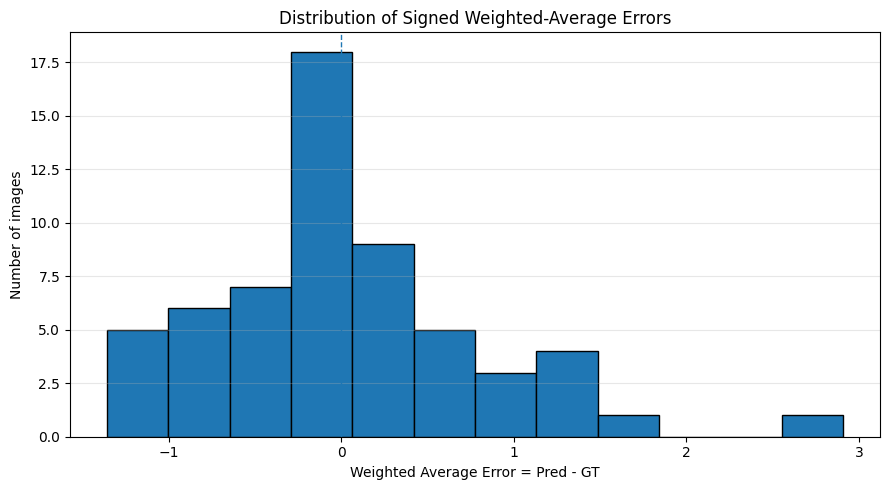

Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/histogram_absolute_wa_error.png


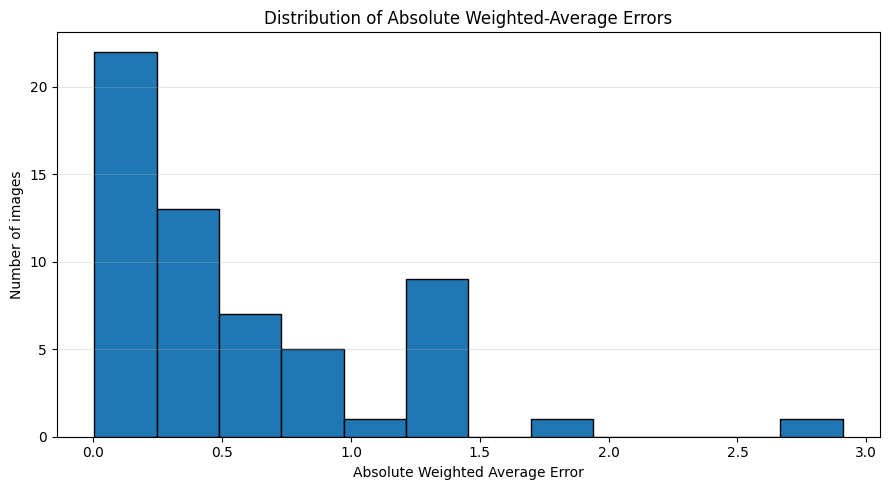

Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/wa_mae_by_true_mode_gt.png


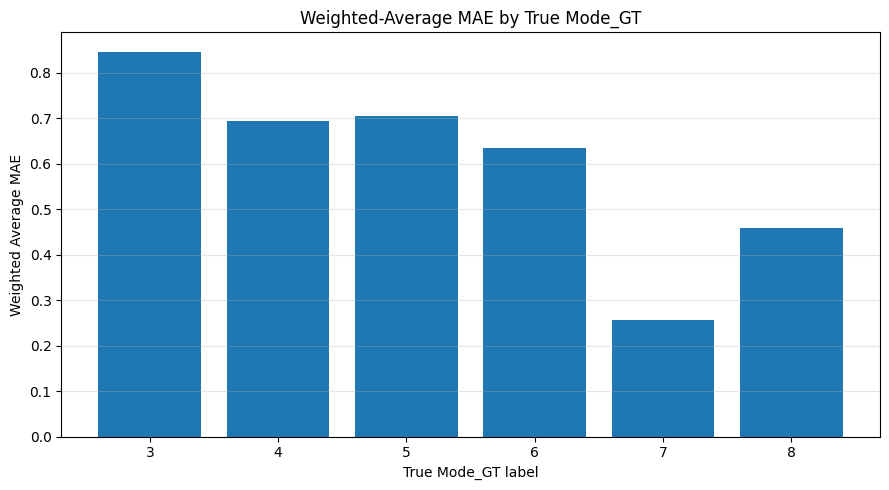

/tmp/ipykernel_5754/2075012929.py:321: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_by_label, labels=[str(int(label)) for label in labels])


Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/boxplot_signed_wa_error_by_true_mode_gt.png


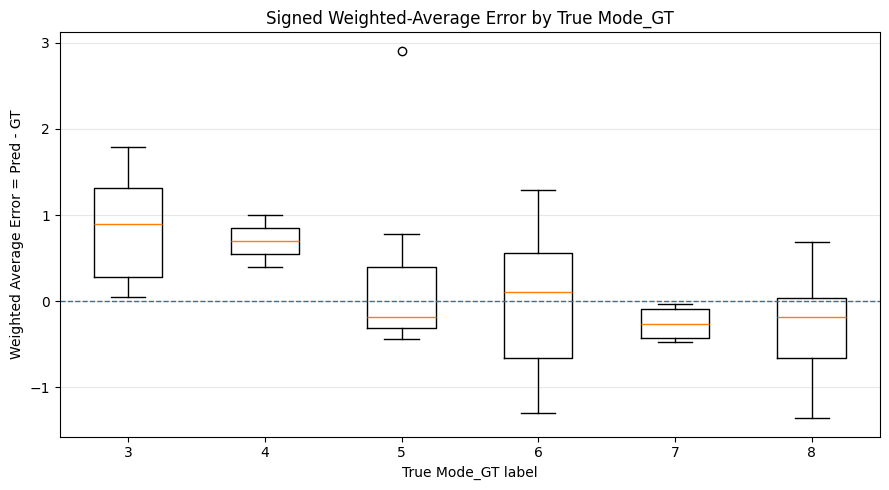

/tmp/ipykernel_5754/2075012929.py:346: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_by_label_abs, labels=[str(int(label)) for label in labels])


Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/image_level_error_analysis/boxplot_absolute_wa_error_by_true_mode_gt.png


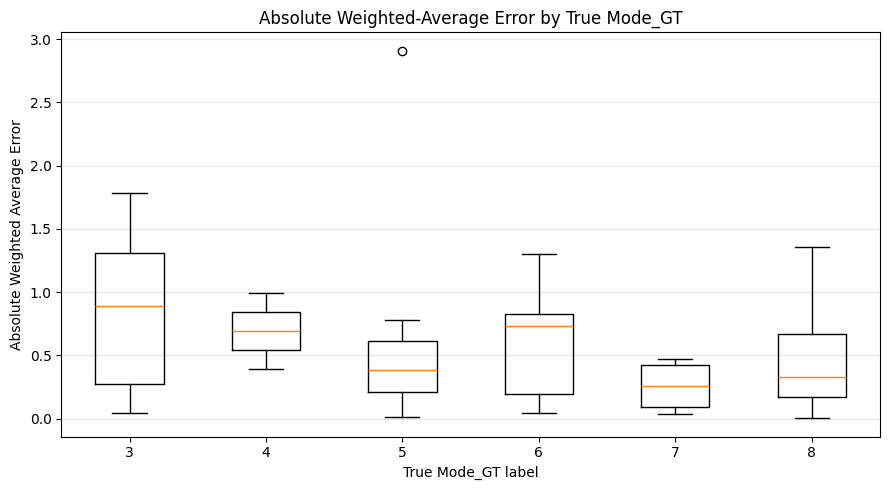

In [ ]:
merged_csv_path = MERGED_TEST_CSV

output_folder = IMAGE_ERROR_DIR

df_image_errors, image_error_summary, image_error_by_label, worst_image_errors = analyze_image_level_weighted_average_errors(
    merged_csv_path=merged_csv_path,
    output_folder=output_folder,
    top_n=10,
    show_plots=True
)

Of the 59 test images, 59.3% had a weighted-average score within 0.5 of the ground truth and 81.4% within one damage level. Errors were nearly balanced in direction (45.8% overestimates, 54.2% underestimates; median absolute error 0.41). Grouped by true mode, the direction depends on severity: all images with true mode A or B were overestimated, while all true-E images and 71.4% of true-F images were underestimated (bias −0.26 and −0.29). The largest single error was an overestimate of 2.91 for an image with true mode C, whose predicted mask contained seven classes against two in the ground-truth mask; six of the ten largest errors were overestimates. This is consistent with predicted masks distributing pixels over more classes than the annotations.

## 4. Data imbalance diagnostics

The six damage labels are unevenly represented, so we check whether label frequency explains the per-label errors. The function compares the distribution of the true mode in the test set with that in all 361 annotated masks (from notebook 01's `full_dataset_gt_image_level_aggregations_from_raw_masks.csv`), adds the mean number of classes present in the ground-truth and the predicted masks, and computes Pearson correlations between label frequency, class mixture and error across the six labels. With six labels, a correlation must exceed about 0.81 in absolute value to be significant at the 5% level, so these coefficients are descriptive. The plots show the two distributions, frequency against error, bias and error direction per label, and error against the number of classes present in an image.

In [ ]:
# Data imbalance / data scarcity diagnostics for image-level errors
def analyze_data_imbalance_effects(
    merged_test_csv_path,
    all_gt_csv_path=None,
    output_folder=None,
    show_plots=True
):
    """
    Analyzes whether data imbalance, class mixture, and triage-pixel coverage
    may explain image-level weighted-average prediction errors.

    Main input:
    - merged_test_csv_path:
      merged GT/pred test CSV with:
        Mode_GT
        Mode_Pred
        Weighted Average_GT
        Weighted Average_Pred
        GT Classes
        Predicted Classes

    Optional input:
    - all_gt_csv_path:
      all GT image-level CSV with:
        Mode
        Weighted Average
        GT Classes
        Num Triage Pixels

    Outputs:
    - test error table
    - distribution comparison table
    - per-label error table
    - plots
    """

    # 1. Load test merged CSV
    test_df = pd.read_csv(merged_test_csv_path)
    test_df.columns = test_df.columns.str.strip()

    print("Loaded test CSV:")
    print(merged_test_csv_path)
    print("Test shape:", test_df.shape)

    required_test_cols = [
        "Mode_GT",
        "Mode_Pred",
        "Weighted Average_GT",
        "Weighted Average_Pred"
    ]

    missing = [c for c in required_test_cols if c not in test_df.columns]
    if missing:
        raise ValueError(
            f"Missing required test columns: {missing}\n"
            f"Available columns: {list(test_df.columns)}"
        )

    for col in required_test_cols:
        test_df[col] = pd.to_numeric(test_df[col], errors="coerce")

    test_df = test_df.dropna(subset=required_test_cols).copy()

    # 2. Add image-level error columns
    test_df["WA_Error"] = test_df["Weighted Average_Pred"] - test_df["Weighted Average_GT"]
    test_df["WA_Absolute_Error"] = test_df["WA_Error"].abs()
    test_df["WA_Squared_Error"] = test_df["WA_Error"] ** 2

    test_df["Mode_Error"] = test_df["Mode_Pred"] - test_df["Mode_GT"]
    test_df["Mode_Absolute_Error"] = test_df["Mode_Error"].abs()

    test_df["WA_Error_Direction"] = np.where(
        test_df["WA_Error"] > 0,
        "Overestimate",
        np.where(test_df["WA_Error"] < 0, "Underestimate", "Exact")
    )

    # 3. Helper for parsing GT Classes / Predicted Classes
    def parse_class_list(x):
        """
        Converts strings like '[0, 2, 8]' into Python lists.
        If already list-like, returns list.
        """
        if isinstance(x, list):
            return x

        if pd.isna(x):
            return []

        if isinstance(x, str):
            try:
                parsed = ast.literal_eval(x)
                if isinstance(parsed, (list, tuple, set)):
                    return list(parsed)
                return [parsed]
            except Exception:
                return []

        return []

    if "GT Classes" in test_df.columns:
        test_df["GT_Classes_List"] = test_df["GT Classes"].apply(parse_class_list)
        test_df["GT_Num_Classes"] = test_df["GT_Classes_List"].apply(len)
        test_df["GT_Num_Triage_Classes"] = test_df["GT_Classes_List"].apply(
            lambda vals: sum(int(v) in [3, 4, 5, 6, 7, 8] for v in vals)
        )
    else:
        test_df["GT_Classes_List"] = [[] for _ in range(len(test_df))]
        test_df["GT_Num_Classes"] = np.nan
        test_df["GT_Num_Triage_Classes"] = np.nan

    if "Predicted Classes" in test_df.columns:
        test_df["Pred_Classes_List"] = test_df["Predicted Classes"].apply(parse_class_list)
        test_df["Pred_Num_Classes"] = test_df["Pred_Classes_List"].apply(len)
        test_df["Pred_Num_Triage_Classes"] = test_df["Pred_Classes_List"].apply(
            lambda vals: sum(int(v) in [3, 4, 5, 6, 7, 8] for v in vals)
        )
    else:
        test_df["Pred_Classes_List"] = [[] for _ in range(len(test_df))]
        test_df["Pred_Num_Classes"] = np.nan
        test_df["Pred_Num_Triage_Classes"] = np.nan

    # 4. Per-label error summary
    per_label_error = (
        test_df
        .groupby("Mode_GT")
        .agg(
            N_Test=("WA_Error", "size"),
            WA_MAE=("WA_Absolute_Error", "mean"),
            WA_RMSE=("WA_Squared_Error", lambda x: np.sqrt(np.mean(x))),
            WA_Bias=("WA_Error", "mean"),
            WA_Median_Abs_Error=("WA_Absolute_Error", "median"),
            WA_Max_Abs_Error=("WA_Absolute_Error", "max"),
            Underestimate_Rate=("WA_Error", lambda x: (x < 0).mean()),
            Overestimate_Rate=("WA_Error", lambda x: (x > 0).mean()),
            Within_0_5=("WA_Absolute_Error", lambda x: (x <= 0.5).mean()),
            Within_1_0=("WA_Absolute_Error", lambda x: (x <= 1.0).mean()),
            Mode_MAE=("Mode_Absolute_Error", "mean"),
            Mean_GT_Num_Classes=("GT_Num_Classes", "mean"),
            Mean_Pred_Num_Classes=("Pred_Num_Classes", "mean")
        )
        .reset_index()
        .sort_values("Mode_GT")
    )

    print("\nPer-label test error summary:")
    display(per_label_error)

    # 5. Test-set distribution
    label_range = list(range(3, 9))

    test_dist = (
        test_df["Mode_GT"]
        .value_counts()
        .reindex(label_range, fill_value=0)
        .rename_axis("Mode_Label")
        .reset_index(name="Test_N")
    )

    test_dist["Test_Percent"] = 100 * test_dist["Test_N"] / test_dist["Test_N"].sum()

    # 6. Optional full-GT distribution comparison
    if all_gt_csv_path is not None:

        all_gt_df = pd.read_csv(all_gt_csv_path)
        all_gt_df.columns = all_gt_df.columns.str.strip()

        print("\nLoaded all-GT CSV:")
        print(all_gt_csv_path)
        print("All-GT shape:", all_gt_df.shape)

        if "Mode" not in all_gt_df.columns:
            raise ValueError(
                f"all_gt_csv_path must contain a 'Mode' column.\n"
                f"Available columns: {list(all_gt_df.columns)}"
            )

        all_gt_df["Mode"] = pd.to_numeric(all_gt_df["Mode"], errors="coerce")
        all_gt_df = all_gt_df.dropna(subset=["Mode"]).copy()

        full_dist = (
            all_gt_df["Mode"]
            .value_counts()
            .reindex(label_range, fill_value=0)
            .rename_axis("Mode_Label")
            .reset_index(name="Full_GT_N")
        )

        full_dist["Full_GT_Percent"] = 100 * full_dist["Full_GT_N"] / full_dist["Full_GT_N"].sum()

        distribution_comparison = full_dist.merge(
            test_dist,
            on="Mode_Label",
            how="outer"
        ).fillna(0)

        distribution_comparison["Test_minus_Full_Percent"] = (
            distribution_comparison["Test_Percent"] -
            distribution_comparison["Full_GT_Percent"]
        )

    else:
        distribution_comparison = test_dist.copy()

    print("\nClass distribution comparison:")
    display(distribution_comparison)

    # 7. Merge distribution info into per-label error table
    label_error_with_distribution = per_label_error.merge(
        distribution_comparison,
        left_on="Mode_GT",
        right_on="Mode_Label",
        how="left"
    )

    print("\nPer-label error + distribution:")
    display(label_error_with_distribution)

    # 8. Correlations: does frequency / mixture relate to error?
    correlation_rows = []

    possible_pairs = [
        ("N_Test", "WA_MAE"),
        ("N_Test", "WA_Bias"),
        ("N_Test", "Underestimate_Rate"),
        ("Test_Percent", "WA_MAE"),
        ("Mean_GT_Num_Classes", "WA_MAE"),
        ("Mean_Pred_Num_Classes", "WA_MAE"),
    ]

    if "Full_GT_N" in label_error_with_distribution.columns:
        possible_pairs.extend([
            ("Full_GT_N", "WA_MAE"),
            ("Full_GT_Percent", "WA_MAE"),
        ])

    for x_col, y_col in possible_pairs:
        if x_col in label_error_with_distribution.columns and y_col in label_error_with_distribution.columns:
            tmp = label_error_with_distribution[[x_col, y_col]].dropna()
            if len(tmp) >= 3:
                corr = tmp[x_col].corr(tmp[y_col])
            else:
                corr = np.nan

            correlation_rows.append({
                "X": x_col,
                "Y": y_col,
                "Pearson_Correlation": corr,
                "N_Labels": len(tmp)
            })

    correlation_df = pd.DataFrame(correlation_rows)

    print("\nSimple label-level correlations:")
    display(correlation_df)

    # 9. Save tables
    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        test_error_path = os.path.join(output_folder, "imbalance_test_image_error_table.csv")
        per_label_path = os.path.join(output_folder, "imbalance_per_label_error_summary.csv")
        dist_path = os.path.join(output_folder, "imbalance_class_distribution_comparison.csv")
        merged_path = os.path.join(output_folder, "imbalance_label_error_with_distribution.csv")
        corr_path = os.path.join(output_folder, "imbalance_error_correlation_summary.csv")

        test_df.to_csv(test_error_path, index=False)
        per_label_error.to_csv(per_label_path, index=False)
        distribution_comparison.to_csv(dist_path, index=False)
        label_error_with_distribution.to_csv(merged_path, index=False)
        correlation_df.to_csv(corr_path, index=False)

        print("\nSaved tables:")
        print(test_error_path)
        print(per_label_path)
        print(dist_path)
        print(merged_path)
        print(corr_path)

    # 10. Plots

    # Make sure labels are clean integers for plotting
    distribution_comparison["Mode_Label"] = distribution_comparison["Mode_Label"].astype(int)
    label_error_with_distribution["Mode_GT"] = label_error_with_distribution["Mode_GT"].astype(int)

    # Optional human-readable class labels
    class_name_map = {
        3: "A",
        4: "B",
        5: "C",
        6: "D",
        7: "E",
        8: "F"
    }

    distribution_comparison["Mode_Label_Name"] = distribution_comparison["Mode_Label"].map(
        lambda x: f"{x} ({class_name_map.get(x, x)})"
    )

    label_error_with_distribution["Mode_Label_Name"] = label_error_with_distribution["Mode_GT"].map(
        lambda x: f"{x} ({class_name_map.get(x, x)})"
    )

    # Plot 1: Full vs test class distribution
    plt.figure(figsize=(9, 5))

    x = np.arange(len(distribution_comparison))
    width = 0.35

    if "Full_GT_Percent" in distribution_comparison.columns:
        plt.bar(
            x - width / 2,
            distribution_comparison["Full_GT_Percent"],
            width=width,
            label="Full GT dataset"
        )
        plt.bar(
            x + width / 2,
            distribution_comparison["Test_Percent"],
            width=width,
            label="Test set"
        )
        ylabel = "Percent of images"
        title = "Image-Level Mode Distribution: Full GT vs Test Set"
    else:
        plt.bar(
            x,
            distribution_comparison["Test_Percent"],
            width=0.5,
            label="Test set"
        )
        ylabel = "Percent of test images"
        title = "Image-Level Mode Distribution: Test Set"

    plt.xlabel("Mode label")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(x, distribution_comparison["Mode_Label_Name"])
    plt.legend()
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "plot_full_vs_test_mode_distribution.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # Plot 2: Class frequency and WA MAE by true class
    # Better than scatter: directly compares scarcity and error per class
    plt.figure(figsize=(10, 5))

    x = np.arange(len(label_error_with_distribution))

    if "Full_GT_N" in label_error_with_distribution.columns:
        frequency_col = "Full_GT_N"
        frequency_label = "Full GT images"
        title = "Class Scarcity and Weighted-Average Error by True Mode_GT"
    else:
        frequency_col = "N_Test"
        frequency_label = "Test images"
        title = "Test-Set Class Frequency and Weighted-Average Error by True Mode_GT"

    ax1 = plt.gca()

    ax1.bar(
        x,
        label_error_with_distribution[frequency_col],
        width=0.55,
        label=frequency_label,
        alpha=0.75
    )

    ax1.set_xlabel("True Mode_GT label")
    ax1.set_ylabel(frequency_label)
    ax1.set_xticks(x)
    ax1.set_xticklabels(label_error_with_distribution["Mode_Label_Name"])
    ax1.grid(True, axis="y", alpha=0.3)

    ax2 = ax1.twinx()

    ax2.plot(
        x,
        label_error_with_distribution["WA_MAE"],
        marker="o",
        linewidth=2,
        label="WA MAE"
    )

    ax2.set_ylabel("Weighted Average MAE")

    # Combine legends from both axes
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right")

    plt.title(title)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "plot_class_frequency_and_wa_mae_by_true_mode.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # Plot 3: Bias by true class
    plt.figure(figsize=(9, 5))

    plt.bar(
        label_error_with_distribution["Mode_Label_Name"],
        label_error_with_distribution["WA_Bias"]
    )

    plt.axhline(0, linestyle="--", linewidth=1)

    plt.xlabel("True Mode_GT label")
    plt.ylabel("WA Bias = Pred - GT")
    plt.title("Weighted-Average Bias by True Mode_GT")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "plot_wa_bias_by_true_mode.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # Plot 4: Underestimation / exact / overestimation by true class
    # More interpretable than one scatterplot
    direction_summary = (
        test_df
        .groupby("Mode_GT")["WA_Error_Direction"]
        .value_counts(normalize=True)
        .unstack(fill_value=0)
        .reset_index()
    )

    for col in ["Underestimate", "Exact", "Overestimate"]:
        if col not in direction_summary.columns:
            direction_summary[col] = 0.0

    direction_summary["Mode_GT"] = direction_summary["Mode_GT"].astype(int)
    direction_summary = direction_summary.sort_values("Mode_GT")

    direction_summary["Mode_Label_Name"] = direction_summary["Mode_GT"].map(
        lambda x: f"{x} ({class_name_map.get(x, x)})"
    )

    plt.figure(figsize=(10, 5))

    x = np.arange(len(direction_summary))

    under = direction_summary["Underestimate"] * 100
    exact = direction_summary["Exact"] * 100
    over = direction_summary["Overestimate"] * 100

    plt.bar(x, under, label="Underestimate")
    plt.bar(x, exact, bottom=under, label="Exact")
    plt.bar(x, over, bottom=under + exact, label="Overestimate")

    plt.xlabel("True Mode_GT label")
    plt.ylabel("Percent of test images")
    plt.title("Weighted-Average Error Direction by True Mode_GT")
    plt.xticks(x, direction_summary["Mode_Label_Name"])
    plt.ylim(0, 100)
    plt.legend()
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()

    if output_folder is not None:
        path = os.path.join(output_folder, "plot_wa_error_direction_by_true_mode.png")
        plt.savefig(path, dpi=300)
        print("Saved plot:", path)

    if show_plots:
        plt.show()
    else:
        plt.close()

    # Plot 5: GT class mixture vs WA absolute error
    # Boxplot instead of scatter
    if test_df["GT_Num_Classes"].notna().any():

        box_df = test_df.dropna(subset=["GT_Num_Classes", "WA_Absolute_Error"]).copy()
        box_df["GT_Num_Classes"] = box_df["GT_Num_Classes"].astype(int)

        groups = []
        labels = []

        for n_classes in sorted(box_df["GT_Num_Classes"].unique()):
            vals = box_df.loc[
                box_df["GT_Num_Classes"] == n_classes,
                "WA_Absolute_Error"
            ].values

            if len(vals) > 0:
                groups.append(vals)
                labels.append(str(n_classes))

        if len(groups) > 0:
            plt.figure(figsize=(9, 5))

            plt.boxplot(groups, labels=labels, showmeans=True)

            plt.xlabel("Number of GT classes present in image")
            plt.ylabel("Weighted Average Absolute Error")
            plt.title("GT Class Mixture vs Weighted-Average Error")
            plt.grid(True, axis="y", alpha=0.3)
            plt.tight_layout()

            if output_folder is not None:
                path = os.path.join(output_folder, "plot_gt_num_classes_vs_wa_abs_error_boxplot.png")
                plt.savefig(path, dpi=300)
                print("Saved plot:", path)

            if show_plots:
                plt.show()
            else:
                plt.close()

    # Plot 6: Predicted class mixture vs WA absolute error
    # Boxplot instead of scatter
    if test_df["Pred_Num_Classes"].notna().any():

        box_df = test_df.dropna(subset=["Pred_Num_Classes", "WA_Absolute_Error"]).copy()
        box_df["Pred_Num_Classes"] = box_df["Pred_Num_Classes"].astype(int)

        groups = []
        labels = []

        for n_classes in sorted(box_df["Pred_Num_Classes"].unique()):
            vals = box_df.loc[
                box_df["Pred_Num_Classes"] == n_classes,
                "WA_Absolute_Error"
            ].values

            if len(vals) > 0:
                groups.append(vals)
                labels.append(str(n_classes))

        if len(groups) > 0:
            plt.figure(figsize=(9, 5))

            plt.boxplot(groups, labels=labels, showmeans=True)

            plt.xlabel("Number of predicted classes present in image")
            plt.ylabel("Weighted Average Absolute Error")
            plt.title("Predicted Class Spread vs Weighted-Average Error")
            plt.grid(True, axis="y", alpha=0.3)
            plt.tight_layout()

            if output_folder is not None:
                path = os.path.join(output_folder, "plot_pred_num_classes_vs_wa_abs_error_boxplot.png")
                plt.savefig(path, dpi=300)
                print("Saved plot:", path)

            if show_plots:
                plt.show()
            else:
                plt.close()

    return {
        "test_error_df": test_df,
        "per_label_error_df": per_label_error,
        "distribution_comparison_df": distribution_comparison,
        "label_error_with_distribution_df": label_error_with_distribution,
        "correlation_df": correlation_df
    }

Loaded test CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/merged_gt_pred_test_image_level_scores.csv
Test shape: (59, 18)

Per-label test error summary:


,Mode_GT,N_Test,WA_MAE,WA_RMSE,WA_Bias,WA_Median_Abs_Error,WA_Max_Abs_Error,Underestimate_Rate,Overestimate_Rate,Within_0_5,Within_1_0,Mode_MAE,Mean_GT_Num_Classes,Mean_Pred_Num_Classes
0,3,8,0.846477,1.038412,0.846477,0.892525,1.785764,0.000000,1.000000,0.375000,0.500000,1.000000,3.500000,7.750000
1,4,2,0.694091,0.757138,0.694091,0.694091,0.996574,0.000000,1.000000,0.500000,1.000000,1.000000,2.500000,7.500000
2,5,7,0.705652,1.164760,0.351541,0.380859,2.908097,0.571429,0.428571,0.714286,0.857143,1.000000,3.428571,8.285714
3,6,10,0.634607,0.772250,0.014869,0.736309,1.304582,0.400000,0.600000,0.400000,0.800000,1.300000,4.500000,8.300000
4,7,4,0.256988,0.318559,-0.256988,0.261379,0.471861,1.000000,0.000000,1.000000,1.000000,0.000000,4.000000,8.000000
5,8,28,0.459076,0.611278,-0.290151,0.327779,1.359270,0.714286,0.285714,0.642857,0.857143,1.035714,4.821429,8.535714



Loaded all-GT CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_gt_image_level_aggregations_from_raw_masks.csv
All-GT shape: (361, 16)

Class distribution comparison:


,Mode_Label,Full_GT_N,Full_GT_Percent,Test_N,Test_Percent,Test_minus_Full_Percent
0,3,41,11.357341,8,13.559322,2.201981
1,4,12,3.324100,2,3.389831,0.065731
2,5,51,14.127424,7,11.864407,-2.263017
3,6,77,21.329640,10,16.949153,-4.380487
4,7,29,8.033241,4,6.779661,-1.253580
5,8,151,41.828255,28,47.457627,5.629372



Per-label error + distribution:


,Mode_GT,N_Test,WA_MAE,WA_RMSE,WA_Bias,WA_Median_Abs_Error,WA_Max_Abs_Error,Underestimate_Rate,Overestimate_Rate,Within_0_5,Within_1_0,Mode_MAE,Mean_GT_Num_Classes,Mean_Pred_Num_Classes,Mode_Label,Full_GT_N,Full_GT_Percent,Test_N,Test_Percent,Test_minus_Full_Percent
0,3,8,0.846477,1.038412,0.846477,0.892525,1.785764,0.000000,1.000000,0.375000,0.500000,1.000000,3.500000,7.750000,3,41,11.357341,8,13.559322,2.201981
1,4,2,0.694091,0.757138,0.694091,0.694091,0.996574,0.000000,1.000000,0.500000,1.000000,1.000000,2.500000,7.500000,4,12,3.324100,2,3.389831,0.065731
2,5,7,0.705652,1.164760,0.351541,0.380859,2.908097,0.571429,0.428571,0.714286,0.857143,1.000000,3.428571,8.285714,5,51,14.127424,7,11.864407,-2.263017
3,6,10,0.634607,0.772250,0.014869,0.736309,1.304582,0.400000,0.600000,0.400000,0.800000,1.300000,4.500000,8.300000,6,77,21.329640,10,16.949153,-4.380487
4,7,4,0.256988,0.318559,-0.256988,0.261379,0.471861,1.000000,0.000000,1.000000,1.000000,0.000000,4.000000,8.000000,7,29,8.033241,4,6.779661,-1.253580
5,8,28,0.459076,0.611278,-0.290151,0.327779,1.359270,0.714286,0.285714,0.642857,0.857143,1.035714,4.821429,8.535714,8,151,41.828255,28,47.457627,5.629372



Simple label-level correlations:


,X,Y,Pearson_Correlation,N_Labels
0,N_Test,WA_MAE,-0.208517,6
1,N_Test,WA_Bias,-0.521248,6
2,N_Test,Underestimate_Rate,0.300074,6
3,Test_Percent,WA_MAE,-0.208517,6
4,Mean_GT_Num_Classes,WA_MAE,-0.484228,6
5,Mean_Pred_Num_Classes,WA_MAE,-0.353884,6
6,Full_GT_N,WA_MAE,-0.226401,6
7,Full_GT_Percent,WA_MAE,-0.226401,6



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/imbalance_test_image_error_table.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/imbalance_per_label_error_summary.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/imbalance_class_distribution_comparison.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/imbalance_label_error_with_distribution.csv
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/imbalance_error_correlation_summary.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/plot_full_vs_test_mode_distribution.png


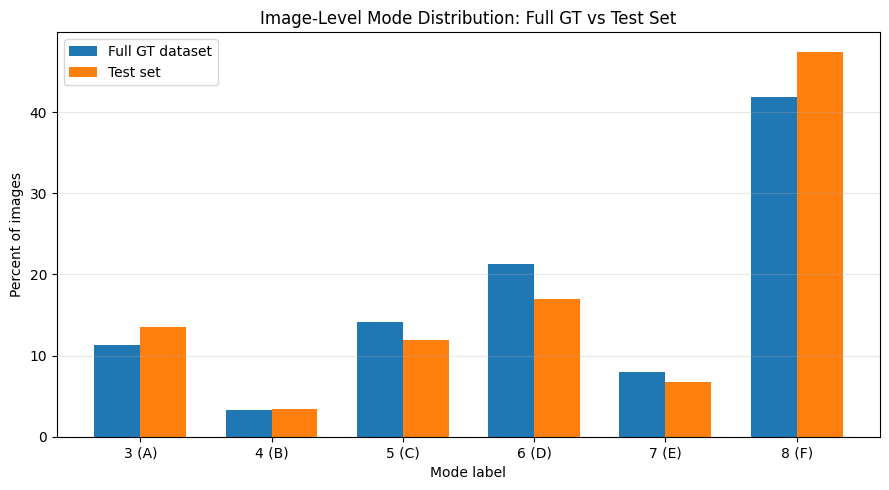

Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/plot_class_frequency_and_wa_mae_by_true_mode.png


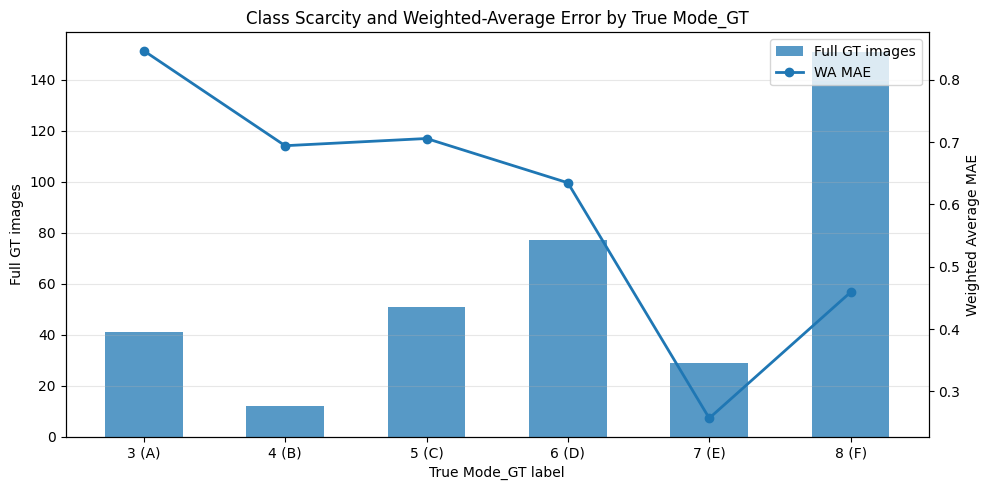

Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/plot_wa_bias_by_true_mode.png


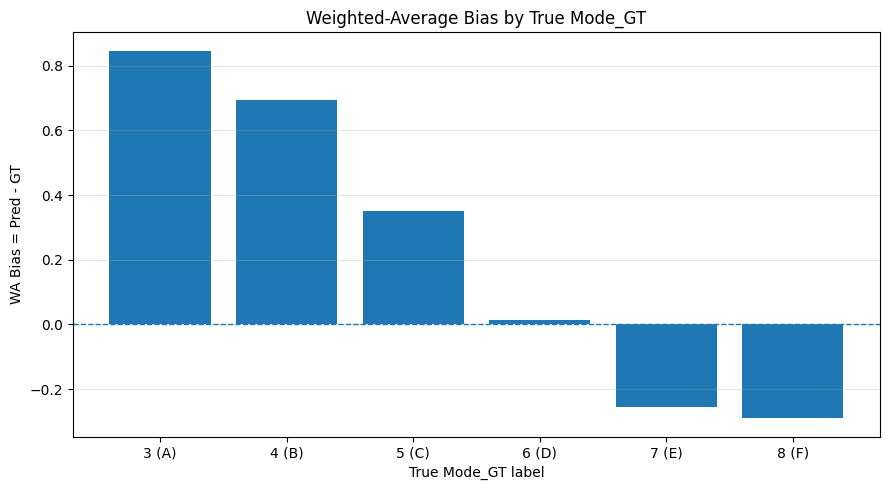

Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/plot_wa_error_direction_by_true_mode.png


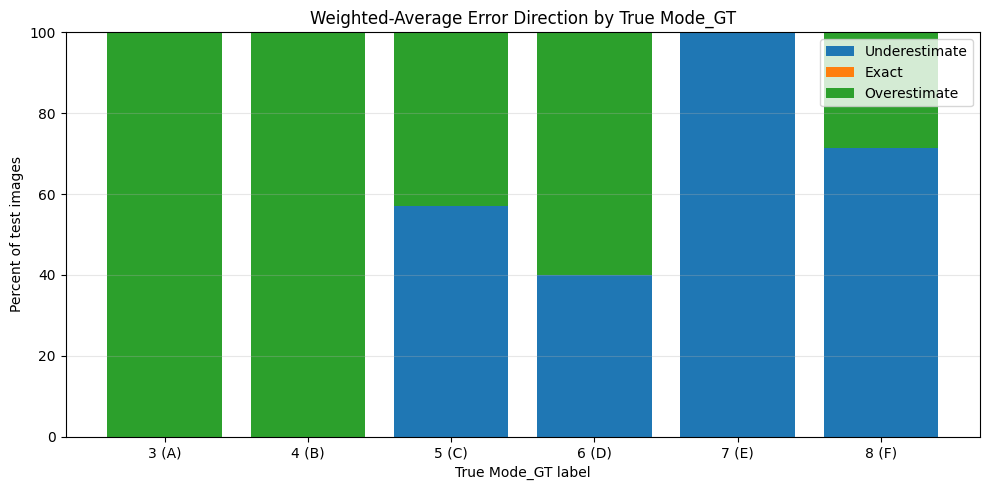

/tmp/ipykernel_5754/745875383.py:573: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=labels, showmeans=True)


Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/plot_gt_num_classes_vs_wa_abs_error_boxplot.png


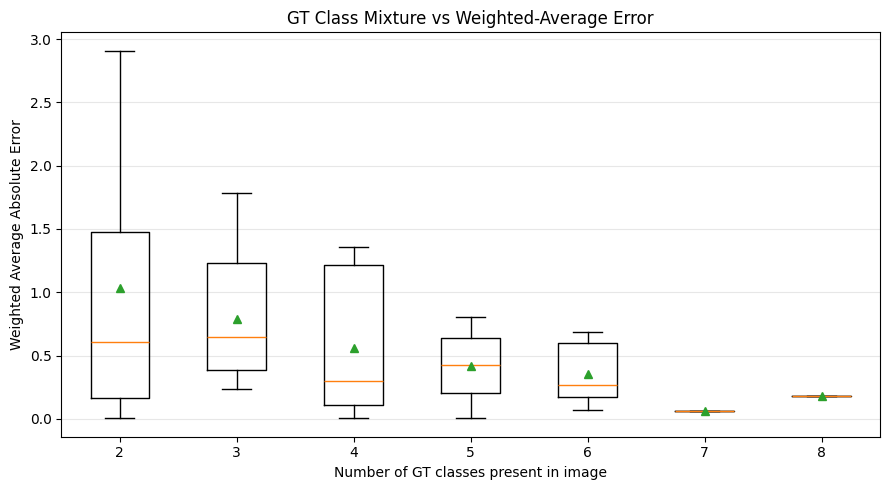

/tmp/ipykernel_5754/745875383.py:617: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=labels, showmeans=True)


Saved plot: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/imbalance_analysis/plot_pred_num_classes_vs_wa_abs_error_boxplot.png


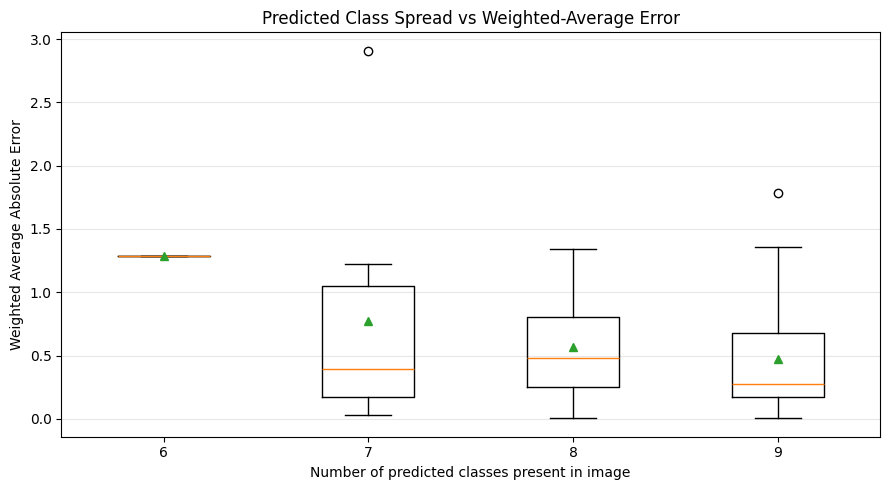

In [ ]:
merged_test_csv_path = MERGED_TEST_CSV

all_gt_csv_path = FULL_GT_AGG_CSV

output_folder = IMBALANCE_DIR

imbalance_results = analyze_data_imbalance_effects(
    merged_test_csv_path=merged_test_csv_path,
    all_gt_csv_path=all_gt_csv_path,
    output_folder=output_folder,
    show_plots=True
)

The test set was broadly representative of the full annotated dataset: the share of each true mode differed by at most 5.6 percentage points (F: 47.5% of test images against 41.8% of all masks). The dataset itself is imbalanced, with F making up 41.8% of all masks and B only 3.3% (12 masks, 2 of them in the test set). Label frequency did not explain the per-label error: across the six labels, the correlation between weighted-average MAE and the number of test images was −0.21, and with the number of masks in the full dataset −0.23. The clearest difference lies in class mixture: predicted masks contained on average 7.5 to 8.5 classes, against 2.5 to 4.8 in the ground-truth masks (background included). Imbalance limits the reliability of the estimates for rare labels, but the per-label errors follow severity (overestimation for A to C, underestimation for E and F) more closely than frequency.

## 5. Spatial data and clustering

The photographs come from several towns and districts, some of them tens of kilometres apart. Interpolating across such gaps would produce damage values for areas where no photograph was taken, so geotagged images are first grouped into spatial clusters with DBSCAN and interpolation is later done within each cluster only. DBSCAN runs on latitude and longitude in radians with the haversine metric, a neighbourhood radius of `DBSCAN_EPS_M` (2 km) and `DBSCAN_MIN_SAMPLES` (3). Images that do not belong to any dense group receive the label −1 (noise) and are left out of the interpolation.

Three tables are prepared:

1. The test rows that have GPS coordinates (53 of 59 in the saved run); the six excluded files are listed.
2. Ground-truth scores for all 361 annotated masks, recomputed from the raw masks, joined to the GPS table of Section 2 and clustered. In the saved run 296 masks had coordinates. DBSCAN split them into eight clusters of 145, 71, 40, 16, 7, 5, 3 and 3 images, with 6 noise points. This table is the basis for the LOOCV in Section 6 and the full-dataset predictions in Section 7.
3. The geotagged test rows, clustered with the same settings: three clusters of 27, 10 and 8 images and 8 noise points. This table is used in Sections 9 to 11.

The clustering radius should match the spacing of the survey. A smaller radius gives tighter clusters and fewer grid cells far from any photograph; a larger one merges neighbouring districts into one surface. When applying the notebook to another region, check the cluster counts printed below before interpolating.

In [ ]:
# Create spatial-only CSV from merged image-level CSV
# Drops only rows without usable coordinates
merged_csv_path = MERGED_TEST_CSV

spatial_csv_path = TEST_SPATIAL_ONLY_CSV

df_spatial = pd.read_csv(merged_csv_path)
df_spatial.columns = df_spatial.columns.str.strip()

df_spatial["Latitude_GT"] = pd.to_numeric(df_spatial["Latitude_GT"], errors="coerce")
df_spatial["Longitude_GT"] = pd.to_numeric(df_spatial["Longitude_GT"], errors="coerce")

before = len(df_spatial)

missing_coord_rows = df_spatial[
    df_spatial["Latitude_GT"].isna() |
    df_spatial["Longitude_GT"].isna()
].copy()

df_spatial_valid = df_spatial.dropna(
    subset=["Latitude_GT", "Longitude_GT"]
).copy()

after = len(df_spatial_valid)

df_spatial_valid.to_csv(spatial_csv_path, index=False)

print("Original image-level test rows:", before)
print("Rows retained for spatial analysis:", after)
print("Rows excluded from spatial analysis:", before - after)

print("\nExcluded files:")
display(missing_coord_rows[[
    "Filename_GT",
    "Mode_GT",
    "Mode_Pred",
    "Weighted Average_GT",
    "Weighted Average_Pred"
]])

print("\nSaved spatial-only CSV:")
print(spatial_csv_path)

Original image-level test rows: 59
Rows retained for spatial analysis: 53
Rows excluded from spatial analysis: 6

Excluded files:


,Filename_GT,Mode_GT,Mode_Pred,Weighted Average_GT,Weighted Average_Pred
11,F643C139-23C9-4ED4-A5FC-BC6FB3DC74AA.jpg,8,8,7.024315,7.502729
16,8B085C94-9A81-45AB-AF37-EABD6087FC6D.jpg,5,5,5.225401,5.045896
34,3ED4B163-B37D-4672-8593-6FB7CAD4B5DF.jpg,8,8,6.387864,7.076995
37,9259A54E-4F20-4F01-8330-0F8C50391849.jpg,8,7,7.525617,6.307941
44,253937D4-8716-4FE2-9D00-8F9FCF837B4F.jpg,8,8,6.864964,7.043700
46,7CD4187E-7A5D-489D-BE3B-E20F84B35CDD.jpg,4,5,4.000000,4.391608



Saved spatial-only CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/merged_gt_pred_test_image_level_scores_spatial_only.csv


In [ ]:
# Create ALL-GT image-level score CSV with GPS + DBSCAN clusters
# Uses Kaggle-extracted mask/image folders

# 1. Paths
gt_mask_folder = MASK_DIR
gps_csv_path = GPS_CSV
output_folder = INTERP_EVAL_DIR
os.makedirs(output_folder, exist_ok=True)

# Output files
all_gt_scores_path = os.path.join(
    output_folder,
    "all_gt_image_level_scores.csv"
)

all_gt_scores_gps_path = os.path.join(
    output_folder,
    "all_gt_image_level_scores_with_gps.csv"
)

all_gt_scores_gps_clusters_path = ALL_GT_CLUSTERS_CSV


# 2. Settings

# Damage labels A-F = 3-8
triage_labels = DAMAGE_LABELS

# DBSCAN parameters
eps_meters = DBSCAN_EPS_M
min_samples = DBSCAN_MIN_SAMPLES


# 3. Helper: find mask files recursively
def find_mask_files(mask_root):
    """
    Finds all PNG mask files recursively.
    """

    mask_paths = []

    for root, dirs, files in os.walk(mask_root):
        for file in files:
            if file.lower().endswith(".png"):
                mask_paths.append(os.path.join(root, file))

    return sorted(mask_paths)


# 4. Helper: find the photograph that belongs to a mask
# Same rule as notebook 01: Label_<n>_<name>.png belongs to the photograph whose
# file name starts with <name>. Most photographs are <UUID>.jpg, but some web
# photographs are stored as <name>.jpg.jpg with masks named Label_<n>_<name>.jpg.png,
# so appending ".jpg" to <name> would miss them.
image_file_names = sorted(
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg"))
)


def extract_image_filename_from_mask(mask_filename):
    """
    Returns the file name of the photograph that belongs to a GT mask.
    If no photograph matches, returns <name>.jpg so the row is still listed.
    """

    stem = os.path.splitext(os.path.basename(mask_filename))[0].strip("{}")
    parts = stem.split("_")

    if len(parts) >= 3 and parts[0].lower() == "label":
        name = "_".join(parts[2:])
    else:
        name = stem

    matches = [f for f in image_file_names if f.startswith(name)]

    if not matches:
        return name + ".jpg"

    # The shortest match is the exact name when one name is a prefix of another
    return min(matches, key=len)


# 5. Helper: calculate Mode and Weighted Average from mask
def calculate_gt_scores_from_mask(mask_path, valid_labels):
    """
    Calculates image-level GT Mode and Weighted Average from a mask.

    Only pixels with class values in valid_labels are used.
    This excludes background/personnel/machinery if they are outside 3-8.
    """

    mask = np.array(Image.open(mask_path))

    # If RGB/RGBA, use first channel.
    # This assumes class IDs are stored directly as pixel values.
    if mask.ndim == 3:
        mask = mask[:, :, 0]

    mask = mask.astype(int)

    valid_mask = np.isin(mask, valid_labels)
    valid_pixels = mask[valid_mask]

    if valid_pixels.size == 0:
        return {
            "Mode": np.nan,
            "Weighted Average": np.nan,
            "GT Classes": [],
            "Num Triage Pixels": 0
        }

    classes, counts = np.unique(valid_pixels, return_counts=True)

    mode_label = classes[np.argmax(counts)]
    weighted_average = np.average(classes, weights=counts)

    return {
        "Mode": int(mode_label),
        "Weighted Average": float(weighted_average),
        "GT Classes": classes.astype(int).tolist(),
        "Num Triage Pixels": int(valid_pixels.size)
    }


# 6. Find and inspect GT mask files
if not os.path.exists(gt_mask_folder):
    raise FileNotFoundError(f"GT mask folder not found: {gt_mask_folder}")

mask_paths = find_mask_files(gt_mask_folder)

print("Number of GT mask PNG files found:", len(mask_paths))

if len(mask_paths) == 0:
    raise FileNotFoundError("No PNG mask files found in the GT mask folder.")

print("\nExample mask files:")
for p in mask_paths[:10]:
    print(os.path.basename(p))


# 7. Calculate GT image-level scores for all masks
rows = []

for mask_path in mask_paths:
    mask_filename = os.path.basename(mask_path)
    image_filename = extract_image_filename_from_mask(mask_filename)

    scores = calculate_gt_scores_from_mask(
        mask_path=mask_path,
        valid_labels=triage_labels
    )

    rows.append({
        "Filename": image_filename,
        "Mask Filename": mask_filename,
        "Mask Path": mask_path,
        "Mode": scores["Mode"],
        "Weighted Average": scores["Weighted Average"],
        "GT Classes": scores["GT Classes"],
        "Num Triage Pixels": scores["Num Triage Pixels"]
    })

gt_scores_df = pd.DataFrame(rows)

unmatched = gt_scores_df[~gt_scores_df["Filename"].isin(image_file_names)]
print("Masks without a matching photograph:", len(unmatched))

print("\nGT image-level score table shape:", gt_scores_df.shape)
display(gt_scores_df.head())

print("\nMode counts:")
print(gt_scores_df["Mode"].value_counts(dropna=False).sort_index())

print("\nWeighted Average summary:")
print(gt_scores_df["Weighted Average"].describe())

gt_scores_df.to_csv(all_gt_scores_path, index=False)

print("\nSaved all GT image-level scores:")
print(all_gt_scores_path)


# 8. Merge with GPS CSV
if not os.path.exists(gps_csv_path):
    raise FileNotFoundError(
        f"GPS CSV not found: {gps_csv_path}\n"
        "Run the GPS extraction cell first."
    )

gps_df = pd.read_csv(gps_csv_path)

gt_scores_df.columns = gt_scores_df.columns.str.strip()
gps_df.columns = gps_df.columns.str.strip()

required_gps_cols = ["Filename", "Latitude", "Longitude"]

missing_gps_cols = [
    col for col in required_gps_cols
    if col not in gps_df.columns
]

if missing_gps_cols:
    raise ValueError(
        f"GPS CSV missing required columns: {missing_gps_cols}\n"
        f"Available columns: {list(gps_df.columns)}"
    )

# Normalize filenames for matching
gt_scores_df["Filename_clean"] = gt_scores_df["Filename"].astype(str).str.strip()
gps_df["Filename_clean"] = gps_df["Filename"].astype(str).str.strip()

gps_small = gps_df[["Filename_clean", "Latitude", "Longitude"]].copy()

merged_gt_gps = gt_scores_df.merge(
    gps_small,
    on="Filename_clean",
    how="left"
)

merged_gt_gps = merged_gt_gps.drop(columns=["Filename_clean"])

merged_gt_gps["Latitude"] = pd.to_numeric(
    merged_gt_gps["Latitude"],
    errors="coerce"
)

merged_gt_gps["Longitude"] = pd.to_numeric(
    merged_gt_gps["Longitude"],
    errors="coerce"
)

print("\nGT + GPS table shape:", merged_gt_gps.shape)

missing_gps_mask = (
    merged_gt_gps["Latitude"].isna() |
    merged_gt_gps["Longitude"].isna()
)

print("Rows missing GPS:", missing_gps_mask.sum())

if missing_gps_mask.sum() > 0:
    print("\nExamples missing GPS:")
    display(
        merged_gt_gps.loc[
            missing_gps_mask,
            ["Filename", "Mask Filename", "Mode", "Weighted Average", "Latitude", "Longitude"]
        ].head(20)
    )

merged_gt_gps.to_csv(all_gt_scores_gps_path, index=False)

print("\nSaved all GT scores with GPS:")
print(all_gt_scores_gps_path)


# 9. Add DBSCAN clusters
cluster_df = merged_gt_gps.copy()

valid_coord_mask = (
    cluster_df["Latitude"].notna() &
    cluster_df["Longitude"].notna() &
    np.isfinite(cluster_df["Latitude"]) &
    np.isfinite(cluster_df["Longitude"])
)

print("\nRows with valid coordinates for DBSCAN:", valid_coord_mask.sum())
print("Rows without valid coordinates:", (~valid_coord_mask).sum())

if valid_coord_mask.sum() == 0:
    raise ValueError("No rows with valid coordinates. Cannot run DBSCAN.")

coords = cluster_df.loc[valid_coord_mask, ["Latitude", "Longitude"]].values
coords_rad = np.radians(coords)

earth_radius_km = 6371.0088
eps_rad = eps_meters / 1000.0 / earth_radius_km

db = DBSCAN(
    eps=eps_rad,
    min_samples=min_samples,
    metric="haversine"
)

cluster_labels = db.fit_predict(coords_rad)

cluster_df["Cluster"] = np.nan
cluster_df.loc[valid_coord_mask, "Cluster"] = cluster_labels

# Nullable integer allows NaN for rows without GPS
cluster_df["Cluster"] = cluster_df["Cluster"].astype("Int64")

cluster_df.to_csv(all_gt_scores_gps_clusters_path, index=False)

print("\nSaved all GT scores with GPS and clusters:")
print(all_gt_scores_gps_clusters_path)

print("\nCluster counts:")
print(cluster_df["Cluster"].value_counts(dropna=False).sort_index())

display(cluster_df.head())

Number of GT mask PNG files found: 361

Example mask files:
Label_100_B80ACF18-864C-4E62-BB4A-56820D4621C7.png
Label_101_B72E134E-3779-4EB8-9C30-42E284F8E511.png
Label_102_B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B.png
Label_103_B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D.png
Label_104_B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8.png
Label_105_B20D4951-A7BD-4036-972A-9EBB2AEAFF99.png
Label_106_B1D62FB5-6F0F-408A-BBF3-BF2F64BA5012.png
Label_107_B187F4FB-88CB-4548-A114-1FB9462487B1.png
Label_108_B13E60C2-7DF5-47D0-9057-E7AD84699544.png
Label_109_B0FD72B9-2896-49AF-BD68-6AD7F5F890B2.png

GT image-level score table shape: (361, 7)


,Filename,Mask Filename,Mask Path,Mode,Weighted Average,GT Classes,Num Triage Pixels
0,B80ACF18-864C-4E62-BB4A-56820D4621C7.jpg,Label_100_B80ACF18-864C-4E62-BB4A-56820D4621C7...,/content/turkey_gt_masks/Label_100_B80ACF18-86...,5,5.540197,"[5, 8]",793489
1,B72E134E-3779-4EB8-9C30-42E284F8E511.jpg,Label_101_B72E134E-3779-4EB8-9C30-42E284F8E511...,/content/turkey_gt_masks/Label_101_B72E134E-37...,8,7.824664,"[3, 8]",401059
2,B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B.jpg,Label_102_B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B...,/content/turkey_gt_masks/Label_102_B5D8A6DA-76...,6,6.636815,"[6, 7, 8]",761898
3,B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D.jpg,Label_103_B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D...,/content/turkey_gt_masks/Label_103_B4DDF3D5-A7...,5,5.660933,"[3, 5, 6, 8]",2269421
4,B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8.jpg,Label_104_B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8...,/content/turkey_gt_masks/Label_104_B2B3C2E9-5A...,8,7.042223,"[3, 8]",769339



Mode counts:
Mode
3     41
4     12
5     51
6     77
7     29
8    151
Name: count, dtype: int64

Weighted Average summary:
count    361.000000
mean       6.153235
std        1.356920
min        3.000000
25%        5.641228
50%        6.472200
75%        7.099146
max        8.000000
Name: Weighted Average, dtype: float64

Saved all GT image-level scores:
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/all_gt_image_level_scores.csv

GT + GPS table shape: (361, 9)
Rows missing GPS: 65

Examples missing GPS:


,Filename,Mask Filename,Mode,Weighted Average,Latitude,Longitude
3,B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D.jpg,Label_103_B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D...,5,5.660933,NaN,NaN
9,B0FD72B9-2896-49AF-BD68-6AD7F5F890B2.jpg,Label_109_B0FD72B9-2896-49AF-BD68-6AD7F5F890B2...,8,6.595314,NaN,NaN
12,AC4030FC-9B72-4880-8439-9155510A1F49.jpg,Label_111_AC4030FC-9B72-4880-8439-9155510A1F49...,6,5.430366,NaN,NaN
14,A877A1B4-DAD0-4FA0-B0D4-0254636030B9.jpg,Label_113_A877A1B4-DAD0-4FA0-B0D4-0254636030B9...,8,6.712392,NaN,NaN
16,A592AF78-012D-44C7-AB12-DBC188EB1A96.jpg,Label_115_A592AF78-012D-44C7-AB12-DBC188EB1A96...,6,5.669452,NaN,NaN
21,F643C139-23C9-4ED4-A5FC-BC6FB3DC74AA.jpg,Label_11_F643C139-23C9-4ED4-A5FC-BC6FB3DC74AA.png,8,7.024315,NaN,NaN
24,A0733E83-82FD-4FE4-A2D0-009370F65545.jpg,Label_122_A0733E83-82FD-4FE4-A2D0-009370F65545...,8,5.877082,NaN,NaN
27,9F4E5080-D885-4182-9999-2A7D6105C93F.jpg,Label_125_9F4E5080-D885-4182-9999-2A7D6105C93F...,6,6.504767,NaN,NaN
36,94E9A5F3-C3C3-4E1C-A64A-B3D3DD758FC0.jpg,Label_133_94E9A5F3-C3C3-4E1C-A64A-B3D3DD758FC0...,8,6.008081,NaN,NaN
42,9259A54E-4F20-4F01-8330-0F8C50391849.jpg,Label_139_9259A54E-4F20-4F01-8330-0F8C50391849...,8,7.525617,NaN,NaN



Saved all GT scores with GPS:
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/all_gt_image_level_scores_with_gps.csv

Rows with valid coordinates for DBSCAN: 296
Rows without valid coordinates: 65

Saved all GT scores with GPS and clusters:
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/all_gt_image_level_scores_with_gps_clusters.csv

Cluster counts:
Cluster
-1        6
0       145
1        40
2        71
3         7
4        16
5         5
6         3
7         3
<NA>     65
Name: count, dtype: Int64


,Filename,Mask Filename,Mask Path,Mode,Weighted Average,GT Classes,Num Triage Pixels,Latitude,Longitude,Cluster
0,B80ACF18-864C-4E62-BB4A-56820D4621C7.jpg,Label_100_B80ACF18-864C-4E62-BB4A-56820D4621C7...,/content/turkey_gt_masks/Label_100_B80ACF18-86...,5,5.540197,"[5, 8]",793489,36.196113,36.159400,0
1,B72E134E-3779-4EB8-9C30-42E284F8E511.jpg,Label_101_B72E134E-3779-4EB8-9C30-42E284F8E511...,/content/turkey_gt_masks/Label_101_B72E134E-37...,8,7.824664,"[3, 8]",401059,37.574378,36.933797,1
2,B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B.jpg,Label_102_B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B...,/content/turkey_gt_masks/Label_102_B5D8A6DA-76...,6,6.636815,"[6, 7, 8]",761898,36.196854,36.150558,0
3,B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D.jpg,Label_103_B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D...,/content/turkey_gt_masks/Label_103_B4DDF3D5-A7...,5,5.660933,"[3, 5, 6, 8]",2269421,NaN,NaN,<NA>
4,B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8.jpg,Label_104_B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8...,/content/turkey_gt_masks/Label_104_B2B3C2E9-5A...,8,7.042223,"[3, 8]",769339,36.195602,36.159569,0


In [ ]:
# Prepare clustered test-set CSV for spatial heatmap comparison
merged_test_csv_path = MERGED_TEST_CSV

spatial_output_folder = SPATIAL_DIR
os.makedirs(spatial_output_folder, exist_ok=True)

test_spatial_csv_path = os.path.join(
    spatial_output_folder,
    "test_gt_pred_weighted_average_spatial_only.csv"
)

test_spatial_clustered_csv_path = TEST_SPATIAL_CLUSTERED_CSV

# Load merged test CSV
df_test = pd.read_csv(merged_test_csv_path)
df_test.columns = df_test.columns.str.strip()

required_cols = [
    "Filename_GT",
    "Latitude_GT",
    "Longitude_GT",
    "Weighted Average_GT",
    "Weighted Average_Pred"
]

missing_cols = [col for col in required_cols if col not in df_test.columns]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}\n"
        f"Available columns: {list(df_test.columns)}"
    )

# Convert to numeric
for col in ["Latitude_GT", "Longitude_GT", "Weighted Average_GT", "Weighted Average_Pred"]:
    df_test[col] = pd.to_numeric(df_test[col], errors="coerce")

before = len(df_test)

df_test_spatial = df_test.dropna(
    subset=[
        "Latitude_GT",
        "Longitude_GT",
        "Weighted Average_GT",
        "Weighted Average_Pred"
    ]
).copy()

after = len(df_test_spatial)

print("Original test rows:", before)
print("Rows retained for spatial analysis:", after)
print("Rows dropped because of missing GPS/scores:", before - after)

# Save spatial-only file
df_test_spatial.to_csv(test_spatial_csv_path, index=False)

print("\nSaved spatial-only test CSV:")
print(test_spatial_csv_path)

# DBSCAN clustering
eps_meters = DBSCAN_EPS_M
min_samples = DBSCAN_MIN_SAMPLES

coords = df_test_spatial[["Latitude_GT", "Longitude_GT"]].values
coords_rad = np.radians(coords)

earth_radius_km = 6371.0088
eps_rad = eps_meters / 1000.0 / earth_radius_km

db = DBSCAN(
    eps=eps_rad,
    min_samples=min_samples,
    metric="haversine"
)

df_test_spatial["Cluster"] = db.fit_predict(coords_rad)

df_test_spatial.to_csv(test_spatial_clustered_csv_path, index=False)

print("\nSaved clustered spatial test CSV:")
print(test_spatial_clustered_csv_path)

print("\nCluster counts:")
print(df_test_spatial["Cluster"].value_counts().sort_index())

display(df_test_spatial.head())

Original test rows: 59
Rows retained for spatial analysis: 53
Rows dropped because of missing GPS/scores: 6

Saved spatial-only test CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/test_gt_pred_weighted_average_spatial_only.csv

Saved clustered spatial test CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/test_gt_pred_weighted_average_spatial_only_with_clusters.csv

Cluster counts:
Cluster
-1     8
 0    27
 1     8
 2    10
Name: count, dtype: int64


,Filename_GT,Image Path_GT,Mask Filename,Mask Path,Latitude_GT,Longitude_GT,Mode_GT,Weighted Average_GT,GT Classes,merge_id,Filename_Pred,Image Path_Pred,GT Mask Path,Latitude_Pred,Longitude_Pred,Mode_Pred,Weighted Average_Pred,Predicted Classes,Cluster
0,1A1C3737-55C9-4D47-80D8-71E9A3C90F97.jpg,/content/turkey_gt_images/1A1C3737-55C9-4D47-8...,Label_292_1A1C3737-55C9-4D47-80D8-71E9A3C90F97...,/content/turkey_gt_masks/Label_292_1A1C3737-55...,36.495114,36.367932,8,7.383109,"[0, 4, 6, 7, 8]",1A1C3737-55C9-4D47-80D8-71E9A3C90F97,1A1C3737-55C9-4D47-80D8-71E9A3C90F97.jpg,/content/turkey_gt_images/1A1C3737-55C9-4D47-8...,/content/turkey_gt_masks/Label_292_1A1C3737-55...,36.495114,36.367932,6,6.827845,"[0, 1, 4, 5, 6, 7, 8]",-1
1,7E41172C-78FD-4402-9ECF-1583F236ACC3.jpg,/content/turkey_gt_images/7E41172C-78FD-4402-9...,Label_167_7E41172C-78FD-4402-9ECF-1583F236ACC3...,/content/turkey_gt_masks/Label_167_7E41172C-78...,36.216541,36.154213,4,4.000000,"[0, 4]",7E41172C-78FD-4402-9ECF-1583F236ACC3,7E41172C-78FD-4402-9ECF-1583F236ACC3.jpg,/content/turkey_gt_images/7E41172C-78FD-4402-9...,/content/turkey_gt_masks/Label_167_7E41172C-78...,36.216541,36.154213,5,4.996574,"[0, 1, 3, 4, 5, 6, 8]",0
2,DE318F6C-D145-4768-8B74-A395A7F008BF.jpg,/content/turkey_gt_images/DE318F6C-D145-4768-8...,Label_48_DE318F6C-D145-4768-8B74-A395A7F008BF.png,/content/turkey_gt_masks/Label_48_DE318F6C-D14...,37.575219,36.933911,7,7.326547,"[0, 7, 8]",DE318F6C-D145-4768-8B74-A395A7F008BF,DE318F6C-D145-4768-8B74-A395A7F008BF.jpg,/content/turkey_gt_images/DE318F6C-D145-4768-8...,/content/turkey_gt_masks/Label_48_DE318F6C-D14...,37.575219,36.933911,7,6.854686,"[0, 1, 2, 4, 5, 6, 7, 8]",1
3,BA7A9046-BD7E-4862-850D-A9B2DE988431.jpg,/content/turkey_gt_images/BA7A9046-BD7E-4862-8...,Label_96_BA7A9046-BD7E-4862-850D-A9B2DE988431.png,/content/turkey_gt_masks/Label_96_BA7A9046-BD7...,37.574971,36.933431,8,7.555524,"[0, 2, 7, 8]",BA7A9046-BD7E-4862-850D-A9B2DE988431,BA7A9046-BD7E-4862-850D-A9B2DE988431.jpg,/content/turkey_gt_images/BA7A9046-BD7E-4862-8...,/content/turkey_gt_masks/Label_96_BA7A9046-BD7...,37.574971,36.933431,6,6.268295,"[0, 1, 2, 4, 5, 6, 7, 8]",1
4,F0EF1E9D-1E57-47FC-8439-244452934513.jpg,/content/turkey_gt_images/F0EF1E9D-1E57-47FC-8...,Label_19_F0EF1E9D-1E57-47FC-8439-244452934513.png,/content/turkey_gt_masks/Label_19_F0EF1E9D-1E5...,36.196455,36.160058,5,5.000000,"[0, 5]",F0EF1E9D-1E57-47FC-8439-244452934513,F0EF1E9D-1E57-47FC-8439-244452934513.jpg,/content/turkey_gt_images/F0EF1E9D-1E57-47FC-8...,/content/turkey_gt_masks/Label_19_F0EF1E9D-1E5...,36.196455,36.160058,5,5.010029,"[0, 1, 3, 4, 5, 6, 7, 8]",0


## 6. Choosing an interpolation method (LOOCV)

A heatmap is produced by estimating the damage score on a regular grid from the scores of nearby photographs. Two families of interpolators are compared. Inverse distance weighting estimates each grid value as a weighted mean of the observed scores with weights $1/d^p$, where $d$ is the distance to an observation and $p$ the power. A small power gives a smooth surface close to the cluster mean, and a large power gives a patchwork dominated by the nearest photograph. Ordinary kriging fits a variogram model (linear, power, spherical, exponential or Gaussian) to the spatial autocorrelation of the scores and derives the weights from it; universal kriging adds a linear trend. Kriging is done with PyKrige.

The helper cells define IDW (`interpolate_idw`), the heatmap builder used in the rest of the notebook (`interpolate_clusters_heatmap`, which interpolates each non-noise cluster on its own `GRID_RES` × `GRID_RES` grid extended by `BUFFER_M`, and saves the grid values as CSV and an interactive Folium map), and leave-one-out cross-validation for a single cluster (`loocv_interpolation`). `compare_loocv_interpolation_methods` runs the LOOCV in every cluster with at least four images, for IDW powers from 0.5 to 10 and for ordinary and universal kriging with five variogram models, and pools the left-out errors over the clusters.

Two implementation details matter when the code is adapted. Distances are computed in decimal degrees rather than metres; at about 37° N a degree of longitude is roughly 20% shorter than a degree of latitude, so the weighting is slightly anisotropic. For larger areas or other latitudes, project the coordinates (for example to UTM) before interpolating. The buffer is converted to degrees with 1° ≈ 111 km in both directions. Other interpolators can be added as further branches of `interpolate_clusters_heatmap` and `loocv_interpolation`, as long as they return a grid of the same shape.

In [ ]:
# IDW interpolation helper function
def interpolate_idw(x, y, z, xi, yi, power=2):
    """
    Performs Inverse Distance Weighting (IDW) interpolation.

    Parameters
    ----------
    x : array-like
        1D array of known x-coordinates.
        In this project, usually Longitude.

    y : array-like
        1D array of known y-coordinates.
        In this project, usually Latitude.

    z : array-like
        1D array of known values at each (x, y) point.
        For example: Mode_GT, Mode_Pred, Weighted Average_GT, or error.

    xi : numpy.ndarray
        2D meshgrid array of target x-coordinates.

    yi : numpy.ndarray
        2D meshgrid array of target y-coordinates.

    power : float
        IDW power parameter.
        Higher values give more weight to nearby points.

    Returns
    -------
    interpolated : numpy.ndarray
        2D interpolated grid with the same shape as xi and yi.
    """

    # 1. Convert inputs to numpy arrays
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    z = np.asarray(z, dtype=float)
    xi = np.asarray(xi, dtype=float)
    yi = np.asarray(yi, dtype=float)

    # 2. Remove missing values
    valid_mask = (
        np.isfinite(x) &
        np.isfinite(y) &
        np.isfinite(z)
    )

    x = x[valid_mask]
    y = y[valid_mask]
    z = z[valid_mask]

    if len(x) == 0:
        raise ValueError("No valid points available for IDW interpolation.")

    # 3. Compute distance from every known point to every grid cell
    dist = np.sqrt(
        (x[:, None, None] - xi[None, :, :]) ** 2 +
        (y[:, None, None] - yi[None, :, :]) ** 2
    )

    # Avoid division by zero at exact known point locations
    dist[dist == 0] = 1e-10

    # 4. Compute IDW weights
    weights = 1 / (dist ** power)

    # 5. Compute weighted average
    interpolated = (
        np.sum(weights * z[:, None, None], axis=0) /
        np.sum(weights, axis=0)
    )

    return interpolated

In [ ]:
# Cluster-based interpolation heatmap (IDW, ordinary kriging, universal kriging).
# Saves the interpolated grid as CSV and an interactive HTML map.
def make_safe_filename(text):
    """
    Converts a string to a safe filename component.
    """
    return (
        str(text)
        .strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
        .replace("\\", "_")
        .replace(".", "p")
    )


def build_heatmap_save_name(
    dataset_tag,
    value_column,
    interpolation_method,
    method_params
):
    """
    Builds descriptive file names like:
    gt_weighted_average_idw_power1_heatmap
    pred_mode_ordinary_kriging_linear_heatmap
    gt_weighted_average_universal_kriging_spherical_regional_linear_heatmap
    """

    dataset_part = make_safe_filename(dataset_tag)
    value_part = make_safe_filename(value_column)
    method_part = make_safe_filename(interpolation_method)

    if interpolation_method == "idw":
        power = method_params.get("power", 2)
        param_part = f"power{make_safe_filename(power)}"

    elif interpolation_method in ["ordinary_kriging", "universal_kriging"]:
        variogram_model = method_params.get("variogram_model", "linear")
        param_part = make_safe_filename(variogram_model)

        if interpolation_method == "universal_kriging":
            drift_terms = method_params.get("drift_terms", ["regional_linear"])

            if isinstance(drift_terms, str):
                drift_terms = [drift_terms]

            drift_part = "_".join([make_safe_filename(d) for d in drift_terms])
            param_part = f"{param_part}_{drift_part}"

    else:
        param_part = "params"

    return f"{dataset_part}_{value_part}_{method_part}_{param_part}_heatmap"


def interpolate_clusters_heatmap(
    csv_path,
    value_column="Mode",
    interpolation_method="idw",
    method_params=None,
    lat_col="Latitude",
    lon_col="Longitude",
    filename_col="Filename",
    cluster_col="Cluster",
    dataset_tag="gt",
    buffer_m=300,
    grid_res=300,
    save_results=True,
    output_folder=os.path.join(INTERP_EVAL_DIR, "heatmaps"),
    save_name=None,
    show_map=True,
    run_loocv_largest_cluster=True
):
    """
    Creates an interpolated heatmap for clustered geotagged image-level data.

    Parameters
    ----------
    csv_path : str
        Path to CSV with coordinates, value column, and cluster labels.

    value_column : str
        Column to interpolate.
        Examples:
        - "Mode"
        - "Weighted Average"
        - "Mode_GT"
        - "Mode_Pred"
        - "Weighted Average_GT"
        - "Weighted Average_Pred"

    interpolation_method : str
        Interpolation method:
        - "idw"
        - "ordinary_kriging"
        - "universal_kriging"

    method_params : dict or None
        For IDW:
            {"power": 1}

        For ordinary kriging:
            {"variogram_model": "linear"}

        For universal kriging:
            {
                "variogram_model": "linear",
                "drift_terms": ["regional_linear"]
            }

    lat_col, lon_col : str
        Coordinate column names.

    filename_col : str
        Filename column for popup.

    cluster_col : str
        DBSCAN cluster column.

    dataset_tag : str
        Used in output filename.
        Examples:
        - "gt"
        - "pred"
        - "gt_test"
        - "pred_test"

    buffer_m : float
        Buffer around each cluster bounding box, in meters.

    grid_res : int
        Grid resolution per cluster.

    save_results : bool
        If True, saves interpolated CSV, HTML map, and LOOCV metrics.

    output_folder : str
        Folder for saved outputs.

    save_name : str or None
        Base output filename. If None, a descriptive name is generated automatically.

    show_map : bool
        If True, displays the Folium map.

    run_loocv_largest_cluster : bool
        If True, computes LOOCV MAE/RMSE for the largest non-noise cluster.

    Returns
    -------
    final_interp_df : pandas.DataFrame
        Interpolated grid values.

    fmap : folium.Map
        Interactive Folium map.

    loocv_metrics : dict
        LOOCV MAE/RMSE for largest non-noise cluster, if calculated.
    """

    # 1. Setup and validation
    if method_params is None:
        method_params = {}

    valid_methods = [
        "idw",
        "ordinary_kriging",
        "universal_kriging"
    ]

    if interpolation_method not in valid_methods:
        raise ValueError(
            f"interpolation_method must be one of: {valid_methods}"
        )

    if interpolation_method in ["ordinary_kriging", "universal_kriging"] and not PYKRIGE_AVAILABLE:
        raise ImportError(
            "PyKrige is not installed. Run `!pip install pykrige` first, "
            "or use interpolation_method='idw'."
        )

    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"CSV file not found: {csv_path}")

    if save_name is None:
        save_name = build_heatmap_save_name(
            dataset_tag=dataset_tag,
            value_column=value_column,
            interpolation_method=interpolation_method,
            method_params=method_params
        )

    # 2. Load CSV
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    print("Loaded CSV:", csv_path)
    print("Original shape:", df.shape)
    print("Value column:", value_column)
    print("Interpolation method:", interpolation_method)
    print("Method params:", method_params)
    print("Save name:", save_name)

    required_cols = [
        lat_col,
        lon_col,
        value_column,
        cluster_col
    ]

    missing_cols = [
        col for col in required_cols
        if col not in df.columns
    ]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}\n"
            f"Available columns: {list(df.columns)}"
        )

    if filename_col not in df.columns:
        print(f"⚠️ '{filename_col}' not found. Using row index in popups.")
        df["_Filename_for_popup"] = df.index.astype(str)
        filename_col_use = "_Filename_for_popup"
    else:
        filename_col_use = filename_col

    # 3. Clean numeric columns
    df[lat_col] = pd.to_numeric(df[lat_col], errors="coerce")
    df[lon_col] = pd.to_numeric(df[lon_col], errors="coerce")
    df[value_column] = pd.to_numeric(df[value_column], errors="coerce")
    df[cluster_col] = pd.to_numeric(df[cluster_col], errors="coerce")

    before_drop = len(df)

    df = df.dropna(
        subset=[lat_col, lon_col, value_column, cluster_col]
    ).copy()

    after_drop = len(df)

    print("Rows after dropping missing coordinate/value/cluster rows:", after_drop)
    print("Rows dropped:", before_drop - after_drop)

    if len(df) == 0:
        raise ValueError("No valid rows remain after cleaning.")

    df[cluster_col] = df[cluster_col].astype(int)

    # Remove DBSCAN noise for interpolation
    df_valid = df[df[cluster_col] != -1].copy()

    if len(df_valid) == 0:
        raise ValueError("No non-noise clusters available for interpolation.")

    print("\nCluster counts used for interpolation:")
    print(df_valid[cluster_col].value_counts().sort_index())

    largest_cluster = int(df_valid[cluster_col].value_counts().idxmax())

    print("\nLargest non-noise cluster:", largest_cluster)

    # 4. Create Folium map
    center = [
        float(df_valid[lat_col].mean()),
        float(df_valid[lon_col].mean())
    ]

    fmap = folium.Map(
        location=center,
        zoom_start=10,
        tiles="cartodb positron"
    )

    marker_cluster = MarkerCluster().add_to(fmap)

    for _, row in df_valid.iterrows():

        popup = folium.Popup(
            f"""
            <b>Filename:</b> {row[filename_col_use]}<br>
            <b>Lat:</b> {row[lat_col]:.5f},
            <b>Lon:</b> {row[lon_col]:.5f}<br>
            <b>{value_column}:</b> {row[value_column]}<br>
            <b>Cluster:</b> {row[cluster_col]}<br>
            """,
            max_width=350
        )

        folium.Marker(
            location=[row[lat_col], row[lon_col]],
            popup=popup,
            icon=folium.Icon(color="blue", icon="info-sign")
        ).add_to(marker_cluster)

    # 5. Interpolate each cluster
    all_interp_data = []

    loocv_metrics = {
        "dataset_tag": dataset_tag,
        "value_column": value_column,
        "interpolation_method": interpolation_method,
        "method_params": str(method_params),
        "largest_cluster": largest_cluster,
        "MAE": np.nan,
        "RMSE": np.nan,
        "N": 0
    }

    for cluster_id in sorted(df_valid[cluster_col].unique()):

        cluster_df = df_valid[df_valid[cluster_col] == cluster_id].copy()

        n_points = len(cluster_df)

        if n_points < 2:
            print(f"⚠️ Skipping cluster {cluster_id}: fewer than 2 points.")
            continue

        lats = cluster_df[lat_col].values.astype(float)
        lons = cluster_df[lon_col].values.astype(float)
        values = cluster_df[value_column].values.astype(float)

        buffer_deg = buffer_m / 111_000.0

        min_lat = lats.min() - buffer_deg
        max_lat = lats.max() + buffer_deg
        min_lon = lons.min() - buffer_deg
        max_lon = lons.max() + buffer_deg

        grid_lon = np.linspace(min_lon, max_lon, grid_res)
        grid_lat = np.linspace(min_lat, max_lat, grid_res)

        grid_x, grid_y = np.meshgrid(grid_lon, grid_lat)

        try:
            # IDW
            if interpolation_method == "idw":

                power = method_params.get("power", 2)

                interpolated = interpolate_idw(
                    x=lons,
                    y=lats,
                    z=values,
                    xi=grid_x,
                    yi=grid_y,
                    power=power
                )

            # Ordinary kriging
            elif interpolation_method == "ordinary_kriging":

                if n_points < 3:
                    print(f"⚠️ Skipping cluster {cluster_id}: kriging needs at least 3 points.")
                    continue

                variogram_model = method_params.get("variogram_model", "linear")

                OK = OrdinaryKriging(
                    lons,
                    lats,
                    values,
                    variogram_model=variogram_model,
                    verbose=False,
                    enable_plotting=False
                )

                interpolated, _ = OK.execute(
                    "grid",
                    grid_lon,
                    grid_lat
                )

                interpolated = np.asarray(interpolated, dtype=float)

            # Universal kriging
            elif interpolation_method == "universal_kriging":

                if n_points < 3:
                    print(f"⚠️ Skipping cluster {cluster_id}: universal kriging needs at least 3 points.")
                    continue

                variogram_model = method_params.get("variogram_model", "linear")
                drift_terms = method_params.get("drift_terms", ["regional_linear"])

                if isinstance(drift_terms, str):
                    drift_terms = [drift_terms]

                UK = UniversalKriging(
                    lons,
                    lats,
                    values,
                    variogram_model=variogram_model,
                    drift_terms=drift_terms,
                    verbose=False,
                    enable_plotting=False
                )

                interpolated, _ = UK.execute(
                    "grid",
                    grid_lon,
                    grid_lat
                )

                interpolated = np.asarray(interpolated, dtype=float)

            # Store interpolated grid
            interp_df = pd.DataFrame({
                "Latitude": grid_y.flatten(),
                "Longitude": grid_x.flatten(),
                "Interpolated": interpolated.flatten(),
                "Cluster": cluster_id,
                "Value_Column": value_column,
                "Dataset_Tag": dataset_tag,
                "Interpolation_Method": interpolation_method,
                "Method_Params": str(method_params),
                "Source_CSV": csv_path
            })

            all_interp_data.append(interp_df)

            # Add heatmap overlay to map
            interp_min = np.nanmin(interpolated)
            interp_max = np.nanmax(interpolated)

            if np.isclose(interp_min, interp_max):
                interp_max = interp_min + 1e-9

            norm = Normalize(vmin=interp_min, vmax=interp_max)
            cmap = cm.viridis

            rgba_image = cmap(norm(interpolated))
            rgb_image = (rgba_image[:, :, :3] * 255).astype(np.uint8)

            img = Image.fromarray(rgb_image)

            buffer = io.BytesIO()
            img.save(buffer, format="PNG")

            encoded = base64.b64encode(buffer.getvalue()).decode("utf-8")
            data_url = f"data:image/png;base64,{encoded}"

            bounds = [
                [min_lat, min_lon],
                [max_lat, max_lon]
            ]

            ImageOverlay(
                image=data_url,
                bounds=bounds,
                opacity=0.6
            ).add_to(fmap)

            # Optional LOOCV for largest cluster only
            if run_loocv_largest_cluster and cluster_id == largest_cluster:

                y_true = []
                y_pred = []

                for i in range(len(cluster_df)):

                    loo_df = cluster_df.drop(cluster_df.index[i])
                    test_point = cluster_df.iloc[i]

                    if len(loo_df) < 1:
                        continue

                    test_lat = float(test_point[lat_col])
                    test_lon = float(test_point[lon_col])
                    true_value = float(test_point[value_column])

                    try:
                        if interpolation_method == "idw":

                            x = loo_df[lon_col].values.astype(float)
                            y = loo_df[lat_col].values.astype(float)
                            z = loo_df[value_column].values.astype(float)

                            dist = np.sqrt(
                                (x - test_lon) ** 2 +
                                (y - test_lat) ** 2
                            )

                            if np.any(dist == 0):
                                pred_value = float(z[dist == 0][0])
                            else:
                                weights = 1 / (dist ** power)
                                pred_value = float(np.sum(weights * z) / np.sum(weights))

                        elif interpolation_method == "ordinary_kriging":

                            if len(loo_df) < 3:
                                continue

                            OK_loo = OrdinaryKriging(
                                loo_df[lon_col].values.astype(float),
                                loo_df[lat_col].values.astype(float),
                                loo_df[value_column].values.astype(float),
                                variogram_model=variogram_model,
                                verbose=False,
                                enable_plotting=False
                            )

                            pred_value, _ = OK_loo.execute(
                                "points",
                                np.array([test_lon]),
                                np.array([test_lat])
                            )

                            pred_value = float(pred_value[0])

                        elif interpolation_method == "universal_kriging":

                            if len(loo_df) < 3:
                                continue

                            UK_loo = UniversalKriging(
                                loo_df[lon_col].values.astype(float),
                                loo_df[lat_col].values.astype(float),
                                loo_df[value_column].values.astype(float),
                                variogram_model=variogram_model,
                                drift_terms=drift_terms,
                                verbose=False,
                                enable_plotting=False
                            )

                            pred_value, _ = UK_loo.execute(
                                "points",
                                np.array([test_lon]),
                                np.array([test_lat])
                            )

                            pred_value = float(pred_value[0])

                        y_true.append(true_value)
                        y_pred.append(pred_value)

                    except Exception as loo_error:
                        print(
                            f"⚠️ LOOCV failed for one point in cluster {cluster_id}: "
                            f"{type(loo_error).__name__}: {loo_error}"
                        )

                if len(y_true) > 0:

                    mae_out = mean_absolute_error(y_true, y_pred)
                    rmse_out = np.sqrt(mean_squared_error(y_true, y_pred))

                    loocv_metrics = {
                        "dataset_tag": dataset_tag,
                        "value_column": value_column,
                        "interpolation_method": interpolation_method,
                        "method_params": str(method_params),
                        "largest_cluster": largest_cluster,
                        "MAE": float(mae_out),
                        "RMSE": float(rmse_out),
                        "N": len(y_true)
                    }

        except Exception as e:
            print(
                f"⚠️ Could not interpolate cluster {cluster_id}: "
                f"{type(e).__name__}: {e}"
            )

    # 6. Combine interpolation results
    if len(all_interp_data) == 0:
        raise ValueError(
            "No clusters were successfully interpolated. "
            "Check method, cluster sizes, and value column."
        )

    final_interp_df = pd.concat(
        all_interp_data,
        ignore_index=True
    )

    # 7. Add global color legend
    vmin = final_interp_df["Interpolated"].min()
    vmax = final_interp_df["Interpolated"].max()

    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-9

    viridis_colors = [
        cm.viridis(i / 255)
        for i in range(0, 256, 32)
    ]

    hex_colors = [
        mcolors.rgb2hex(color[:3])
        for color in viridis_colors
    ]

    colormap = LinearColormap(
        colors=hex_colors,
        vmin=vmin,
        vmax=vmax,
        caption=f"{dataset_tag} {value_column} ({interpolation_method})"
    )

    colormap.add_to(fmap)

    # 8. Save results
    saved_paths = {}

    if save_results:

        os.makedirs(output_folder, exist_ok=True)

        final_csv_path = os.path.join(
            output_folder,
            f"{save_name}.csv"
        )

        final_html_path = os.path.join(
            output_folder,
            f"{save_name}.html"
        )

        loocv_path = os.path.join(
            output_folder,
            f"{save_name}_loocv_metrics.csv"
        )

        final_interp_df.to_csv(final_csv_path, index=False)
        fmap.save(final_html_path)
        pd.DataFrame([loocv_metrics]).to_csv(loocv_path, index=False)

        saved_paths = {
            "csv": final_csv_path,
            "html": final_html_path,
            "loocv": loocv_path
        }

        print(f"\n✅ Interpolated values saved to: {final_csv_path}")
        print(f"✅ HTML map saved to: {final_html_path}")
        print(f"✅ LOOCV metrics saved to: {loocv_path}")

    if show_map:
        display(fmap)

    # 9. Print LOOCV
    if run_loocv_largest_cluster:
        if np.isfinite(loocv_metrics["MAE"]):
            print(
                f"\n📊 LOOCV largest cluster {loocv_metrics['largest_cluster']}: "
                f"MAE = {loocv_metrics['MAE']:.3f}, "
                f"RMSE = {loocv_metrics['RMSE']:.3f}, "
                f"N = {loocv_metrics['N']}"
            )
        else:
            print(
                f"\n📊 LOOCV largest cluster {largest_cluster}: "
                "could not be calculated."
            )

    return final_interp_df, fmap, loocv_metrics, saved_paths

In [ ]:
# LOOCV interpolation helper for one cluster
# Supports IDW, Ordinary Kriging, Universal Kriging
def loocv_interpolation(
    df_cluster,
    value_column="Mode",
    method="idw",
    method_params=None,
    lat_col="Latitude",
    lon_col="Longitude",
    return_predictions=False,
    min_train_points=None
):
    """
    Performs leave-one-out cross-validation interpolation for one spatial cluster.

    Parameters
    ----------
    df_cluster : pandas.DataFrame
        DataFrame containing one spatial cluster.
        Must contain latitude, longitude, and value_column.

    value_column : str
        Column to interpolate.
        Examples:
        - "Mode"
        - "Weighted Average"

    method : str
        Interpolation method.
        Options:
        - "idw"
        - "ordinary_kriging"
        - "universal_kriging"

    method_params : dict or None
        Parameters for the interpolation method.

        For IDW:
            {"power": 2}

        For ordinary kriging:
            {"variogram_model": "linear"}

        For universal kriging:
            {
                "variogram_model": "linear",
                "drift_terms": ["regional_linear"]
            }

    lat_col : str
        Latitude column name.

    lon_col : str
        Longitude column name.

    return_predictions : bool
        If True, returns a dataframe with point-level LOOCV predictions.

    min_train_points : int or None
        Minimum number of training points after removing one point.
        If None, defaults are:
        - IDW: 1
        - Ordinary kriging: 3
        - Universal kriging: 3

    Returns
    -------
    mae : float
        Mean absolute error.

    rmse : float
        Root mean squared error.

    predictions_df : pandas.DataFrame, optional
        Returned only if return_predictions=True.
    """

    # 1. Setup
    if method_params is None:
        method_params = {}

    valid_methods = [
        "idw",
        "ordinary_kriging",
        "universal_kriging"
    ]

    if method not in valid_methods:
        raise ValueError(
            f"method must be one of {valid_methods}, got: {method}"
        )

    if method in ["ordinary_kriging", "universal_kriging"] and not PYKRIGE_AVAILABLE:
        raise ImportError(
            "PyKrige is required for kriging methods. Run: !pip install pykrige"
        )

    # Default minimum training points
    if min_train_points is None:
        if method == "idw":
            min_train_points = 1
        else:
            min_train_points = 3

    # 2. Validate columns
    required_cols = [
        lat_col,
        lon_col,
        value_column
    ]

    missing_cols = [
        col for col in required_cols
        if col not in df_cluster.columns
    ]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}\n"
            f"Available columns: {list(df_cluster.columns)}"
        )

    # 3. Clean dataframe
    df = df_cluster.copy()
    df.columns = df.columns.str.strip()

    df[lat_col] = pd.to_numeric(df[lat_col], errors="coerce")
    df[lon_col] = pd.to_numeric(df[lon_col], errors="coerce")
    df[value_column] = pd.to_numeric(df[value_column], errors="coerce")

    before_drop = len(df)

    df = df.dropna(
        subset=[lat_col, lon_col, value_column]
    ).copy()

    after_drop = len(df)

    if before_drop != after_drop:
        print(f"Warning: dropped {before_drop - after_drop} rows with missing coordinate/value data.")

    n = len(df)

    if n <= min_train_points:
        raise ValueError(
            f"Not enough points for LOOCV with method='{method}'. "
            f"Need more than {min_train_points} rows, got {n}."
        )

    # 4. LOOCV loop
    prediction_rows = []

    for i in range(n):

        train = df.drop(df.index[i])
        test = df.iloc[i]

        if len(train) < min_train_points:
            continue

        train_lats = train[lat_col].values.astype(float)
        train_lons = train[lon_col].values.astype(float)
        train_vals = train[value_column].values.astype(float)

        test_lat = float(test[lat_col])
        test_lon = float(test[lon_col])
        true_value = float(test[value_column])

        pred = np.nan
        error_message = None

        try:
            # IDW
            if method == "idw":

                power = method_params.get("power", 2)

                dists = np.sqrt(
                    (train_lats - test_lat) ** 2 +
                    (train_lons - test_lon) ** 2
                )

                # If same coordinate exists in training, return that value
                if np.any(dists == 0):
                    pred = float(train_vals[dists == 0][0])
                else:
                    weights = 1 / (dists ** power)
                    pred = float(np.sum(weights * train_vals) / np.sum(weights))

            # Ordinary kriging
            elif method == "ordinary_kriging":

                variogram_model = method_params.get("variogram_model", "linear")

                OK = OrdinaryKriging(
                    train_lons,
                    train_lats,
                    train_vals,
                    variogram_model=variogram_model,
                    verbose=False,
                    enable_plotting=False
                )

                pred_arr, _ = OK.execute(
                    "points",
                    np.array([test_lon]),
                    np.array([test_lat])
                )

                pred = float(pred_arr[0])

            # Universal kriging
            elif method == "universal_kriging":

                variogram_model = method_params.get("variogram_model", "linear")

                # PyKrige expects drift_terms as a list or None.
                drift_terms = method_params.get("drift_terms", ["regional_linear"])

                if isinstance(drift_terms, str):
                    drift_terms = [drift_terms]

                UK = UniversalKriging(
                    train_lons,
                    train_lats,
                    train_vals,
                    variogram_model=variogram_model,
                    drift_terms=drift_terms,
                    verbose=False,
                    enable_plotting=False
                )

                pred_arr, _ = UK.execute(
                    "points",
                    np.array([test_lon]),
                    np.array([test_lat])
                )

                pred = float(pred_arr[0])

        except Exception as e:
            error_message = f"{type(e).__name__}: {e}"

        prediction_row = {
            "Index": df.index[i],
            "True_Value": true_value,
            "Predicted_Value": pred,
            "Error": pred - true_value if np.isfinite(pred) else np.nan,
            "Absolute_Error": abs(pred - true_value) if np.isfinite(pred) else np.nan,
            "Squared_Error": (pred - true_value) ** 2 if np.isfinite(pred) else np.nan,
            "Method": method,
            "Method_Params": str(method_params),
            "Value_Column": value_column,
            "Latitude": test_lat,
            "Longitude": test_lon,
            "Error_Message": error_message
        }

        if "Filename" in df.columns:
            prediction_row["Filename"] = test["Filename"]

        if "Cluster" in df.columns:
            prediction_row["Cluster"] = test["Cluster"]

        prediction_rows.append(prediction_row)

    predictions_df = pd.DataFrame(prediction_rows)

    valid_predictions = predictions_df.dropna(
        subset=["True_Value", "Predicted_Value"]
    ).copy()

    if len(valid_predictions) == 0:
        raise ValueError(
            f"All LOOCV predictions failed for method={method}, "
            f"params={method_params}."
        )

    # 5. Compute MAE/RMSE
    mae = mean_absolute_error(
        valid_predictions["True_Value"],
        valid_predictions["Predicted_Value"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            valid_predictions["True_Value"],
            valid_predictions["Predicted_Value"]
        )
    )

    if return_predictions:
        return mae, rmse, predictions_df

    return mae, rmse

In [ ]:
# Compare LOOCV MAE/RMSE for IDW powers and kriging variograms
# Uses loocv_interpolation() helper
def compare_loocv_interpolation_methods(
    csv_path,
    value_column="Weighted Average",
    idw_powers=None,
    kriging_variogram_models=None,
    include_ordinary_kriging=True,
    include_universal_kriging=True,
    lat_col="Latitude",
    lon_col="Longitude",
    cluster_col="Cluster",
    min_cluster_size=4,
    use_largest_cluster_only=False,
    output_folder=None,
    save_name=None,
    show_plot=True
):
    """
    Compares LOOCV interpolation performance for:
    - IDW with multiple power values
    - Ordinary kriging with multiple variogram models
    - Universal kriging with multiple variogram models

    Uses the existing loocv_interpolation() helper on each cluster.

    Parameters
    ----------
    csv_path : str
        Path to clustered all-GT CSV.

    value_column : str
        Column to interpolate.
        Recommended:
        - "Weighted Average"
        Also possible:
        - "Mode"

    idw_powers : list or None
        IDW power values to test.

    kriging_variogram_models : list or None
        PyKrige variogram models to test.

    include_ordinary_kriging : bool
        Whether to test ordinary kriging.

    include_universal_kriging : bool
        Whether to test universal kriging.

    lat_col, lon_col : str
        Coordinate column names.

    cluster_col : str
        DBSCAN cluster column.

    min_cluster_size : int
        Minimum number of observations required in a cluster.
        Kriging needs enough points after leaving one out, so 4 is safer than 3.

    use_largest_cluster_only : bool
        If True, evaluates only the largest non-noise cluster.
        If False, evaluates all non-noise clusters with at least min_cluster_size points.

    output_folder : str or None
        Folder to save results.

    save_name : str or None
        Base filename for saved outputs.

    show_plot : bool
        Whether to display the IDW power plot.

    Returns
    -------
    summary_df : pandas.DataFrame
        Method-level LOOCV summary.

    per_cluster_df : pandas.DataFrame
        Cluster-level LOOCV summary.

    all_predictions_df : pandas.DataFrame
        Point-level LOOCV predictions.
    """

    # 1. Defaults
    if idw_powers is None:
        idw_powers = [0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10]

    if kriging_variogram_models is None:
        kriging_variogram_models = [
            "linear",
            "power",
            "spherical",
            "exponential",
            "gaussian"
        ]

    if save_name is None:
        safe_value = value_column.replace(" ", "_").lower()
        save_name = f"loocv_method_comparison_{safe_value}"

    # 2. Load and clean data
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"CSV not found: {csv_path}")

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    required_cols = [
        lat_col,
        lon_col,
        value_column,
        cluster_col
    ]

    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}\n"
            f"Available columns: {list(df.columns)}"
        )

    for col in required_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    before_clean = len(df)

    df = df.dropna(subset=required_cols).copy()
    df[cluster_col] = df[cluster_col].astype(int)

    # Exclude DBSCAN noise
    df = df[df[cluster_col] != -1].copy()

    after_clean = len(df)

    print("Original rows:", before_clean)
    print("Rows usable after removing NaN and DBSCAN noise:", after_clean)
    print("Rows removed:", before_clean - after_clean)

    if len(df) == 0:
        raise ValueError("No usable rows remain after cleaning.")

    # 3. Choose clusters
    cluster_counts = df[cluster_col].value_counts().sort_index()

    print("\nNon-noise cluster counts:")
    print(cluster_counts)

    if use_largest_cluster_only:
        largest_cluster = int(cluster_counts.idxmax())
        clusters_to_use = [largest_cluster]
        print(f"\nUsing largest cluster only: {largest_cluster}")

    else:
        clusters_to_use = [
            int(cluster_id)
            for cluster_id, n in cluster_counts.items()
            if n >= min_cluster_size
        ]

        print(f"\nUsing all clusters with at least {min_cluster_size} points:")
        print(clusters_to_use)

    if len(clusters_to_use) == 0:
        raise ValueError("No clusters meet the minimum size requirement.")

    # 4. Build method list
    method_configs = []

    for power in idw_powers:
        method_configs.append({
            "Method": "idw",
            "Method_Label": f"IDW_power_{power}",
            "Parameter_Name": "power",
            "Parameter_Value": power,
            "Method_Params": {"power": power}
        })

    if include_ordinary_kriging:
        for variogram_model in kriging_variogram_models:
            method_configs.append({
                "Method": "ordinary_kriging",
                "Method_Label": f"OK_{variogram_model}",
                "Parameter_Name": "variogram_model",
                "Parameter_Value": variogram_model,
                "Method_Params": {"variogram_model": variogram_model}
            })

    if include_universal_kriging:
        for variogram_model in kriging_variogram_models:
            method_configs.append({
                "Method": "universal_kriging",
                "Method_Label": f"UK_{variogram_model}",
                "Parameter_Name": "variogram_model",
                "Parameter_Value": variogram_model,
                "Method_Params": {
                    "variogram_model": variogram_model,
                    "drift_terms": ["regional_linear"]
                }
            })

    # 5. Run LOOCV by method and cluster
    per_cluster_rows = []
    all_prediction_tables = []

    for config in method_configs:

        method = config["Method"]
        method_label = config["Method_Label"]
        method_params = config["Method_Params"]

        print(f"\nEvaluating method: {method_label}")

        for cluster_id in clusters_to_use:

            df_cluster = df[df[cluster_col] == cluster_id].copy()

            if len(df_cluster) < min_cluster_size:
                continue

            try:
                mae, rmse, pred_df = loocv_interpolation(
                    df_cluster=df_cluster,
                    value_column=value_column,
                    method=method,
                    method_params=method_params,
                    lat_col=lat_col,
                    lon_col=lon_col,
                    return_predictions=True
                )

                valid_pred_df = pred_df.dropna(
                    subset=["True_Value", "Predicted_Value", "Error"]
                ).copy()

                n_success = len(valid_pred_df)
                n_total = len(pred_df)
                n_failed = n_total - n_success

                if n_success == 0:
                    raise ValueError("No successful LOOCV predictions.")

                errors = valid_pred_df["Error"].values
                abs_errors = valid_pred_df["Absolute_Error"].values

                per_cluster_rows.append({
                    "Value_Column": value_column,
                    "Method": method,
                    "Method_Label": method_label,
                    "Parameter_Name": config["Parameter_Name"],
                    "Parameter_Value": config["Parameter_Value"],
                    "Cluster": cluster_id,
                    "N_Total": n_total,
                    "N_Success": n_success,
                    "N_Failed": n_failed,
                    "MAE": float(np.mean(abs_errors)),
                    "RMSE": float(np.sqrt(np.mean(errors ** 2))),
                    "Bias": float(np.mean(errors)),
                    "Median_Absolute_Error": float(np.median(abs_errors))
                })

                pred_df["Method_Label"] = method_label
                pred_df["Parameter_Name"] = config["Parameter_Name"]
                pred_df["Parameter_Value"] = config["Parameter_Value"]
                pred_df["Cluster"] = cluster_id

                all_prediction_tables.append(pred_df)

            except Exception as e:
                per_cluster_rows.append({
                    "Value_Column": value_column,
                    "Method": method,
                    "Method_Label": method_label,
                    "Parameter_Name": config["Parameter_Name"],
                    "Parameter_Value": config["Parameter_Value"],
                    "Cluster": cluster_id,
                    "N_Total": len(df_cluster),
                    "N_Success": 0,
                    "N_Failed": len(df_cluster),
                    "MAE": np.nan,
                    "RMSE": np.nan,
                    "Bias": np.nan,
                    "Median_Absolute_Error": np.nan,
                    "Error_Message": f"{type(e).__name__}: {e}"
                })

                print(
                    f"⚠️ Failed for {method_label}, cluster {cluster_id}: "
                    f"{type(e).__name__}: {e}"
                )

    per_cluster_df = pd.DataFrame(per_cluster_rows)

    if len(all_prediction_tables) > 0:
        all_predictions_df = pd.concat(all_prediction_tables, ignore_index=True)
    else:
        all_predictions_df = pd.DataFrame()

    # 6. Overall method summary
    # Weighted by successful LOOCV predictions across clusters
    summary_rows = []

    if all_predictions_df.empty:
        raise ValueError("No successful LOOCV predictions were created.")

    valid_all = all_predictions_df.dropna(
        subset=["True_Value", "Predicted_Value", "Error"]
    ).copy()

    group_cols = [
        "Method",
        "Method_Label",
        "Parameter_Name",
        "Parameter_Value"
    ]

    for keys, group in valid_all.groupby(group_cols):

        method, method_label, param_name, param_value = keys

        errors = group["Error"].values
        abs_errors = group["Absolute_Error"].values

        summary_rows.append({
            "Value_Column": value_column,
            "Method": method,
            "Method_Label": method_label,
            "Parameter_Name": param_name,
            "Parameter_Value": param_value,
            "N_LOOCV": len(group),
            "MAE": float(np.mean(abs_errors)),
            "RMSE": float(np.sqrt(np.mean(errors ** 2))),
            "Bias": float(np.mean(errors)),
            "Median_Absolute_Error": float(np.median(abs_errors)),
            "Clusters_Used": sorted(group["Cluster"].dropna().astype(int).unique().tolist())
        })

    summary_df = pd.DataFrame(summary_rows)

    summary_df = summary_df.sort_values(
        by=["MAE", "RMSE"],
        ascending=[True, True]
    ).reset_index(drop=True)

    print("\nOverall LOOCV method comparison:")
    display(summary_df)

    print("\nBest method by LOOCV MAE:")
    display(summary_df.head(1))

    # 7. Plot IDW MAE and RMSE vs power
    idw_summary = summary_df[summary_df["Method"] == "idw"].copy()

    if not idw_summary.empty:

        idw_summary["Parameter_Value"] = pd.to_numeric(
            idw_summary["Parameter_Value"],
            errors="coerce"
        )

        idw_summary = idw_summary.sort_values("Parameter_Value")

        plt.figure(figsize=(10, 6))
        plt.plot(
            idw_summary["Parameter_Value"],
            idw_summary["MAE"],
            marker="o",
            label="MAE"
        )
        plt.plot(
            idw_summary["Parameter_Value"],
            idw_summary["RMSE"],
            marker="s",
            label="RMSE"
        )

        best_idw = idw_summary.sort_values(["MAE", "RMSE"]).iloc[0]
        best_power = best_idw["Parameter_Value"]

        plt.axvline(
            best_power,
            linestyle="--",
            label=f"Best IDW power = {best_power}"
        )

        plt.xlabel("IDW Power Parameter")
        plt.ylabel("LOOCV Error")
        plt.title(f"IDW LOOCV Error vs Power | {value_column}")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()

    # 8. Save outputs
    if output_folder is not None:

        os.makedirs(output_folder, exist_ok=True)

        summary_path = os.path.join(
            output_folder,
            f"{save_name}_summary.csv"
        )

        per_cluster_path = os.path.join(
            output_folder,
            f"{save_name}_per_cluster.csv"
        )

        predictions_path = os.path.join(
            output_folder,
            f"{save_name}_predictions.csv"
        )

        summary_df.to_csv(summary_path, index=False)
        per_cluster_df.to_csv(per_cluster_path, index=False)
        all_predictions_df.to_csv(predictions_path, index=False)

        print("\nSaved tables:")
        print(summary_path)
        print(per_cluster_path)
        print(predictions_path)

        if not idw_summary.empty:
            plot_path = os.path.join(
                output_folder,
                f"{save_name}_idw_power_plot.png"
            )
            plt.savefig(plot_path, dpi=300)
            print("Saved IDW plot:")
            print(plot_path)

    if show_plot and not idw_summary.empty:
        plt.show()
    elif not idw_summary.empty:
        plt.close()

    return summary_df, per_cluster_df, all_predictions_df

The comparison is run on the ground-truth scores of all geotagged masks (table 2 of Section 5), first for the weighted average and then for the mode. In the saved run, 284 of the 290 non-noise images were in clusters with at least four members. In the original notebook the mode comparison was saved under the weighted-average file names and overwrote those files. The code now writes it to separate `mode_loocv_all_methods_*` files, but the saved output of the second cell still shows the original names.

Original rows: 361
Rows usable after removing NaN and DBSCAN noise: 290
Rows removed: 71

Non-noise cluster counts:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Using all clusters with at least 4 points:
[0, 1, 2, 3, 4, 5]

Evaluating method: IDW_power_0.5

Evaluating method: IDW_power_1

Evaluating method: IDW_power_1.5

Evaluating method: IDW_power_2

Evaluating method: IDW_power_2.5

Evaluating method: IDW_power_3

Evaluating method: IDW_power_4

Evaluating method: IDW_power_5

Evaluating method: IDW_power_6

Evaluating method: IDW_power_8

Evaluating method: IDW_power_10

Evaluating method: OK_linear

Evaluating method: OK_power

Evaluating method: OK_spherical

Evaluating method: OK_exponential

Evaluating method: OK_gaussian

Evaluating method: UK_linear

Evaluating method: UK_power

Evaluating method: UK_spherical

Evaluating method: UK_exponential

Evaluating method: UK_gaussian

Overall LOOCV method comparison:


,Value_Column,Method,Method_Label,Parameter_Name,Parameter_Value,N_LOOCV,MAE,RMSE,Bias,Median_Absolute_Error,Clusters_Used
0,Weighted Average,idw,IDW_power_1.5,power,1.5,284,0.842527,1.095967,0.003476,0.713509,"[0, 1, 2, 3, 4, 5]"
1,Weighted Average,ordinary_kriging,OK_exponential,variogram_model,exponential,284,0.846930,1.075136,-0.008572,0.679693,"[0, 1, 2, 3, 4, 5]"
2,Weighted Average,idw,IDW_power_2,power,2,284,0.853846,1.108943,0.005737,0.712943,"[0, 1, 2, 3, 4, 5]"
3,Weighted Average,idw,IDW_power_1,power,1,284,0.855247,1.104623,0.000347,0.668141,"[0, 1, 2, 3, 4, 5]"
4,Weighted Average,idw,IDW_power_2.5,power,2.5,284,0.867467,1.122657,0.006645,0.750133,"[0, 1, 2, 3, 4, 5]"
5,Weighted Average,ordinary_kriging,OK_spherical,variogram_model,spherical,284,0.877653,1.100189,-0.016175,0.729467,"[0, 1, 2, 3, 4, 5]"
6,Weighted Average,idw,IDW_power_3,power,3,284,0.881082,1.135672,0.006478,0.786378,"[0, 1, 2, 3, 4, 5]"
7,Weighted Average,universal_kriging,UK_exponential,variogram_model,exponential,284,0.887400,1.149736,-0.007291,0.690208,"[0, 1, 2, 3, 4, 5]"
8,Weighted Average,idw,IDW_power_4,power,4,284,0.902076,1.161445,0.005162,0.791380,"[0, 1, 2, 3, 4, 5]"
9,Weighted Average,idw,IDW_power_0.5,power,0.5,284,0.904474,1.166757,0.006841,0.738872,"[0, 1, 2, 3, 4, 5]"



Best method by LOOCV MAE:


,Value_Column,Method,Method_Label,Parameter_Name,Parameter_Value,N_LOOCV,MAE,RMSE,Bias,Median_Absolute_Error,Clusters_Used
0,Weighted Average,idw,IDW_power_1.5,power,1.5,284,0.842527,1.095967,0.003476,0.713509,"[0, 1, 2, 3, 4, 5]"



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/loocv/weighted_average_loocv_all_methods_summary.csv
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/loocv/weighted_average_loocv_all_methods_per_cluster.csv
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/loocv/weighted_average_loocv_all_methods_predictions.csv
Saved IDW plot:
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/loocv/weighted_average_loocv_all_methods_idw_power_plot.png


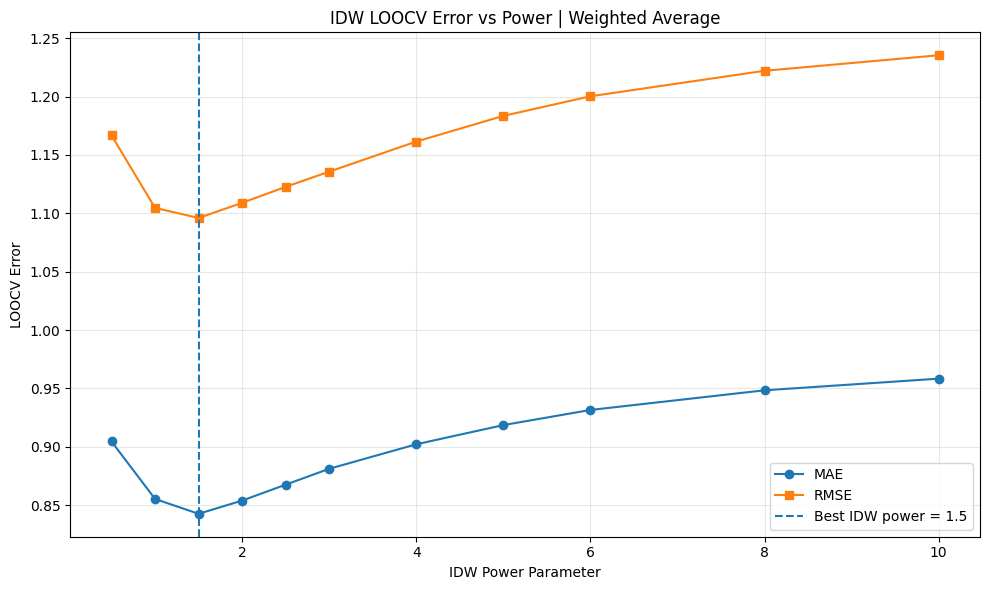

In [ ]:
csv_path = ALL_GT_CLUSTERS_CSV
output_folder = LOOCV_DIR

summary_wa, per_cluster_wa, predictions_wa = compare_loocv_interpolation_methods(
    csv_path=csv_path,
    value_column="Weighted Average",
    idw_powers=[0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10],
    kriging_variogram_models=[
        "linear",
        "power",
        "spherical",
        "exponential",
        "gaussian"
    ],
    include_ordinary_kriging=True,
    include_universal_kriging=True,
    lat_col="Latitude",
    lon_col="Longitude",
    cluster_col="Cluster",
    min_cluster_size=4,
    use_largest_cluster_only=False,
    output_folder=output_folder,
    save_name="weighted_average_loocv_all_methods",
    show_plot=True
)

Original rows: 361
Rows usable after removing NaN and DBSCAN noise: 290
Rows removed: 71

Non-noise cluster counts:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Using all clusters with at least 4 points:
[0, 1, 2, 3, 4, 5]

Evaluating method: IDW_power_0.5

Evaluating method: IDW_power_1

Evaluating method: IDW_power_1.5

Evaluating method: IDW_power_2

Evaluating method: IDW_power_2.5

Evaluating method: IDW_power_3

Evaluating method: IDW_power_4

Evaluating method: IDW_power_5

Evaluating method: IDW_power_6

Evaluating method: IDW_power_8

Evaluating method: IDW_power_10

Evaluating method: OK_linear

Evaluating method: OK_power

Evaluating method: OK_spherical

Evaluating method: OK_exponential

Evaluating method: OK_gaussian

Evaluating method: UK_linear

Evaluating method: UK_power

Evaluating method: UK_spherical

Evaluating method: UK_exponential

Evaluating method: UK_gaussian

Overall LOOCV method comparison:


,Value_Column,Method,Method_Label,Parameter_Name,Parameter_Value,N_LOOCV,MAE,RMSE,Bias,Median_Absolute_Error,Clusters_Used
0,Mode,idw,IDW_power_2,power,2,284,1.226502,1.523566,-0.016697,1.038531,"[0, 1, 2, 3, 4, 5]"
1,Mode,idw,IDW_power_1.5,power,1.5,284,1.226792,1.499125,-0.006732,1.094749,"[0, 1, 2, 3, 4, 5]"
2,Mode,idw,IDW_power_2.5,power,2.5,284,1.230710,1.548887,-0.021049,1.007729,"[0, 1, 2, 3, 4, 5]"
3,Mode,idw,IDW_power_3,power,3,284,1.236386,1.571422,-0.022978,1.001274,"[0, 1, 2, 3, 4, 5]"
4,Mode,ordinary_kriging,OK_exponential,variogram_model,exponential,284,1.237207,1.459000,-0.020730,1.108534,"[0, 1, 2, 3, 4, 5]"
5,Mode,idw,IDW_power_4,power,4,284,1.241312,1.609592,-0.024243,1.000015,"[0, 1, 2, 3, 4, 5]"
6,Mode,idw,IDW_power_1,power,1,284,1.245682,1.499959,0.007349,1.145218,"[0, 1, 2, 3, 4, 5]"
7,Mode,idw,IDW_power_5,power,5,284,1.247692,1.638853,-0.024696,1.000002,"[0, 1, 2, 3, 4, 5]"
8,Mode,idw,IDW_power_6,power,6,284,1.253795,1.661022,-0.025681,1.000000,"[0, 1, 2, 3, 4, 5]"
9,Mode,idw,IDW_power_8,power,8,284,1.262393,1.691737,-0.029503,1.000000,"[0, 1, 2, 3, 4, 5]"



Best method by LOOCV MAE:


,Value_Column,Method,Method_Label,Parameter_Name,Parameter_Value,N_LOOCV,MAE,RMSE,Bias,Median_Absolute_Error,Clusters_Used
0,Mode,idw,IDW_power_2,power,2,284,1.226502,1.523566,-0.016697,1.038531,"[0, 1, 2, 3, 4, 5]"



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/loocv/weighted_average_loocv_all_methods_summary.csv
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/loocv/weighted_average_loocv_all_methods_per_cluster.csv
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/loocv/weighted_average_loocv_all_methods_predictions.csv
Saved IDW plot:
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/loocv/weighted_average_loocv_all_methods_idw_power_plot.png


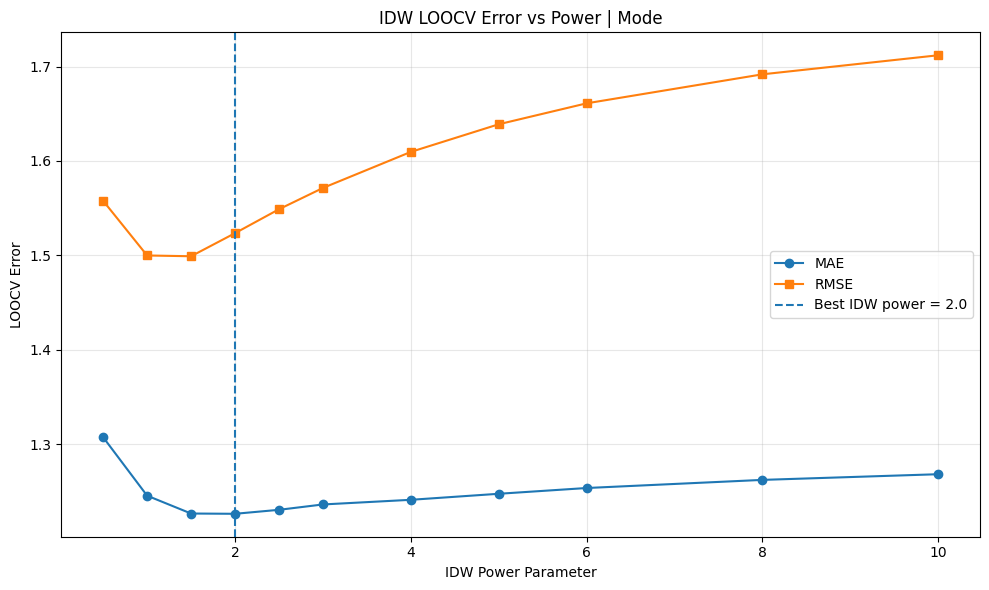

In [ ]:
summary_mode, per_cluster_mode, predictions_mode = compare_loocv_interpolation_methods(
    csv_path=csv_path,
    value_column="Mode",
    idw_powers=[0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10],
    kriging_variogram_models=[
        "linear",
        "power",
        "spherical",
        "exponential",
        "gaussian"
    ],
    include_ordinary_kriging=True,
    include_universal_kriging=True,
    lat_col="Latitude",
    lon_col="Longitude",
    cluster_col="Cluster",
    min_cluster_size=4,
    use_largest_cluster_only=False,
    output_folder=output_folder,
    save_name="mode_loocv_all_methods",  # the original run reused the weighted-average name
    show_plot=True
)

On the ground-truth weighted-average scores (first cell), the lowest LOOCV MAE was obtained with IDW power 1.5 (0.843), followed by ordinary kriging with an exponential variogram (0.847, which had the lowest RMSE, 1.075) and IDW powers 2 (0.854) and 1 (0.855). On the mode scores (second cell), the lowest LOOCV MAE was at IDW power 2 (1.227), with power 1.5 practically equal. In both runs the LOOCV error increased steadily for powers above 2 (weighted average: 0.919 at power 5 and 0.958 at power 10). The lowest LOOCV MAE at power 2 stated in the manuscript (Figure 8) is that of the mode-score run; on the weighted-average scores the lowest is at power 1.5. Kriging with a Gaussian variogram gave very large errors on the weighted-average scores (MAE 2.95 for ordinary and 2.98 for universal kriging).

LOOCV measures how accurately an interpolation method reconstructs held-out observation points. It does not measure how similar the ground-truth and predicted heatmaps are. Section 8 compares the interpolators on that second criterion and explains why the manuscript uses IDW power 5 for the final heatmaps.

## 7. Predictions for the full dataset

The test set has 59 images, of which 53 are geotagged, too few for detailed heatmaps. To compare heatmaps over the whole surveyed area, the trained model is applied to every annotated image. The checkpoint is read from `CHECKPOINT_PATH` or, if that file does not exist, downloaded from Hugging Face. The architecture must match notebook 01: a `segmentation_models_pytorch` SegFormer with a MiT-B2 encoder, nine output classes and 768 decoder channels. The checkpoint stores the classification head as `segmentation_head.weight` and `segmentation_head.bias`, which current versions of the library name `segmentation_head.0.*`, so the keys are renamed before loading with `strict=True`.

Preprocessing repeats notebook 01: the pipeline stored with the pretrained checkpoint, which resizes to 1024 × 1024 and normalises with the ImageNet channel means and standard deviations. The predicted logits are resized to the original image size before the arg-max, and each predicted mask is aggregated with the same mode and weighted-average rules as the ground truth.

The 361 images include the training and validation images of notebook 01, so agreement over the full dataset (Section 8) is partly measured on images the model has seen. The geotagged test subset (Section 9) provides the out-of-sample comparison. Masks are matched to photographs with the rule of notebook 01 (Section 5), so all 361 annotated images are predicted. The cell after the prediction compares the scores of the test images with those of notebook 01.

In [ ]:
# Load the trained SegFormer-B2 checkpoint (local file, or Hugging Face if missing)
import torch

try:
    import segmentation_models_pytorch as smp
    print("segmentation_models_pytorch already installed.")
except ImportError:
    !pip install -q segmentation-models-pytorch
    import segmentation_models_pytorch as smp
    print("Installed segmentation_models_pytorch.")

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 2. Checkpoint path
checkpoint_path = CHECKPOINT_PATH

if not os.path.exists(checkpoint_path):
    from huggingface_hub import hf_hub_download
    print(f"No checkpoint at {checkpoint_path}; downloading {HF_CHECKPOINT_FILENAME} from {HF_REPO_ID}")
    checkpoint_path = hf_hub_download(repo_id=HF_REPO_ID, filename=HF_CHECKPOINT_FILENAME)

checkpoint = torch.load(checkpoint_path, map_location=device)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

print("Checkpoint loaded.")
print("Number of weights:", len(state_dict))

# 3. Fix segmentation_head key names if needed
# The checkpoint stores segmentation_head.weight/.bias; current SMP versions
# expect segmentation_head.0.weight/.bias.
fixed_state_dict = {}

for key, value in state_dict.items():
    new_key = key

    if key == "segmentation_head.weight":
        new_key = "segmentation_head.0.weight"

    elif key == "segmentation_head.bias":
        new_key = "segmentation_head.0.bias"

    fixed_state_dict[new_key] = value

state_dict = fixed_state_dict

# 4. Recreate the model architecture
# Encoder MiT-B2 (stage widths 64, 128, 320, 512), 768 decoder channels, 9 classes
num_classes = 9

model = smp.Segformer(
    encoder_name="mit_b2",
    encoder_weights=None,
    in_channels=3,
    classes=num_classes,
    decoder_segmentation_channels=768
)

model.to(device)

print("Model architecture recreated.")

# 5. Load weights strictly
model.load_state_dict(state_dict, strict=True)

model.to(device)
model.eval()

print("\nModel loaded successfully and ready for inference.")
print("Device:", next(model.parameters()).device)

if isinstance(checkpoint, dict):
    print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
    print("Best val loss:", checkpoint.get("best_val_loss", "unknown"))
    print("Best epoch:", checkpoint.get("best_epoch", "unknown"))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.3 MB/s eta 0:00:00
Installed segmentation_models_pytorch.
Using device: cuda
Checkpoint loaded.
Number of weights: 348
Model architecture recreated.

Model loaded successfully and ready for inference.
Device: cuda:0
Checkpoint epoch: 21
Best val loss: 1.5626950349126543
Best epoch: 21


In [ ]:
import albumentations as A

# Same preprocessing as notebook 01: the pipeline stored with the pretrained
# checkpoint (resize to 1024 x 1024, ImageNet mean and standard deviation)
BASE_CHECKPOINT = "smp-hub/segformer-b2-1024x1024-city-160k"
preprocessing = A.Compose.from_pretrained(BASE_CHECKPOINT)

print(preprocessing)

In [ ]:
# Inference for a single image
import torch.nn.functional as F


# 1. Helper: get logits from model output
# Hugging Face SegFormer usually returns an object with .logits.
# Some custom models return logits directly.
def get_logits(model_output):
    if hasattr(model_output, "logits"):
        return model_output.logits
    return model_output


# 2. Segmentation function
def perform_segmentation(image_path, model, preprocessing, device):
    """
    Runs semantic segmentation on one image.
    """

    try:
        image = Image.open(image_path).convert("RGB")
    except Exception as e:
        print(f"Error opening image {image_path}: {e}")
        return None, None

    image_np = np.array(image)
    original_h, original_w = image_np.shape[:2]

    processed = preprocessing(image=image_np)
    processed_image = processed["image"]

    if isinstance(processed_image, torch.Tensor):
        input_tensor = processed_image.unsqueeze(0).float().to(device)

        if input_tensor.ndim == 4 and input_tensor.shape[-1] == 3:
            input_tensor = input_tensor.permute(0, 3, 1, 2)

    else:
        input_tensor = (
            torch.as_tensor(processed_image)
            .permute(2, 0, 1)
            .unsqueeze(0)
            .float()
            .to(device)
        )

    model.eval()

    with torch.no_grad():
        outputs = model(input_tensor)
        logits = get_logits(outputs)

        logits = F.interpolate(
            logits,
            size=(original_h, original_w),
            mode="bilinear",
            align_corners=False
        )

        pred_mask = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)

    return image_np, pred_mask

In [ ]:
# Aggregate pixel-level segmentation mask to image-level score
# Mode and explicit pixel-count weighted average
from scipy.stats import mode


def aggregate_mask(mask, method="mode", valid_labels=(3, 4, 5, 6, 7, 8), no_damage_value=np.nan):
    """
    Aggregate a pixel-wise segmentation mask into one image-level damage score.

    Only damage-level classes are included:
        3 = Damage A
        4 = Damage B
        5 = Damage C
        6 = Damage D
        7 = Damage E
        8 = Damage F

    Non-damage classes are ignored:
        0 = Background
        1 = Machinery
        2 = Personnel

    Methods
    -------
    "mode":
        Returns the most frequent damage class.

    "weighted average":
        Returns the pixel-count weighted average of the damage class IDs:

            sum(class_id * number_of_pixels_in_class) / total_damage_pixels

    Returns
    -------
    int, float, or np.nan
        Aggregated image-level damage score.
    """

    if isinstance(mask, torch.Tensor):
        mask = mask.detach().cpu().numpy()

    mask = np.asarray(mask)

    if mask.ndim != 2:
        raise ValueError(
            f"Expected a 2D class-ID mask, but got shape {mask.shape}. "
            "If this is an RGB mask, convert it to class IDs first."
        )

    flat = mask.ravel()
    valid_labels = np.array(valid_labels)

    # Keep only A-F damage pixels
    flat_valid = flat[np.isin(flat, valid_labels)]

    if len(flat_valid) == 0:
        return no_damage_value

    if method == "mode":
        return int(mode(flat_valid, keepdims=True).mode[0])

    elif method == "weighted average":
        counts = np.array([
            np.sum(flat_valid == label)
            for label in valid_labels
        ])

        weighted_average = np.sum(valid_labels * counts) / np.sum(counts)

        return float(weighted_average)

    else:
        raise ValueError(
            "Unknown aggregation method. Choose 'mode' or 'weighted average'."
        )

In [ ]:
# Predict all 361 annotated images and merge with GT scores, coordinates and clusters

# 1. Paths
gt_full_csv_path = ALL_GT_CLUSTERS_CSV

output_folder = FULL_PRED_DIR
os.makedirs(output_folder, exist_ok=True)

pred_masks_folder = os.path.join(output_folder, "predicted_masks")
os.makedirs(pred_masks_folder, exist_ok=True)

pred_full_csv_path = os.path.join(
    output_folder,
    "full_dataset_pred_image_level_scores_with_gps_clusters.csv"
)

merged_full_csv_path = FULL_GT_PRED_CSV

missing_csv_path = os.path.join(
    output_folder,
    "full_dataset_prediction_missing_or_failed_images.csv"
)

# 2. Image folders: IMAGE_DIR first, then other common locations
possible_image_folders = [
    IMAGE_DIR,
    "/content/turkey_gt_images",
    "/content/images",
    os.path.join(DRIVE_ROOT, "segformer_checkpoints", "images"),
    "/kaggle/working/turkey_gt_images",
    "/kaggle/input/turkey-gt-images",
]

possible_image_folders = list(dict.fromkeys(possible_image_folders))

print("Image folders searched:")
for folder in possible_image_folders:
    print(folder, "exists:", os.path.exists(folder))

# 3. Helpers
def normalize_image_id(value):
    if pd.isna(value):
        return np.nan

    s = str(value).strip()
    s = os.path.basename(s)

    # remove extension
    s = re.sub(r"\.(jpg|jpeg|png|tif|tiff)$", "", s, flags=re.IGNORECASE)

    # Label_327_UUID -> UUID
    s = re.sub(r"^Label_\d+_", "", s, flags=re.IGNORECASE)

    return s


def find_existing_image_path(filename):
    if pd.isna(filename):
        return None

    filename = str(filename).strip()

    if os.path.exists(filename):
        return filename

    base = os.path.basename(filename)
    image_id = normalize_image_id(base)

    # Try exact filename
    for folder in possible_image_folders:
        candidate = os.path.join(folder, base)
        if os.path.exists(candidate):
            return candidate

    # Try normalized ID with common image extensions
    for folder in possible_image_folders:
        for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
            candidate = os.path.join(folder, image_id + ext)
            if os.path.exists(candidate):
                return candidate

    return None


def get_present_classes(mask):
    return sorted([int(v) for v in np.unique(mask)])


def get_damage_pixel_counts(mask, valid_labels=(3, 4, 5, 6, 7, 8)):
    return {
        f"Pred_Pixels_Class_{label}": int(np.sum(mask == label))
        for label in valid_labels
    }


# 4. Load full GT + GPS + clusters file
gt_df = pd.read_csv(gt_full_csv_path)
gt_df.columns = gt_df.columns.str.strip()

print("\nLoaded GT full file:")
print(gt_full_csv_path)
print("Shape:", gt_df.shape)
print("Columns:", gt_df.columns.tolist())

required_cols = [
    "Filename",
    "Mode",
    "Weighted Average",
    "Latitude",
    "Longitude",
    "Cluster"
]

missing_cols = [c for c in required_cols if c not in gt_df.columns]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}\n"
        f"Available columns: {gt_df.columns.tolist()}"
    )

# 5. Predict all 361 images
model.to(device)
model.eval()

prediction_rows = []
missing_rows = []

for idx, row in tqdm(gt_df.iterrows(), total=len(gt_df), desc="Predicting full dataset"):

    filename = row["Filename"]
    image_id = normalize_image_id(filename)

    image_path = find_existing_image_path(filename)

    if image_path is None:
        missing_rows.append({
            "Index": idx,
            "Filename": filename,
            "merge_id": image_id,
            "Reason": "Image file not found"
        })
        continue

    image_np, pred_mask = perform_segmentation(
        image_path=image_path,
        model=model,
        preprocessing=preprocessing,
        device=device
    )

    if pred_mask is None:
        missing_rows.append({
            "Index": idx,
            "Filename": filename,
            "merge_id": image_id,
            "Image_Path": image_path,
            "Reason": "Segmentation failed"
        })
        continue

    pred_classes = get_present_classes(pred_mask)
    pred_damage_classes = [c for c in pred_classes if c in [3, 4, 5, 6, 7, 8]]

    mode_pred = aggregate_mask(pred_mask, method="mode")
    wa_pred = aggregate_mask(pred_mask, method="weighted average")

    if pd.isna(wa_pred):
        wa_pred_ceil = np.nan
        wa_pred_floor = np.nan
        wa_pred_round = np.nan
    else:
        wa_pred_ceil = int(np.ceil(wa_pred))
        wa_pred_floor = int(np.floor(wa_pred))
        wa_pred_round = int(np.round(wa_pred))

    damage_counts = get_damage_pixel_counts(pred_mask)
    total_pred_damage_pixels = int(sum(damage_counts.values()))

    pred_mask_filename = f"Pred_{image_id}.png"
    pred_mask_path = os.path.join(pred_masks_folder, pred_mask_filename)
    Image.fromarray(pred_mask.astype(np.uint8)).save(pred_mask_path)

    prediction_rows.append({
        "Filename": filename,
        "merge_id": image_id,
        "Image_Path": image_path,
        "Pred_Mask_Path": pred_mask_path,

        "Latitude": row["Latitude"],
        "Longitude": row["Longitude"],
        "Cluster": row["Cluster"],

        "Mode_Pred": mode_pred,
        "Weighted Average_Pred": wa_pred,
        "Weighted Average_Pred ceil": wa_pred_ceil,
        "Weighted Average_Pred floor": wa_pred_floor,
        "Weighted Average_Pred round": wa_pred_round,

        "Predicted Classes": str(pred_classes),
        "Predicted Damage Classes": str(pred_damage_classes),
        "Total_Pred_Damage_Pixels_3_to_8": total_pred_damage_pixels,

        **damage_counts
    })

pred_df = pd.DataFrame(prediction_rows)
missing_df = pd.DataFrame(missing_rows)

pred_df.to_csv(pred_full_csv_path, index=False)
missing_df.to_csv(missing_csv_path, index=False)

print("\nPrediction rows created:", len(pred_df))
print("Missing/failed rows:", len(missing_df))

print("\nSaved prediction CSV:")
print(pred_full_csv_path)

print("\nSaved missing/failed CSV:")
print(missing_csv_path)

display(pred_df.head())

# 6. Merge GT + pred into one full spatial CSV
gt_merge = gt_df.copy()
gt_merge["merge_id"] = gt_merge["Filename"].apply(normalize_image_id)

gt_merge = gt_merge.rename(columns={
    "Mode": "Mode_GT",
    "Weighted Average": "Weighted Average_GT"
})

merged = gt_merge.merge(
    pred_df,
    on="merge_id",
    how="left",
    suffixes=("_GT", "_Pred")
)

# Prefer GT coordinates/cluster as canonical
if "Latitude_GT" in merged.columns:
    merged["Latitude"] = merged["Latitude_GT"]
if "Longitude_GT" in merged.columns:
    merged["Longitude"] = merged["Longitude_GT"]
if "Cluster_GT" in merged.columns:
    merged["Cluster"] = merged["Cluster_GT"]

# Numeric conversion
numeric_cols = [
    "Mode_GT",
    "Weighted Average_GT",
    "Mode_Pred",
    "Weighted Average_Pred",
    "Weighted Average_Pred ceil",
    "Weighted Average_Pred floor",
    "Weighted Average_Pred round",
    "Latitude",
    "Longitude",
    "Cluster"
]

for col in numeric_cols:
    if col in merged.columns:
        merged[col] = pd.to_numeric(merged[col], errors="coerce")

# Error columns
merged["WA_Error"] = merged["Weighted Average_Pred"] - merged["Weighted Average_GT"]
merged["WA_Absolute_Error"] = merged["WA_Error"].abs()
merged["WA_Squared_Error"] = merged["WA_Error"] ** 2

merged["Mode_Error"] = merged["Mode_Pred"] - merged["Mode_GT"]
merged["Mode_Absolute_Error"] = merged["Mode_Error"].abs()

merged["Weighted Average_GT ceil"] = np.ceil(merged["Weighted Average_GT"])
merged["Weighted Average_GT floor"] = np.floor(merged["Weighted Average_GT"])
merged["Weighted Average_GT round"] = np.round(merged["Weighted Average_GT"])

merged["WA_Ceil_Error"] = merged["Weighted Average_Pred ceil"] - merged["Weighted Average_GT ceil"]
merged["WA_Floor_Error"] = merged["Weighted Average_Pred floor"] - merged["Weighted Average_GT floor"]
merged["WA_Round_Error"] = merged["Weighted Average_Pred round"] - merged["Weighted Average_GT round"]

merged["WA_Ceil_Absolute_Error"] = merged["WA_Ceil_Error"].abs()
merged["WA_Floor_Absolute_Error"] = merged["WA_Floor_Error"].abs()
merged["WA_Round_Absolute_Error"] = merged["WA_Round_Error"].abs()

merged["WA_Error_Direction"] = np.where(
    merged["WA_Error"] > 0,
    "Overestimate",
    np.where(merged["WA_Error"] < 0, "Underestimate", "Exact")
)

merged.to_csv(merged_full_csv_path, index=False)

print("\nSaved merged GT + pred CSV:")
print(merged_full_csv_path)

print("\nRows with predictions:", merged["Weighted Average_Pred"].notna().sum())
print("Rows missing predictions:", merged["Weighted Average_Pred"].isna().sum())

valid = merged.dropna(subset=["Weighted Average_GT", "Weighted Average_Pred"]).copy()

print("\nValid rows for evaluation:", len(valid))

if len(valid) > 0:
    print("\nSummary:")
    print("WA MAE:", valid["WA_Absolute_Error"].mean())
    print("WA RMSE:", np.sqrt(valid["WA_Squared_Error"].mean()))
    print("WA Bias:", valid["WA_Error"].mean())
    print("Mode MAE:", valid["Mode_Absolute_Error"].mean())

    print("\nGT Mode distribution:")
    print(valid["Mode_GT"].value_counts().sort_index())

    print("\nPredicted Mode distribution:")
    print(valid["Mode_Pred"].value_counts().sort_index())

display(merged.head())

Image folders searched:
/content/turkey_gt_images exists: True
/content/images exists: False
/content/drive/MyDrive/segformer_checkpoints/images exists: False
/kaggle/working/turkey_gt_images exists: False
/kaggle/input/turkey-gt-images exists: False

Loaded GT full file:
/content/drive/MyDrive/segformer_checkpoints/interpolation_evaluation/all_gt_image_level_scores_with_gps_clusters.csv
Shape: (361, 10)
Columns: ['Filename', 'Mask Filename', 'Mask Path', 'Mode', 'Weighted Average', 'GT Classes', 'Num Triage Pixels', 'Latitude', 'Longitude', 'Cluster']


Predicting full dataset:   0%|          | 0/361 [00:00<?, ?it/s]


Prediction rows created: 346
Missing/failed rows: 15

Saved prediction CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_pred_image_level_scores_with_gps_clusters.csv

Saved missing/failed CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_prediction_missing_or_failed_images.csv


,Filename,merge_id,Image_Path,Pred_Mask_Path,Latitude,Longitude,Cluster,Mode_Pred,Weighted Average_Pred,Weighted Average_Pred ceil,...,Weighted Average_Pred round,Predicted Classes,Predicted Damage Classes,Total_Pred_Damage_Pixels_3_to_8,Pred_Pixels_Class_3,Pred_Pixels_Class_4,Pred_Pixels_Class_5,Pred_Pixels_Class_6,Pred_Pixels_Class_7,Pred_Pixels_Class_8
0,B80ACF18-864C-4E62-BB4A-56820D4621C7.jpg,B80ACF18-864C-4E62-BB4A-56820D4621C7,/content/turkey_gt_images/B80ACF18-864C-4E62-B...,/content/drive/MyDrive/segformer_checkpoints/i...,36.196113,36.159400,0.0,5,5.397507,6,...,5,"[0, 3, 4, 5, 6, 7, 8]","[3, 4, 5, 6, 7, 8]",916102,1,37107,718274,40428,38,120254
1,B72E134E-3779-4EB8-9C30-42E284F8E511.jpg,B72E134E-3779-4EB8-9C30-42E284F8E511,/content/turkey_gt_images/B72E134E-3779-4EB8-9...,/content/drive/MyDrive/segformer_checkpoints/i...,37.574378,36.933797,1.0,8,7.944994,8,...,8,"[0, 1, 2, 4, 5, 6, 7, 8]","[4, 5, 6, 7, 8]",874378,0,9253,3534,234,14,861343
2,B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B.jpg,B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B,/content/turkey_gt_images/B5D8A6DA-7663-4EAB-9...,/content/drive/MyDrive/segformer_checkpoints/i...,36.196854,36.150558,0.0,6,6.659050,7,...,7,"[0, 1, 2, 4, 5, 6, 7, 8]","[4, 5, 6, 7, 8]",763916,0,8857,22398,426811,68129,237721
3,B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D.jpg,B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D,/content/turkey_gt_images/B4DDF3D5-A776-4AB2-B...,/content/drive/MyDrive/segformer_checkpoints/i...,NaN,NaN,NaN,5,5.279212,6,...,5,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","[3, 4, 5, 6, 7, 8]",2319320,46271,187893,1721325,42181,79114,242536
4,B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8.jpg,B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8,/content/turkey_gt_images/B2B3C2E9-5A4C-4889-B...,/content/drive/MyDrive/segformer_checkpoints/i...,36.195602,36.159569,0.0,7,6.226942,7,...,6,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","[3, 4, 5, 6, 7, 8]",779008,2182,91176,127706,157517,307460,92967



Saved merged GT + pred CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv

Rows with predictions: 346
Rows missing predictions: 15

Valid rows for evaluation: 346

Summary:
WA MAE: 0.4748916891324604
WA RMSE: 0.6599142704884643
WA Bias: -0.007904247348925749
Mode MAE: 0.6473988439306358

GT Mode distribution:
Mode_GT
3     26
4     12
5     51
6     77
7     29
8    151
Name: count, dtype: int64

Predicted Mode distribution:
Mode_Pred
3.0     12
4.0     33
5.0     70
6.0     31
7.0     44
8.0    156
Name: count, dtype: int64


,Filename_GT,Mask Filename,Mask Path,Mode_GT,Weighted Average_GT,GT Classes,Num Triage Pixels,Latitude_GT,Longitude_GT,Cluster_GT,...,Weighted Average_GT ceil,Weighted Average_GT floor,Weighted Average_GT round,WA_Ceil_Error,WA_Floor_Error,WA_Round_Error,WA_Ceil_Absolute_Error,WA_Floor_Absolute_Error,WA_Round_Absolute_Error,WA_Error_Direction
0,B80ACF18-864C-4E62-BB4A-56820D4621C7.jpg,Label_100_B80ACF18-864C-4E62-BB4A-56820D4621C7...,/content/turkey_gt_masks/Label_100_B80ACF18-86...,5,5.540197,"[5, 8]",793489,36.196113,36.159400,0.0,...,6.0,5.0,6.0,0.0,0.0,-1.0,0.0,0.0,1.0,Underestimate
1,B72E134E-3779-4EB8-9C30-42E284F8E511.jpg,Label_101_B72E134E-3779-4EB8-9C30-42E284F8E511...,/content/turkey_gt_masks/Label_101_B72E134E-37...,8,7.824664,"[3, 8]",401059,37.574378,36.933797,1.0,...,8.0,7.0,8.0,0.0,0.0,0.0,0.0,0.0,0.0,Overestimate
2,B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B.jpg,Label_102_B5D8A6DA-7663-4EAB-91A1-45AF7DEB0A9B...,/content/turkey_gt_masks/Label_102_B5D8A6DA-76...,6,6.636815,"[6, 7, 8]",761898,36.196854,36.150558,0.0,...,7.0,6.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,Overestimate
3,B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D.jpg,Label_103_B4DDF3D5-A776-4AB2-B92A-6A26FF6A3A8D...,/content/turkey_gt_masks/Label_103_B4DDF3D5-A7...,5,5.660933,"[3, 5, 6, 8]",2269421,NaN,NaN,NaN,...,6.0,5.0,6.0,0.0,0.0,-1.0,0.0,0.0,1.0,Underestimate
4,B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8.jpg,Label_104_B2B3C2E9-5A4C-4889-BCC2-38A29B3300C8...,/content/turkey_gt_masks/Label_104_B2B3C2E9-5A...,8,7.042223,"[3, 8]",769339,36.195602,36.159569,0.0,...,8.0,7.0,7.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,Underestimate


The test images are among the 361 predicted here, so their scores can be compared with those written by notebook 01. With the same weights and preprocessing the two should agree up to GPU rounding; a larger difference means the preprocessing or the checkpoint differs between the notebooks.

In [ ]:
# Check: test-image scores must match notebook 01
test_nb01 = pd.read_csv(MERGED_TEST_CSV)
test_nb01.columns = test_nb01.columns.str.strip()
test_nb01["merge_id"] = test_nb01["Filename_GT"].apply(normalize_image_id)

check = test_nb01[["merge_id", "Weighted Average_Pred"]].merge(
    pred_df[["merge_id", "Weighted Average_Pred"]],
    on="merge_id",
    suffixes=("_nb01", "_nb02")
)
diff = (check["Weighted Average_Pred_nb02"] - check["Weighted Average_Pred_nb01"]).abs()

print(f"Test images matched: {len(check)} of {len(test_nb01)}")
print(f"Largest difference in weighted-average score: {diff.max():.4f}")
print(f"Mean difference: {diff.mean():.4f}")

## 8. Full-dataset heatmaps: ground truth against prediction

For each interpolation setting we build two heatmaps on identical grids, one from the ground-truth weighted averages and one from the predicted weighted averages of the same images, and compare them cell by cell (8 clusters × 300 × 300 = 720,000 cells). The first cell does this for IDW powers 0.5 to 5 and for ordinary kriging with five variograms, and ranks the settings by 2D correlation and then MAE. Its summary table is Table 6 of the manuscript.

The 2D correlation increased with the IDW power, from 0.722 at power 1 to 0.808 at power 5, whereas the MAE was lowest for the smoothest settings (0.236 at power 0.5 and 0.253 at power 1) and rose to 0.365 at power 5. The best kriging variant, with a spherical variogram, reached 0.766 (MAE 0.295); ordinary kriging with the power variogram gave an almost uncorrelated pair of surfaces (0.076, MAE 1.623).

The manuscript selects IDW power 5 for the final heatmaps and for the label-level analysis. Increasing the IDW power gives more weight to nearby observations and produces a more localized surface. This can increase sensitivity to local sampling noise and worsen the LOOCV MAE (Section 6), while preserving local spatial patterns and increasing the 2D correlation. Because adjacent buildings often had very different triage outcomes, the more patchwork surface of a high power better reflects the heterogeneous nature of building-level earthquake damage, and kriging was considered less suitable because its smoothing assumptions were less consistent with the observed local heterogeneity. The localized surface comes at the cost of a larger cell-wise error, since the map is more sensitive to nearby prediction errors (MAE 0.365 at power 5 against 0.253 at power 1).

In [ ]:
# GT vs predicted heatmaps for several interpolation methods (2D correlation, MAE, RMSE, bias)

# 1. Paths and settings
heatmap_output_folder = HEATMAP_METHOD_COMPARISON_DIR
os.makedirs(heatmap_output_folder, exist_ok=True)

full_dataset_spatial_clustered_csv_path = FULL_GT_PRED_CSV

lat_col = "Latitude"
lon_col = "Longitude"
filename_col = "Filename"
cluster_col = "Cluster"

gt_value_column = "Weighted Average_GT"
pred_value_column = "Weighted Average_Pred"

buffer_m = BUFFER_M
grid_res = GRID_RES

# 2. Define interpolation methods to compare
method_configs = []

# IDW powers 0.5 to 5
for p in [0.5, 1, 1.5, 2, 2.5, 3, 4, 5]:
    method_configs.append({
        "method_label": f"IDW_power_{p}",
        "interpolation_method": "idw",
        "method_params": {"power": p}
    })

# Ordinary kriging variograms
for variogram in ["exponential", "linear", "spherical", "power", "gaussian"]:
    method_configs.append({
        "method_label": f"OK_{variogram}",
        "interpolation_method": "ordinary_kriging",
        "method_params": {"variogram_model": variogram}
    })

# 3. Helper: detect interpolated value column
def find_interp_value_col(df):
    possible_cols = [
        "Interpolated",
        "Interpolated_Value",
        "Interpolated WA",
        "Weighted Average_GT",
        "Weighted Average_Pred",
        "Weighted Average",
        "Value"
    ]

    for col in possible_cols:
        if col in df.columns:
            return col

    for col in df.columns:
        if "interpolated" in col.lower() or "value" in col.lower():
            return col

    raise ValueError(f"Could not find interpolated value column. Columns: {df.columns.tolist()}")

# 4. Helper: compare GT and predicted heatmap tables
def compute_gt_pred_heatmap_metrics(gt_interp_df, pred_interp_df):
    gt_val_col = find_interp_value_col(gt_interp_df)
    pred_val_col = find_interp_value_col(pred_interp_df)

    merge_cols = [lat_col, lon_col]

    if cluster_col in gt_interp_df.columns and cluster_col in pred_interp_df.columns:
        merge_cols.append(cluster_col)

    gt_grid = gt_interp_df[merge_cols + [gt_val_col]].copy()
    pred_grid = pred_interp_df[merge_cols + [pred_val_col]].copy()

    gt_grid = gt_grid.rename(columns={gt_val_col: "GT_Heatmap_Value"})
    pred_grid = pred_grid.rename(columns={pred_val_col: "Pred_Heatmap_Value"})

    heatmap_compare = gt_grid.merge(
        pred_grid,
        on=merge_cols,
        how="inner"
    )

    heatmap_compare["GT_Heatmap_Value"] = pd.to_numeric(
        heatmap_compare["GT_Heatmap_Value"],
        errors="coerce"
    )

    heatmap_compare["Pred_Heatmap_Value"] = pd.to_numeric(
        heatmap_compare["Pred_Heatmap_Value"],
        errors="coerce"
    )

    heatmap_compare = heatmap_compare.dropna(
        subset=["GT_Heatmap_Value", "Pred_Heatmap_Value"]
    ).copy()

    if len(heatmap_compare) == 0:
        raise ValueError("No overlapping valid heatmap grid cells.")

    heatmap_compare["Error"] = (
        heatmap_compare["Pred_Heatmap_Value"]
        - heatmap_compare["GT_Heatmap_Value"]
    )

    heatmap_compare["Absolute_Error"] = heatmap_compare["Error"].abs()

    corr_2d = heatmap_compare["GT_Heatmap_Value"].corr(
        heatmap_compare["Pred_Heatmap_Value"]
    )

    mae = heatmap_compare["Absolute_Error"].mean()
    rmse = np.sqrt(np.mean(heatmap_compare["Error"] ** 2))
    bias = heatmap_compare["Error"].mean()

    return {
        "N_Grid_Cells": len(heatmap_compare),
        "Correlation_2D": corr_2d,
        "MAE": mae,
        "RMSE": rmse,
        "Bias": bias
    }, heatmap_compare

# 5. Run interpolation + GT-vs-pred comparison for each method
summary_rows = []
comparison_tables = {}

for config in method_configs:
    method_label = config["method_label"]
    interpolation_method = config["interpolation_method"]
    method_params = config["method_params"]

    print("\n" + "=" * 80)
    print("Running method:", method_label)
    print("=" * 80)

    safe_label = method_label.lower().replace(".", "_").replace(" ", "_")

    try:
        # GT heatmap
        gt_interp_df, gt_map, gt_loocv, gt_paths = interpolate_clusters_heatmap(
            csv_path=full_dataset_spatial_clustered_csv_path,
            value_column=gt_value_column,
            interpolation_method=interpolation_method,
            method_params=method_params,
            lat_col=lat_col,
            lon_col=lon_col,
            filename_col=filename_col,
            cluster_col=cluster_col,
            dataset_tag="gt_full",
            buffer_m=buffer_m,
            grid_res=grid_res,
            save_results=True,
            output_folder=heatmap_output_folder,
            save_name=f"gt_full_weighted_average_{safe_label}_heatmap",
            show_map=False,
            run_loocv_largest_cluster=False
        )

        # Predicted heatmap
        pred_interp_df, pred_map, pred_loocv, pred_paths = interpolate_clusters_heatmap(
            csv_path=full_dataset_spatial_clustered_csv_path,
            value_column=pred_value_column,
            interpolation_method=interpolation_method,
            method_params=method_params,
            lat_col=lat_col,
            lon_col=lon_col,
            filename_col=filename_col,
            cluster_col=cluster_col,
            dataset_tag="pred_full",
            buffer_m=buffer_m,
            grid_res=grid_res,
            save_results=True,
            output_folder=heatmap_output_folder,
            save_name=f"pred_full_weighted_average_{safe_label}_heatmap",
            show_map=False,
            run_loocv_largest_cluster=False
        )

        # Compare GT and predicted heatmaps
        metrics, heatmap_compare = compute_gt_pred_heatmap_metrics(
            gt_interp_df=gt_interp_df,
            pred_interp_df=pred_interp_df
        )

        comparison_tables[method_label] = heatmap_compare

        comparison_path = os.path.join(
            heatmap_output_folder,
            f"gt_pred_heatmap_comparison_{safe_label}.csv"
        )
        heatmap_compare.to_csv(comparison_path, index=False)

        summary_rows.append({
            "Method_Label": method_label,
            "Interpolation_Method": interpolation_method,
            "Method_Params": str(method_params),
            **metrics,
            "GT_Heatmap_File": str(gt_paths),
            "Pred_Heatmap_File": str(pred_paths),
            "Comparison_File": comparison_path,
            "Status": "success",
            "Error_Message": ""
        })

        print("2D correlation:", metrics["Correlation_2D"])
        print("MAE:", metrics["MAE"])
        print("RMSE:", metrics["RMSE"])
        print("Bias:", metrics["Bias"])

    except Exception as e:
        print("FAILED:", method_label)
        print(type(e).__name__, e)

        summary_rows.append({
            "Method_Label": method_label,
            "Interpolation_Method": interpolation_method,
            "Method_Params": str(method_params),
            "N_Grid_Cells": np.nan,
            "Correlation_2D": np.nan,
            "MAE": np.nan,
            "RMSE": np.nan,
            "Bias": np.nan,
            "GT_Heatmap_File": "",
            "Pred_Heatmap_File": "",
            "Comparison_File": "",
            "Status": "failed",
            "Error_Message": f"{type(e).__name__}: {e}"
        })

# 6. Create and save summary table
heatmap_method_summary_df = pd.DataFrame(summary_rows)

heatmap_method_summary_df = heatmap_method_summary_df.sort_values(
    by=["Correlation_2D", "MAE"],
    ascending=[False, True]
).reset_index(drop=True)

summary_path = os.path.join(
    heatmap_output_folder,
    "gt_pred_heatmap_2d_correlation_mae_method_summary.csv"
)

heatmap_method_summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 80)
print("Final method comparison summary")
print("=" * 80)
display(heatmap_method_summary_df)

print("\nSaved summary table:")
print(summary_path)

print("\nBest method by 2D correlation:")
display(heatmap_method_summary_df.head(1))


Running method: IDW_power_0.5
Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv
Original shape: (361, 49)
Value column: Weighted Average_GT
Interpolation method: idw
Method params: {'power': 0.5}
Save name: gt_full_weighted_average_idw_power_0_5_heatmap
⚠️ 'Filename' not found. Using row index in popups.
Rows after dropping missing coordinate/value/cluster rows: 296
Rows dropped: 65

Cluster counts used for interpolation:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Largest non-noise cluster: 0

✅ Interpolated values saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/method_comparison/gt_full_weighted_average_idw_power_0_5_heatmap.csv
✅ HTML map saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/method_comparison/gt_

,Method_Label,Interpolation_Method,Method_Params,N_Grid_Cells,Correlation_2D,MAE,RMSE,Bias,GT_Heatmap_File,Pred_Heatmap_File,Comparison_File,Status,Error_Message
0,IDW_power_5,idw,{'power': 5},720000,0.808361,0.365183,0.446320,-0.053389,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
1,IDW_power_4,idw,{'power': 4},720000,0.798061,0.349401,0.428596,-0.053254,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
2,IDW_power_3,idw,{'power': 3},720000,0.781016,0.326955,0.403855,-0.053718,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
3,IDW_power_2.5,idw,{'power': 2.5},720000,0.768148,0.312232,0.387849,-0.054330,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
4,OK_spherical,ordinary_kriging,{'variogram_model': 'spherical'},720000,0.765684,0.295392,0.348560,-0.039225,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
5,IDW_power_2,idw,{'power': 2},720000,0.751708,0.294647,0.369027,-0.055241,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
6,OK_linear,ordinary_kriging,{'variogram_model': 'linear'},720000,0.736382,0.281242,0.337153,-0.035942,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
7,IDW_power_1.5,idw,{'power': 1.5},720000,0.733959,0.274311,0.347738,-0.056364,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
8,IDW_power_0.5,idw,{'power': 0.5},720000,0.721978,0.235828,0.307728,-0.057991,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,
9,IDW_power_1,idw,{'power': 1},720000,0.721831,0.252741,0.325832,-0.057417,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,



Saved summary table:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/method_comparison/gt_pred_heatmap_2d_correlation_mae_method_summary.csv

Best method by 2D correlation:


,Method_Label,Interpolation_Method,Method_Params,N_Grid_Cells,Correlation_2D,MAE,RMSE,Bias,GT_Heatmap_File,Pred_Heatmap_File,Comparison_File,Status,Error_Message
0,IDW_power_5,idw,{'power': 5},720000,0.808361,0.365183,0.44632,-0.053389,{'csv': '/content/drive/MyDrive/segformer_chec...,{'csv': '/content/drive/MyDrive/segformer_chec...,/content/drive/MyDrive/segformer_checkpoints/s...,success,


The next six cells build and display the ground-truth and predicted heatmaps for three IDW powers. Each pair is the same call with a different `IDW_POWER`; they are kept as separate cells because each map is displayed and its CSV is read again later. Power 5 is the setting used in the manuscript; powers 1 and 2 are low-power settings close to the LOOCV optimum and are kept for comparison.

In the saved run the predicted power-5 heatmap was written to the `method_comparison` sub-folder rather than next to the other heatmaps. The code keeps that location so that later cells find the file and the printed paths agree with the saved output. The maps also print a warning that the column `Filename` is missing: the merged table calls it `Filename_GT`, so map pop-ups show the row index instead of the file name. The interpolated values are not affected.

Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv
Original shape: (361, 49)
Value column: Weighted Average_GT
Interpolation method: idw
Method params: {'power': 2}
Save name: gt_full_weighted_average_idw_power2_heatmap
⚠️ 'Filename' not found. Using row index in popups.
Rows after dropping missing coordinate/value/cluster rows: 296
Rows dropped: 65

Cluster counts used for interpolation:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Largest non-noise cluster: 0

✅ Interpolated values saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power2_heatmap.csv
✅ HTML map saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power2_heatmap.html
✅ LOOCV metrics saved to: /co


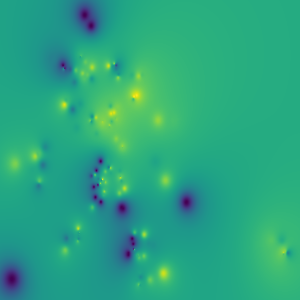
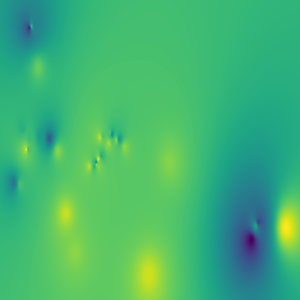
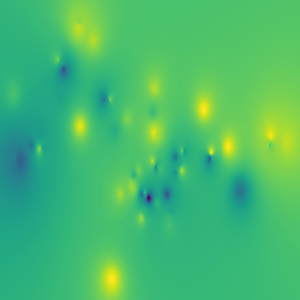
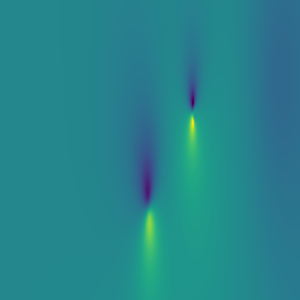
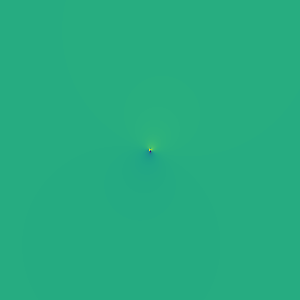
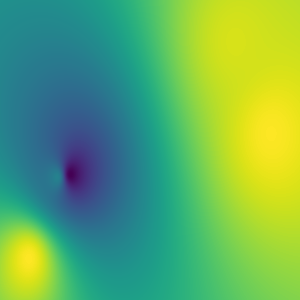
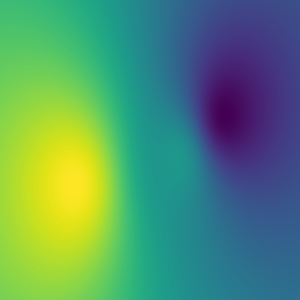
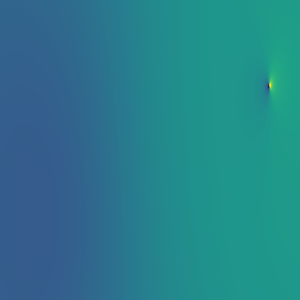

In [ ]:
# Full-dataset ground-truth weighted-average heatmap
IDW_POWER = 2

gt2_interp_df, gt2_map, gt2_loocv, gt2_paths = interpolate_clusters_heatmap(
    csv_path=FULL_GT_PRED_CSV,
    value_column="Weighted Average_GT",
    interpolation_method="idw",
    method_params={"power": IDW_POWER},
    lat_col="Latitude",
    lon_col="Longitude",
    filename_col="Filename",
    cluster_col="Cluster",
    dataset_tag="gt_full",
    buffer_m=BUFFER_M,
    grid_res=GRID_RES,
    save_results=True,
    output_folder=HEATMAP_DIR,
    save_name=f"gt_full_weighted_average_idw_power{IDW_POWER}_heatmap",
    show_map=True,
    run_loocv_largest_cluster=False
)

Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv
Original shape: (361, 49)
Value column: Weighted Average_Pred
Interpolation method: idw
Method params: {'power': 2}
Save name: pred_full_weighted_average_idw_power2_heatmap
⚠️ 'Filename' not found. Using row index in popups.
Rows after dropping missing coordinate/value/cluster rows: 296
Rows dropped: 65

Cluster counts used for interpolation:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Largest non-noise cluster: 0

✅ Interpolated values saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_full_weighted_average_idw_power2_heatmap.csv
✅ HTML map saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_full_weighted_average_idw_power2_heatmap.html
✅ LOOCV metrics saved


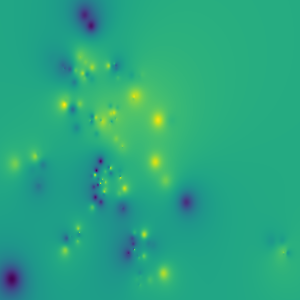
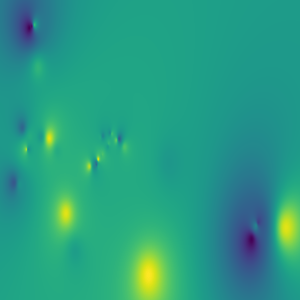
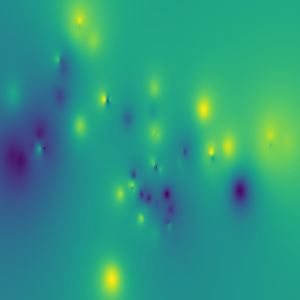
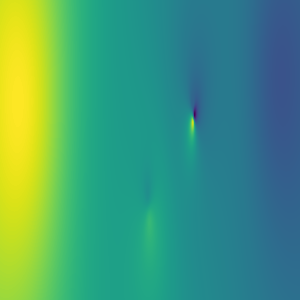
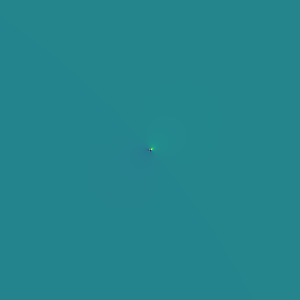
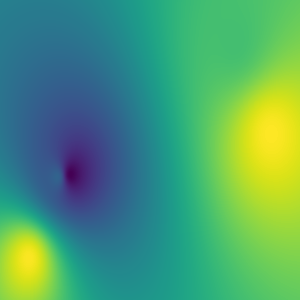
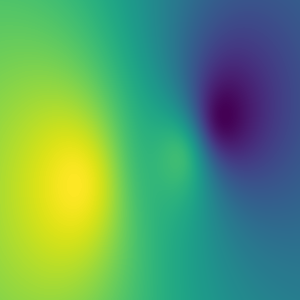
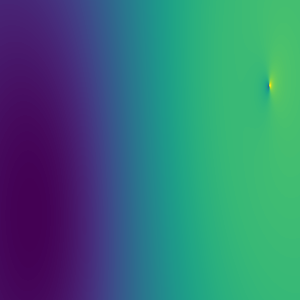

In [ ]:
# Full-dataset predicted weighted-average heatmap
IDW_POWER = 2

pred2_interp_df, pred2_map, pred2_loocv, pred2_paths = interpolate_clusters_heatmap(
    csv_path=FULL_GT_PRED_CSV,
    value_column="Weighted Average_Pred",
    interpolation_method="idw",
    method_params={"power": IDW_POWER},
    lat_col="Latitude",
    lon_col="Longitude",
    filename_col="Filename",
    cluster_col="Cluster",
    dataset_tag="pred_full",
    buffer_m=BUFFER_M,
    grid_res=GRID_RES,
    save_results=True,
    output_folder=HEATMAP_DIR,
    save_name=f"pred_full_weighted_average_idw_power{IDW_POWER}_heatmap",
    show_map=True,
    run_loocv_largest_cluster=False
)

Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv
Original shape: (361, 49)
Value column: Weighted Average_GT
Interpolation method: idw
Method params: {'power': 1}
Save name: gt_full_weighted_average_idw_power1_heatmap
⚠️ 'Filename' not found. Using row index in popups.
Rows after dropping missing coordinate/value/cluster rows: 296
Rows dropped: 65

Cluster counts used for interpolation:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Largest non-noise cluster: 0

✅ Interpolated values saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power1_heatmap.csv
✅ HTML map saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power1_heatmap.html
✅ LOOCV metrics saved to: /co


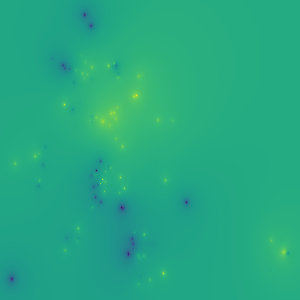
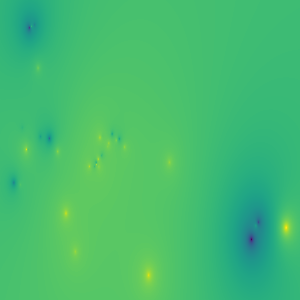
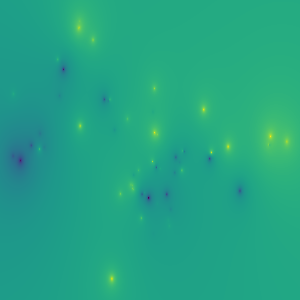
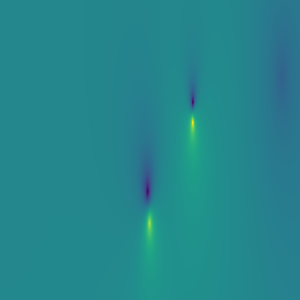
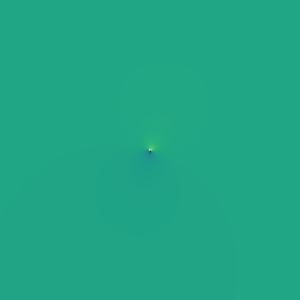
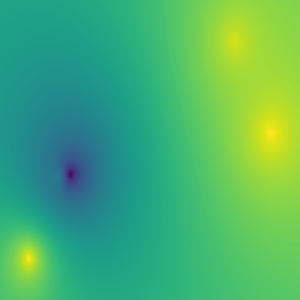
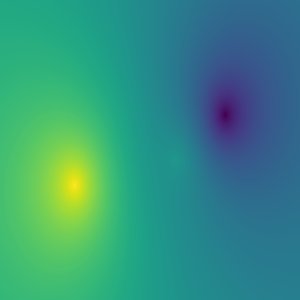
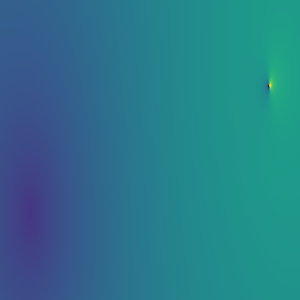

In [ ]:
# Full-dataset ground-truth weighted-average heatmap
IDW_POWER = 1

gt1_interp_df, gt1_map, gt1_loocv, gt1_paths = interpolate_clusters_heatmap(
    csv_path=FULL_GT_PRED_CSV,
    value_column="Weighted Average_GT",
    interpolation_method="idw",
    method_params={"power": IDW_POWER},
    lat_col="Latitude",
    lon_col="Longitude",
    filename_col="Filename",
    cluster_col="Cluster",
    dataset_tag="gt_full",
    buffer_m=BUFFER_M,
    grid_res=GRID_RES,
    save_results=True,
    output_folder=HEATMAP_DIR,
    save_name=f"gt_full_weighted_average_idw_power{IDW_POWER}_heatmap",
    show_map=True,
    run_loocv_largest_cluster=False
)

Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv
Original shape: (361, 49)
Value column: Weighted Average_Pred
Interpolation method: idw
Method params: {'power': 1}
Save name: pred_full_weighted_average_idw_power1_heatmap
⚠️ 'Filename' not found. Using row index in popups.
Rows after dropping missing coordinate/value/cluster rows: 296
Rows dropped: 65

Cluster counts used for interpolation:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Largest non-noise cluster: 0

✅ Interpolated values saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_full_weighted_average_idw_power1_heatmap.csv
✅ HTML map saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_full_weighted_average_idw_power1_heatmap.html
✅ LOOCV metrics saved


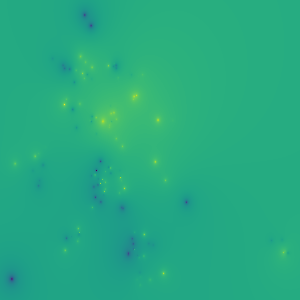
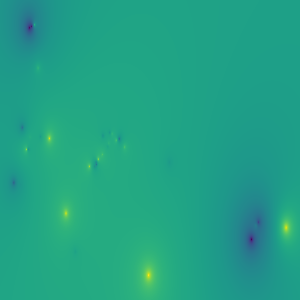
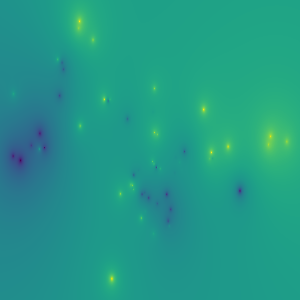
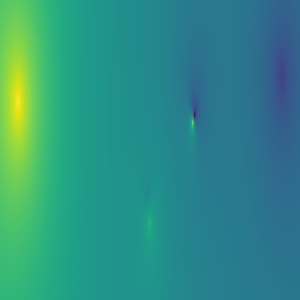
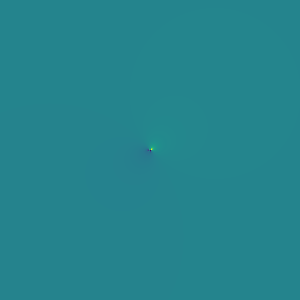
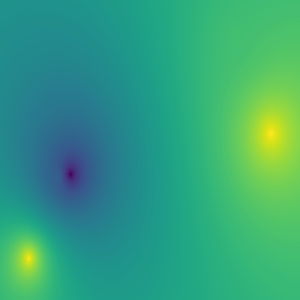
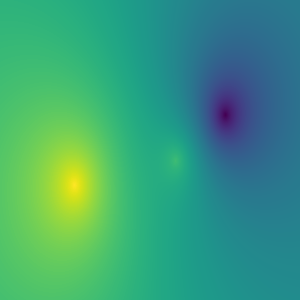
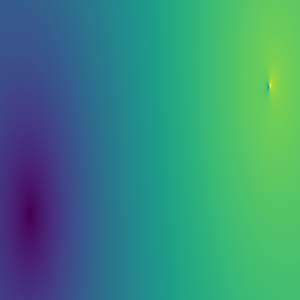

In [ ]:
# Full-dataset predicted weighted-average heatmap
IDW_POWER = 1

pred1_interp_df, pred1_map, pred1_loocv, pred1_paths = interpolate_clusters_heatmap(
    csv_path=FULL_GT_PRED_CSV,
    value_column="Weighted Average_Pred",
    interpolation_method="idw",
    method_params={"power": IDW_POWER},
    lat_col="Latitude",
    lon_col="Longitude",
    filename_col="Filename",
    cluster_col="Cluster",
    dataset_tag="pred_full",
    buffer_m=BUFFER_M,
    grid_res=GRID_RES,
    save_results=True,
    output_folder=HEATMAP_DIR,
    save_name=f"pred_full_weighted_average_idw_power{IDW_POWER}_heatmap",
    show_map=True,
    run_loocv_largest_cluster=False
)

Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv
Original shape: (361, 49)
Value column: Weighted Average_GT
Interpolation method: idw
Method params: {'power': 5}
Save name: gt_full_weighted_average_idw_power5_heatmap
⚠️ 'Filename' not found. Using row index in popups.
Rows after dropping missing coordinate/value/cluster rows: 296
Rows dropped: 65

Cluster counts used for interpolation:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Largest non-noise cluster: 0

✅ Interpolated values saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power5_heatmap.csv
✅ HTML map saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power5_heatmap.html
✅ LOOCV metrics saved to: /co


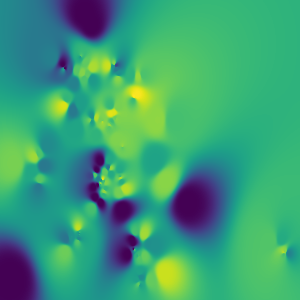
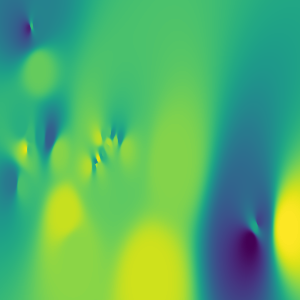
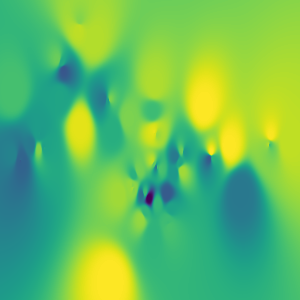
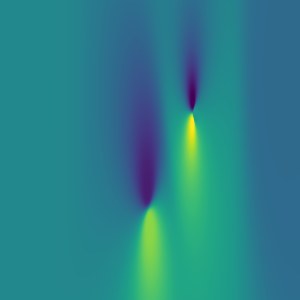
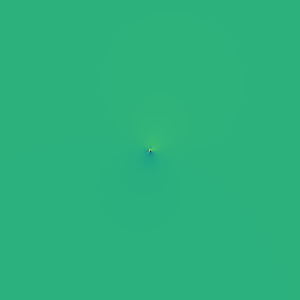
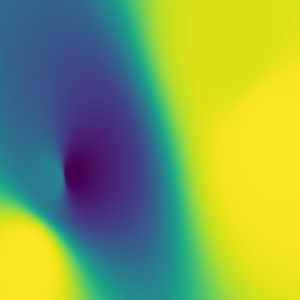
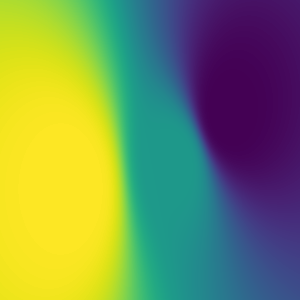
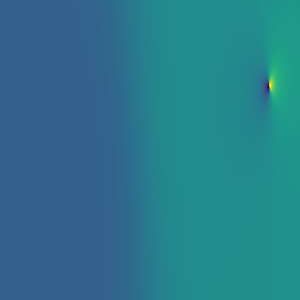

In [ ]:
# Full-dataset ground-truth weighted-average heatmap
IDW_POWER = 5

gt5_interp_df, gt5_map, gt5_loocv, gt5_paths = interpolate_clusters_heatmap(
    csv_path=FULL_GT_PRED_CSV,
    value_column="Weighted Average_GT",
    interpolation_method="idw",
    method_params={"power": IDW_POWER},
    lat_col="Latitude",
    lon_col="Longitude",
    filename_col="Filename",
    cluster_col="Cluster",
    dataset_tag="gt_full",
    buffer_m=BUFFER_M,
    grid_res=GRID_RES,
    save_results=True,
    output_folder=HEATMAP_DIR,
    save_name=f"gt_full_weighted_average_idw_power{IDW_POWER}_heatmap",
    show_map=True,
    run_loocv_largest_cluster=False
)

Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters.csv
Original shape: (361, 49)
Value column: Weighted Average_Pred
Interpolation method: idw
Method params: {'power': 5}
Save name: pred_full_weighted_average_idw_power5_heatmap
⚠️ 'Filename' not found. Using row index in popups.
Rows after dropping missing coordinate/value/cluster rows: 296
Rows dropped: 65

Cluster counts used for interpolation:
Cluster
0    145
1     40
2     71
3      7
4     16
5      5
6      3
7      3
Name: count, dtype: int64

Largest non-noise cluster: 0

✅ Interpolated values saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/method_comparison/pred_full_weighted_average_idw_power5_heatmap.csv
✅ HTML map saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/method_comparison/pred_full_weighted_average_idw_power


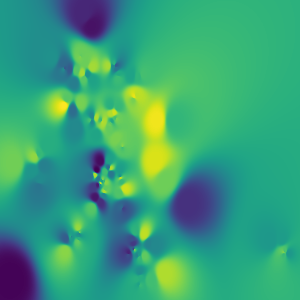
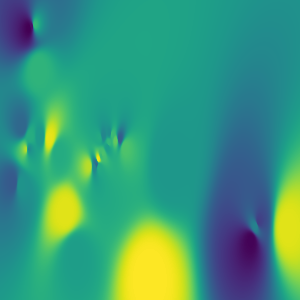
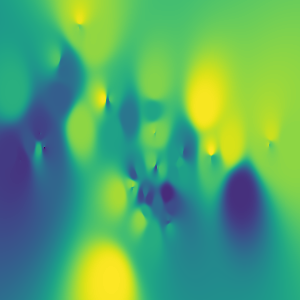
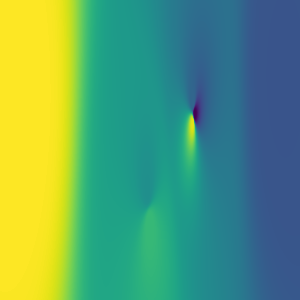
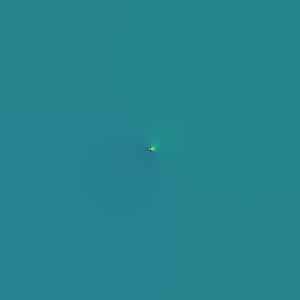
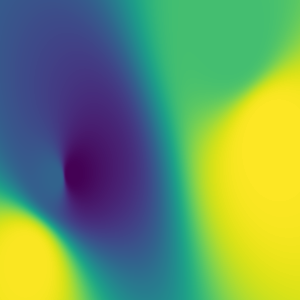
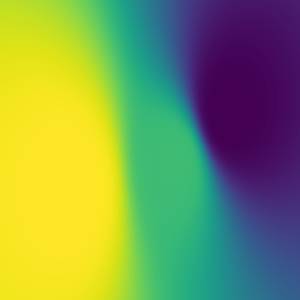
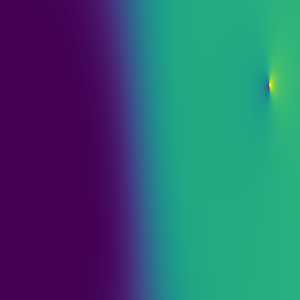

In [ ]:
# Full-dataset predicted weighted-average heatmap
IDW_POWER = 5
# The original run wrote this map to the method_comparison sub-folder; kept so later cells find it.
pred5_interp_df, pred5_map, pred5_loocv, pred5_paths = interpolate_clusters_heatmap(
    csv_path=FULL_GT_PRED_CSV,
    value_column="Weighted Average_Pred",
    interpolation_method="idw",
    method_params={"power": IDW_POWER},
    lat_col="Latitude",
    lon_col="Longitude",
    filename_col="Filename",
    cluster_col="Cluster",
    dataset_tag="pred_full",
    buffer_m=BUFFER_M,
    grid_res=GRID_RES,
    save_results=True,
    output_folder=HEATMAP_METHOD_COMPARISON_DIR,
    save_name=f"pred_full_weighted_average_idw_power{IDW_POWER}_heatmap",
    show_map=True,
    run_loocv_largest_cluster=False
)

The next cells restrict the merged table to images with coordinates, a cluster, and both a ground-truth and a predicted score (296 images), and compute the 2D correlation overall and per cluster. This per-cluster table uses the IDW power 2 surfaces. In the original notebook the cell referred to the power 1 variables, but its saved output equals the power 2 values exactly (compare the `Correlation_2D_Power_2` column of the power 1 and power 2 comparison at the end of this section), so the code was corrected to match the output. The second table adds the number of images per cluster. Correlation is least stable in small clusters; cluster 3, with 7 images, has the lowest value.

In [ ]:
# Keep only images with coordinates, a cluster, and both GT and predicted scores
valid_full_dataset_spatial_csv_path = FULL_GT_PRED_VALID_CSV

df = pd.read_csv(FULL_GT_PRED_CSV)

valid = df.dropna(
    subset=[
        "Latitude",
        "Longitude",
        "Cluster",
        "Weighted Average_GT",
        "Weighted Average_Pred"
    ]
).copy()

valid.to_csv(valid_full_dataset_spatial_csv_path, index=False)

print("Original rows:", len(df))
print("Rows with valid GT + pred:", len(valid))
print("Saved:", valid_full_dataset_spatial_csv_path)

Original rows: 361
Rows with valid GT + pred: 296
Saved: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters_valid_predictions_only.csv


In [ ]:
# 2D correlation between the GT and predicted heatmaps (IDW power 2), overall and per cluster
print("GT heatmap columns:")
print(gt2_interp_df.columns.tolist())

print("\nPred heatmap columns:")
print(pred2_interp_df.columns.tolist())

# find_interp_value_col() is defined in the method-comparison cell above
gt_val_col = find_interp_value_col(gt2_interp_df)
pred_val_col = find_interp_value_col(pred2_interp_df)

print("\nGT interpolated value column:", gt_val_col)
print("Pred interpolated value column:", pred_val_col)

# Merge heatmap grid cells
merge_cols = ["Latitude", "Longitude"]

if "Cluster" in gt2_interp_df.columns and "Cluster" in pred2_interp_df.columns:
    merge_cols.append("Cluster")

gt_grid = gt2_interp_df[merge_cols + [gt_val_col]].copy()
pred_grid = pred2_interp_df[merge_cols + [pred_val_col]].copy()

gt_grid = gt_grid.rename(columns={gt_val_col: "GT_Heatmap_Value"})
pred_grid = pred_grid.rename(columns={pred_val_col: "Pred_Heatmap_Value"})

heatmap_compare = gt_grid.merge(
    pred_grid,
    on=merge_cols,
    how="inner"
)

heatmap_compare["GT_Heatmap_Value"] = pd.to_numeric(
    heatmap_compare["GT_Heatmap_Value"],
    errors="coerce"
)

heatmap_compare["Pred_Heatmap_Value"] = pd.to_numeric(
    heatmap_compare["Pred_Heatmap_Value"],
    errors="coerce"
)

heatmap_compare = heatmap_compare.dropna(
    subset=["GT_Heatmap_Value", "Pred_Heatmap_Value"]
).copy()

print("\nOverlapping valid heatmap grid cells:", len(heatmap_compare))

# Overall 2D correlation
corr_2d = heatmap_compare["GT_Heatmap_Value"].corr(
    heatmap_compare["Pred_Heatmap_Value"]
)

print("\n====================================")
print("Overall 2D heatmap correlation:")
print(corr_2d)
print("====================================")

# Per-cluster 2D correlation
if "Cluster" in heatmap_compare.columns:
    cluster_corrs = []

    for cluster_id, cdf in heatmap_compare.groupby("Cluster"):
        if len(cdf) >= 2:
            c = cdf["GT_Heatmap_Value"].corr(cdf["Pred_Heatmap_Value"])
        else:
            c = np.nan

        cluster_corrs.append({
            "Cluster": cluster_id,
            "N_Grid_Cells": len(cdf),
            "Correlation_2D": c
        })

    cluster_corrs = pd.DataFrame(cluster_corrs).sort_values("Cluster")

    print("\nPer-cluster 2D correlations:")
    display(cluster_corrs)

GT heatmap columns:
['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']

Pred heatmap columns:
['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']

GT interpolated value column: Interpolated
Pred interpolated value column: Interpolated

Overlapping valid heatmap grid cells: 720000

Overall 2D heatmap correlation:
0.7517082840287105

Per-cluster 2D correlations:


,Cluster,N_Grid_Cells,Correlation_2D
0,0,90000,0.940301
1,1,90000,0.900280
2,2,90000,0.917639
3,3,90000,0.257160
4,4,90000,0.730372
5,5,90000,0.977288
6,6,90000,0.993375
7,7,90000,0.995061


In [ ]:
# Add original image count per cluster to 2D correlation table
points_df = pd.read_csv(FULL_GT_PRED_VALID_CSV)

point_counts = (
    points_df
    .dropna(subset=["Weighted Average_GT", "Weighted Average_Pred", "Cluster"])
    .groupby("Cluster")
    .size()
    .reset_index(name="N_Original_Image_Points")
)

cluster_corrs_with_points = cluster_corrs.merge(
    point_counts,
    on="Cluster",
    how="left"
)

display(cluster_corrs_with_points)

,Cluster,N_Grid_Cells,Correlation_2D,N_Original_Image_Points
0,0,90000,0.940301,145
1,1,90000,0.900280,40
2,2,90000,0.917639,71
3,3,90000,0.257160,7
4,4,90000,0.730372,16
5,5,90000,0.977288,5
6,6,90000,0.993375,3
7,7,90000,0.995061,3


For each DBSCAN cluster, the GT and predicted weighted-average damage surfaces were interpolated onto a fixed 300 × 300 grid. The 2D correlation was then computed between the two interpolated grids within each cluster.

As a sensitivity check, the LOOCV comparison of Section 6 is repeated on the predicted weighted averages of the 296 geotagged images rather than on the ground truth, to see whether the preferred interpolator changes when the input is the model output. The function was first written for the test set, so some of its labels (`test_set_gt_only`, `test_set_gt_spatial_with_clusters.csv`) are misleading here: the input is the full dataset and the value column is `Weighted Average_Pred`. DBSCAN is re-run with the same settings and reproduces the clusters of Section 5.

In [ ]:
# Test-set interpolation sensitivity check
# Uses existing loocv_interpolation() helper
# Checks:
#   1. IDW powers
#   2. Ordinary kriging variograms
#   3. Universal kriging variograms, optional
def test_set_interpolation_sensitivity_check_using_helper(
    merged_test_csv_path,
    output_folder,
    value_column="Weighted Average_GT",
    lat_col="Latitude_GT",
    lon_col="Longitude_GT",
    idw_powers=(0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10),
    kriging_variogram_models=("linear", "power", "spherical", "exponential", "gaussian"),
    include_ordinary_kriging=True,
    include_universal_kriging=False,
    universal_drift_terms=("regional_linear",),
    eps_meters=2000,
    min_samples=3,
    min_cluster_size=4,
    show_plot=True
):
    """
    Runs interpolation-method sensitivity check on geotagged test-set GT data.

    Uses the existing loocv_interpolation() helper.

    It evaluates:
    - IDW with multiple power values
    - ordinary kriging with multiple variogram models
    - optionally universal kriging with multiple variogram models

    Parameters
    ----------
    merged_test_csv_path : str
        Path to merged GT/pred test CSV.

    output_folder : str
        Folder where outputs are saved.

    value_column : str
        Ground-truth column to evaluate.
        Usually: "Weighted Average_GT"

    lat_col, lon_col : str
        Coordinate columns.
        Usually: "Latitude_GT", "Longitude_GT"

    idw_powers : iterable
        IDW power values to test.

    kriging_variogram_models : iterable
        PyKrige variogram models to test.

    include_ordinary_kriging : bool
        Whether to test OrdinaryKriging.

    include_universal_kriging : bool
        Whether to test UniversalKriging.

    universal_drift_terms : tuple/list
        Drift terms for UniversalKriging.

    eps_meters : float
        DBSCAN clustering radius.

    min_samples : int
        DBSCAN min_samples.

    min_cluster_size : int
        Minimum cluster size to evaluate.
        Kriging needs at least 4 points in a cluster so that after leaving one out,
        at least 3 training points remain.

    show_plot : bool
        Whether to display plots.

    Returns
    -------
    summary_df : pandas.DataFrame
        Overall method-level LOOCV summary.

    per_cluster_df : pandas.DataFrame
        Per-cluster LOOCV summary.

    predictions_df : pandas.DataFrame
        Point-level LOOCV predictions.

    df_spatial : pandas.DataFrame
        Geotagged test-set dataframe with DBSCAN clusters.
    """

    os.makedirs(output_folder, exist_ok=True)

    # 1. Load merged test CSV
    df = pd.read_csv(merged_test_csv_path)
    df.columns = df.columns.str.strip()

    print("Loaded merged test CSV:")
    print(merged_test_csv_path)
    print("Original shape:", df.shape)

    required_cols = [lat_col, lon_col, value_column]

    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}\n"
            f"Available columns: {list(df.columns)}"
        )

    # 2. Clean coordinates and values
    for col in required_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    before = len(df)

    df_spatial = df.dropna(subset=required_cols).copy()

    after = len(df_spatial)

    print("\nRows before spatial filtering:", before)
    print("Rows retained with valid GPS/value:", after)
    print("Rows dropped:", before - after)

    if len(df_spatial) == 0:
        raise ValueError("No geotagged test-set rows remain.")

    # 3. Add DBSCAN clusters to test set
    coords = df_spatial[[lat_col, lon_col]].values
    coords_rad = np.radians(coords)

    earth_radius_km = 6371.0088
    eps_rad = eps_meters / 1000.0 / earth_radius_km

    db = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine"
    )

    df_spatial["Cluster"] = db.fit_predict(coords_rad)

    print("\nTest-set cluster counts:")
    print(df_spatial["Cluster"].value_counts().sort_index())

    clustered_test_path = os.path.join(
        output_folder,
        "test_set_gt_spatial_with_clusters.csv"
    )

    df_spatial.to_csv(clustered_test_path, index=False)

    print("\nSaved clustered test-set spatial CSV:")
    print(clustered_test_path)

    # 4. Select non-noise clusters
    df_valid = df_spatial[df_spatial["Cluster"] != -1].copy()

    cluster_counts = df_valid["Cluster"].value_counts().sort_index()

    clusters_to_use = [
        int(cluster_id)
        for cluster_id, n in cluster_counts.items()
        if n >= min_cluster_size
    ]

    print(f"\nUsing clusters with at least {min_cluster_size} points:")
    print(clusters_to_use)

    if len(clusters_to_use) == 0:
        raise ValueError(
            "No test-set clusters have enough points for LOOCV. "
            "Try lowering min_cluster_size or changing DBSCAN parameters."
        )

    # 5. Build method configurations
    method_configs = []

    for power in idw_powers:
        method_configs.append({
            "Method": "idw",
            "Method_Label": f"IDW_power_{power}",
            "Parameter_Name": "power",
            "Parameter_Value": power,
            "Method_Params": {"power": power},
            "Min_Train_Points": 1
        })

    if include_ordinary_kriging:
        for variogram_model in kriging_variogram_models:
            method_configs.append({
                "Method": "ordinary_kriging",
                "Method_Label": f"OK_{variogram_model}",
                "Parameter_Name": "variogram_model",
                "Parameter_Value": variogram_model,
                "Method_Params": {"variogram_model": variogram_model},
                "Min_Train_Points": 3
            })

    if include_universal_kriging:
        drift_terms = list(universal_drift_terms)

        for variogram_model in kriging_variogram_models:
            method_configs.append({
                "Method": "universal_kriging",
                "Method_Label": f"UK_{variogram_model}",
                "Parameter_Name": "variogram_model",
                "Parameter_Value": variogram_model,
                "Method_Params": {
                    "variogram_model": variogram_model,
                    "drift_terms": drift_terms
                },
                "Min_Train_Points": 3
            })

    # 6. Run LOOCV using helper
    per_cluster_rows = []
    prediction_tables = []

    for config in method_configs:

        method = config["Method"]
        method_label = config["Method_Label"]
        method_params = config["Method_Params"]
        min_train_points = config["Min_Train_Points"]

        print(f"\nEvaluating: {method_label}")

        for cluster_id in clusters_to_use:

            cluster_df = df_valid[df_valid["Cluster"] == cluster_id].copy()

            if len(cluster_df) <= min_train_points:
                continue

            try:
                mae, rmse, pred_df = loocv_interpolation(
                    df_cluster=cluster_df,
                    value_column=value_column,
                    method=method,
                    method_params=method_params,
                    lat_col=lat_col,
                    lon_col=lon_col,
                    return_predictions=True,
                    min_train_points=min_train_points
                )

                valid_pred = pred_df.dropna(
                    subset=["True_Value", "Predicted_Value", "Error"]
                ).copy()

                if len(valid_pred) == 0:
                    raise ValueError("No valid LOOCV predictions.")

                errors = valid_pred["Error"].values
                abs_errors = valid_pred["Absolute_Error"].values

                per_cluster_rows.append({
                    "Dataset": "test_set_gt_only",
                    "Value_Column": value_column,
                    "Method": method,
                    "Method_Label": method_label,
                    "Parameter_Name": config["Parameter_Name"],
                    "Parameter_Value": config["Parameter_Value"],
                    "Method_Params": str(method_params),
                    "Cluster": cluster_id,
                    "N_LOOCV": len(valid_pred),
                    "MAE": float(np.mean(abs_errors)),
                    "RMSE": float(np.sqrt(np.mean(errors ** 2))),
                    "Bias": float(np.mean(errors)),
                    "Median_Absolute_Error": float(np.median(abs_errors)),
                    "Max_Absolute_Error": float(np.max(abs_errors))
                })

                pred_df["Method"] = method
                pred_df["Method_Label"] = method_label
                pred_df["Parameter_Name"] = config["Parameter_Name"]
                pred_df["Parameter_Value"] = config["Parameter_Value"]
                pred_df["Method_Params"] = str(method_params)
                pred_df["Cluster"] = cluster_id

                # Preserve useful identifiers if present
                if "Filename_GT" in cluster_df.columns:
                    filename_map = cluster_df["Filename_GT"].to_dict()
                    pred_df["Filename_GT"] = pred_df["Index"].map(filename_map)

                if "Mode_GT" in cluster_df.columns:
                    mode_map = cluster_df["Mode_GT"].to_dict()
                    pred_df["Mode_GT"] = pred_df["Index"].map(mode_map)

                prediction_tables.append(pred_df)

            except Exception as e:
                print(
                    f"⚠️ Failed for {method_label}, cluster {cluster_id}: "
                    f"{type(e).__name__}: {e}"
                )

                per_cluster_rows.append({
                    "Dataset": "test_set_gt_only",
                    "Value_Column": value_column,
                    "Method": method,
                    "Method_Label": method_label,
                    "Parameter_Name": config["Parameter_Name"],
                    "Parameter_Value": config["Parameter_Value"],
                    "Method_Params": str(method_params),
                    "Cluster": cluster_id,
                    "N_LOOCV": 0,
                    "MAE": np.nan,
                    "RMSE": np.nan,
                    "Bias": np.nan,
                    "Median_Absolute_Error": np.nan,
                    "Max_Absolute_Error": np.nan,
                    "Error_Message": f"{type(e).__name__}: {e}"
                })

    per_cluster_df = pd.DataFrame(per_cluster_rows)

    if len(prediction_tables) == 0:
        raise ValueError("No successful LOOCV predictions were produced.")

    predictions_df = pd.concat(prediction_tables, ignore_index=True)

    valid_all = predictions_df.dropna(
        subset=["True_Value", "Predicted_Value", "Error"]
    ).copy()

    if valid_all.empty:
        raise ValueError("All LOOCV predictions failed.")

    # 7. Overall summary by method
    summary_rows = []

    group_cols = [
        "Method",
        "Method_Label",
        "Parameter_Name",
        "Parameter_Value",
        "Method_Params"
    ]

    for keys, group in valid_all.groupby(group_cols):

        method, method_label, param_name, param_value, method_params_text = keys

        errors = group["Error"].values
        abs_errors = group["Absolute_Error"].values

        summary_rows.append({
            "Dataset": "test_set_gt_only",
            "Value_Column": value_column,
            "Method": method,
            "Method_Label": method_label,
            "Parameter_Name": param_name,
            "Parameter_Value": param_value,
            "Method_Params": method_params_text,
            "N_LOOCV": len(group),
            "MAE": float(np.mean(abs_errors)),
            "RMSE": float(np.sqrt(np.mean(errors ** 2))),
            "Bias": float(np.mean(errors)),
            "Median_Absolute_Error": float(np.median(abs_errors)),
            "Max_Absolute_Error": float(np.max(abs_errors)),
            "Clusters_Used": sorted(group["Cluster"].dropna().astype(int).unique().tolist())
        })

    summary_df = pd.DataFrame(summary_rows)

    summary_df = summary_df.sort_values(
        by=["MAE", "RMSE"],
        ascending=[True, True]
    ).reset_index(drop=True)

    print("\nTest-set interpolation sensitivity summary:")
    display(summary_df)

    print("\nBest method by test-set LOOCV MAE:")
    display(summary_df.head(1))

    # 8. Save tables
    summary_path = os.path.join(
        output_folder,
        "test_set_interpolation_sensitivity_summary.csv"
    )

    per_cluster_path = os.path.join(
        output_folder,
        "test_set_interpolation_sensitivity_per_cluster.csv"
    )

    predictions_path = os.path.join(
        output_folder,
        "test_set_interpolation_sensitivity_predictions.csv"
    )

    summary_df.to_csv(summary_path, index=False)
    per_cluster_df.to_csv(per_cluster_path, index=False)
    predictions_df.to_csv(predictions_path, index=False)

    print("\nSaved:")
    print(summary_path)
    print(per_cluster_path)
    print(predictions_path)

    # 9. Plot IDW MAE/RMSE vs power
    idw_summary = summary_df[summary_df["Method"] == "idw"].copy()

    if not idw_summary.empty:

        idw_summary["Parameter_Value"] = pd.to_numeric(
            idw_summary["Parameter_Value"],
            errors="coerce"
        )

        idw_summary = idw_summary.sort_values("Parameter_Value")

        best_idw = idw_summary.sort_values(["MAE", "RMSE"]).iloc[0]

        plt.figure(figsize=(10, 6))

        plt.plot(
            idw_summary["Parameter_Value"],
            idw_summary["MAE"],
            marker="o",
            label="IDW MAE"
        )

        plt.plot(
            idw_summary["Parameter_Value"],
            idw_summary["RMSE"],
            marker="s",
            label="IDW RMSE"
        )

        plt.axvline(
            best_idw["Parameter_Value"],
            linestyle="--",
            label=f"Best test-set IDW power = {best_idw['Parameter_Value']}"
        )

        plt.axvline(
            1,
            linestyle=":",
            label="Full-GT selected power = 1"
        )

        plt.xlabel("IDW Power Parameter")
        plt.ylabel("LOOCV Error")
        plt.title(f"Test-Set GT IDW Sensitivity | {value_column}")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()

        idw_plot_path = os.path.join(
            output_folder,
            "test_set_idw_power_sensitivity_plot.png"
        )

        plt.savefig(idw_plot_path, dpi=300)

        print("Saved IDW plot:")
        print(idw_plot_path)

        if show_plot:
            plt.show()
        else:
            plt.close()

    # 10. Plot all methods MAE comparison
    plot_methods = summary_df.sort_values("MAE").copy()

    plt.figure(figsize=(12, max(5, 0.35 * len(plot_methods))))

    plt.barh(
        plot_methods["Method_Label"],
        plot_methods["MAE"]
    )

    plt.xlabel("LOOCV MAE")
    plt.ylabel("Interpolation method")
    plt.title(f"Test-Set GT LOOCV MAE by Method | {value_column}")
    plt.gca().invert_yaxis()
    plt.grid(True, axis="x", alpha=0.3)
    plt.tight_layout()

    all_methods_plot_path = os.path.join(
        output_folder,
        "test_set_all_methods_mae_comparison.png"
    )

    plt.savefig(all_methods_plot_path, dpi=300)

    print("Saved all-methods MAE plot:")
    print(all_methods_plot_path)

    if show_plot:
        plt.show()
    else:
        plt.close()

    return summary_df, per_cluster_df, predictions_df, df_spatial

Loaded merged test CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_predictions/full_dataset_gt_pred_image_level_scores_with_gps_clusters_valid_predictions_only.csv
Original shape: (296, 49)

Rows before spatial filtering: 296
Rows retained with valid GPS/value: 296
Rows dropped: 0

Test-set cluster counts:
Cluster
-1      6
 0    145
 1     40
 2     71
 3      7
 4     16
 5      5
 6      3
 7      3
Name: count, dtype: int64

Saved clustered test-set spatial CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/sensitivity_check_full_pred/test_set_gt_spatial_with_clusters.csv

Using clusters with at least 4 points:
[0, 1, 2, 3, 4, 5]

Evaluating: IDW_power_0.5

Evaluating: IDW_power_1

Evaluating: IDW_power_1.5

Evaluating: IDW_power_2

Evaluating: IDW_power_2.5

Evaluating: IDW_power_3

Evaluating: IDW_power_4

Evaluating: IDW_power_5

Evaluating: IDW_power_6

Evaluating: IDW_power_8

Evaluating: IDW_power_10

Eval

,Dataset,Value_Column,Method,Method_Label,Parameter_Name,Parameter_Value,Method_Params,N_LOOCV,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Clusters_Used
0,test_set_gt_only,Weighted Average_Pred,ordinary_kriging,OK_spherical,variogram_model,spherical,{'variogram_model': 'spherical'},284,0.749563,0.938239,-0.013598,0.657036,2.854341,"[0, 1, 2, 3, 4, 5]"
1,test_set_gt_only,Weighted Average_Pred,idw,IDW_power_1.5,power,1.5,{'power': 1.5},284,0.765632,0.970146,-0.012158,0.652381,2.889938,"[0, 1, 2, 3, 4, 5]"
2,test_set_gt_only,Weighted Average_Pred,idw,IDW_power_1,power,1,{'power': 1},284,0.769428,0.969768,-0.006719,0.657036,2.880632,"[0, 1, 2, 3, 4, 5]"
3,test_set_gt_only,Weighted Average_Pred,idw,IDW_power_2,power,2,{'power': 2},284,0.770067,0.982378,-0.018429,0.626532,2.972509,"[0, 1, 2, 3, 4, 5]"
4,test_set_gt_only,Weighted Average_Pred,idw,IDW_power_2.5,power,2.5,{'power': 2.5},284,0.779088,0.994980,-0.022414,0.631413,3.125843,"[0, 1, 2, 3, 4, 5]"
5,test_set_gt_only,Weighted Average_Pred,idw,IDW_power_3,power,3,{'power': 3},284,0.787488,1.007921,-0.024300,0.637509,3.318475,"[0, 1, 2, 3, 4, 5]"
6,test_set_gt_only,Weighted Average_Pred,ordinary_kriging,OK_exponential,variogram_model,exponential,{'variogram_model': 'exponential'},284,0.794107,0.982789,-0.039298,0.677344,3.074281,"[0, 1, 2, 3, 4, 5]"
7,test_set_gt_only,Weighted Average_Pred,ordinary_kriging,OK_gaussian,variogram_model,gaussian,{'variogram_model': 'gaussian'},284,0.797929,0.986571,-0.024789,0.687014,2.867506,"[0, 1, 2, 3, 4, 5]"
8,test_set_gt_only,Weighted Average_Pred,idw,IDW_power_4,power,4,{'power': 4},284,0.803035,1.034706,-0.025378,0.654223,3.696756,"[0, 1, 2, 3, 4, 5]"
9,test_set_gt_only,Weighted Average_Pred,idw,IDW_power_0.5,power,0.5,{'power': 0.5},284,0.813882,1.004338,0.002794,0.713533,2.904805,"[0, 1, 2, 3, 4, 5]"



Best method by test-set LOOCV MAE:


,Dataset,Value_Column,Method,Method_Label,Parameter_Name,Parameter_Value,Method_Params,N_LOOCV,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Clusters_Used
0,test_set_gt_only,Weighted Average_Pred,ordinary_kriging,OK_spherical,variogram_model,spherical,{'variogram_model': 'spherical'},284,0.749563,0.938239,-0.013598,0.657036,2.854341,"[0, 1, 2, 3, 4, 5]"



Saved:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/sensitivity_check_full_pred/test_set_interpolation_sensitivity_summary.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/sensitivity_check_full_pred/test_set_interpolation_sensitivity_per_cluster.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/sensitivity_check_full_pred/test_set_interpolation_sensitivity_predictions.csv
Saved IDW plot:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/sensitivity_check_full_pred/test_set_idw_power_sensitivity_plot.png


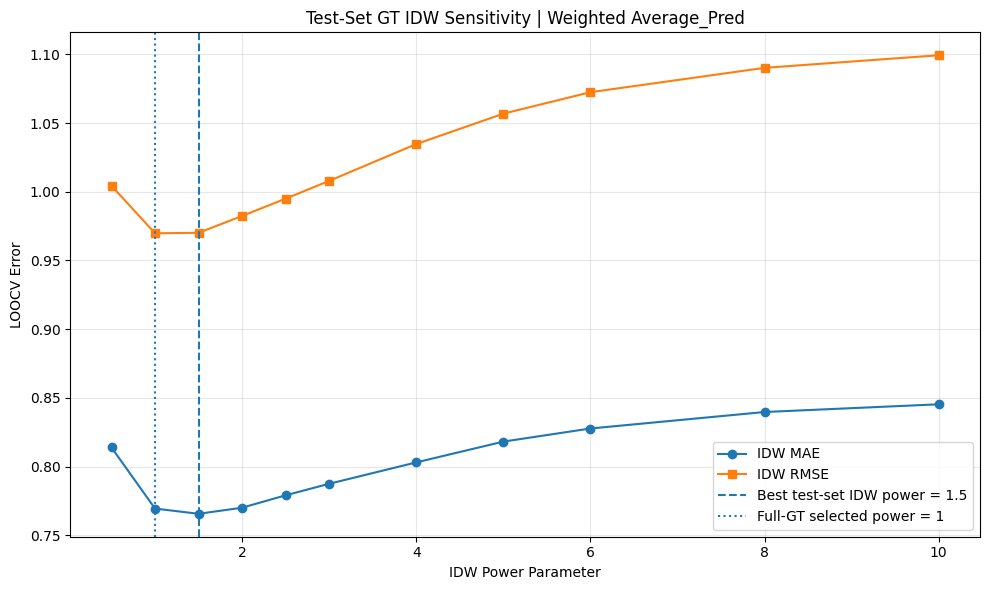

Saved all-methods MAE plot:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/sensitivity_check_full_pred/test_set_all_methods_mae_comparison.png


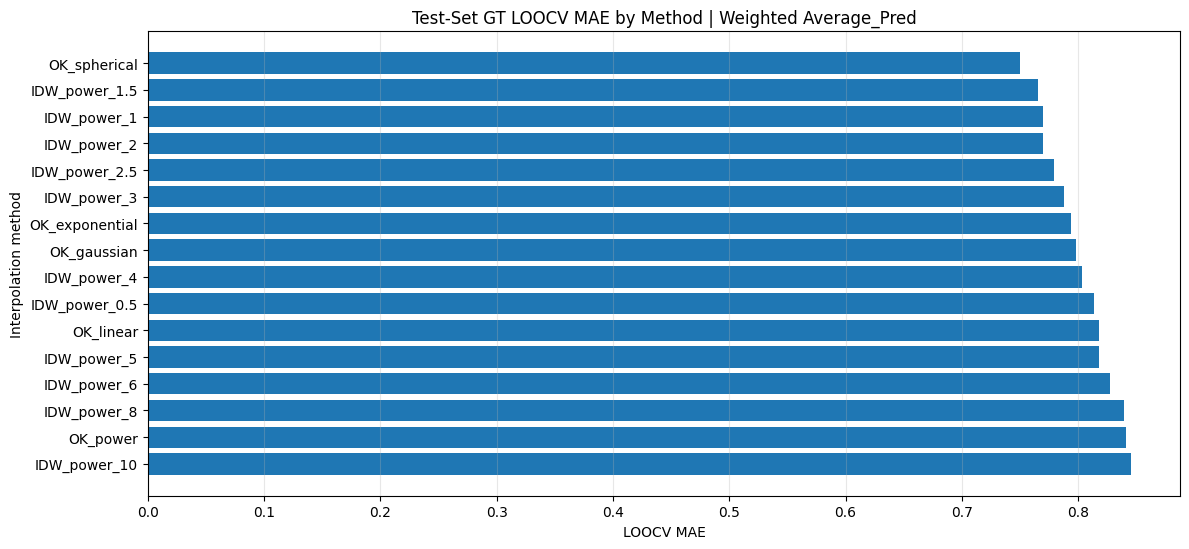

In [ ]:
summary_pred_df, per_cluster_pred_df, predictions_pred_df, df_spatial_pred = test_set_interpolation_sensitivity_check_using_helper(
    merged_test_csv_path=FULL_GT_PRED_VALID_CSV,
    output_folder=SENSITIVITY_DIR,
    value_column="Weighted Average_Pred",
    lat_col="Latitude",
    lon_col="Longitude",
    idw_powers=(0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10),
    include_ordinary_kriging=True,
    include_universal_kriging=False,
    eps_meters=DBSCAN_EPS_M,
    min_samples=DBSCAN_MIN_SAMPLES,
    min_cluster_size=4,
    show_plot=True
)

On the predicted weighted averages the ranking resembles that of Section 6: ordinary kriging with a spherical variogram had the lowest LOOCV MAE (0.750), followed by IDW powers 1.5 (0.766), 1 (0.769) and 2 (0.770), and the error grew for higher powers (0.818 at IDW power 5). LOOCV therefore favours low powers on both ground-truth and predicted scores. The manuscript nevertheless uses IDW power 5, because the two criteria measure different things: LOOCV measures how accurately an interpolation method reconstructs held-out observation points, whereas 2D correlation measures how similarly the predicted and ground-truth heatmaps reproduce spatial damage patterns. For USAR-oriented damage mapping the second criterion, and the preservation of local heterogeneity, was given precedence.

As a supplementary comparison of the two low powers, the saved power 1 and power 2 heatmaps are read back from disk and compared in more detail: overall and per-cluster MAE, RMSE, bias, relative error, 2D correlation and over- and underestimation rates, plus a table of the change from power 1 to power 2. `find_heatmap_csv` locates the heatmap files by name, and `compare_interpolated_heatmaps` is used again in Section 9.

In [ ]:
# Full-dataset GT vs predicted heatmaps, IDW power 1 and power 2, read back from disk

# 1. Paths
heatmap_output_folder = HEATMAP_DIR
comparison_output_folder = HEATMAP_COMPARISON_DIR

os.makedirs(comparison_output_folder, exist_ok=True)

print("Heatmap folder:")
print(heatmap_output_folder)
print("Exists:", os.path.exists(heatmap_output_folder))

if not os.path.exists(heatmap_output_folder):
    raise FileNotFoundError(
        f"Heatmap folder does not exist:\n{heatmap_output_folder}"
    )

# 2. Helper: find the saved heatmap CSV
def find_heatmap_csv(dataset_type, power):
    """
    Finds the saved heatmap CSV for:
        dataset_type = 'gt' or 'pred'
        power = 1 or 2

    It searches for files containing:
        gt_full_weighted_average_idw_power1_heatmap
        pred_full_weighted_average_idw_power1_heatmap
        etc.

    It avoids comparison/metrics/per-cluster files.
    """

    expected_core = f"{dataset_type}_full_weighted_average_idw_power{power}_heatmap"

    all_csvs = glob.glob(
        os.path.join(heatmap_output_folder, "**", "*.csv"),
        recursive=True
    )

    candidates = []

    for path in all_csvs:
        filename = os.path.basename(path).lower()
        fullpath = path.lower()

        if expected_core.lower() not in filename:
            continue

        # Avoid files that are clearly comparison or metric outputs
        bad_words = [
            "comparison",
            "metrics",
            "per_cluster",
            "difference",
            "overall"
        ]

        if any(bad in filename for bad in bad_words):
            continue

        try:
            head = pd.read_csv(path, nrows=3)
            cols = [c.strip() for c in head.columns]

            has_latlon = "Latitude" in cols and "Longitude" in cols
            has_cluster = "Cluster" in cols
            has_interp = (
                "Interpolated" in cols or
                "Interpolated_Value" in cols or
                "Value" in cols or
                any("interpolated" in c.lower() for c in cols)
            )

            score = int(has_latlon) + int(has_cluster) + int(has_interp)

            candidates.append({
                "path": path,
                "filename": os.path.basename(path),
                "score": score,
                "columns": cols
            })

        except Exception:
            continue

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No heatmap CSV found for {dataset_type.upper()} power {power}.\n"
            f"Expected filename to contain:\n{expected_core}\n\n"
            f"Available CSV files in heatmap folder:\n" +
            "\n".join([os.path.basename(f) for f in all_csvs])
        )

    candidates_df = pd.DataFrame(candidates).sort_values(
        by="score",
        ascending=False
    )

    best_path = candidates_df.iloc[0]["path"]

    print(f"\nSelected {dataset_type.upper()} power {power} heatmap CSV:")
    print(best_path)
    print("Columns:")
    print(candidates_df.iloc[0]["columns"])

    return best_path


# 3. Flexible heatmap comparison function
def compare_interpolated_heatmaps(
    gt_interp_csv_path,
    pred_interp_csv_path,
    output_folder,
    save_name
):
    os.makedirs(output_folder, exist_ok=True)

    gt_df = pd.read_csv(gt_interp_csv_path)
    pred_df = pd.read_csv(pred_interp_csv_path)

    gt_df.columns = gt_df.columns.str.strip()
    pred_df.columns = pred_df.columns.str.strip()

    def find_interp_col(df, name):
        possible_cols = [
            "Interpolated",
            "Interpolated_Value",
            "Value",
            "Heatmap_Value",
            "Weighted Average",
            "Weighted Average_GT",
            "Weighted Average_Pred"
        ]

        for col in possible_cols:
            if col in df.columns:
                return col

        for col in df.columns:
            if "interpolated" in col.lower() or "heatmap" in col.lower():
                return col

        raise ValueError(
            f"Could not find interpolated value column in {name} CSV.\n"
            f"Available columns: {df.columns.tolist()}"
        )

    gt_interp_col = find_interp_col(gt_df, "GT")
    pred_interp_col = find_interp_col(pred_df, "Pred")

    print("\nGT interpolated column:", gt_interp_col)
    print("Pred interpolated column:", pred_interp_col)

    required_cols = ["Latitude", "Longitude", "Cluster"]

    for name, df in [("GT", gt_df), ("Pred", pred_df)]:
        missing = [c for c in required_cols if c not in df.columns]
        if missing:
            raise ValueError(
                f"{name} CSV missing columns: {missing}\n"
                f"Available columns: {df.columns.tolist()}"
            )

    gt_small = gt_df[["Latitude", "Longitude", "Cluster", gt_interp_col]].copy()
    pred_small = pred_df[["Latitude", "Longitude", "Cluster", pred_interp_col]].copy()

    gt_small = gt_small.rename(columns={gt_interp_col: "GT_Interpolated"})
    pred_small = pred_small.rename(columns={pred_interp_col: "Pred_Interpolated"})

    for df in [gt_small, pred_small]:
        df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
        df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")
        df["Cluster"] = pd.to_numeric(df["Cluster"], errors="coerce")

    gt_small["GT_Interpolated"] = pd.to_numeric(
        gt_small["GT_Interpolated"],
        errors="coerce"
    )

    pred_small["Pred_Interpolated"] = pd.to_numeric(
        pred_small["Pred_Interpolated"],
        errors="coerce"
    )

    gt_small = gt_small.dropna(
        subset=["Latitude", "Longitude", "Cluster", "GT_Interpolated"]
    ).copy()

    pred_small = pred_small.dropna(
        subset=["Latitude", "Longitude", "Cluster", "Pred_Interpolated"]
    ).copy()

    # Match grid cells on rounded coordinates
    gt_small["Latitude_round"] = gt_small["Latitude"].round(10)
    gt_small["Longitude_round"] = gt_small["Longitude"].round(10)

    pred_small["Latitude_round"] = pred_small["Latitude"].round(10)
    pred_small["Longitude_round"] = pred_small["Longitude"].round(10)

    comparison_df = gt_small.merge(
        pred_small,
        on=["Latitude_round", "Longitude_round", "Cluster"],
        suffixes=("_GTgrid", "_Predgrid"),
        how="inner"
    )

    if comparison_df.empty:
        raise ValueError(
            "GT and predicted grids did not align.\n"
            "Make sure both were created with the same input CSV, buffer_m, grid_res, and clusters."
        )

    comparison_df["Latitude"] = comparison_df["Latitude_GTgrid"]
    comparison_df["Longitude"] = comparison_df["Longitude_GTgrid"]

    comparison_df["Raw_Error"] = (
        comparison_df["Pred_Interpolated"] -
        comparison_df["GT_Interpolated"]
    )

    comparison_df["Absolute_Error"] = comparison_df["Raw_Error"].abs()
    comparison_df["Squared_Error"] = comparison_df["Raw_Error"] ** 2

    comparison_df["Relative_Error"] = np.where(
        comparison_df["GT_Interpolated"].abs() > 1e-10,
        comparison_df["Raw_Error"] / comparison_df["GT_Interpolated"],
        np.nan
    )

    comparison_df["Relative_Absolute_Error"] = comparison_df["Relative_Error"].abs()

    valid = comparison_df.dropna(
        subset=["GT_Interpolated", "Pred_Interpolated", "Raw_Error"]
    ).copy()

    metrics = {
        "Comparison": save_name,
        "N_Grid_Cells": len(valid),
        "MAE": valid["Absolute_Error"].mean(),
        "RMSE": np.sqrt(valid["Squared_Error"].mean()),
        "Bias": valid["Raw_Error"].mean(),
        "Median_Absolute_Error": valid["Absolute_Error"].median(),
        "Max_Absolute_Error": valid["Absolute_Error"].max(),
        "Correlation_2D": valid["GT_Interpolated"].corr(valid["Pred_Interpolated"]),
        "Mean_Absolute_Relative_Error": valid["Relative_Absolute_Error"].mean(),
        "Mean_Relative_Bias": valid["Relative_Error"].mean(),
        "Overestimate_Rate": (valid["Raw_Error"] > 0).mean(),
        "Underestimate_Rate": (valid["Raw_Error"] < 0).mean(),
        "Exact_Rate": (valid["Raw_Error"] == 0).mean()
    }

    metrics_df = pd.DataFrame([metrics])

    per_cluster_rows = []

    for cluster_id, group in valid.groupby("Cluster"):
        per_cluster_rows.append({
            "Comparison": save_name,
            "Cluster": int(cluster_id),
            "N_Grid_Cells": len(group),
            "MAE": group["Absolute_Error"].mean(),
            "RMSE": np.sqrt(group["Squared_Error"].mean()),
            "Bias": group["Raw_Error"].mean(),
            "Median_Absolute_Error": group["Absolute_Error"].median(),
            "Max_Absolute_Error": group["Absolute_Error"].max(),
            "Correlation_2D": group["GT_Interpolated"].corr(group["Pred_Interpolated"]),
            "Mean_Absolute_Relative_Error": group["Relative_Absolute_Error"].mean(),
            "Mean_Relative_Bias": group["Relative_Error"].mean(),
            "Overestimate_Rate": (group["Raw_Error"] > 0).mean(),
            "Underestimate_Rate": (group["Raw_Error"] < 0).mean(),
            "Exact_Rate": (group["Raw_Error"] == 0).mean()
        })

    per_cluster_metrics_df = pd.DataFrame(per_cluster_rows)

    comparison_path = os.path.join(
        output_folder,
        f"{save_name}_grid_comparison.csv"
    )

    metrics_path = os.path.join(
        output_folder,
        f"{save_name}_metrics.csv"
    )

    per_cluster_path = os.path.join(
        output_folder,
        f"{save_name}_per_cluster_metrics.csv"
    )

    comparison_df.to_csv(comparison_path, index=False)
    metrics_df.to_csv(metrics_path, index=False)
    per_cluster_metrics_df.to_csv(per_cluster_path, index=False)

    print("\nSaved:")
    print(comparison_path)
    print(metrics_path)
    print(per_cluster_path)

    return comparison_df, metrics_df, per_cluster_metrics_df


# 4. Run comparison for power 1 and power 2 if available
all_metrics = []
all_per_cluster_metrics = []
comparison_results = {}

for power in [1, 2]:

    print("\n" + "=" * 90)
    print(f"Comparing FULL-DATASET GT vs predicted heatmaps | IDW power = {power}")
    print("=" * 90)

    try:
        gt_csv = find_heatmap_csv("gt", power)
        pred_csv = find_heatmap_csv("pred", power)

        save_name = f"full_weighted_average_idw_power{power}_gt_vs_pred"

        comparison_df, metrics_df, per_cluster_metrics_df = compare_interpolated_heatmaps(
            gt_interp_csv_path=gt_csv,
            pred_interp_csv_path=pred_csv,
            output_folder=comparison_output_folder,
            save_name=save_name
        )

        metrics_df["Power"] = power
        per_cluster_metrics_df["Power"] = power

        all_metrics.append(metrics_df)
        all_per_cluster_metrics.append(per_cluster_metrics_df)
        comparison_results[power] = comparison_df

    except FileNotFoundError as e:
        print(f"\nSkipping power {power}:")
        print(e)

if len(all_metrics) == 0:
    raise FileNotFoundError(
        "No GT/pred heatmap pairs were found for power 1 or power 2."
    )

combined_metrics_df = pd.concat(all_metrics, ignore_index=True)
combined_per_cluster_metrics_df = pd.concat(all_per_cluster_metrics, ignore_index=True)

# 5. Save combined metrics
combined_metrics_path = os.path.join(
    comparison_output_folder,
    "full_gt_vs_pred_heatmap_power1_power2_combined_metrics.csv"
)

combined_per_cluster_path = os.path.join(
    comparison_output_folder,
    "full_gt_vs_pred_heatmap_power1_power2_combined_per_cluster_metrics.csv"
)

combined_metrics_df.to_csv(combined_metrics_path, index=False)
combined_per_cluster_metrics_df.to_csv(combined_per_cluster_path, index=False)

print("\nCombined overall metrics:")
display(combined_metrics_df)

print("\nCombined per-cluster metrics:")
display(combined_per_cluster_metrics_df)

print("\nSaved combined metrics:")
print(combined_metrics_path)
print(combined_per_cluster_path)

# 6. Create clean overall comparison table
overall_cols = [
    "Power",
    "Comparison",
    "N_Grid_Cells",
    "MAE",
    "RMSE",
    "Bias",
    "Median_Absolute_Error",
    "Max_Absolute_Error",
    "Correlation_2D",
    "Mean_Absolute_Relative_Error",
    "Mean_Relative_Bias",
    "Overestimate_Rate",
    "Underestimate_Rate",
    "Exact_Rate"
]

overall_cols = [c for c in overall_cols if c in combined_metrics_df.columns]

overall_table = (
    combined_metrics_df[overall_cols]
    .sort_values("Power")
    .reset_index(drop=True)
)

overall_table_path = os.path.join(
    comparison_output_folder,
    "full_gt_vs_pred_heatmap_overall_comparison_table.csv"
)

overall_table.to_csv(overall_table_path, index=False)

print("\nClean overall comparison table:")
display(overall_table)

print("Saved:")
print(overall_table_path)

# 7. Difference table: power 2 minus power 1
available_powers = set(overall_table["Power"].astype(float))

if {1.0, 2.0}.issubset(available_powers):

    metric_cols = [
        "MAE",
        "RMSE",
        "Bias",
        "Median_Absolute_Error",
        "Max_Absolute_Error",
        "Correlation_2D",
        "Mean_Absolute_Relative_Error",
        "Mean_Relative_Bias",
        "Overestimate_Rate",
        "Underestimate_Rate",
        "Exact_Rate"
    ]

    metric_cols = [c for c in metric_cols if c in overall_table.columns]

    power1 = overall_table[overall_table["Power"].astype(float) == 1].iloc[0]
    power2 = overall_table[overall_table["Power"].astype(float) == 2].iloc[0]

    difference_rows = []

    for metric in metric_cols:
        val1 = power1[metric]
        val2 = power2[metric]

        abs_change = val2 - val1

        if pd.notna(val1) and not np.isclose(val1, 0):
            percent_change = 100 * abs_change / val1
        else:
            percent_change = np.nan

        if metric == "Correlation_2D":
            better_power = 2 if val2 > val1 else 1
        elif metric in ["Bias", "Mean_Relative_Bias"]:
            better_power = 2 if abs(val2) < abs(val1) else 1
        else:
            better_power = 2 if val2 < val1 else 1

        difference_rows.append({
            "Metric": metric,
            "Power_1": val1,
            "Power_2": val2,
            "Power_2_minus_Power_1": abs_change,
            "Percent_Change_from_Power_1": percent_change,
            "Better_Power": better_power
        })

    difference_table = pd.DataFrame(difference_rows)

    difference_table_path = os.path.join(
        comparison_output_folder,
        "full_gt_vs_pred_heatmap_power2_minus_power1_difference_table.csv"
    )

    difference_table.to_csv(difference_table_path, index=False)

    print("\nDifference table: power 2 minus power 1")
    display(difference_table)

    print("Saved:")
    print(difference_table_path)

else:
    print("\nOnly one power was available, so no power 2 minus power 1 table was created.")
    difference_table = pd.DataFrame()

# 8. Per-cluster clean and wide tables
per_cluster_cols = [
    "Power",
    "Comparison",
    "Cluster",
    "N_Grid_Cells",
    "MAE",
    "RMSE",
    "Bias",
    "Median_Absolute_Error",
    "Max_Absolute_Error",
    "Correlation_2D",
    "Mean_Absolute_Relative_Error",
    "Mean_Relative_Bias",
    "Overestimate_Rate",
    "Underestimate_Rate",
    "Exact_Rate"
]

per_cluster_cols = [
    c for c in per_cluster_cols
    if c in combined_per_cluster_metrics_df.columns
]

per_cluster_table = (
    combined_per_cluster_metrics_df[per_cluster_cols]
    .sort_values(["Cluster", "Power"])
    .reset_index(drop=True)
)

per_cluster_table_path = os.path.join(
    comparison_output_folder,
    "full_gt_vs_pred_heatmap_per_cluster_comparison_table.csv"
)

per_cluster_table.to_csv(per_cluster_table_path, index=False)

print("\nPer-cluster comparison table:")
display(per_cluster_table)

print("Saved:")
print(per_cluster_table_path)

wide_metric_cols = [
    "MAE",
    "RMSE",
    "Bias",
    "Correlation_2D",
    "Mean_Absolute_Relative_Error",
    "Mean_Relative_Bias",
    "Overestimate_Rate",
    "Underestimate_Rate"
]

wide_metric_cols = [
    c for c in wide_metric_cols
    if c in per_cluster_table.columns
]

per_cluster_wide = per_cluster_table.pivot_table(
    index="Cluster",
    columns="Power",
    values=wide_metric_cols,
    aggfunc="first"
)

per_cluster_wide.columns = [
    f"{metric}_Power_{power}"
    for metric, power in per_cluster_wide.columns
]

per_cluster_wide = per_cluster_wide.reset_index()

for metric in wide_metric_cols:
    col1 = f"{metric}_Power_1"
    col2 = f"{metric}_Power_2"

    if col1 in per_cluster_wide.columns and col2 in per_cluster_wide.columns:
        per_cluster_wide[f"{metric}_Power_2_minus_Power_1"] = (
            per_cluster_wide[col2] - per_cluster_wide[col1]
        )

per_cluster_wide_path = os.path.join(
    comparison_output_folder,
    "full_gt_vs_pred_heatmap_per_cluster_wide_table.csv"
)

per_cluster_wide.to_csv(per_cluster_wide_path, index=False)

print("\nPer-cluster wide table:")
display(per_cluster_wide)

print("Saved:")
print(per_cluster_wide_path)

# 9. Print main result clearly
print("\n" + "=" * 90)
print("MAIN FULL-DATASET HEATMAP RESULTS")
print("=" * 90)

for _, row in overall_table.iterrows():
    print(f"\nIDW power {int(row['Power'])}:")
    print(f"  N grid cells:     {row['N_Grid_Cells']}")
    print(f"  Correlation_2D:   {row['Correlation_2D']:.6f}")
    print(f"  MAE:              {row['MAE']:.6f}")
    print(f"  RMSE:             {row['RMSE']:.6f}")
    print(f"  Bias:             {row['Bias']:.6f}")

print("\nDone.")

Heatmap folder:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps
Exists: True

Comparing FULL-DATASET GT vs predicted heatmaps | IDW power = 1

Selected GT power 1 heatmap CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power1_heatmap.csv
Columns:
['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']

Selected PRED power 1 heatmap CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_full_weighted_average_idw_power1_heatmap.csv
Columns:
['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']

GT interpolated column: Interpolated
Pred interpolated column: Interpolated

Saved:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_compar

,Comparison,N_Grid_Cells,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Overestimate_Rate,Underestimate_Rate,Exact_Rate,Power
0,full_weighted_average_idw_power1_gt_vs_pred,720000,0.252741,0.325832,-0.057417,0.194889,2.304976,0.721831,0.038050,-0.007689,0.463650,0.536350,0.0,1
1,full_weighted_average_idw_power2_gt_vs_pred,720000,0.294647,0.369027,-0.055241,0.281636,2.912419,0.751708,0.044771,-0.006514,0.460244,0.539756,0.0,2



Combined per-cluster metrics:


,Comparison,Cluster,N_Grid_Cells,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Overestimate_Rate,Underestimate_Rate,Exact_Rate,Power
0,full_weighted_average_idw_power1_gt_vs_pred,0,90000,0.088341,0.100200,0.084944,0.079430,1.353207,0.956374,0.015081,0.014531,0.962189,0.037811,0.0,1
1,full_weighted_average_idw_power1_gt_vs_pred,1,90000,0.070058,0.083998,-0.053783,0.066069,1.941495,0.925003,0.010167,-0.007658,0.141600,0.858400,0.0,1
2,full_weighted_average_idw_power1_gt_vs_pred,2,90000,0.040675,0.068142,-0.013358,0.026954,2.304976,0.942942,0.006419,-0.002145,0.446978,0.553022,0.0,1
3,full_weighted_average_idw_power1_gt_vs_pred,3,90000,0.420234,0.433892,0.420229,0.400480,0.909960,0.230964,0.064062,0.064061,0.999956,0.000044,0.0,1
4,full_weighted_average_idw_power1_gt_vs_pred,4,90000,0.570188,0.570195,-0.570188,0.570200,0.896943,0.756054,0.086706,-0.086706,0.000000,1.000000,0.0,1
5,full_weighted_average_idw_power1_gt_vs_pred,5,90000,0.237899,0.283123,0.213909,0.229310,1.072834,0.980216,0.036955,0.033666,0.851978,0.148022,0.0,1
6,full_weighted_average_idw_power1_gt_vs_pred,6,90000,0.166202,0.207326,-0.112760,0.137193,0.615586,0.994634,0.022420,-0.014669,0.306500,0.693500,0.0,1
7,full_weighted_average_idw_power1_gt_vs_pred,7,90000,0.428328,0.437108,-0.428328,0.412006,0.626705,0.997540,0.062593,-0.062593,0.000000,1.000000,0.0,1
8,full_weighted_average_idw_power2_gt_vs_pred,0,90000,0.126923,0.183414,0.081626,0.084185,1.801834,0.940301,0.022717,0.015525,0.791789,0.208211,0.0,2
9,full_weighted_average_idw_power2_gt_vs_pred,1,90000,0.117616,0.163006,-0.042248,0.096740,2.244326,0.900280,0.017403,-0.005368,0.286422,0.713578,0.0,2



Saved combined metrics:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_comparisons/full_gt_vs_pred_heatmap_power1_power2_combined_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_comparisons/full_gt_vs_pred_heatmap_power1_power2_combined_per_cluster_metrics.csv

Clean overall comparison table:


,Power,Comparison,N_Grid_Cells,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Overestimate_Rate,Underestimate_Rate,Exact_Rate
0,1,full_weighted_average_idw_power1_gt_vs_pred,720000,0.252741,0.325832,-0.057417,0.194889,2.304976,0.721831,0.038050,-0.007689,0.463650,0.536350,0.0
1,2,full_weighted_average_idw_power2_gt_vs_pred,720000,0.294647,0.369027,-0.055241,0.281636,2.912419,0.751708,0.044771,-0.006514,0.460244,0.539756,0.0


... (3 outputs left out)

,Power,Comparison,Cluster,N_Grid_Cells,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Overestimate_Rate,Underestimate_Rate,Exact_Rate
0,1,full_weighted_average_idw_power1_gt_vs_pred,0,90000,0.088341,0.100200,0.084944,0.079430,1.353207,0.956374,0.015081,0.014531,0.962189,0.037811,0.0
1,2,full_weighted_average_idw_power2_gt_vs_pred,0,90000,0.126923,0.183414,0.081626,0.084185,1.801834,0.940301,0.022717,0.015525,0.791789,0.208211,0.0
2,1,full_weighted_average_idw_power1_gt_vs_pred,1,90000,0.070058,0.083998,-0.053783,0.066069,1.941495,0.925003,0.010167,-0.007658,0.141600,0.858400,0.0
3,2,full_weighted_average_idw_power2_gt_vs_pred,1,90000,0.117616,0.163006,-0.042248,0.096740,2.244326,0.900280,0.017403,-0.005368,0.286422,0.713578,0.0
4,1,full_weighted_average_idw_power1_gt_vs_pred,2,90000,0.040675,0.068142,-0.013358,0.026954,2.304976,0.942942,0.006419,-0.002145,0.446978,0.553022,0.0
5,2,full_weighted_average_idw_power2_gt_vs_pred,2,90000,0.097141,0.175496,-0.011724,0.050877,2.912419,0.917639,0.015542,-0.001757,0.490844,0.509156,0.0
6,1,full_weighted_average_idw_power1_gt_vs_pred,3,90000,0.420234,0.433892,0.420229,0.400480,0.909960,0.230964,0.064062,0.064061,0.999956,0.000044,0.0
7,2,full_weighted_average_idw_power2_gt_vs_pred,3,90000,0.450934,0.484542,0.450880,0.418837,0.941302,0.257160,0.068918,0.068910,0.999511,0.000489,0.0
8,1,full_weighted_average_idw_power1_gt_vs_pred,4,90000,0.570188,0.570195,-0.570188,0.570200,0.896943,0.756054,0.086706,-0.086706,0.000000,1.000000,0.0
9,2,full_weighted_average_idw_power2_gt_vs_pred,4,90000,0.570100,0.570133,-0.570092,0.570161,1.266879,0.730372,0.086693,-0.086692,0.000011,0.999989,0.0


Saved:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_comparisons/full_gt_vs_pred_heatmap_per_cluster_comparison_table.csv

Per-cluster wide table:


,Cluster,Bias_Power_1,Bias_Power_2,Correlation_2D_Power_1,Correlation_2D_Power_2,MAE_Power_1,MAE_Power_2,Mean_Absolute_Relative_Error_Power_1,Mean_Absolute_Relative_Error_Power_2,Mean_Relative_Bias_Power_1,...,Underestimate_Rate_Power_1,Underestimate_Rate_Power_2,MAE_Power_2_minus_Power_1,RMSE_Power_2_minus_Power_1,Bias_Power_2_minus_Power_1,Correlation_2D_Power_2_minus_Power_1,Mean_Absolute_Relative_Error_Power_2_minus_Power_1,Mean_Relative_Bias_Power_2_minus_Power_1,Overestimate_Rate_Power_2_minus_Power_1,Underestimate_Rate_Power_2_minus_Power_1
0,0,0.084944,0.081626,0.956374,0.940301,0.088341,0.126923,0.015081,0.022717,0.014531,...,0.037811,0.208211,0.038583,0.083214,-0.003318,-0.016073,0.007636,0.000994,-0.170400,0.170400
1,1,-0.053783,-0.042248,0.925003,0.900280,0.070058,0.117616,0.010167,0.017403,-0.007658,...,0.858400,0.713578,0.047558,0.079008,0.011535,-0.024722,0.007236,0.002290,0.144822,-0.144822
2,2,-0.013358,-0.011724,0.942942,0.917639,0.040675,0.097141,0.006419,0.015542,-0.002145,...,0.553022,0.509156,0.056466,0.107354,0.001634,-0.025303,0.009122,0.000389,0.043867,-0.043867
3,3,0.420229,0.450880,0.230964,0.257160,0.420234,0.450934,0.064062,0.068918,0.064061,...,0.000044,0.000489,0.030700,0.050650,0.030651,0.026196,0.004857,0.004849,-0.000444,0.000444
4,4,-0.570188,-0.570092,0.756054,0.730372,0.570188,0.570100,0.086706,0.086693,-0.086706,...,1.000000,0.999989,-0.000088,-0.000062,0.000095,-0.025682,-0.000013,0.000014,0.000011,-0.000011
5,5,0.213909,0.219130,0.980216,0.977288,0.237899,0.296865,0.036955,0.047802,0.033666,...,0.148022,0.268533,0.058966,0.083210,0.005222,-0.002928,0.010847,0.003722,-0.120511,0.120511
6,6,-0.112760,-0.126965,0.994634,0.993375,0.166202,0.255064,0.022420,0.034257,-0.014669,...,0.693500,0.618089,0.088862,0.098652,-0.014205,-0.001259,0.011837,-0.000615,0.075411,-0.075411
7,7,-0.428328,-0.442536,0.997540,0.995061,0.428328,0.442536,0.062593,0.064838,-0.062593,...,1.000000,1.000000,0.014208,0.021998,-0.014208,-0.002479,0.002245,-0.002245,0.000000,0.000000


Saved:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_comparisons/full_gt_vs_pred_heatmap_per_cluster_wide_table.csv

MAIN FULL-DATASET HEATMAP RESULTS

IDW power 1:
  N grid cells:     720000
  Correlation_2D:   0.721831
  MAE:              0.252741
  RMSE:             0.325832
  Bias:             -0.057417

IDW power 2:
  N grid cells:     720000
  Correlation_2D:   0.751708
  MAE:              0.294647
  RMSE:             0.369027
  Bias:             -0.055241

Done.


## 9. Test-set point errors and heatmap agreement

This section uses only the 53 geotagged test images, which the model did not see during training. After removing the 8 noise points, 45 images in three clusters remain for interpolation. These analyses are supplementary: the heatmap comparison reported in the manuscript is the full-dataset comparison of Section 8 (Table 6). The test-subset heatmaps built here are, however, the input of the distance analysis in Section 11 (Figure 11).

The first maps show the error at each photograph location, without interpolation: signed error (blue for underestimation, red for overestimation) and absolute error, with marker size proportional to the absolute error. The tables summarise the errors overall and per cluster; the noise points appear as cluster −1.

In [ ]:
# Point-level spatial error maps for test-set predictions
# Weighted Average: Pred - GT
def create_point_level_spatial_error_maps(
    merged_test_csv_path,
    output_folder,
    lat_col="Latitude_GT",
    lon_col="Longitude_GT",
    filename_col="Filename_GT",
    gt_col="Weighted Average_GT",
    pred_col="Weighted Average_Pred",
    cluster_col="Cluster",
    mode_gt_col="Mode_GT",
    mode_pred_col="Mode_Pred",
    add_marker_cluster=False,
    save_prefix="weighted_average_point_level_error"
):
    """
    Creates point-level spatial error maps for test-set prediction errors.

    This is better than an interpolated error heatmap when the test set is sparse,
    because it shows errors only where validation observations actually exist.

    Inputs
    ------
    merged_test_csv_path:
        CSV with GT and predicted image-level weighted-average scores.

    output_folder:
        Folder where CSVs and HTML maps will be saved.

    Expected columns
    ----------------
    Latitude_GT, Longitude_GT
    Weighted Average_GT, Weighted Average_Pred
    optionally: Cluster, Filename_GT, Mode_GT, Mode_Pred

    Outputs
    -------
    df_error:
        Test-set point-level error dataframe.

    cluster_summary:
        Cluster-level error summary.

    signed_map:
        Folium map showing signed error: Pred - GT.

    absolute_map:
        Folium map showing absolute error: |Pred - GT|.

    saved_paths:
        Dictionary of saved output paths.
    """

    os.makedirs(output_folder, exist_ok=True)

    # 1. Load data
    df = pd.read_csv(merged_test_csv_path)
    df.columns = df.columns.str.strip()

    print("Loaded CSV:")
    print(merged_test_csv_path)
    print("Original shape:", df.shape)

    required_cols = [
        lat_col,
        lon_col,
        gt_col,
        pred_col
    ]

    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}\n"
            f"Available columns: {list(df.columns)}"
        )

    # 2. Convert numeric and clean
    numeric_cols = [
        lat_col,
        lon_col,
        gt_col,
        pred_col
    ]

    optional_numeric_cols = [
        cluster_col,
        mode_gt_col,
        mode_pred_col
    ]

    for col in numeric_cols + optional_numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    before = len(df)

    df = df.dropna(
        subset=[
            lat_col,
            lon_col,
            gt_col,
            pred_col
        ]
    ).copy()

    after = len(df)

    print("Rows retained with valid GPS and scores:", after)
    print("Rows dropped:", before - after)

    if len(df) == 0:
        raise ValueError("No rows remain after dropping missing coordinates/scores.")

    # 3. Calculate point-level errors
    df["WA_Error"] = df[pred_col] - df[gt_col]
    df["WA_Absolute_Error"] = df["WA_Error"].abs()
    df["WA_Squared_Error"] = df["WA_Error"] ** 2

    df["WA_Relative_Error"] = np.where(
        df[gt_col].abs() > 1e-10,
        df["WA_Error"] / df[gt_col],
        np.nan
    )

    df["WA_Relative_Absolute_Error"] = df["WA_Relative_Error"].abs()

    df["Error_Direction"] = np.where(
        df["WA_Error"] > 0,
        "Overestimate",
        np.where(df["WA_Error"] < 0, "Underestimate", "Exact")
    )

    # If no cluster column exists, create a placeholder
    if cluster_col not in df.columns:
        df[cluster_col] = np.nan

    # 4. Overall summary
    overall_summary = pd.DataFrame([{
        "N": len(df),
        "WA_MAE": df["WA_Absolute_Error"].mean(),
        "WA_RMSE": np.sqrt(df["WA_Squared_Error"].mean()),
        "WA_Bias": df["WA_Error"].mean(),
        "Median_Absolute_Error": df["WA_Absolute_Error"].median(),
        "Max_Absolute_Error": df["WA_Absolute_Error"].max(),
        "Underestimate_Rate": (df["WA_Error"] < 0).mean(),
        "Overestimate_Rate": (df["WA_Error"] > 0).mean(),
        "Within_0_5_Class_Rate": (df["WA_Absolute_Error"] <= 0.5).mean(),
        "Within_1_Class_Rate": (df["WA_Absolute_Error"] <= 1.0).mean()
    }])

    print("\nOverall point-level spatial error summary:")
    display(overall_summary)

    # 5. Cluster-level summary
    if df[cluster_col].notna().any():

        cluster_summary = (
            df
            .groupby(cluster_col, dropna=False)
            .agg(
                N=("WA_Error", "size"),
                WA_MAE=("WA_Absolute_Error", "mean"),
                WA_RMSE=("WA_Squared_Error", lambda x: np.sqrt(np.mean(x))),
                WA_Bias=("WA_Error", "mean"),
                Median_Absolute_Error=("WA_Absolute_Error", "median"),
                Max_Absolute_Error=("WA_Absolute_Error", "max"),
                Underestimate_Rate=("WA_Error", lambda x: (x < 0).mean()),
                Overestimate_Rate=("WA_Error", lambda x: (x > 0).mean()),
                Mean_GT_Weighted_Average=(gt_col, "mean"),
                Mean_Pred_Weighted_Average=(pred_col, "mean")
            )
            .reset_index()
            .sort_values("WA_MAE", ascending=False)
        )

    else:
        cluster_summary = pd.DataFrame()

    print("\nCluster-level point error summary:")
    display(cluster_summary)

    # 6. Save tables
    full_error_path = os.path.join(
        output_folder,
        f"{save_prefix}_full_point_errors.csv"
    )

    overall_path = os.path.join(
        output_folder,
        f"{save_prefix}_overall_summary.csv"
    )

    cluster_summary_path = os.path.join(
        output_folder,
        f"{save_prefix}_cluster_summary.csv"
    )

    df.to_csv(full_error_path, index=False)
    overall_summary.to_csv(overall_path, index=False)
    cluster_summary.to_csv(cluster_summary_path, index=False)

    print("\nSaved tables:")
    print(full_error_path)
    print(overall_path)
    print(cluster_summary_path)

    # 7. Create signed error map
    center = [
        float(df[lat_col].mean()),
        float(df[lon_col].mean())
    ]

    signed_map = folium.Map(
        location=center,
        zoom_start=10,
        tiles="cartodb positron"
    )

    max_abs_error = df["WA_Error"].abs().max()

    if np.isclose(max_abs_error, 0):
        max_abs_error = 1e-9

    signed_colormap = LinearColormap(
        colors=["blue", "white", "red"],
        vmin=-max_abs_error,
        vmax=max_abs_error,
        caption="Signed weighted-average error: Pred - GT"
    )

    signed_colormap.add_to(signed_map)

    if add_marker_cluster:
        signed_layer = MarkerCluster().add_to(signed_map)
    else:
        signed_layer = signed_map

    for _, row in df.iterrows():

        err = row["WA_Error"]
        abs_err = row["WA_Absolute_Error"]

        # Marker size based on absolute error
        radius = 5 + 8 * (abs_err / df["WA_Absolute_Error"].max())

        popup_lines = [
            f"<b>Filename:</b> {row.get(filename_col, 'NA')}",
            f"<b>GT WA:</b> {row[gt_col]:.3f}",
            f"<b>Pred WA:</b> {row[pred_col]:.3f}",
            f"<b>Error:</b> {err:.3f}",
            f"<b>Absolute Error:</b> {abs_err:.3f}",
            f"<b>Direction:</b> {row['Error_Direction']}",
            f"<b>Cluster:</b> {row.get(cluster_col, 'NA')}"
        ]

        if mode_gt_col in df.columns:
            popup_lines.append(f"<b>Mode_GT:</b> {row[mode_gt_col]}")

        if mode_pred_col in df.columns:
            popup_lines.append(f"<b>Mode_Pred:</b> {row[mode_pred_col]}")

        popup_html = "<br>".join(popup_lines)

        folium.CircleMarker(
            location=[row[lat_col], row[lon_col]],
            radius=radius,
            color=signed_colormap(err),
            fill=True,
            fill_color=signed_colormap(err),
            fill_opacity=0.8,
            popup=folium.Popup(popup_html, max_width=350)
        ).add_to(signed_layer)

    # Fit bounds
    signed_map.fit_bounds([
        [df[lat_col].min(), df[lon_col].min()],
        [df[lat_col].max(), df[lon_col].max()]
    ])

    # 8. Create absolute error map
    absolute_map = folium.Map(
        location=center,
        zoom_start=10,
        tiles="cartodb positron"
    )

    abs_min = 0
    abs_max = df["WA_Absolute_Error"].max()

    if np.isclose(abs_max, 0):
        abs_max = 1e-9

    absolute_colormap = LinearColormap(
        colors=["green", "yellow", "orange", "red"],
        vmin=abs_min,
        vmax=abs_max,
        caption="Absolute weighted-average error: |Pred - GT|"
    )

    absolute_colormap.add_to(absolute_map)

    if add_marker_cluster:
        absolute_layer = MarkerCluster().add_to(absolute_map)
    else:
        absolute_layer = absolute_map

    for _, row in df.iterrows():

        abs_err = row["WA_Absolute_Error"]
        err = row["WA_Error"]

        radius = 5 + 10 * (abs_err / df["WA_Absolute_Error"].max())

        popup_lines = [
            f"<b>Filename:</b> {row.get(filename_col, 'NA')}",
            f"<b>GT WA:</b> {row[gt_col]:.3f}",
            f"<b>Pred WA:</b> {row[pred_col]:.3f}",
            f"<b>Error:</b> {err:.3f}",
            f"<b>Absolute Error:</b> {abs_err:.3f}",
            f"<b>Direction:</b> {row['Error_Direction']}",
            f"<b>Cluster:</b> {row.get(cluster_col, 'NA')}"
        ]

        if mode_gt_col in df.columns:
            popup_lines.append(f"<b>Mode_GT:</b> {row[mode_gt_col]}")

        if mode_pred_col in df.columns:
            popup_lines.append(f"<b>Mode_Pred:</b> {row[mode_pred_col]}")

        popup_html = "<br>".join(popup_lines)

        folium.CircleMarker(
            location=[row[lat_col], row[lon_col]],
            radius=radius,
            color=absolute_colormap(abs_err),
            fill=True,
            fill_color=absolute_colormap(abs_err),
            fill_opacity=0.85,
            popup=folium.Popup(popup_html, max_width=350)
        ).add_to(absolute_layer)

    absolute_map.fit_bounds([
        [df[lat_col].min(), df[lon_col].min()],
        [df[lat_col].max(), df[lon_col].max()]
    ])

    # 9. Save maps
    signed_map_path = os.path.join(
        output_folder,
        f"{save_prefix}_signed_error_map.html"
    )

    absolute_map_path = os.path.join(
        output_folder,
        f"{save_prefix}_absolute_error_map.html"
    )

    signed_map.save(signed_map_path)
    absolute_map.save(absolute_map_path)

    print("\nSaved maps:")
    print(signed_map_path)
    print(absolute_map_path)

    saved_paths = {
        "full_error_csv": full_error_path,
        "overall_summary_csv": overall_path,
        "cluster_summary_csv": cluster_summary_path,
        "signed_error_map_html": signed_map_path,
        "absolute_error_map_html": absolute_map_path
    }

    print("\nSigned error map:")
    display(signed_map)

    print("\nAbsolute error map:")
    display(absolute_map)

    return df, overall_summary, cluster_summary, signed_map, absolute_map, saved_paths

In [ ]:
# Run point-level spatial error mapping
point_error_output_folder = POINT_ERROR_DIR

df_point_errors, point_overall_summary, point_cluster_summary, signed_error_map, absolute_error_map, point_error_paths = create_point_level_spatial_error_maps(
    merged_test_csv_path=TEST_SPATIAL_CLUSTERED_CSV,
    output_folder=point_error_output_folder,
    lat_col="Latitude_GT",
    lon_col="Longitude_GT",
    filename_col="Filename_GT",
    gt_col="Weighted Average_GT",
    pred_col="Weighted Average_Pred",
    cluster_col="Cluster",
    mode_gt_col="Mode_GT",
    mode_pred_col="Mode_Pred",
    add_marker_cluster=False,
    save_prefix="weighted_average_test_point_level_error"
)

Loaded CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/test_gt_pred_weighted_average_spatial_only_with_clusters.csv
Original shape: (53, 19)
Rows retained with valid GPS and scores: 53
Rows dropped: 0

Overall point-level spatial error summary:


,N,WA_MAE,WA_RMSE,WA_Bias,Median_Absolute_Error,Max_Absolute_Error,Underestimate_Rate,Overestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate
0,53,0.569672,0.797374,0.024087,0.408148,2.908097,0.566038,0.433962,0.584906,0.811321



Cluster-level point error summary:


,Cluster,N,WA_MAE,WA_RMSE,WA_Bias,Median_Absolute_Error,Max_Absolute_Error,Underestimate_Rate,Overestimate_Rate,Mean_GT_Weighted_Average,Mean_Pred_Weighted_Average
3,2,10,0.664765,1.051900,0.005157,0.328768,2.908097,0.800000,0.200000,6.543399,6.548555
0,-1,8,0.648322,0.883015,-0.201881,0.481706,1.785764,0.875000,0.125000,6.594965,6.393084
2,1,8,0.588720,0.750006,-0.271919,0.425370,1.304582,0.500000,0.500000,6.999318,6.727400
1,0,27,0.505506,0.663742,0.185756,0.412239,1.344434,0.407407,0.592593,5.429595,5.615352



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/point_level_errors/weighted_average_test_point_level_error_full_point_errors.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/point_level_errors/weighted_average_test_point_level_error_overall_summary.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/point_level_errors/weighted_average_test_point_level_error_cluster_summary.csv

Saved maps:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/point_level_errors/weighted_average_test_point_level_error_signed_error_map.html
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/point_level_errors/weighted_average_test_point_level_error_absolute_error_map.html

Signed error map:



Absolute error map:


These maps show error only where photographs exist. Whether the disagreement between interpolated heatmaps grows with distance from the nearest photograph is tested in Section 11.

Next, interpolation settings are ranked by how closely the predicted heatmap reproduces the ground-truth heatmap on the test subset: IDW powers 0.5 to 5 and ordinary kriging with five variograms. Universal kriging is left out because its trend term is poorly determined in clusters of 8 to 27 points. Each run writes the ground-truth and predicted heatmaps to `TEST_HEATMAP_DIR`; the power 1, 2 and 5 files are used in the rest of this section and in Sections 10 and 11.

In the original notebook those later cells read copies of the power 1 and power 2 test heatmaps from the `heatmaps` folder, produced by a cell that is no longer part of the notebook. They were built from the same input table with the same grid and buffer, and their comparison metrics are identical to the ones below (2D correlation 0.954 and MAE 0.199 for power 1; 0.894 and 0.266 for power 2), so the later cells now read the files written here. Their saved outputs still show the old paths.

In [ ]:
# Compare interpolation methods by GT-vs-pred heatmap similarity
# Uses weighted average scores
def compare_interpolation_methods_by_heatmap_similarity(
    test_spatial_clustered_csv_path,
    output_folder,
    value_gt_col="Weighted Average_GT",
    value_pred_col="Weighted Average_Pred",
    lat_col="Latitude_GT",
    lon_col="Longitude_GT",
    filename_col="Filename_GT",
    cluster_col="Cluster",
    idw_powers=(0.5, 1, 1.5, 2, 2.5, 3, 4),
    kriging_variogram_models=("linear", "power", "spherical", "exponential", "gaussian"),
    include_idw=True,
    include_ordinary_kriging=True,
    include_universal_kriging=False,
    universal_drift_terms=("regional_linear",),
    buffer_m=300,
    grid_res=300,
    show_maps=False,
    coord_round=10
):
    """
    Tests multiple interpolation methods by comparing the predicted heatmap
    against the GT heatmap.

    For each interpolation configuration:
    1. Interpolate GT weighted-average values.
    2. Interpolate predicted weighted-average values.
    3. Compare the two heatmaps using:
       - 2D correlation
       - MAE
       - RMSE
       - bias

    Uses interpolate_clusters_heatmap() and compare_interpolated_heatmaps()
    defined earlier in the notebook.

    Parameters
    ----------
    test_spatial_clustered_csv_path : str
        CSV containing geotagged test rows with GT, Pred, and Cluster columns.

    output_folder : str
        Main output folder.

    value_gt_col : str
        GT weighted-average column.

    value_pred_col : str
        Predicted weighted-average column.

    lat_col, lon_col : str
        Coordinate columns. Use the same coordinates for GT and Pred.

    idw_powers : iterable
        IDW powers to test.

    kriging_variogram_models : iterable
        PyKrige variogram models to test.

    include_universal_kriging : bool
        Optional. Usually False because it may be unstable with small test clusters.

    Returns
    -------
    summary_df : pandas.DataFrame
        Overall method comparison sorted by highest 2D correlation,
        then lowest MAE/RMSE.

    per_cluster_all_df : pandas.DataFrame
        Per-cluster metrics for all methods.

    paths_df : pandas.DataFrame
        Saved file paths for each generated heatmap/comparison.
    """

    os.makedirs(output_folder, exist_ok=True)

    heatmap_folder = os.path.join(output_folder, "generated_heatmaps")
    comparison_folder = os.path.join(output_folder, "heatmap_comparisons")

    os.makedirs(heatmap_folder, exist_ok=True)
    os.makedirs(comparison_folder, exist_ok=True)

    # 1. Build method configurations
    method_configs = []

    if include_idw:
        for power in idw_powers:
            method_configs.append({
                "Method": "idw",
                "Method_Label": f"idw_power{str(power).replace('.', 'p')}",
                "Interpolation_Method": "idw",
                "Method_Params": {"power": power},
                "Parameter_Name": "power",
                "Parameter_Value": power
            })

    if include_ordinary_kriging:
        for variogram_model in kriging_variogram_models:
            method_configs.append({
                "Method": "ordinary_kriging",
                "Method_Label": f"ordinary_kriging_{variogram_model}",
                "Interpolation_Method": "ordinary_kriging",
                "Method_Params": {"variogram_model": variogram_model},
                "Parameter_Name": "variogram_model",
                "Parameter_Value": variogram_model
            })

    if include_universal_kriging:
        drift_terms = list(universal_drift_terms)

        for variogram_model in kriging_variogram_models:
            drift_text = "_".join(drift_terms)
            method_configs.append({
                "Method": "universal_kriging",
                "Method_Label": f"universal_kriging_{variogram_model}_{drift_text}",
                "Interpolation_Method": "universal_kriging",
                "Method_Params": {
                    "variogram_model": variogram_model,
                    "drift_terms": drift_terms
                },
                "Parameter_Name": "variogram_model",
                "Parameter_Value": variogram_model
            })

    print("Number of interpolation configurations:", len(method_configs))

    # 2. Run each method
    summary_rows = []
    per_cluster_tables = []
    path_rows = []

    for config in method_configs:

        method_label = config["Method_Label"]
        interpolation_method = config["Interpolation_Method"]
        method_params = config["Method_Params"]

        print("\n" + "=" * 100)
        print(f"Running interpolation method: {method_label}")
        print("=" * 100)

        gt_save_name = f"gt_test_weighted_average_{method_label}_heatmap"
        pred_save_name = f"pred_test_weighted_average_{method_label}_heatmap"
        comparison_save_name = f"weighted_average_{method_label}_gt_vs_pred"

        try:
            # GT heatmap
            gt_interp_df, gt_map, gt_loocv, gt_paths = interpolate_clusters_heatmap(
                csv_path=test_spatial_clustered_csv_path,
                value_column=value_gt_col,
                interpolation_method=interpolation_method,
                method_params=method_params,
                lat_col=lat_col,
                lon_col=lon_col,
                filename_col=filename_col,
                cluster_col=cluster_col,
                dataset_tag="gt_test",
                buffer_m=buffer_m,
                grid_res=grid_res,
                save_results=True,
                output_folder=heatmap_folder,
                save_name=gt_save_name,
                show_map=show_maps,
                run_loocv_largest_cluster=False
            )

            # Predicted heatmap
            # Use same coordinates as GT, because predictions belong
            # to the same image locations.
            pred_interp_df, pred_map, pred_loocv, pred_paths = interpolate_clusters_heatmap(
                csv_path=test_spatial_clustered_csv_path,
                value_column=value_pred_col,
                interpolation_method=interpolation_method,
                method_params=method_params,
                lat_col=lat_col,
                lon_col=lon_col,
                filename_col=filename_col,
                cluster_col=cluster_col,
                dataset_tag="pred_test",
                buffer_m=buffer_m,
                grid_res=grid_res,
                save_results=True,
                output_folder=heatmap_folder,
                save_name=pred_save_name,
                show_map=show_maps,
                run_loocv_largest_cluster=False
            )

            gt_csv_path = gt_paths["csv"]
            pred_csv_path = pred_paths["csv"]

            # Continuous heatmap comparison
            comparison_df, metrics_df, per_cluster_metrics_df = compare_interpolated_heatmaps(
                gt_interp_csv_path=gt_csv_path,
                pred_interp_csv_path=pred_csv_path,
                output_folder=comparison_folder,
                save_name=comparison_save_name
            )

            metrics = metrics_df.iloc[0].to_dict()

            summary_rows.append({
                "Method": config["Method"],
                "Method_Label": method_label,
                "Parameter_Name": config["Parameter_Name"],
                "Parameter_Value": config["Parameter_Value"],
                "Method_Params": str(method_params),
                "N_Grid_Cells": metrics.get("N_Grid_Cells", np.nan),
                "Correlation_2D": metrics.get("Correlation_2D", np.nan),
                "MAE": metrics.get("MAE", np.nan),
                "RMSE": metrics.get("RMSE", np.nan),
                "Bias": metrics.get("Bias", np.nan),
                "Median_Absolute_Error": metrics.get("Median_Absolute_Error", np.nan),
                "Max_Absolute_Error": metrics.get("Max_Absolute_Error", np.nan),
                "Mean_Absolute_Relative_Error": metrics.get("Mean_Absolute_Relative_Error", np.nan),
                "Mean_Relative_Bias": metrics.get("Mean_Relative_Bias", np.nan),
                "Status": "success"
            })

            per_cluster_metrics_df["Method"] = config["Method"]
            per_cluster_metrics_df["Method_Label"] = method_label
            per_cluster_metrics_df["Parameter_Name"] = config["Parameter_Name"]
            per_cluster_metrics_df["Parameter_Value"] = config["Parameter_Value"]
            per_cluster_metrics_df["Method_Params"] = str(method_params)

            per_cluster_tables.append(per_cluster_metrics_df)

            path_rows.append({
                "Method": config["Method"],
                "Method_Label": method_label,
                "GT_Heatmap_CSV": gt_csv_path,
                "Pred_Heatmap_CSV": pred_csv_path,
                "GT_Heatmap_HTML": gt_paths.get("html", None),
                "Pred_Heatmap_HTML": pred_paths.get("html", None),
                "Comparison_Save_Name": comparison_save_name,
                "Status": "success"
            })

        except Exception as e:

            print(f"⚠️ Failed for {method_label}: {type(e).__name__}: {e}")

            summary_rows.append({
                "Method": config["Method"],
                "Method_Label": method_label,
                "Parameter_Name": config["Parameter_Name"],
                "Parameter_Value": config["Parameter_Value"],
                "Method_Params": str(method_params),
                "N_Grid_Cells": np.nan,
                "Correlation_2D": np.nan,
                "MAE": np.nan,
                "RMSE": np.nan,
                "Bias": np.nan,
                "Median_Absolute_Error": np.nan,
                "Max_Absolute_Error": np.nan,
                "Mean_Absolute_Relative_Error": np.nan,
                "Mean_Relative_Bias": np.nan,
                "Status": f"failed: {type(e).__name__}: {e}"
            })

            path_rows.append({
                "Method": config["Method"],
                "Method_Label": method_label,
                "GT_Heatmap_CSV": None,
                "Pred_Heatmap_CSV": None,
                "GT_Heatmap_HTML": None,
                "Pred_Heatmap_HTML": None,
                "Comparison_Save_Name": comparison_save_name,
                "Status": f"failed: {type(e).__name__}: {e}"
            })

    # 3. Combine and sort results
    summary_df = pd.DataFrame(summary_rows)

    summary_df = summary_df.sort_values(
        by=["Correlation_2D", "MAE", "RMSE"],
        ascending=[False, True, True]
    ).reset_index(drop=True)

    if len(per_cluster_tables) > 0:
        per_cluster_all_df = pd.concat(per_cluster_tables, ignore_index=True)
    else:
        per_cluster_all_df = pd.DataFrame()

    paths_df = pd.DataFrame(path_rows)

    # 4. Save outputs
    summary_path = os.path.join(
        output_folder,
        "interpolation_method_heatmap_similarity_summary.csv"
    )

    per_cluster_path = os.path.join(
        output_folder,
        "interpolation_method_heatmap_similarity_per_cluster.csv"
    )

    paths_path = os.path.join(
        output_folder,
        "interpolation_method_heatmap_similarity_paths.csv"
    )

    summary_df.to_csv(summary_path, index=False)
    per_cluster_all_df.to_csv(per_cluster_path, index=False)
    paths_df.to_csv(paths_path, index=False)

    print("\n✅ Saved method comparison outputs:")
    print(summary_path)
    print(per_cluster_path)
    print(paths_path)

    print("\nBest methods by GT-vs-pred heatmap 2D correlation:")
    display(summary_df.head(10))

    return summary_df, per_cluster_all_df, paths_df

In [ ]:
# Run interpolation-method comparison by heatmap similarity
method_similarity_output_folder = METHOD_SIMILARITY_DIR

method_similarity_summary, method_similarity_per_cluster, method_similarity_paths = compare_interpolation_methods_by_heatmap_similarity(
    test_spatial_clustered_csv_path=TEST_SPATIAL_CLUSTERED_CSV,
    output_folder=method_similarity_output_folder,
    value_gt_col="Weighted Average_GT",
    value_pred_col="Weighted Average_Pred",
    lat_col="Latitude_GT",
    lon_col="Longitude_GT",
    filename_col="Filename_GT",
    cluster_col="Cluster",
    idw_powers=[0.5, 1, 1.5, 2, 2.5, 3, 4, 5],
    kriging_variogram_models=["linear", "power", "spherical", "exponential", "gaussian"],
    include_idw=True,
    include_ordinary_kriging=True,
    include_universal_kriging=False,
    buffer_m=BUFFER_M,
    grid_res=GRID_RES,
    show_maps=False,
    coord_round=10
)

Number of interpolation configurations: 13

Running interpolation method: idw_power0p5
Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/test_gt_pred_weighted_average_spatial_only_with_clusters.csv
Original shape: (53, 19)
Value column: Weighted Average_GT
Interpolation method: idw
Method params: {'power': 0.5}
Save name: gt_test_weighted_average_idw_power0p5_heatmap
Rows after dropping missing coordinate/value/cluster rows: 53
Rows dropped: 0

Cluster counts used for interpolation:
Cluster
0    27
1     8
2    10
Name: count, dtype: int64

Largest non-noise cluster: 0

✅ Interpolated values saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/generated_heatmaps/gt_test_weighted_average_idw_power0p5_heatmap.csv
✅ HTML map saved to: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/generated_heatmaps/gt_test_weighted_av

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



Saved:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/heatmap_comparisons/weighted_average_ordinary_kriging_exponential_gt_vs_pred_grid_comparison.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/heatmap_comparisons/weighted_average_ordinary_kriging_exponential_gt_vs_pred_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/heatmap_comparisons/weighted_average_ordinary_kriging_exponential_gt_vs_pred_per_cluster_metrics.csv

Running interpolation method: ordinary_kriging_gaussian
Loaded CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/test_gt_pred_weighted_average_spatial_only_with_clusters.csv
Original shape: (53, 19)
Value column: Weighted Average_GT
Interpolation method: ordinary_kriging
Method params: {'variogram_model': 'gaussian'}
Save name: gt_test

,Method,Method_Label,Parameter_Name,Parameter_Value,Method_Params,N_Grid_Cells,Correlation_2D,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Status
0,idw,idw_power0p5,power,0.5,{'power': 0.5},270000,0.983076,0.170127,0.202834,-0.031915,0.175571,1.428645,0.027011,-0.002002,success
1,idw,idw_power1,power,1,{'power': 1},270000,0.954003,0.199210,0.251923,-0.047921,0.171237,2.594339,0.031494,-0.004142,success
2,ordinary_kriging,ordinary_kriging_linear,variogram_model,linear,{'variogram_model': 'linear'},270000,0.923242,0.315424,0.385732,-0.160373,0.230584,1.143044,0.047668,-0.019674,success
3,idw,idw_power1p5,power,1.5,{'power': 1.5},270000,0.919503,0.233463,0.313916,-0.067395,0.183231,2.851613,0.036917,-0.006553,success
4,idw,idw_power2,power,2,{'power': 2},270000,0.894089,0.265808,0.368843,-0.084655,0.207475,2.896741,0.042164,-0.008511,success
5,ordinary_kriging,ordinary_kriging_power,variogram_model,power,{'variogram_model': 'power'},270000,0.889795,0.301755,0.398031,-0.155594,0.212188,1.233688,0.045833,-0.019378,success
6,idw,idw_power2p5,power,2.5,{'power': 2.5},270000,0.877141,0.293917,0.413160,-0.098194,0.225478,2.905608,0.046815,-0.009894,success
7,ordinary_kriging,ordinary_kriging_exponential,variogram_model,exponential,{'variogram_model': 'exponential'},270000,0.871923,0.393959,0.488215,-0.194308,0.274030,1.391991,0.058815,-0.023089,success
8,idw,idw_power3,power,3,{'power': 3},270000,0.865306,0.317813,0.448592,-0.108357,0.234760,2.907527,0.050841,-0.010801,success
9,ordinary_kriging,ordinary_kriging_gaussian,variogram_model,gaussian,{'variogram_model': 'gaussian'},270000,0.856322,0.385455,0.497433,-0.201091,0.208889,1.379492,0.056850,-0.024315,success


The ranking table below was saved from an earlier execution of the comparison that stopped at IDW power 4, so it lacks the power 5 row; re-running the notebook adds it. The power 5 surfaces are evaluated in the error-distribution and distance cells further down (2D correlation 0.839, MAE 0.383). The other rows are unchanged.

In [ ]:
ranking_table = method_similarity_summary[
    [
        "Method",
        "Method_Label",
        "Parameter_Name",
        "Parameter_Value",
        "Correlation_2D",
        "MAE",
        "RMSE",
        "Bias",
        "Status"
    ]
].copy()

ranking_table = ranking_table.sort_values(
    by=["Correlation_2D", "MAE"],
    ascending=[False, True]
).reset_index(drop=True)

display(ranking_table)

ranking_table_path = os.path.join(
    method_similarity_output_folder,
    "method_similarity_ranking_table.csv"
)

ranking_table.to_csv(ranking_table_path, index=False)

print("Saved ranking table:")
print(ranking_table_path)

,Method,Method_Label,Parameter_Name,Parameter_Value,Correlation_2D,MAE,RMSE,Bias,Status
0,idw,idw_power0p5,power,0.5,0.983076,0.170127,0.202834,-0.031915,success
1,idw,idw_power1,power,1,0.954003,0.199210,0.251923,-0.047921,success
2,ordinary_kriging,ordinary_kriging_linear,variogram_model,linear,0.923242,0.315424,0.385732,-0.160373,success
3,idw,idw_power1p5,power,1.5,0.919503,0.233463,0.313916,-0.067395,success
4,idw,idw_power2,power,2,0.894089,0.265808,0.368843,-0.084655,success
5,ordinary_kriging,ordinary_kriging_power,variogram_model,power,0.889795,0.301755,0.398031,-0.155594,success
6,idw,idw_power2p5,power,2.5,0.877141,0.293917,0.413160,-0.098194,success
7,ordinary_kriging,ordinary_kriging_exponential,variogram_model,exponential,0.871923,0.393959,0.488215,-0.194308,success
8,idw,idw_power3,power,3,0.865306,0.317813,0.448592,-0.108357,success
9,ordinary_kriging,ordinary_kriging_gaussian,variogram_model,gaussian,0.856322,0.385455,0.497433,-0.201091,success


Saved ranking table:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/method_similarity_ranking_table.csv


For IDW powers 1 and 2, the 2D correlation is computed overall and per cluster, together with the mean and standard deviation of each surface. Comparing the standard deviations shows whether the predicted surface is smoother or rougher than the ground-truth surface within a cluster.

In [ ]:
# 2D correlation between predicted and GT interpolated heatmaps
def correlation_2d_from_heatmap_csv(
    pred_csv,
    gt_csv,
    cluster_id=None,
    all_clusters=False,
    include_overall=True,
    coord_round=10,
    output_folder=None,
    save_name="heatmap_2d_correlation"
):
    """
    Calculates Pearson 2D correlation between predicted and GT interpolated heatmaps.

    This compares:
        Predicted interpolated heatmap values
        vs
        GT interpolated heatmap values

    The correlation is calculated after flattening matched grid cells.

    Parameters
    ----------
    pred_csv : str
        Path to predicted heatmap CSV from interpolate_clusters_heatmap().
        Must contain:
        - Latitude
        - Longitude
        - Interpolated
        - Cluster

    gt_csv : str
        Path to GT heatmap CSV from interpolate_clusters_heatmap().
        Must contain:
        - Latitude
        - Longitude
        - Interpolated
        - Cluster

    cluster_id : int or None
        If int, calculates correlation only for that cluster.
        If None and all_clusters=False, uses the largest shared cluster.

    all_clusters : bool
        If True, calculates correlation for every shared cluster.

    include_overall : bool
        If True, also calculates correlation across all matched grid cells.

    coord_round : int
        Number of decimal places for coordinate rounding before merging.

    output_folder : str or None
        Folder to save results table.

    save_name : str
        Base name for saved CSV.

    Returns
    -------
    result_df : pandas.DataFrame
        Table of 2D correlation results.

    merged : pandas.DataFrame
        Full matched grid-cell dataframe.
    """

    # 1. Load CSVs
    df_pred = pd.read_csv(pred_csv)
    df_gt = pd.read_csv(gt_csv)

    df_pred.columns = df_pred.columns.str.strip()
    df_gt.columns = df_gt.columns.str.strip()

    print("Pred CSV:", pred_csv)
    print("Pred shape:", df_pred.shape)

    print("\nGT CSV:", gt_csv)
    print("GT shape:", df_gt.shape)

    # 2. Validate columns
    required_cols = ["Latitude", "Longitude", "Interpolated", "Cluster"]

    for name, df in [("Pred", df_pred), ("GT", df_gt)]:
        missing = [col for col in required_cols if col not in df.columns]
        if missing:
            raise ValueError(
                f"{name} CSV missing columns: {missing}\n"
                f"Available columns: {list(df.columns)}"
            )

    # 3. Clean and prepare rounded coordinates
    for df in [df_pred, df_gt]:
        df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
        df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")
        df["Interpolated"] = pd.to_numeric(df["Interpolated"], errors="coerce")
        df["Cluster"] = pd.to_numeric(df["Cluster"], errors="coerce")

        df.dropna(
            subset=["Latitude", "Longitude", "Interpolated", "Cluster"],
            inplace=True
        )

        df["Cluster"] = df["Cluster"].astype(int)

        df["Latitude_round"] = df["Latitude"].round(coord_round)
        df["Longitude_round"] = df["Longitude"].round(coord_round)

    # 4. Merge predicted and GT grids
    pred_small = df_pred[
        [
            "Latitude",
            "Longitude",
            "Latitude_round",
            "Longitude_round",
            "Cluster",
            "Interpolated"
        ]
    ].copy()

    gt_small = df_gt[
        [
            "Latitude",
            "Longitude",
            "Latitude_round",
            "Longitude_round",
            "Cluster",
            "Interpolated"
        ]
    ].copy()

    pred_small = pred_small.rename(
        columns={
            "Latitude": "Latitude_Predgrid",
            "Longitude": "Longitude_Predgrid",
            "Interpolated": "Interpolated_pred"
        }
    )

    gt_small = gt_small.rename(
        columns={
            "Latitude": "Latitude_GTgrid",
            "Longitude": "Longitude_GTgrid",
            "Interpolated": "Interpolated_gt"
        }
    )

    merged = pred_small.merge(
        gt_small,
        on=["Latitude_round", "Longitude_round", "Cluster"],
        how="inner"
    )

    print("\nMatched grid cells:", len(merged))

    if merged.empty:
        raise ValueError(
            "No matched grid cells found. "
            "Check that the predicted and GT heatmaps were created with the same grid_res, buffer_m, and clusters."
        )

    merged["Latitude"] = merged["Latitude_GTgrid"]
    merged["Longitude"] = merged["Longitude_GTgrid"]

    # 5. Decide which clusters to evaluate
    shared_clusters = sorted(merged["Cluster"].dropna().astype(int).unique())

    if len(shared_clusters) == 0:
        raise ValueError("No shared clusters found after merge.")

    if all_clusters:
        clusters_to_evaluate = shared_clusters

    elif cluster_id is not None:
        if cluster_id not in shared_clusters:
            raise ValueError(
                f"cluster_id={cluster_id} not found in shared clusters: {shared_clusters}"
            )
        clusters_to_evaluate = [cluster_id]

    else:
        # Largest cluster by matched grid cells
        cluster_id = int(merged["Cluster"].value_counts().idxmax())
        clusters_to_evaluate = [cluster_id]
        print("No cluster_id specified. Using largest matched cluster:", cluster_id)

    # 6. Helper: calculate correlation for one group
    def calculate_group_correlation(group):
        valid = group.dropna(
            subset=["Interpolated_pred", "Interpolated_gt"]
        ).copy()

        if len(valid) < 2:
            return np.nan, len(valid)

        pred_values = valid["Interpolated_pred"].values
        gt_values = valid["Interpolated_gt"].values

        # Pearson correlation fails if one surface is constant
        if np.isclose(np.std(pred_values), 0) or np.isclose(np.std(gt_values), 0):
            return np.nan, len(valid)

        corr, _ = pearsonr(pred_values, gt_values)

        return float(corr), len(valid)

    # 7. Calculate results
    result_rows = []

    if include_overall:
        corr, n = calculate_group_correlation(merged)

        result_rows.append({
            "Scope": "overall",
            "Cluster": "all",
            "N_Grid_Cells": n,
            "Correlation_2D": corr,
            "GT_Mean": merged["Interpolated_gt"].mean(),
            "Pred_Mean": merged["Interpolated_pred"].mean(),
            "GT_Std": merged["Interpolated_gt"].std(),
            "Pred_Std": merged["Interpolated_pred"].std()
        })

    for c_id in clusters_to_evaluate:
        group = merged[merged["Cluster"] == c_id].copy()

        corr, n = calculate_group_correlation(group)

        result_rows.append({
            "Scope": "cluster",
            "Cluster": c_id,
            "N_Grid_Cells": n,
            "Correlation_2D": corr,
            "GT_Mean": group["Interpolated_gt"].mean(),
            "Pred_Mean": group["Interpolated_pred"].mean(),
            "GT_Std": group["Interpolated_gt"].std(),
            "Pred_Std": group["Interpolated_pred"].std()
        })

    result_df = pd.DataFrame(result_rows)

    print("\n2D correlation results:")
    display(result_df)

    # 8. Save
    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        result_path = os.path.join(
            output_folder,
            f"{save_name}_correlation_2d.csv"
        )

        merged_path = os.path.join(
            output_folder,
            f"{save_name}_matched_grid_values.csv"
        )

        result_df.to_csv(result_path, index=False)
        merged.to_csv(merged_path, index=False)

        print("\nSaved:")
        print(result_path)
        print(merged_path)

    return result_df, merged

In [ ]:
heatmap_output_folder = TEST_HEATMAP_DIR
correlation_output_folder = CORRELATION_DIR

pred_power1_csv = os.path.join(
    heatmap_output_folder,
    "pred_test_weighted_average_idw_power1_heatmap.csv"
)

gt_power1_csv = os.path.join(
    heatmap_output_folder,
    "gt_test_weighted_average_idw_power1_heatmap.csv"
)

corr_power1_df, corr_power1_merged = correlation_2d_from_heatmap_csv(
    pred_csv=pred_power1_csv,
    gt_csv=gt_power1_csv,
    cluster_id=None,
    all_clusters=True,
    include_overall=True,
    coord_round=10,
    output_folder=correlation_output_folder,
    save_name="weighted_average_idw_power1_gt_vs_pred"
)

Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power1_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power1_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

2D correlation results:


,Scope,Cluster,N_Grid_Cells,Correlation_2D,GT_Mean,Pred_Mean,GT_Std,Pred_Std
0,overall,all,270000,0.954003,6.353459,6.305538,0.688123,0.520050
1,cluster,0,90000,0.933442,5.452123,5.633261,0.222529,0.182887
2,cluster,1,90000,0.402608,6.989213,6.698107,0.054630,0.200617
3,cluster,2,90000,0.791126,6.619039,6.585246,0.284448,0.230991



Saved:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/correlation_2d/weighted_average_idw_power1_gt_vs_pred_correlation_2d.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/correlation_2d/weighted_average_idw_power1_gt_vs_pred_matched_grid_values.csv


In [ ]:
pred_power2_csv = os.path.join(
    heatmap_output_folder,
    "pred_test_weighted_average_idw_power2_heatmap.csv"
)

gt_power2_csv = os.path.join(
    heatmap_output_folder,
    "gt_test_weighted_average_idw_power2_heatmap.csv"
)

corr_power2_df, corr_power2_merged = correlation_2d_from_heatmap_csv(
    pred_csv=pred_power2_csv,
    gt_csv=gt_power2_csv,
    cluster_id=None,
    all_clusters=True,
    include_overall=True,
    coord_round=10,
    output_folder=correlation_output_folder,
    save_name="weighted_average_idw_power2_gt_vs_pred"
)

Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power2_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power2_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

2D correlation results:


,Scope,Cluster,N_Grid_Cells,Correlation_2D,GT_Mean,Pred_Mean,GT_Std,Pred_Std
0,overall,all,270000,0.894089,6.395767,6.311111,0.783750,0.625544
1,cluster,0,90000,0.936564,5.474356,5.652827,0.535325,0.457753
2,cluster,1,90000,0.327416,6.968278,6.645815,0.101234,0.367674
3,cluster,2,90000,0.770751,6.744666,6.634692,0.497465,0.423235



Saved:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/correlation_2d/weighted_average_idw_power2_gt_vs_pred_correlation_2d.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/correlation_2d/weighted_average_idw_power2_gt_vs_pred_matched_grid_values.csv


In [ ]:
combined_corr_df = pd.concat(
    [
        corr_power1_df.assign(Power=1),
        corr_power2_df.assign(Power=2)
    ],
    ignore_index=True
)

combined_corr_path = os.path.join(
    correlation_output_folder,
    "weighted_average_idw_power1_power2_correlation_2d_combined.csv"
)

combined_corr_df.to_csv(combined_corr_path, index=False)

print("Saved combined 2D correlation table:")
print(combined_corr_path)

display(combined_corr_df[
    [
        "Power",
        "Scope",
        "Cluster",
        "N_Grid_Cells",
        "Correlation_2D",
        "GT_Mean",
        "Pred_Mean",
        "GT_Std",
        "Pred_Std"
    ]
])

Saved combined 2D correlation table:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/correlation_2d/weighted_average_idw_power1_power2_correlation_2d_combined.csv


,Power,Scope,Cluster,N_Grid_Cells,Correlation_2D,GT_Mean,Pred_Mean,GT_Std,Pred_Std
0,1,overall,all,270000,0.954003,6.353459,6.305538,0.688123,0.520050
1,1,cluster,0,90000,0.933442,5.452123,5.633261,0.222529,0.182887
2,1,cluster,1,90000,0.402608,6.989213,6.698107,0.054630,0.200617
3,1,cluster,2,90000,0.791126,6.619039,6.585246,0.284448,0.230991
4,2,overall,all,270000,0.894089,6.395767,6.311111,0.783750,0.625544
5,2,cluster,0,90000,0.936564,5.474356,5.652827,0.535325,0.457753
6,2,cluster,1,90000,0.327416,6.968278,6.645815,0.101234,0.367674
7,2,cluster,2,90000,0.770751,6.744666,6.634692,0.497465,0.423235


On the test subset the prediction-based heatmap followed the ground-truth heatmap closely: the overall 2D correlation was 0.954 with IDW power 1 and 0.894 with power 2, and the predicted surface had a slightly lower mean (6.306 against 6.353 for power 1, 6.311 against 6.396 for power 2). Agreement was uneven between clusters. It was high in cluster 0 (0.933 and 0.937) and lowest in cluster 1 (0.403 and 0.327), where the ground-truth surface was nearly flat (standard deviation 0.055 with power 1) and the predicted surface varied more (0.201). Overall, the predicted surface was smoother than the ground-truth surface (standard deviation 0.520 against 0.688 with power 1). With IDW power 5 the test-subset correlation was 0.839 (MAE 0.383; see the error distributions below).

The distribution of cell-wise differences (predicted minus ground-truth heatmap value) shows whether the disagreement is a uniform offset or concentrated in parts of a cluster. The histograms are computed for IDW powers 1, 2 and 5 on the test subset, and the last cell tabulates powers 1 and 2 side by side.

In [ ]:
# Interpolated heatmap error distribution
# Predicted heatmap vs GT heatmap
def plot_interpolation_error_distribution(
    pred_csv,
    gt_csv,
    bins=20,
    output_folder=None,
    save_name="interpolated_heatmap_error_distribution",
    coord_round=10,
    use_cluster=True,
    show_plot=True
):
    """
    Compares predicted and GT interpolated heatmap values at shared grid cells.

    This is a continuous heatmap comparison.

    Error is calculated as:

        Error = Predicted interpolated value - GT interpolated value

    Parameters
    ----------
    pred_csv : str
        Path to predicted interpolated heatmap CSV.
        Expected columns:
        - Latitude
        - Longitude
        - Interpolated
        - Cluster

    gt_csv : str
        Path to GT interpolated heatmap CSV.
        Expected columns:
        - Latitude
        - Longitude
        - Interpolated
        - Cluster

    bins : int
        Number of histogram bins.

    output_folder : str or None
        Folder to save output CSVs and plot.

    save_name : str
        Base name for saved files.

    coord_round : int
        Decimal places for coordinate rounding before merge.

    use_cluster : bool
        If True, merge on Latitude, Longitude, and Cluster.
        Recommended for your heatmap outputs.

    show_plot : bool
        Whether to display the histogram.

    Returns
    -------
    metrics_df : pandas.DataFrame
        Overall error metrics.

    per_cluster_df : pandas.DataFrame
        Per-cluster error metrics.

    merged : pandas.DataFrame
        Full grid-cell comparison table.
    """

    # 1. Load files
    pred_df = pd.read_csv(pred_csv)
    gt_df = pd.read_csv(gt_csv)

    pred_df.columns = pred_df.columns.str.strip()
    gt_df.columns = gt_df.columns.str.strip()

    print(f"Loaded predicted heatmap: {pred_csv}")
    print(f"Pred shape: {pred_df.shape}")

    print(f"\nLoaded GT heatmap: {gt_csv}")
    print(f"GT shape: {gt_df.shape}")

    # 2. Check columns
    required_cols = ["Latitude", "Longitude", "Interpolated"]

    if use_cluster:
        required_cols.append("Cluster")

    for name, df in [("Pred", pred_df), ("GT", gt_df)]:
        missing = [col for col in required_cols if col not in df.columns]
        if missing:
            raise ValueError(
                f"{name} CSV missing columns: {missing}\n"
                f"Available columns: {list(df.columns)}"
            )

    # 3. Clean numeric values
    for df in [pred_df, gt_df]:
        df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
        df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")
        df["Interpolated"] = pd.to_numeric(df["Interpolated"], errors="coerce")

        if use_cluster:
            df["Cluster"] = pd.to_numeric(df["Cluster"], errors="coerce")

        df.dropna(subset=required_cols, inplace=True)

        if use_cluster:
            df["Cluster"] = df["Cluster"].astype(int)

        df["Latitude_round"] = df["Latitude"].round(coord_round)
        df["Longitude_round"] = df["Longitude"].round(coord_round)

    # 4. Prepare merge
    pred_cols = [
        "Latitude",
        "Longitude",
        "Latitude_round",
        "Longitude_round",
        "Interpolated"
    ]

    gt_cols = [
        "Latitude",
        "Longitude",
        "Latitude_round",
        "Longitude_round",
        "Interpolated"
    ]

    merge_cols = ["Latitude_round", "Longitude_round"]

    if use_cluster:
        pred_cols.append("Cluster")
        gt_cols.append("Cluster")
        merge_cols.append("Cluster")

    pred_small = pred_df[pred_cols].copy()
    gt_small = gt_df[gt_cols].copy()

    pred_small = pred_small.rename(
        columns={
            "Latitude": "Latitude_Predgrid",
            "Longitude": "Longitude_Predgrid",
            "Interpolated": "Interpolated_pred"
        }
    )

    gt_small = gt_small.rename(
        columns={
            "Latitude": "Latitude_GTgrid",
            "Longitude": "Longitude_GTgrid",
            "Interpolated": "Interpolated_gt"
        }
    )

    # 5. Merge on rounded coordinates, and cluster if available
    merged = pred_small.merge(
        gt_small,
        on=merge_cols,
        how="inner"
    )

    print(f"\nMatched grid cells: {len(merged)}")

    if len(merged) == 0:
        raise ValueError(
            "No matching grid cells found. "
            "Check that pred and GT heatmaps were created with the same grid_res, buffer_m, and coordinates."
        )

    merged["Latitude"] = merged["Latitude_GTgrid"]
    merged["Longitude"] = merged["Longitude_GTgrid"]

    # 6. Compute continuous errors
    merged["Error"] = merged["Interpolated_pred"] - merged["Interpolated_gt"]
    merged["Absolute_Error"] = merged["Error"].abs()
    merged["Squared_Error"] = merged["Error"] ** 2

    merged["Relative_Error"] = np.where(
        merged["Interpolated_gt"].abs() > 1e-10,
        merged["Error"] / merged["Interpolated_gt"],
        np.nan
    )

    merged["Relative_Absolute_Error"] = merged["Relative_Error"].abs()

    # 7. Overall metrics
    valid = merged.dropna(
        subset=["Interpolated_pred", "Interpolated_gt", "Error"]
    ).copy()

    metrics = {
        "N_Grid_Cells": len(valid),
        "MAE": valid["Absolute_Error"].mean(),
        "RMSE": np.sqrt(valid["Squared_Error"].mean()),
        "Bias": valid["Error"].mean(),
        "Std_Error": valid["Error"].std(),
        "Median_Error": valid["Error"].median(),
        "Median_Absolute_Error": valid["Absolute_Error"].median(),
        "Min_Error": valid["Error"].min(),
        "Max_Error": valid["Error"].max(),
        "Max_Absolute_Error": valid["Absolute_Error"].max(),
        "Correlation_2D": valid["Interpolated_gt"].corr(valid["Interpolated_pred"]),
        "Mean_Absolute_Relative_Error": valid["Relative_Absolute_Error"].mean(),
        "Mean_Relative_Bias": valid["Relative_Error"].mean(),
        "Underestimate_Rate": (valid["Error"] < 0).mean(),
        "Overestimate_Rate": (valid["Error"] > 0).mean(),
        "Within_0_5_Class_Rate": (valid["Absolute_Error"] <= 0.5).mean(),
        "Within_1_Class_Rate": (valid["Absolute_Error"] <= 1.0).mean()
    }

    metrics_df = pd.DataFrame([metrics])

    print("\nError metrics:")
    display(metrics_df)

    # 8. Per-cluster metrics
    if use_cluster and "Cluster" in valid.columns:

        per_cluster_rows = []

        for cluster_id, group in valid.groupby("Cluster"):

            per_cluster_rows.append({
                "Cluster": cluster_id,
                "N_Grid_Cells": len(group),
                "MAE": group["Absolute_Error"].mean(),
                "RMSE": np.sqrt(group["Squared_Error"].mean()),
                "Bias": group["Error"].mean(),
                "Std_Error": group["Error"].std(),
                "Median_Error": group["Error"].median(),
                "Median_Absolute_Error": group["Absolute_Error"].median(),
                "Min_Error": group["Error"].min(),
                "Max_Error": group["Error"].max(),
                "Max_Absolute_Error": group["Absolute_Error"].max(),
                "Correlation_2D": group["Interpolated_gt"].corr(group["Interpolated_pred"]),
                "Mean_Absolute_Relative_Error": group["Relative_Absolute_Error"].mean(),
                "Mean_Relative_Bias": group["Relative_Error"].mean(),
                "Underestimate_Rate": (group["Error"] < 0).mean(),
                "Overestimate_Rate": (group["Error"] > 0).mean(),
                "Within_0_5_Class_Rate": (group["Absolute_Error"] <= 0.5).mean(),
                "Within_1_Class_Rate": (group["Absolute_Error"] <= 1.0).mean()
            })

        per_cluster_df = pd.DataFrame(per_cluster_rows)

        print("\nPer-cluster error metrics:")
        display(per_cluster_df)

    else:
        per_cluster_df = pd.DataFrame()

    # 9. Save tables
    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        merged_path = os.path.join(
            output_folder,
            f"{save_name}_grid_error_table.csv"
        )

        metrics_path = os.path.join(
            output_folder,
            f"{save_name}_overall_metrics.csv"
        )

        per_cluster_path = os.path.join(
            output_folder,
            f"{save_name}_per_cluster_metrics.csv"
        )

        merged.to_csv(merged_path, index=False)
        metrics_df.to_csv(metrics_path, index=False)
        per_cluster_df.to_csv(per_cluster_path, index=False)

        print("\nSaved tables:")
        print(merged_path)
        print(metrics_path)
        print(per_cluster_path)

    # 10. Plot error distribution
    plt.style.use("seaborn-v0_8")

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.hist(
        valid["Error"],
        bins=bins,
        edgecolor="black",
        alpha=0.75
    )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1.5,
        label="Zero error"
    )

    ax.axvline(
        metrics["Bias"],
        linestyle="-",
        linewidth=1.5,
        label=f"Bias = {metrics['Bias']:.3f}"
    )

    ax.set_title(
        f"Interpolated Heatmap Error Distribution\n"
        f"MAE = {metrics['MAE']:.3f}, "
        f"RMSE = {metrics['RMSE']:.3f}, "
        f"Bias = {metrics['Bias']:.3f}, "
        f"2D Corr = {metrics['Correlation_2D']:.3f}"
    )

    ax.set_xlabel("Prediction Error = Predicted Interpolated - GT Interpolated")
    ax.set_ylabel("Number of grid cells")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()

    fig.tight_layout()

    if output_folder is not None:
        plot_path = os.path.join(
            output_folder,
            f"{save_name}_error_distribution.png"
        )

        fig.savefig(plot_path, dpi=300, bbox_inches="tight")
        print("Saved plot:", plot_path)

    if show_plot:
        plt.show()
    else:
        plt.close()

    return metrics_df, per_cluster_df, merged

Loaded predicted heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power1_heatmap.csv
Pred shape: (270000, 9)

Loaded GT heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power1_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Error metrics:


,N_Grid_Cells,MAE,RMSE,Bias,Std_Error,Median_Error,Median_Absolute_Error,Min_Error,Max_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Underestimate_Rate,Overestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate
0,270000,0.19921,0.251923,-0.047921,0.247324,-0.068605,0.171237,-1.289282,2.594339,2.594339,0.954003,0.031494,-0.004142,0.56983,0.43017,0.9518,0.99703



Per-cluster error metrics:


,Cluster,N_Grid_Cells,MAE,RMSE,Bias,Std_Error,Median_Error,Median_Absolute_Error,Min_Error,Max_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Underestimate_Rate,Overestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate
0,0,90000,0.183306,0.199498,0.181137,0.083601,0.171771,0.172099,-0.676196,1.154060,1.154060,0.933442,0.034070,0.033699,0.012644,0.987356,0.992789,0.999844
1,1,90000,0.295857,0.345180,-0.291106,0.185490,-0.244310,0.244744,-1.289282,0.771764,1.289282,0.402608,0.042389,-0.041682,0.979244,0.020756,0.884889,0.994333
2,2,90000,0.118467,0.177334,-0.033793,0.174086,-0.078948,0.097657,-1.139200,2.594339,2.594339,0.791126,0.018022,-0.004442,0.717600,0.282400,0.977722,0.996911



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power1_pred_minus_gt_grid_error_table.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power1_pred_minus_gt_overall_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power1_pred_minus_gt_per_cluster_metrics.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power1_pred_minus_gt_error_distribution.png


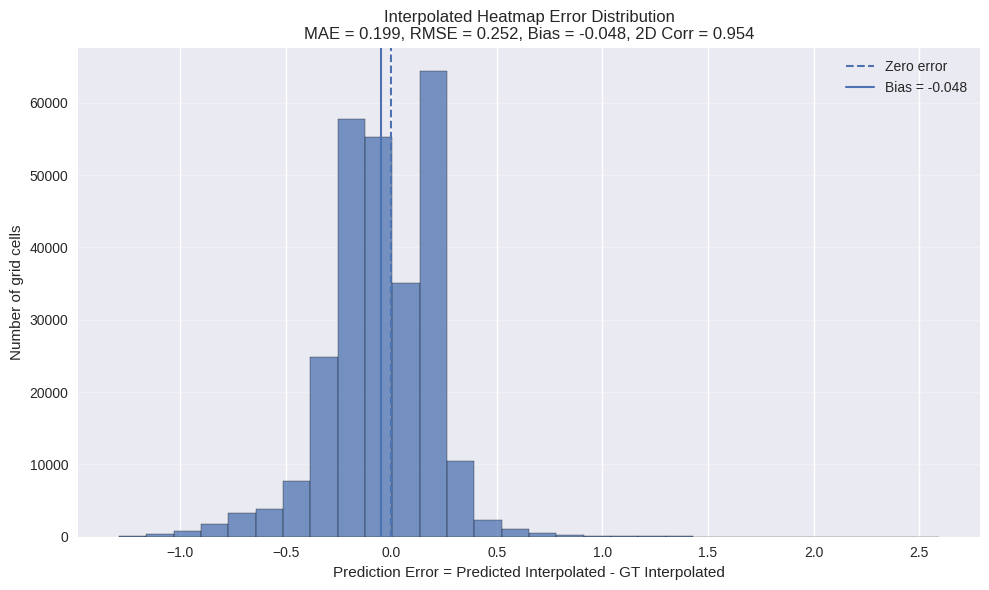

In [ ]:
heatmap_output_folder = TEST_HEATMAP_DIR
comparison_output_folder = ERROR_DISTRIBUTION_DIR

pred_power1_csv = os.path.join(
    heatmap_output_folder,
    "pred_test_weighted_average_idw_power1_heatmap.csv"
)

gt_power1_csv = os.path.join(
    heatmap_output_folder,
    "gt_test_weighted_average_idw_power1_heatmap.csv"
)

metrics_power1, per_cluster_power1, merged_errors_power1 = plot_interpolation_error_distribution(
    pred_csv=pred_power1_csv,
    gt_csv=gt_power1_csv,
    bins=30,
    output_folder=comparison_output_folder,
    save_name="weighted_average_idw_power1_pred_minus_gt",
    coord_round=10,
    use_cluster=True,
    show_plot=True
)

Loaded predicted heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power2_heatmap.csv
Pred shape: (270000, 9)

Loaded GT heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power2_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Error metrics:


,N_Grid_Cells,MAE,RMSE,Bias,Std_Error,Median_Error,Median_Absolute_Error,Min_Error,Max_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Underestimate_Rate,Overestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate
0,270000,0.265808,0.368843,-0.084655,0.358998,-0.103155,0.207475,-1.304553,2.896741,2.896741,0.894089,0.042164,-0.008511,0.601544,0.398456,0.886052,0.963659



Per-cluster error metrics:


,Cluster,N_Grid_Cells,MAE,RMSE,Bias,Std_Error,Median_Error,Median_Absolute_Error,Min_Error,Max_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Underestimate_Rate,Overestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate
0,0,90000,0.202743,0.262600,0.178471,0.192632,0.156998,0.167278,-0.827003,1.340904,1.340904,0.936564,0.039249,0.035193,0.104433,0.895567,0.945944,0.994000
1,1,90000,0.350631,0.474384,-0.322463,0.347935,-0.230470,0.237500,-1.304553,0.824832,1.304553,0.327416,0.050563,-0.046317,0.913511,0.086489,0.791411,0.916689
2,2,90000,0.244050,0.337842,-0.109974,0.319444,-0.188124,0.207831,-1.263957,2.896741,2.896741,0.770751,0.036679,-0.014410,0.786689,0.213311,0.920800,0.980289



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power2_pred_minus_gt_grid_error_table.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power2_pred_minus_gt_overall_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power2_pred_minus_gt_per_cluster_metrics.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power2_pred_minus_gt_error_distribution.png


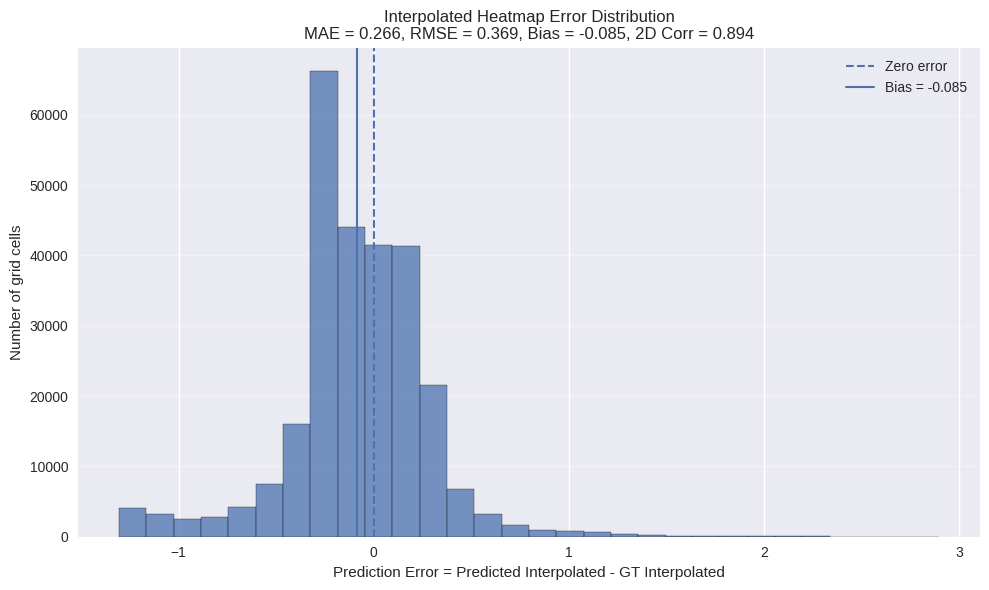

In [ ]:
pred_power2_csv = os.path.join(
    heatmap_output_folder,
    "pred_test_weighted_average_idw_power2_heatmap.csv"
)

gt_power2_csv = os.path.join(
    heatmap_output_folder,
    "gt_test_weighted_average_idw_power2_heatmap.csv"
)

metrics_power2, per_cluster_power2, merged_errors_power2 = plot_interpolation_error_distribution(
    pred_csv=pred_power2_csv,
    gt_csv=gt_power2_csv,
    bins=30,
    output_folder=comparison_output_folder,
    save_name="weighted_average_idw_power2_pred_minus_gt",
    coord_round=10,
    use_cluster=True,
    show_plot=True
)

Loaded predicted heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/generated_heatmaps/pred_test_weighted_average_idw_power5_heatmap.csv
Pred shape: (270000, 9)

Loaded GT heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/generated_heatmaps/gt_test_weighted_average_idw_power5_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Error metrics:


,N_Grid_Cells,MAE,RMSE,Bias,Std_Error,Median_Error,Median_Absolute_Error,Min_Error,Max_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Underestimate_Rate,Overestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate
0,270000,0.383297,0.537463,-0.128815,0.521799,-0.134807,0.25678,-1.304582,2.908095,2.908095,0.839208,0.062272,-0.011863,0.637274,0.362726,0.743519,0.905



Per-cluster error metrics:


,Cluster,N_Grid_Cells,MAE,RMSE,Bias,Std_Error,Median_Error,Median_Absolute_Error,Min_Error,Max_Error,Max_Absolute_Error,Correlation_2D,Mean_Absolute_Relative_Error,Mean_Relative_Bias,Underestimate_Rate,Overestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate
0,0,90000,0.291822,0.407359,0.181008,0.364937,0.133550,0.191382,-0.831360,1.344434,1.344434,0.933207,0.060256,0.042272,0.346256,0.653744,0.823278,0.956600
1,1,90000,0.447930,0.631277,-0.347630,0.526942,-0.218671,0.262622,-1.304582,0.825379,1.304582,0.169243,0.065226,-0.049911,0.719122,0.280878,0.685456,0.808989
2,2,90000,0.410138,0.549680,-0.219823,0.503814,-0.252604,0.281033,-1.266021,2.908095,2.908095,0.696125,0.061335,-0.027950,0.846444,0.153556,0.721822,0.949411



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power5_pred_minus_gt_grid_error_table.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power5_pred_minus_gt_overall_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power5_pred_minus_gt_per_cluster_metrics.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power5_pred_minus_gt_error_distribution.png


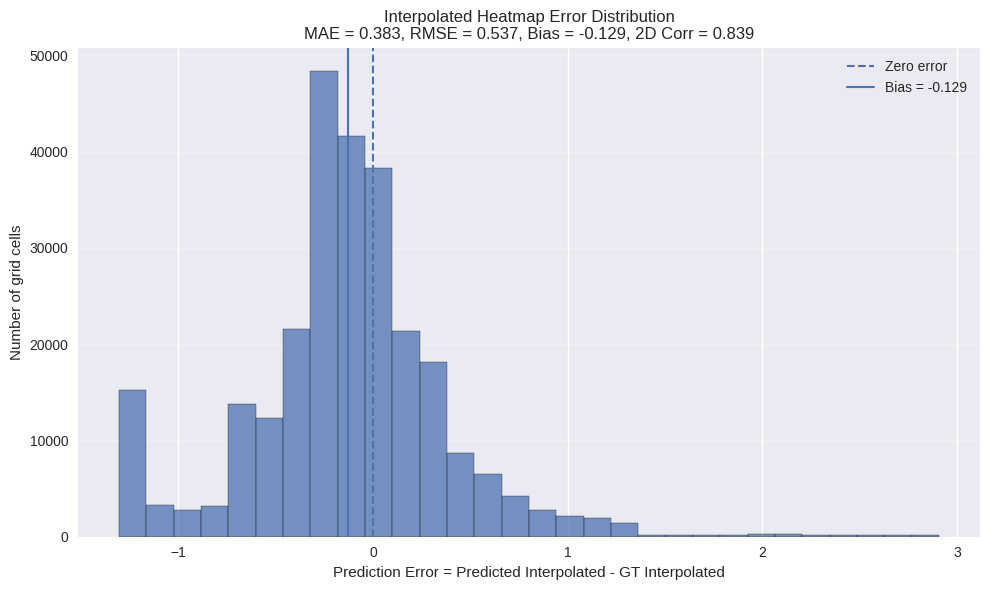

In [ ]:
pred_power5_csv = os.path.join(
    heatmap_output_folder,
    "pred_test_weighted_average_idw_power5_heatmap.csv"
)

gt_power5_csv = os.path.join(
    heatmap_output_folder,
    "gt_test_weighted_average_idw_power5_heatmap.csv"
)

metrics_power5, per_cluster_power5, merged_errors_power5 = plot_interpolation_error_distribution(
    pred_csv=pred_power5_csv,
    gt_csv=gt_power5_csv,
    bins=30,
    output_folder=comparison_output_folder,
    save_name="weighted_average_idw_power5_pred_minus_gt",
    coord_round=10,
    use_cluster=True,
    show_plot=True
)

In [ ]:
combined_error_distribution_metrics = pd.concat(
    [
        metrics_power1.assign(Power=1),
        metrics_power2.assign(Power=2)
    ],
    ignore_index=True
)

display(combined_error_distribution_metrics[
    [
        "Power",
        "N_Grid_Cells",
        "MAE",
        "RMSE",
        "Bias",
        "Std_Error",
        "Correlation_2D",
        "Underestimate_Rate",
        "Overestimate_Rate",
        "Within_0_5_Class_Rate",
        "Within_1_Class_Rate"
    ]
])

combined_path = os.path.join(
    comparison_output_folder,
    "weighted_average_idw_power1_power2_error_distribution_metrics.csv"
)

combined_error_distribution_metrics.to_csv(combined_path, index=False)

print("Saved combined metrics:")
print(combined_path)

,Power,N_Grid_Cells,MAE,RMSE,Bias,Std_Error,Correlation_2D,Underestimate_Rate,Overestimate_Rate,Within_0_5_Class_Rate,Within_1_Class_Rate
0,1,270000,0.199210,0.251923,-0.047921,0.247324,0.954003,0.569830,0.430170,0.951800,0.997030
1,2,270000,0.265808,0.368843,-0.084655,0.358998,0.894089,0.601544,0.398456,0.886052,0.963659


Saved combined metrics:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_error_distribution/weighted_average_idw_power1_power2_error_distribution_metrics.csv


## 10. Label-level heatmap error

A damage map is read in categories rather than as a continuous score, so the heatmaps are also compared after converting each cell value to an integer damage label by flooring, rounding or ceiling, clipped to 3 to 8. `label_level_heatmap_error_analysis` reports exact and adjacent accuracy, MAE, RMSE, bias and over- and underestimation rates overall, per true label and per cluster, together with a confusion matrix of ground-truth against predicted labels.

The manuscript performs its label-level analysis on IDW power 5 heatmaps. In this notebook that is the full-dataset power 5 run at the end of this section. The test-subset analyses with IDW powers 1 and 2 that come first are supplementary.

In [ ]:
# Label-level heatmap error analysis
# GT interpolated heatmap vs Predicted interpolated heatmap
def label_level_heatmap_error_analysis(
    gt_interp,
    pred_interp,
    rounding_method="round",
    output_folder=None,
    save_name="label_level_heatmap_error",
    coord_round=10,
    valid_label_min=3,
    valid_label_max=8
):
    """
    Compares discretized predicted and GT interpolated heatmaps.

    The continuous interpolated values are converted to integer labels using:
    - floor
    - ceil
    - round

    Then label-level errors are calculated:
    - Accuracy
    - Adjacent accuracy
    - MAE
    - RMSE
    - Bias
    - Overestimate rate
    - Underestimate rate
    - Per-label metrics
    - Per-cluster metrics

    Parameters
    ----------
    gt_interp : str or pandas.DataFrame
        GT interpolated heatmap CSV path or dataframe.
        Must contain:
        Latitude, Longitude, Interpolated, Cluster

    pred_interp : str or pandas.DataFrame
        Predicted interpolated heatmap CSV path or dataframe.
        Must contain:
        Latitude, Longitude, Interpolated, Cluster

    rounding_method : str
        One of:
        - "floor"
        - "ceil"
        - "round"

    output_folder : str or None
        Folder for saved outputs.

    save_name : str
        Base name for saved CSV files.

    coord_round : int
        Number of decimals for coordinate rounding before merge.

    valid_label_min, valid_label_max : int
        Labels are clipped to this range after rounding.

    Returns
    -------
    comparison_df : pandas.DataFrame
        Grid-cell label comparison table.

    overall_df : pandas.DataFrame
        Overall label-level metrics.

    per_label_df : pandas.DataFrame
        Metrics grouped by true label.

    per_cluster_df : pandas.DataFrame
        Metrics grouped by cluster.
    """

    # 1. Validate rounding method
    valid_rounding = ["floor", "ceil", "round"]

    if rounding_method not in valid_rounding:
        raise ValueError(f"rounding_method must be one of {valid_rounding}")

    # 2. Load inputs
    if isinstance(gt_interp, str):
        gt_df = pd.read_csv(gt_interp)
        gt_source = gt_interp
    else:
        gt_df = gt_interp.copy()
        gt_source = "dataframe"

    if isinstance(pred_interp, str):
        pred_df = pd.read_csv(pred_interp)
        pred_source = pred_interp
    else:
        pred_df = pred_interp.copy()
        pred_source = "dataframe"

    gt_df.columns = gt_df.columns.str.strip()
    pred_df.columns = pred_df.columns.str.strip()

    print("GT source:", gt_source)
    print("Pred source:", pred_source)
    print("GT shape:", gt_df.shape)
    print("Pred shape:", pred_df.shape)

    required_cols = ["Latitude", "Longitude", "Interpolated", "Cluster"]

    for name, df in [("GT", gt_df), ("Pred", pred_df)]:
        missing = [col for col in required_cols if col not in df.columns]
        if missing:
            raise ValueError(
                f"{name} input missing columns: {missing}\n"
                f"Available columns: {list(df.columns)}"
            )

    # 3. Clean numeric columns
    for df in [gt_df, pred_df]:
        for col in required_cols:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        df.dropna(subset=required_cols, inplace=True)

        df["Cluster"] = df["Cluster"].astype(int)
        df["Latitude_round"] = df["Latitude"].round(coord_round)
        df["Longitude_round"] = df["Longitude"].round(coord_round)

    # 4. Merge grids
    gt_small = gt_df[
        [
            "Latitude",
            "Longitude",
            "Latitude_round",
            "Longitude_round",
            "Cluster",
            "Interpolated"
        ]
    ].copy()

    pred_small = pred_df[
        [
            "Latitude",
            "Longitude",
            "Latitude_round",
            "Longitude_round",
            "Cluster",
            "Interpolated"
        ]
    ].copy()

    gt_small = gt_small.rename(
        columns={
            "Latitude": "Latitude_GTgrid",
            "Longitude": "Longitude_GTgrid",
            "Interpolated": "GT_Interpolated"
        }
    )

    pred_small = pred_small.rename(
        columns={
            "Latitude": "Latitude_Predgrid",
            "Longitude": "Longitude_Predgrid",
            "Interpolated": "Pred_Interpolated"
        }
    )

    comparison_df = gt_small.merge(
        pred_small,
        on=["Latitude_round", "Longitude_round", "Cluster"],
        how="inner"
    )

    if comparison_df.empty:
        raise ValueError(
            "GT and predicted heatmap grids did not align. "
            "Check that they were created with the same input points, buffer_m, grid_res, and clusters."
        )

    comparison_df["Latitude"] = comparison_df["Latitude_GTgrid"]
    comparison_df["Longitude"] = comparison_df["Longitude_GTgrid"]

    print("Merged grid cells:", len(comparison_df))

    # 5. Convert continuous values to labels
    def discretize(values, method):
        values = np.asarray(values, dtype=float)

        if method == "floor":
            labels = np.floor(values)
        elif method == "ceil":
            labels = np.ceil(values)
        elif method == "round":
            labels = np.rint(values)

        labels = labels.astype(int)

        # Clip to valid triage range
        labels = np.clip(labels, valid_label_min, valid_label_max)

        return labels

    comparison_df["Label_GT"] = discretize(
        comparison_df["GT_Interpolated"],
        rounding_method
    )

    comparison_df["Label_Pred"] = discretize(
        comparison_df["Pred_Interpolated"],
        rounding_method
    )

    # 6. Label-level errors
    comparison_df["Label_Error"] = (
        comparison_df["Label_Pred"] -
        comparison_df["Label_GT"]
    )

    comparison_df["Label_Absolute_Error"] = comparison_df["Label_Error"].abs()
    comparison_df["Label_Squared_Error"] = comparison_df["Label_Error"] ** 2

    comparison_df["Exact_Match"] = comparison_df["Label_Error"] == 0
    comparison_df["Adjacent_Match"] = comparison_df["Label_Absolute_Error"] <= 1

    comparison_df["Error_Direction"] = np.where(
        comparison_df["Label_Error"] > 0,
        "Overestimate",
        np.where(comparison_df["Label_Error"] < 0, "Underestimate", "Exact")
    )

    # 7. Metric helper
    def summarize_label_errors(group):
        errors = group["Label_Error"].values
        abs_errors = group["Label_Absolute_Error"].values

        return pd.Series({
            "N_Grid_Cells": len(group),
            "Accuracy": group["Exact_Match"].mean(),
            "Adjacent_Accuracy": group["Adjacent_Match"].mean(),
            "MAE": np.mean(abs_errors),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "Bias": np.mean(errors),
            "Median_Absolute_Error": np.median(abs_errors),
            "Max_Absolute_Error": np.max(abs_errors),
            "Overestimate_Rate": (errors > 0).mean(),
            "Underestimate_Rate": (errors < 0).mean(),
            "Exact_Match_Count": int((errors == 0).sum()),
            "Adjacent_Match_Count": int((abs_errors <= 1).sum())
        })

    # 8. Overall metrics
    overall_df = summarize_label_errors(comparison_df).to_frame().T
    overall_df.insert(0, "Rounding_Method", rounding_method)
    overall_df.insert(0, "Analysis", save_name)

    print("\nOverall label-level heatmap metrics:")
    display(overall_df)

    # 9. Per-true-label metrics
    per_label_df = (
        comparison_df
        .groupby("Label_GT")
        .apply(summarize_label_errors)
        .reset_index()
        .rename(columns={"Label_GT": "True_Heatmap_Label"})
        .sort_values("True_Heatmap_Label")
        .reset_index(drop=True)
    )

    per_label_df.insert(0, "Rounding_Method", rounding_method)
    per_label_df.insert(0, "Analysis", save_name)

    print("\nPer-true-label heatmap metrics:")
    display(per_label_df)

    # 10. Per-cluster metrics
    per_cluster_df = (
        comparison_df
        .groupby("Cluster")
        .apply(summarize_label_errors)
        .reset_index()
        .sort_values("Cluster")
        .reset_index(drop=True)
    )

    per_cluster_df.insert(0, "Rounding_Method", rounding_method)
    per_cluster_df.insert(0, "Analysis", save_name)

    print("\nPer-cluster label-level heatmap metrics:")
    display(per_cluster_df)

    # 11. Confusion matrix table
    confusion_df = pd.crosstab(
        comparison_df["Label_GT"],
        comparison_df["Label_Pred"],
        rownames=["GT_Label"],
        colnames=["Pred_Label"],
        dropna=False
    )

    # Ensure full label range appears
    full_labels = list(range(valid_label_min, valid_label_max + 1))
    confusion_df = confusion_df.reindex(
        index=full_labels,
        columns=full_labels,
        fill_value=0
    )

    print("\nHeatmap label confusion matrix:")
    display(confusion_df)

    # 12. Save outputs
    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        comparison_path = os.path.join(
            output_folder,
            f"{save_name}_{rounding_method}_label_grid_comparison.csv"
        )

        overall_path = os.path.join(
            output_folder,
            f"{save_name}_{rounding_method}_label_overall_metrics.csv"
        )

        per_label_path = os.path.join(
            output_folder,
            f"{save_name}_{rounding_method}_label_per_true_label_metrics.csv"
        )

        per_cluster_path = os.path.join(
            output_folder,
            f"{save_name}_{rounding_method}_label_per_cluster_metrics.csv"
        )

        confusion_path = os.path.join(
            output_folder,
            f"{save_name}_{rounding_method}_label_confusion_matrix.csv"
        )

        comparison_df.to_csv(comparison_path, index=False)
        overall_df.to_csv(overall_path, index=False)
        per_label_df.to_csv(per_label_path, index=False)
        per_cluster_df.to_csv(per_cluster_path, index=False)
        confusion_df.to_csv(confusion_path)

        print("\nSaved label-level heatmap outputs:")
        print(comparison_path)
        print(overall_path)
        print(per_label_path)
        print(per_cluster_path)
        print(confusion_path)

    return comparison_df, overall_df, per_label_df, per_cluster_df, confusion_df

The next cell runs the analysis on the test-subset heatmaps for IDW powers 1 and 5 with rounding. In the original run the power 5 test heatmaps were not in the folder this cell read from, and it stopped with a `FileNotFoundError` after the first configuration; that error message has been removed from the saved output. The files now exist because they are created in Section 9, so a re-run completes both configurations and also prints the combined table.

In [ ]:
# Label-level heatmap analysis on the test subset, IDW power 1 and power 5, rounding
heatmap_output_folder = TEST_HEATMAP_DIR  # test-subset heatmaps written in Section 9

label_heatmap_output_folder = LABEL_ERROR_DIR

os.makedirs(label_heatmap_output_folder, exist_ok=True)

power_configs = [
    {
        "power": 1,
        "gt_csv": os.path.join(
            heatmap_output_folder,
            "gt_test_weighted_average_idw_power1_heatmap.csv"
        ),
        "pred_csv": os.path.join(
            heatmap_output_folder,
            "pred_test_weighted_average_idw_power1_heatmap.csv"
        ),
        "save_name": "weighted_average_idw_power1_gt_vs_pred"
    },
    {
        "power": 5,
        "gt_csv": os.path.join(
            heatmap_output_folder,
            "gt_test_weighted_average_idw_power5_heatmap.csv"
        ),
        "pred_csv": os.path.join(
            heatmap_output_folder,
            "pred_test_weighted_average_idw_power5_heatmap.csv"
        ),
        "save_name": "weighted_average_idw_power5_gt_vs_pred"
    }
]

rounding_methods = ["round"]

all_label_overall = []
all_label_per_label = []
all_label_per_cluster = []

label_results = {}

for cfg in power_configs:

    for rounding_method in rounding_methods:

        print("\n" + "=" * 90)
        print(f"Power {cfg['power']} | Rounding method: {rounding_method}")
        print("=" * 90)

        comparison_df, overall_df, per_label_df, per_cluster_df, confusion_df = label_level_heatmap_error_analysis(
            gt_interp=cfg["gt_csv"],
            pred_interp=cfg["pred_csv"],
            rounding_method=rounding_method,
            output_folder=label_heatmap_output_folder,
            save_name=f"{cfg['save_name']}",
            coord_round=10,
            valid_label_min=3,
            valid_label_max=8
        )

        overall_df["Power"] = cfg["power"]
        per_label_df["Power"] = cfg["power"]
        per_cluster_df["Power"] = cfg["power"]

        all_label_overall.append(overall_df)
        all_label_per_label.append(per_label_df)
        all_label_per_cluster.append(per_cluster_df)

        label_results[(cfg["power"], rounding_method)] = {
            "comparison_df": comparison_df,
            "overall_df": overall_df,
            "per_label_df": per_label_df,
            "per_cluster_df": per_cluster_df,
            "confusion_df": confusion_df
        }

combined_label_overall = pd.concat(all_label_overall, ignore_index=True)
combined_label_per_label = pd.concat(all_label_per_label, ignore_index=True)
combined_label_per_cluster = pd.concat(all_label_per_cluster, ignore_index=True)

# Save combined tables
combined_label_overall_path = os.path.join(
    label_heatmap_output_folder,
    "combined_label_level_heatmap_overall_metrics.csv"
)

combined_label_per_label_path = os.path.join(
    label_heatmap_output_folder,
    "combined_label_level_heatmap_per_true_label_metrics.csv"
)

combined_label_per_cluster_path = os.path.join(
    label_heatmap_output_folder,
    "combined_label_level_heatmap_per_cluster_metrics.csv"
)

combined_label_overall.to_csv(combined_label_overall_path, index=False)
combined_label_per_label.to_csv(combined_label_per_label_path, index=False)
combined_label_per_cluster.to_csv(combined_label_per_cluster_path, index=False)

print("\n✅ Combined label-level heatmap tables saved:")
print(combined_label_overall_path)
print(combined_label_per_label_path)
print(combined_label_per_cluster_path)

print("\nCombined overall label-level heatmap metrics:")
display(
    combined_label_overall[
        [
            "Power",
            "Rounding_Method",
            "N_Grid_Cells",
            "Accuracy",
            "Adjacent_Accuracy",
            "MAE",
            "RMSE",
            "Bias",
            "Overestimate_Rate",
            "Underestimate_Rate"
        ]
    ].sort_values(["Power", "Rounding_Method"])
)


Power 1 | Rounding method: round
GT source: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power1_heatmap.csv
Pred source: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power1_heatmap.csv
GT shape: (270000, 9)
Pred shape: (270000, 9)
Merged grid cells: 270000

Overall label-level heatmap metrics:


,Analysis,Rounding_Method,N_Grid_Cells,Accuracy,Adjacent_Accuracy,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Overestimate_Rate,Underestimate_Rate,Exact_Match_Count,Adjacent_Match_Count
0,weighted_average_idw_power1_gt_vs_pred,round,270000.0,0.759107,0.99993,0.241015,0.491287,0.091067,0.0,3.0,0.165919,0.074974,204959.0,269981.0



Per-true-label heatmap metrics:


/tmp/ipykernel_6090/3318140278.py:296: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarize_label_errors)


,Analysis,Rounding_Method,True_Heatmap_Label,N_Grid_Cells,Accuracy,Adjacent_Accuracy,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Overestimate_Rate,Underestimate_Rate,Exact_Match_Count,Adjacent_Match_Count
0,weighted_average_idw_power1_gt_vs_pred,round,3,14.0,0.142857,0.857143,1.000000,1.133893,1.000000,1.0,2.0,0.857143,0.000000,2.0,12.0
1,weighted_average_idw_power1_gt_vs_pred,round,4,480.0,0.216667,1.000000,0.783333,0.885061,0.783333,1.0,1.0,0.783333,0.000000,104.0,480.0
2,weighted_average_idw_power1_gt_vs_pred,round,5,46853.0,0.266835,0.999701,0.733763,0.857646,0.733763,1.0,3.0,0.733165,0.000000,12502.0,46839.0
3,weighted_average_idw_power1_gt_vs_pred,round,6,77944.0,0.870112,0.999962,0.129927,0.360560,0.128259,0.0,2.0,0.129054,0.000834,67820.0,77941.0
4,weighted_average_idw_power1_gt_vs_pred,round,7,144069.0,0.863343,1.000000,0.136657,0.369671,-0.136657,0.0,1.0,0.000000,0.136657,124381.0,144069.0
5,weighted_average_idw_power1_gt_vs_pred,round,8,640.0,0.234375,1.000000,0.765625,0.875000,-0.765625,1.0,1.0,0.000000,0.765625,150.0,640.0



Per-cluster label-level heatmap metrics:


/tmp/ipykernel_6090/3318140278.py:316: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarize_label_errors)


,Analysis,Rounding_Method,Cluster,N_Grid_Cells,Accuracy,Adjacent_Accuracy,MAE,RMSE,Bias,Median_Absolute_Error,Max_Absolute_Error,Overestimate_Rate,Underestimate_Rate,Exact_Match_Count,Adjacent_Match_Count
0,weighted_average_idw_power1_gt_vs_pred,round,0,90000.0,0.612778,0.999978,0.387244,0.622325,0.385444,0.0,2.0,0.386322,0.000900,55150.0,89998.0
1,weighted_average_idw_power1_gt_vs_pred,round,1,90000.0,0.869400,1.000000,0.130600,0.361386,-0.130022,0.0,1.0,0.000289,0.130311,78246.0,90000.0
2,weighted_average_idw_power1_gt_vs_pred,round,2,90000.0,0.795144,0.999811,0.205200,0.454093,0.017778,0.0,3.0,0.111144,0.093711,71563.0,89983.0



Heatmap label confusion matrix:


Pred_Label,3,4,5,6,7,8
GT_Label,,,,,,
3,2,10,2,0,0,0
4,0,104,376,0,0,0
5,0,0,12502,34337,0,14
6,0,0,65,67820,10056,3
7,0,0,0,19688,124381,0
8,0,0,0,0,490,150



Saved label-level heatmap outputs:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/weighted_average_idw_power1_gt_vs_pred_round_label_grid_comparison.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/weighted_average_idw_power1_gt_vs_pred_round_label_overall_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/weighted_average_idw_power1_gt_vs_pred_round_label_per_true_label_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/weighted_average_idw_power1_gt_vs_pred_round_label_per_cluster_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/weighted_average_idw_power1_gt_vs_pred_round_label_confusion_matrix.csv

Power 5 | Rounding method: round


For each grid cell, the ground-truth and predicted interpolated values are converted into integer labels with one of three discretization approaches (floor, round or ceiling), and the label error is computed as predicted heatmap label minus ground-truth heatmap label. A positive error means that the predicted heatmap assigns a higher damage label than the ground truth; a negative error means underestimation. Exact accuracy is the proportion of grid cells with identical labels, and adjacent accuracy the proportion within one damage class. The latter is useful because neighbouring categories can be visually similar and engineers often disagree on them.

This analysis complements the continuous comparison. Continuous MAE, RMSE and 2D correlation evaluate whether the predicted heatmap preserves the overall severity surface, while the label-level analysis evaluates whether the same surface would lead to similar categorical damage assignments, which is closer to how USAR personnel would read the map. The test-subset heatmaps are interpolated from only 45 images, so their label-level results depend strongly on point density and serve as a secondary check.

With IDW power 1 and rounding, the test-subset heatmaps agreed on the exact label in 75.9% of grid cells and within one label in 99.993%, with MAE 0.241, RMSE 0.491 and bias +0.091 (16.6% of cells overestimated, 7.5% underestimated). Agreement varied between clusters, from 61.3% exact agreement in cluster 0, where the predicted labels were mostly too high (bias +0.385), to 86.9% in cluster 1, where they were slightly too low (bias −0.130). The confusion matrix shows that disagreements were almost all between neighbouring labels: most ground-truth label-5 cells were predicted as 6, most ground-truth label-7 cells kept label 7 and the rest were predicted as 6, and the few ground-truth label-8 cells (640) were mostly predicted as 7.

The per-label plots that follow were produced by an earlier version of the label-level cell above, run for IDW powers 1 and 2 and all three conversions. That configuration is restored in the next cell, which was not part of the saved notebook and therefore has no saved output; it rebuilds the tables `combined_label_overall` and `combined_label_per_label` that the plotting cell reads. The plotted values agree with the bias tables later in this section (for example, the overall MAE of 0.2410 for power 1 with rounding equals the value printed above). The plots show MAE, RMSE, exact accuracy and adjacent accuracy per true heatmap label, with the overall value in each title.

In [ ]:
# IDW powers 1 and 2, all three conversions (configuration behind the plots below)
label_power_configs = [
    {
        "power": power,
        "gt_csv": os.path.join(TEST_HEATMAP_DIR, f"gt_test_weighted_average_idw_power{power}_heatmap.csv"),
        "pred_csv": os.path.join(TEST_HEATMAP_DIR, f"pred_test_weighted_average_idw_power{power}_heatmap.csv"),
        "save_name": f"weighted_average_idw_power{power}_gt_vs_pred",
    }
    for power in [1, 2]
]

all_label_overall = []
all_label_per_label = []
all_label_per_cluster = []

for cfg in label_power_configs:
    for rounding_method in ["floor", "round", "ceil"]:
        print("\n" + "=" * 90)
        print(f"Power {cfg['power']} | Rounding method: {rounding_method}")
        print("=" * 90)

        comparison_df, overall_df, per_label_df, per_cluster_df, confusion_df = label_level_heatmap_error_analysis(
            gt_interp=cfg["gt_csv"],
            pred_interp=cfg["pred_csv"],
            rounding_method=rounding_method,
            output_folder=LABEL_ERROR_DIR,
            save_name=cfg["save_name"],
            coord_round=10,
            valid_label_min=3,
            valid_label_max=8
        )

        for table in (overall_df, per_label_df, per_cluster_df):
            table["Power"] = cfg["power"]

        all_label_overall.append(overall_df)
        all_label_per_label.append(per_label_df)
        all_label_per_cluster.append(per_cluster_df)

combined_label_overall = pd.concat(all_label_overall, ignore_index=True)
combined_label_per_label = pd.concat(all_label_per_label, ignore_index=True)
combined_label_per_cluster = pd.concat(all_label_per_cluster, ignore_index=True)

combined_label_overall.to_csv(os.path.join(LABEL_ERROR_DIR, "combined_label_level_heatmap_overall_metrics.csv"), index=False)
combined_label_per_label.to_csv(os.path.join(LABEL_ERROR_DIR, "combined_label_level_heatmap_per_true_label_metrics.csv"), index=False)
combined_label_per_cluster.to_csv(os.path.join(LABEL_ERROR_DIR, "combined_label_level_heatmap_per_cluster_metrics.csv"), index=False)

In [ ]:
# Bar plot of one label-level metric per true label
def plot_metric_by_label_style(
    per_label_df,
    label_col="True_Heatmap_Label",
    metric_col="MAE",
    overall_value=None,
    output_folder=None,
    save_name=None,
    title_prefix=None,
    xlabel="True Label",
    ylabel=None,
    bar_color="skyblue",
    figsize=(10, 5),
    y_max=None
):
    """
    Creates a bar plot of one metric per true label.

    Parameters
    ----------
    per_label_df : pandas.DataFrame
        Table containing label-level results.

    label_col : str
        Column containing the true labels.

    metric_col : str
        Column to plot, e.g. "MAE", "RMSE", "Accuracy", "Bias".

    overall_value : float or None
        Optional overall metric value to show in the title.

    output_folder : str or None
        Folder to save the plot.

    save_name : str or None
        File name without extension.

    title_prefix : str or None
        Custom title prefix. If None, uses metric_col.

    xlabel : str
        X-axis label.

    ylabel : str or None
        Y-axis label. If None, uses metric_col.

    bar_color : str
        Bar color.

    figsize : tuple
        Figure size.

    y_max : float or None
        Optional y-axis maximum.
    """

    df = per_label_df.copy()

    # Keep only valid rows
    df[label_col] = pd.to_numeric(df[label_col], errors="coerce")
    df[metric_col] = pd.to_numeric(df[metric_col], errors="coerce")
    df = df.dropna(subset=[label_col, metric_col]).copy()
    df = df.sort_values(label_col)

    labels = df[label_col].astype(int).tolist()
    values = df[metric_col].values

    if ylabel is None:
        ylabel = metric_col

    if title_prefix is None:
        title_prefix = metric_col

    if overall_value is not None:
        title = f"{title_prefix} by Label (Overall {title_prefix} = {overall_value:.4f})"
    else:
        title = f"{title_prefix} by Label"

    # Seaborn-like styling without requiring seaborn
    plt.style.use("seaborn-v0_8")

    fig, ax = plt.subplots(figsize=figsize)

    ax.bar(
        labels,
        values,
        color=bar_color,
        edgecolor="white"
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(labels)

    if y_max is not None:
        ax.set_ylim(0, y_max)

    ax.grid(True, axis="y", alpha=0.7)
    fig.tight_layout()

    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        if save_name is None:
            save_name = f"{metric_col.lower()}_by_label"

        plot_path = os.path.join(output_folder, f"{save_name}.png")
        fig.savefig(plot_path, dpi=300, bbox_inches="tight")
        print("Saved plot:", plot_path)

    plt.show()

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_ceil_mae_by_true_label.png


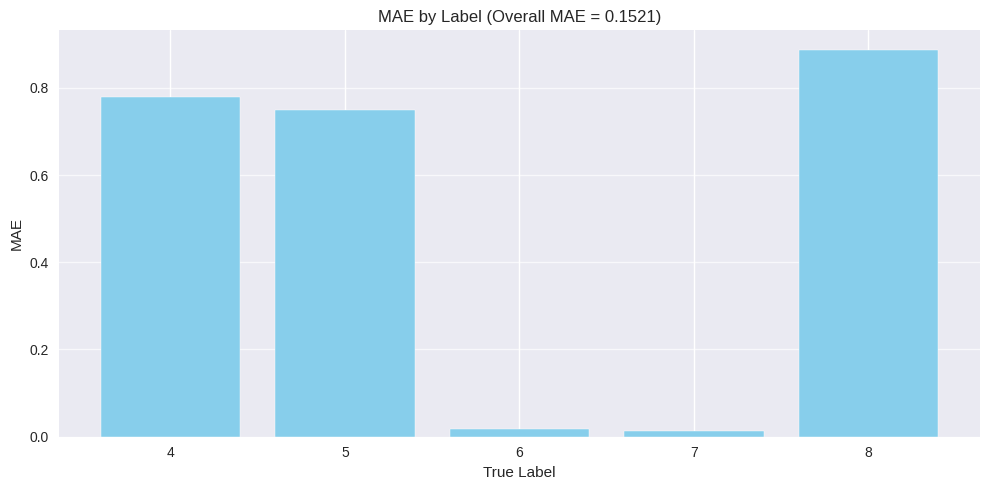

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_ceil_rmse_by_true_label.png


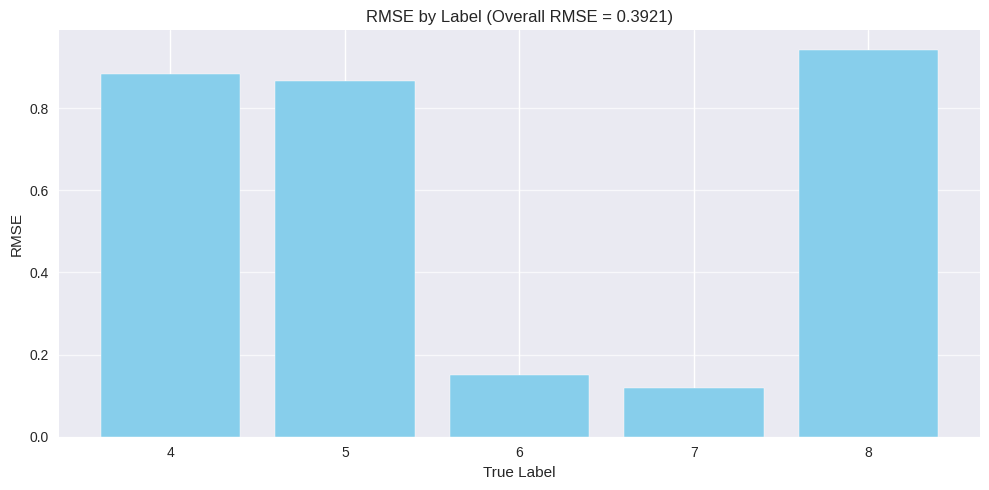

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_ceil_accuracy_by_true_label.png


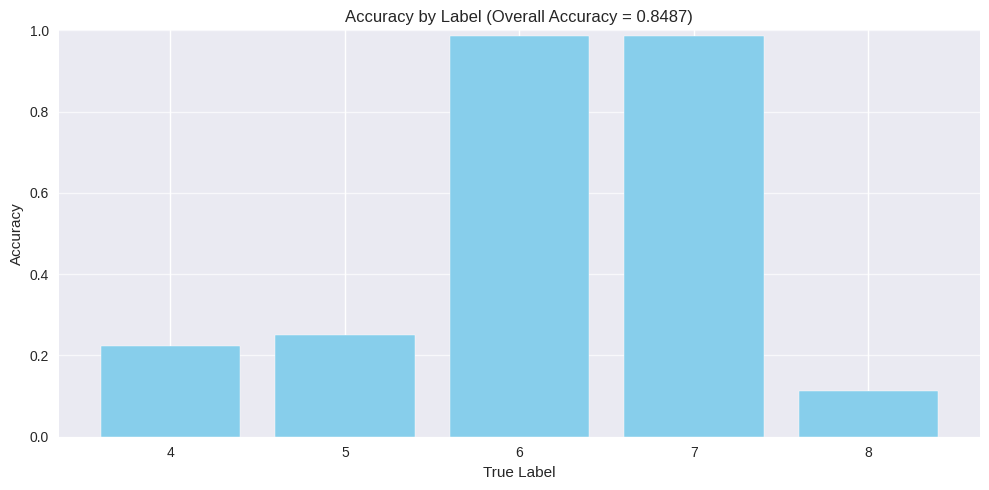

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_ceil_adjacent_accuracy_by_true_label.png


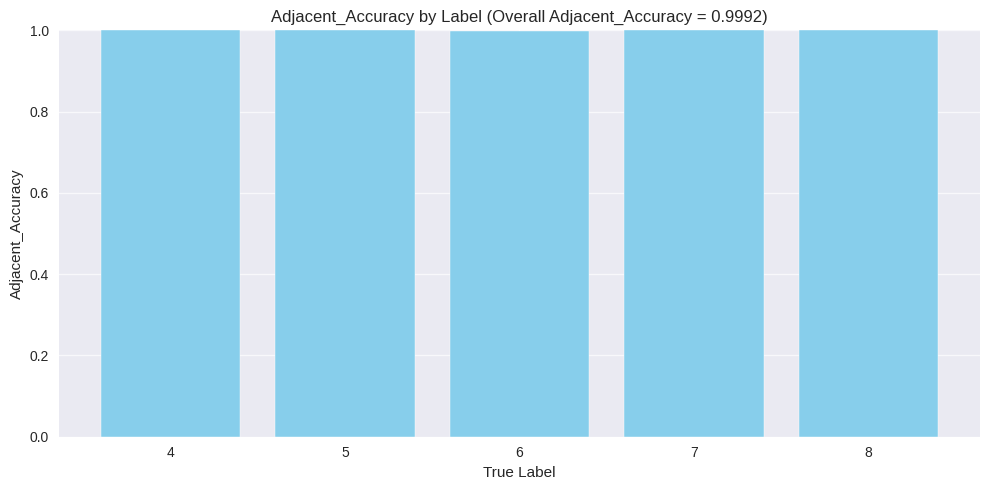

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_floor_mae_by_true_label.png


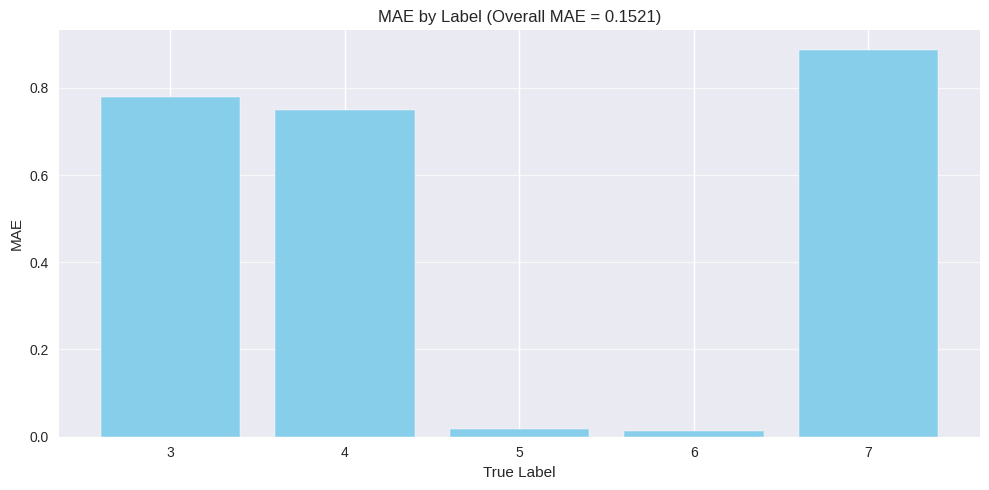

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_floor_rmse_by_true_label.png


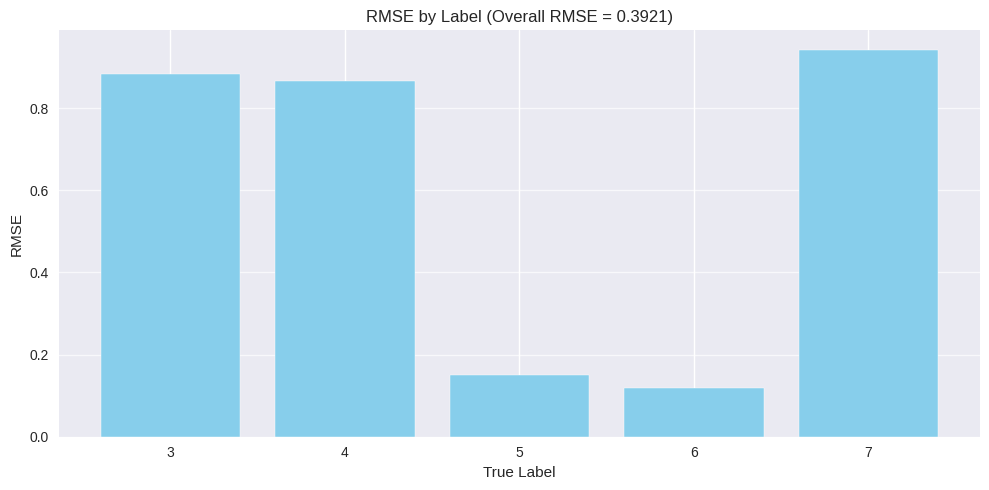

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_floor_accuracy_by_true_label.png


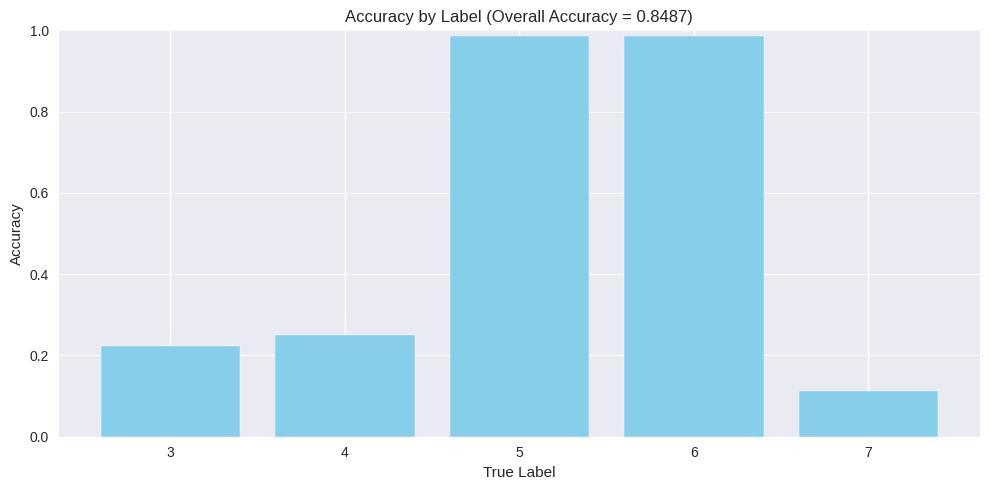

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_floor_adjacent_accuracy_by_true_label.png


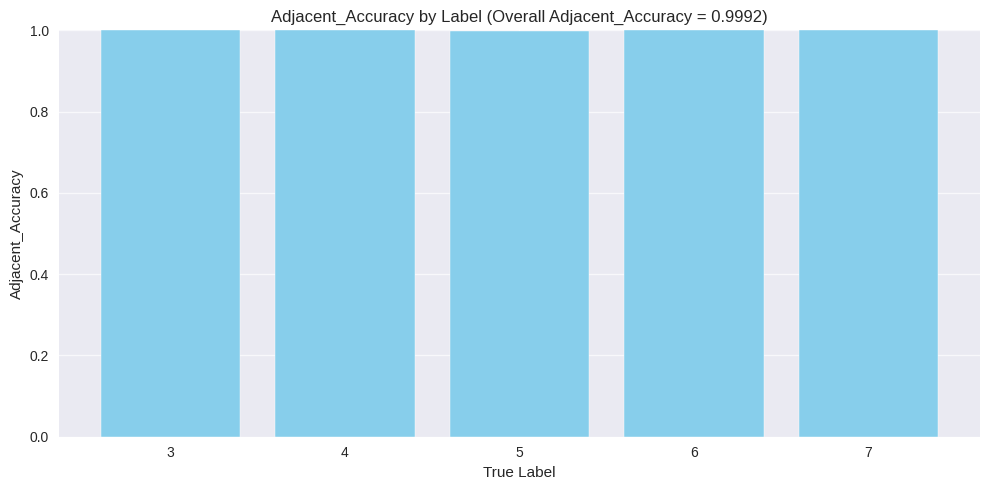

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_round_mae_by_true_label.png


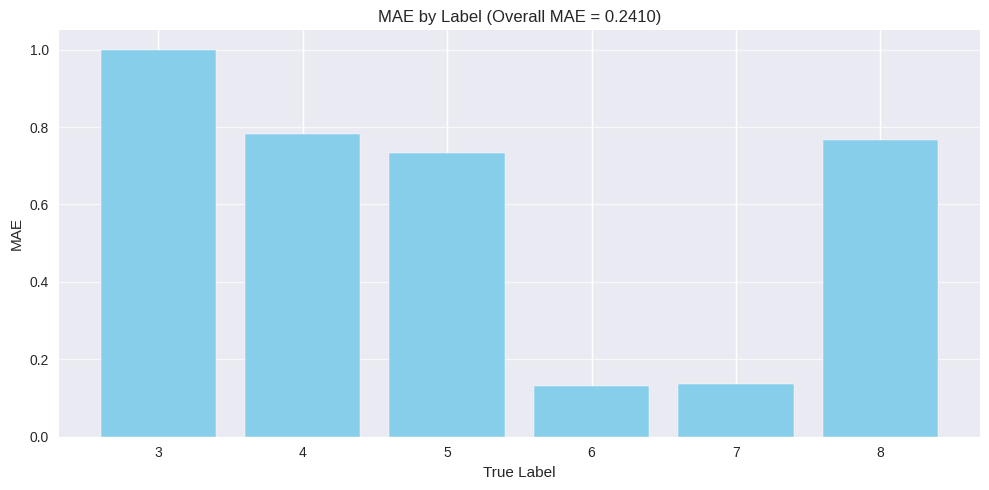

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_round_rmse_by_true_label.png


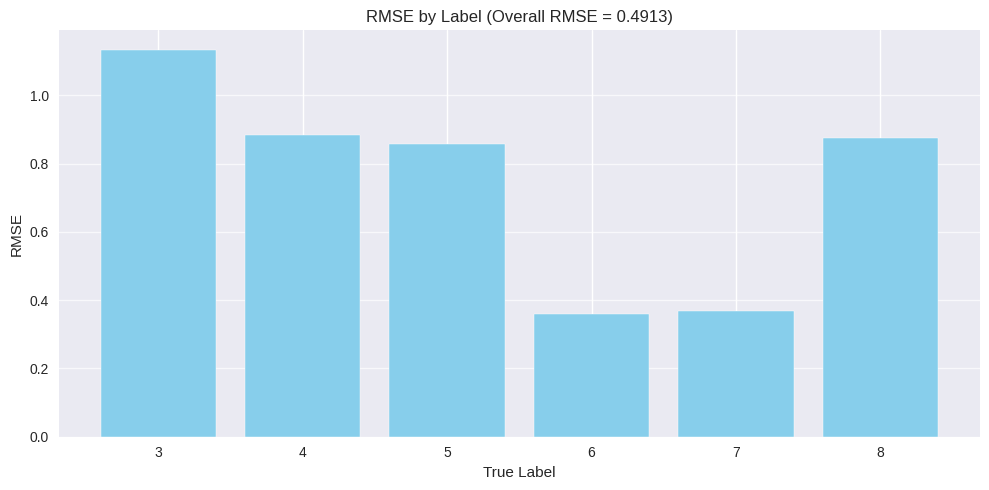

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_round_accuracy_by_true_label.png


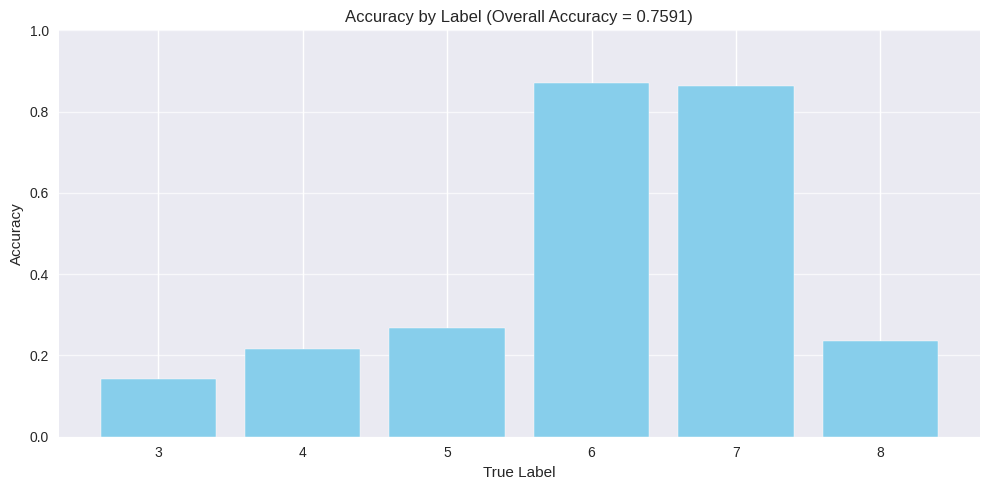

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power1_round_adjacent_accuracy_by_true_label.png


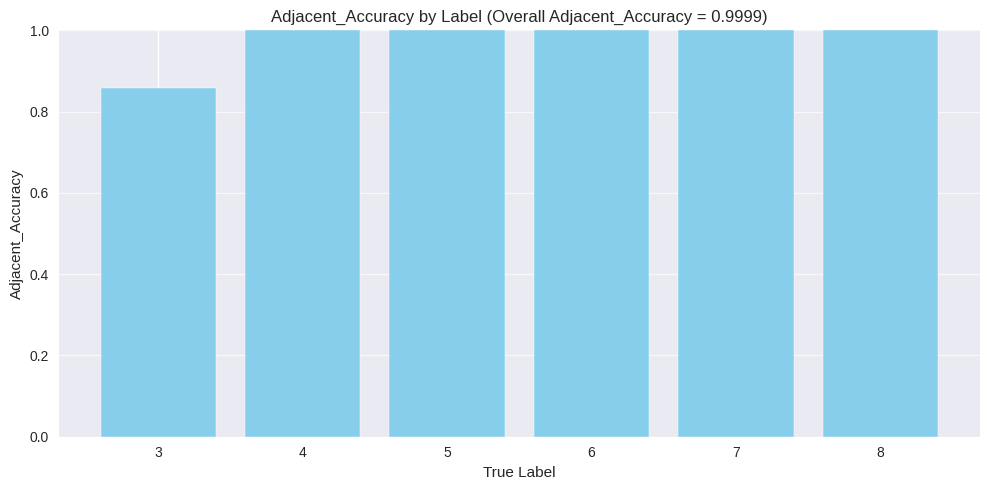

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_ceil_mae_by_true_label.png


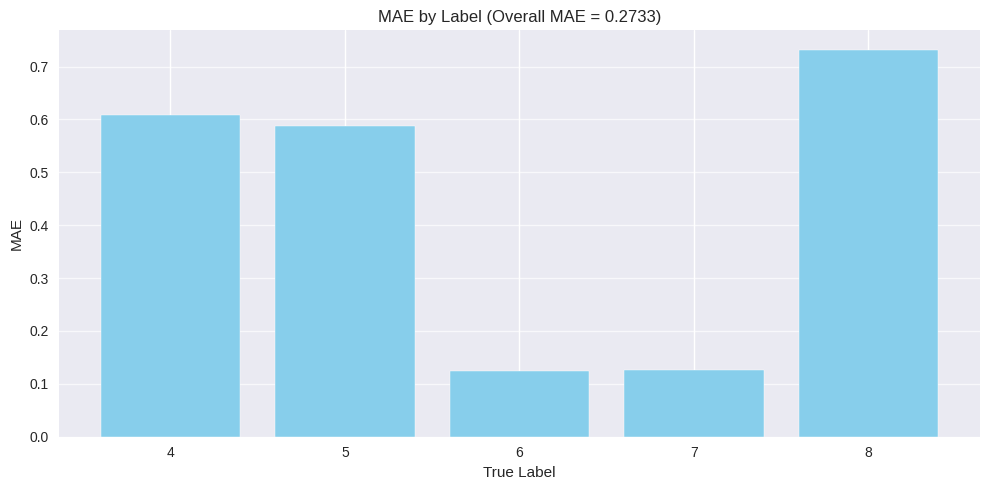

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_ceil_rmse_by_true_label.png


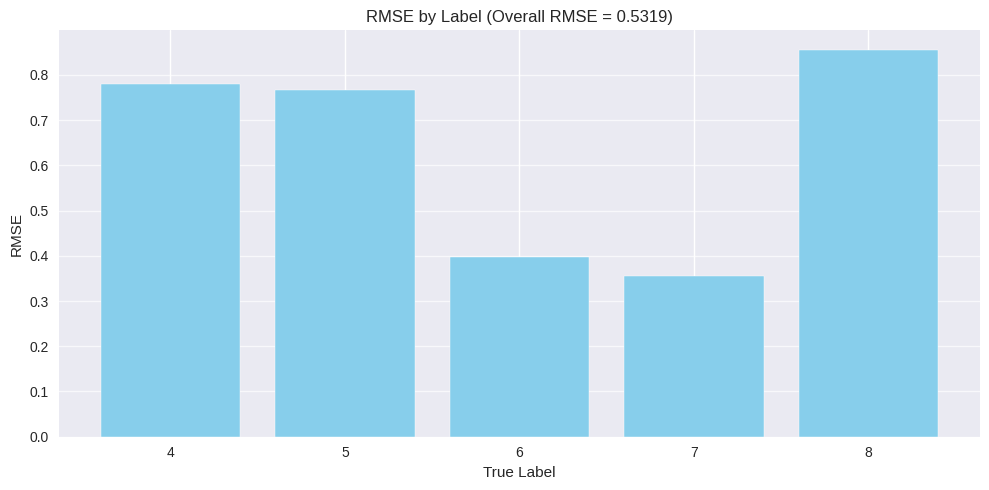

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_ceil_accuracy_by_true_label.png


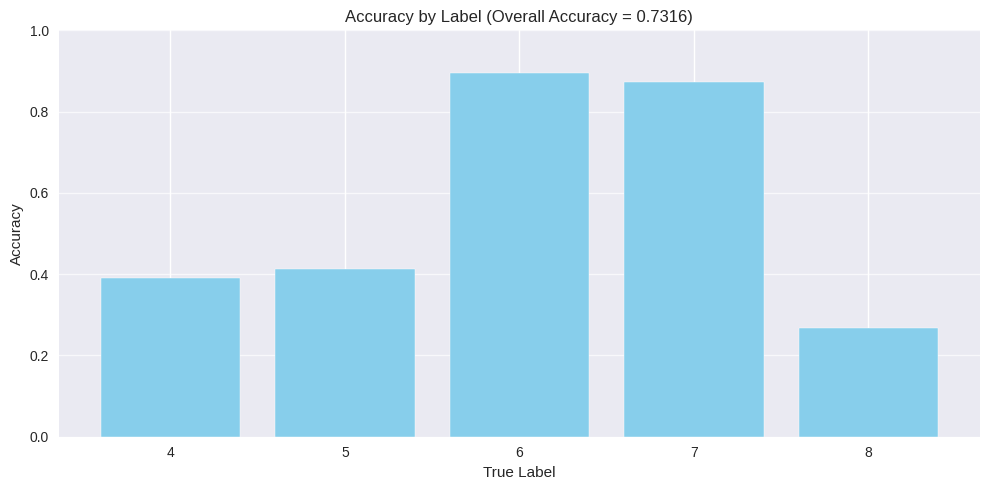

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_ceil_adjacent_accuracy_by_true_label.png


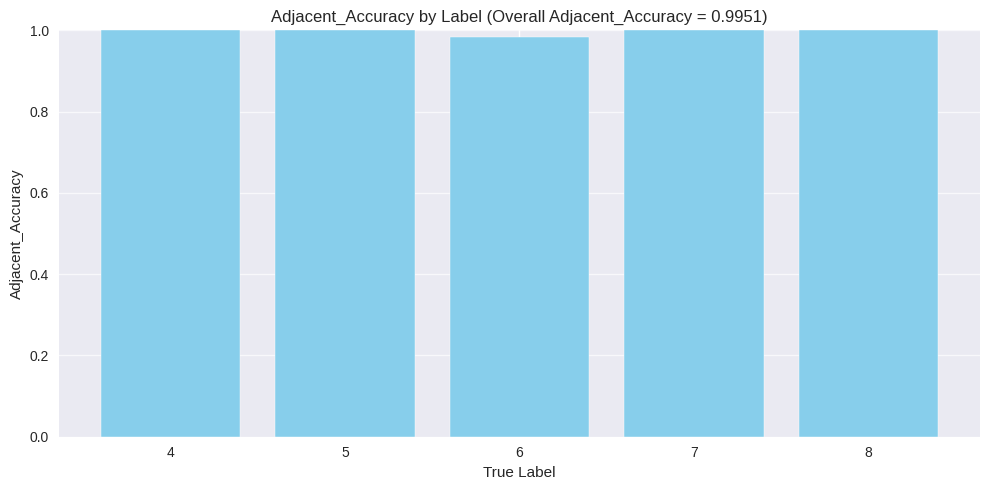

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_floor_mae_by_true_label.png


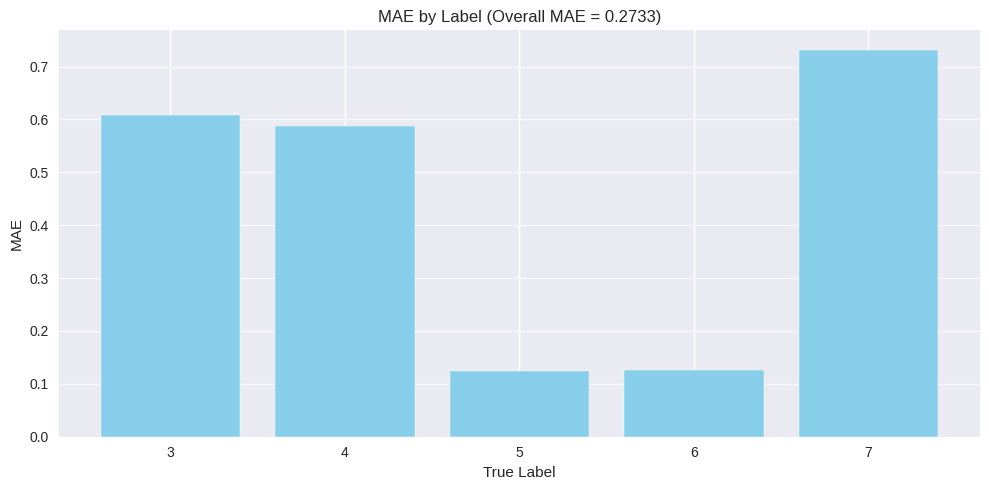

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_floor_rmse_by_true_label.png


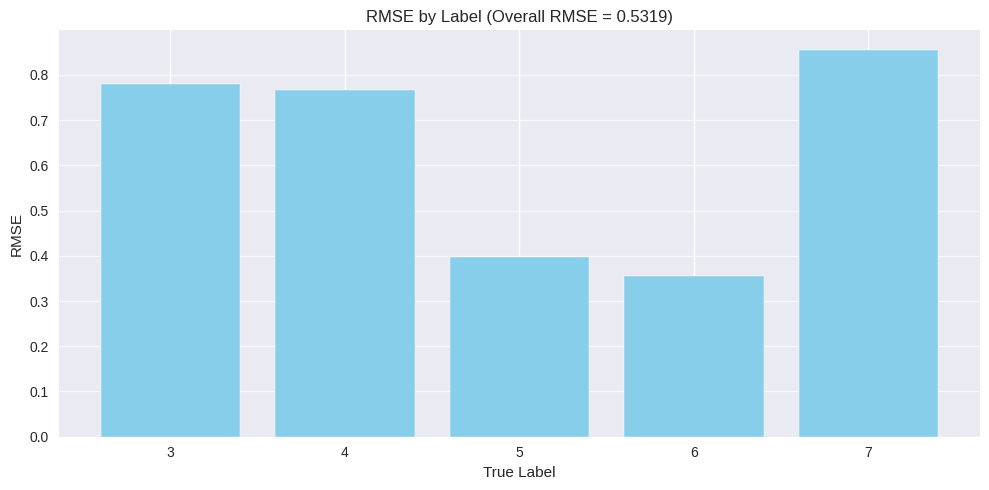

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_floor_accuracy_by_true_label.png


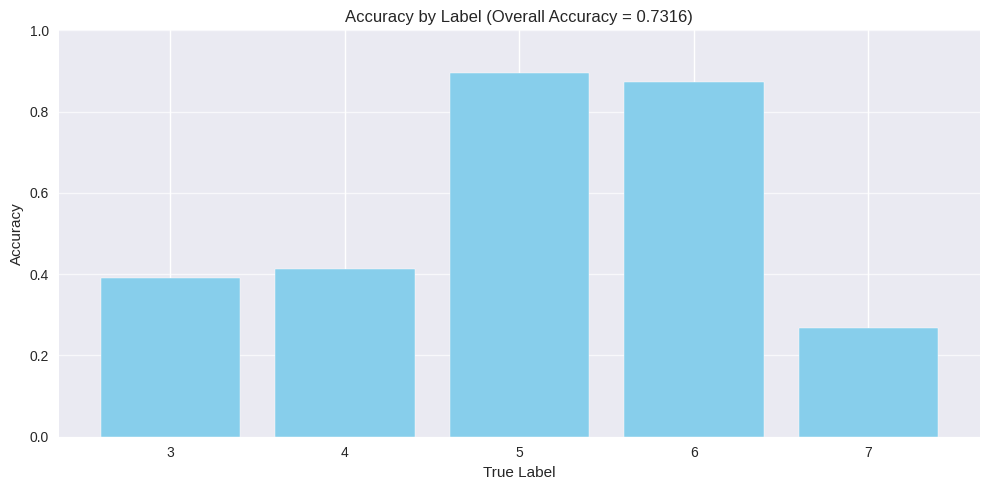

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_floor_adjacent_accuracy_by_true_label.png


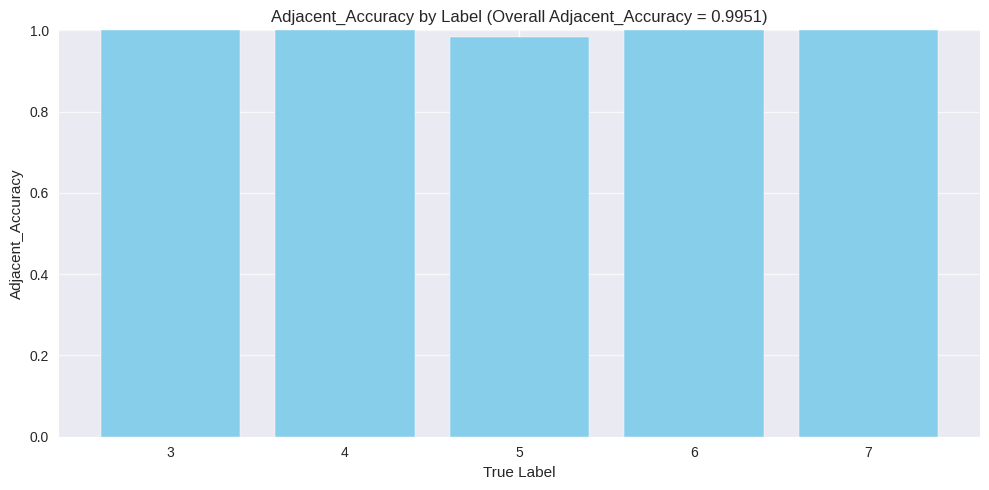

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_round_mae_by_true_label.png


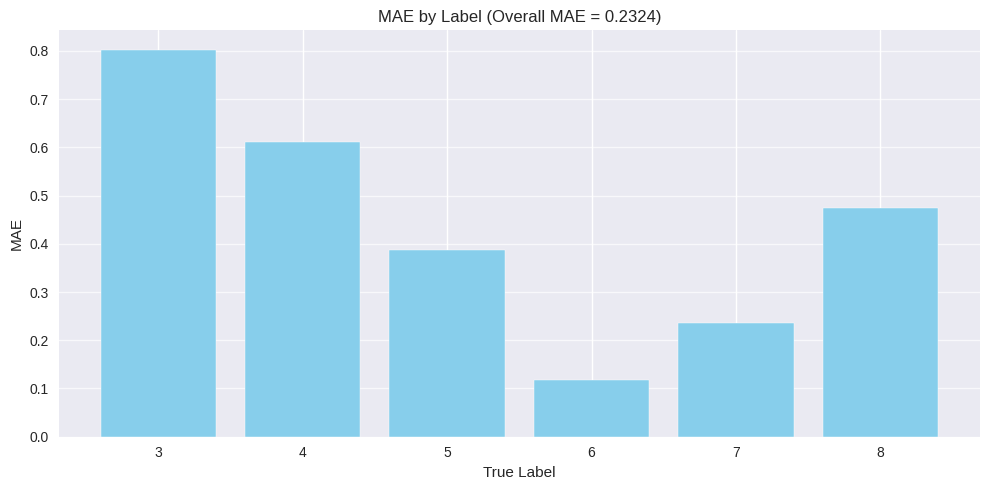

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_round_rmse_by_true_label.png


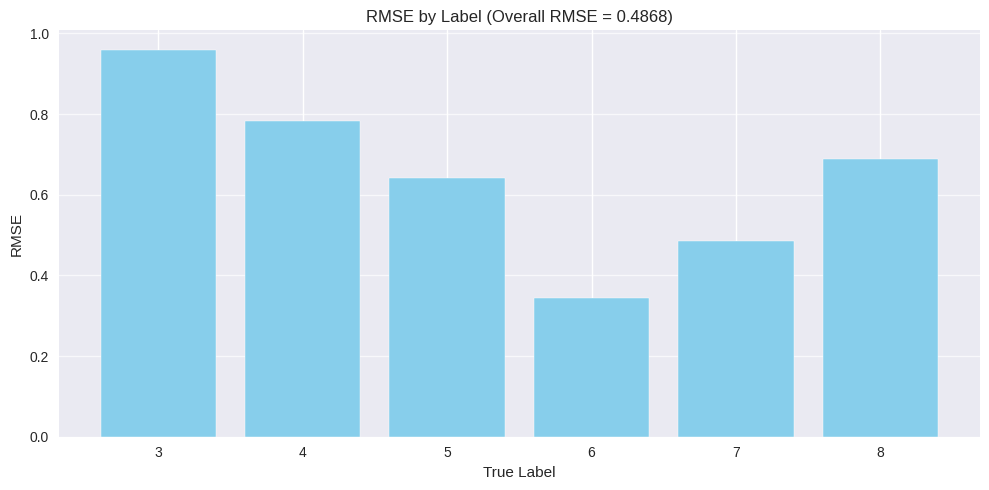

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_round_accuracy_by_true_label.png


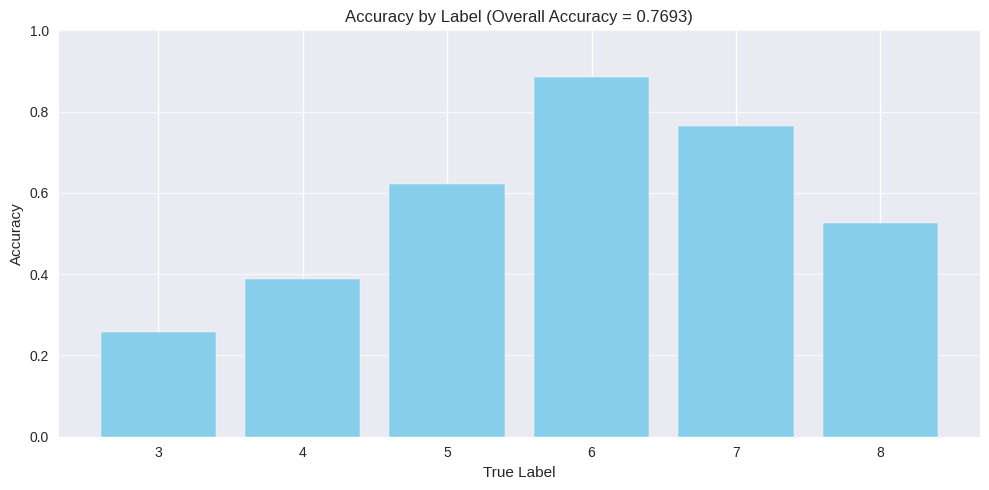

Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/power2_round_adjacent_accuracy_by_true_label.png


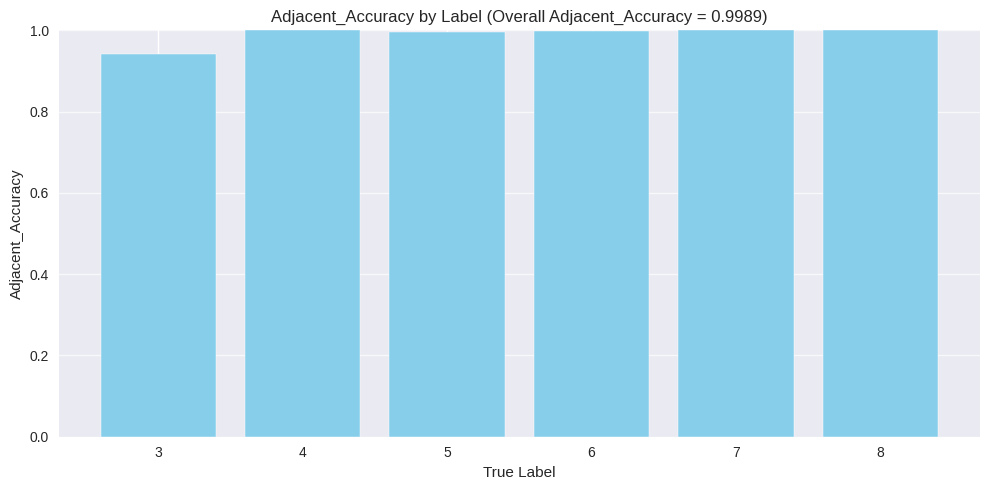

In [ ]:
# Per-label MAE, RMSE, accuracy and adjacent accuracy for every power and conversion
metrics_to_plot = ["MAE", "RMSE", "Accuracy", "Adjacent_Accuracy"]

for power in sorted(combined_label_per_label["Power"].unique()):
    for rounding_method in sorted(combined_label_per_label["Rounding_Method"].unique()):

        per_label_subset = combined_label_per_label[
            (combined_label_per_label["Power"] == power) &
            (combined_label_per_label["Rounding_Method"] == rounding_method)
        ].copy()

        overall_subset = combined_label_overall[
            (combined_label_overall["Power"] == power) &
            (combined_label_overall["Rounding_Method"] == rounding_method)
        ].copy()

        if per_label_subset.empty or overall_subset.empty:
            continue

        for metric in metrics_to_plot:

            if metric not in per_label_subset.columns:
                continue

            overall_value = overall_subset[metric].iloc[0]

            y_max = 1 if metric in ["Accuracy", "Adjacent_Accuracy"] else None

            plot_metric_by_label_style(
                per_label_df=per_label_subset,
                label_col="True_Heatmap_Label",
                metric_col=metric,
                overall_value=overall_value,
                output_folder=label_heatmap_output_folder,
                save_name=f"power{power}_{rounding_method}_{metric.lower()}_by_true_label",
                title_prefix=metric,
                xlabel="True Label",
                ylabel=metric,
                y_max=y_max
            )

Bias per true label isolates the direction of the error: a positive bar means the predicted heatmap assigns a higher label than the ground truth. After the function definition, the first two cells show IDW powers 1 and 2 with rounding, and the third repeats every combination of power and conversion and stacks the results in one table. Flooring and ceiling produce the same errors with the labels shifted by one, because both surfaces shift together except at exact integers and at the clipping limits.

In [ ]:
# Bias per true heatmap label
# GT interpolated heatmap vs predicted interpolated heatmap
def plot_bias_per_heatmap_label(
    pred_csv,
    gt_csv,
    rounding="round",
    output_folder=None,
    save_name="bias_per_heatmap_label",
    coord_round=10,
    valid_label_min=3,
    valid_label_max=8,
    use_cluster=True,
    show_plot=True
):
    """
    Plots prediction bias per true heatmap label.

    This compares a predicted interpolated heatmap to a GT interpolated heatmap.

    Bias is calculated as:

        Label_Error = Label_Pred - Label_GT

    Negative bias means underestimation.
    Positive bias means overestimation.

    Parameters
    ----------
    pred_csv : str
        Path to predicted interpolated heatmap CSV.
        Expected columns:
        - Latitude
        - Longitude
        - Interpolated
        - Cluster

    gt_csv : str
        Path to GT interpolated heatmap CSV.
        Expected columns:
        - Latitude
        - Longitude
        - Interpolated
        - Cluster

    rounding : str
        One of:
        - "floor"
        - "round"
        - "ceil"

    output_folder : str or None
        Folder to save table and plot.

    save_name : str
        Base name for saved outputs.

    coord_round : int
        Number of decimals for coordinate rounding before merge.

    valid_label_min, valid_label_max : int
        Label range after discretization.

    use_cluster : bool
        If True, merge on rounded coordinates and Cluster.

    show_plot : bool
        Whether to display the plot.

    Returns
    -------
    bias_per_label_df : pandas.DataFrame
        Bias summary by true heatmap label.

    merged : pandas.DataFrame
        Full grid-cell comparison table.
    """

    assert rounding in ["floor", "ceil", "round"], "rounding must be 'floor', 'ceil', or 'round'"

    # 1. Load CSVs
    pred_df = pd.read_csv(pred_csv)
    gt_df = pd.read_csv(gt_csv)

    pred_df.columns = pred_df.columns.str.strip()
    gt_df.columns = gt_df.columns.str.strip()

    print("Pred CSV:", pred_csv)
    print("Pred shape:", pred_df.shape)

    print("\nGT CSV:", gt_csv)
    print("GT shape:", gt_df.shape)

    required_cols = ["Latitude", "Longitude", "Interpolated"]

    if use_cluster:
        required_cols.append("Cluster")

    for name, df in [("Pred", pred_df), ("GT", gt_df)]:
        missing_cols = [col for col in required_cols if col not in df.columns]

        if missing_cols:
            raise ValueError(
                f"{name} CSV missing required columns: {missing_cols}\n"
                f"Available columns: {list(df.columns)}"
            )

    # 2. Clean numeric columns and create rounded coordinates
    for df in [pred_df, gt_df]:
        df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
        df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")
        df["Interpolated"] = pd.to_numeric(df["Interpolated"], errors="coerce")

        if use_cluster:
            df["Cluster"] = pd.to_numeric(df["Cluster"], errors="coerce")

        df.dropna(subset=required_cols, inplace=True)

        if use_cluster:
            df["Cluster"] = df["Cluster"].astype(int)

        df["Latitude_round"] = df["Latitude"].round(coord_round)
        df["Longitude_round"] = df["Longitude"].round(coord_round)

    # 3. Prepare merge
    pred_cols = [
        "Latitude_round",
        "Longitude_round",
        "Latitude",
        "Longitude",
        "Interpolated"
    ]

    gt_cols = [
        "Latitude_round",
        "Longitude_round",
        "Latitude",
        "Longitude",
        "Interpolated"
    ]

    merge_cols = ["Latitude_round", "Longitude_round"]

    if use_cluster:
        pred_cols.append("Cluster")
        gt_cols.append("Cluster")
        merge_cols.append("Cluster")

    pred_small = pred_df[pred_cols].copy()
    gt_small = gt_df[gt_cols].copy()

    pred_small = pred_small.rename(
        columns={
            "Latitude": "Latitude_Predgrid",
            "Longitude": "Longitude_Predgrid",
            "Interpolated": "Interpolated_pred"
        }
    )

    gt_small = gt_small.rename(
        columns={
            "Latitude": "Latitude_GTgrid",
            "Longitude": "Longitude_GTgrid",
            "Interpolated": "Interpolated_gt"
        }
    )

    merged = pred_small.merge(
        gt_small,
        on=merge_cols,
        how="inner"
    )

    print("\nMatched grid cells:", len(merged))

    if merged.empty:
        raise ValueError(
            "No matching grid cells found. "
            "Check that GT and predicted heatmaps were created with the same grid_res, buffer_m, and clusters."
        )

    merged["Latitude"] = merged["Latitude_GTgrid"]
    merged["Longitude"] = merged["Longitude_GTgrid"]

    # 4. Discretize interpolated values
    def discretize(values, method):
        values = np.asarray(values, dtype=float)

        if method == "floor":
            labels = np.floor(values)
        elif method == "ceil":
            labels = np.ceil(values)
        else:
            labels = np.rint(values)

        labels = labels.astype(int)
        labels = np.clip(labels, valid_label_min, valid_label_max)

        return labels

    merged["Label_pred"] = discretize(
        merged["Interpolated_pred"],
        rounding
    )

    merged["Label_gt"] = discretize(
        merged["Interpolated_gt"],
        rounding
    )

    # 5. Calculate label error
    merged["Label_Error"] = merged["Label_pred"] - merged["Label_gt"]
    merged["Label_Absolute_Error"] = merged["Label_Error"].abs()

    merged["Error_Direction"] = np.where(
        merged["Label_Error"] > 0,
        "Overestimate",
        np.where(merged["Label_Error"] < 0, "Underestimate", "Exact")
    )

    # 6. Bias per true label
    bias_per_label_df = (
        merged
        .groupby("Label_gt")
        .agg(
            N_Grid_Cells=("Label_Error", "size"),
            Bias=("Label_Error", "mean"),
            MAE=("Label_Absolute_Error", "mean"),
            RMSE=("Label_Error", lambda x: np.sqrt(np.mean(x ** 2))),
            Accuracy=("Label_Error", lambda x: (x == 0).mean()),
            Adjacent_Accuracy=("Label_Absolute_Error", lambda x: (x <= 1).mean()),
            Overestimate_Rate=("Label_Error", lambda x: (x > 0).mean()),
            Underestimate_Rate=("Label_Error", lambda x: (x < 0).mean()),
            Median_Error=("Label_Error", "median"),
            Min_Error=("Label_Error", "min"),
            Max_Error=("Label_Error", "max")
        )
        .reset_index()
        .rename(columns={"Label_gt": "True_Heatmap_Label"})
        .sort_values("True_Heatmap_Label")
        .reset_index(drop=True)
    )

    print("\nBias per true heatmap label:")
    display(bias_per_label_df)

    # 7. Save table
    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        table_path = os.path.join(
            output_folder,
            f"{save_name}_{rounding}_bias_per_true_label.csv"
        )

        merged_path = os.path.join(
            output_folder,
            f"{save_name}_{rounding}_label_grid_errors.csv"
        )

        bias_per_label_df.to_csv(table_path, index=False)
        merged.to_csv(merged_path, index=False)

        print("\nSaved tables:")
        print(table_path)
        print(merged_path)

    # 8. Plot
    plt.style.use("seaborn-v0_8")

    fig, ax = plt.subplots(figsize=(10, 6))

    labels = bias_per_label_df["True_Heatmap_Label"].astype(int)
    values = bias_per_label_df["Bias"]

    ax.bar(
        labels,
        values,
        color="skyblue",
        edgecolor="black"
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2
    )

    ax.set_xlabel("Ground Truth Heatmap Label")
    ax.set_ylabel("Mean Label Error / Bias\n(Predicted Label - GT Label)")
    ax.set_title(f"Prediction Bias per Heatmap Label ({rounding})")
    ax.set_xticks(labels)
    ax.grid(True, axis="y", alpha=0.3)

    fig.tight_layout()

    if output_folder is not None:
        plot_path = os.path.join(
            output_folder,
            f"{save_name}_{rounding}_bias_per_true_label.png"
        )

        fig.savefig(plot_path, dpi=300, bbox_inches="tight")
        print("Saved plot:", plot_path)

    if show_plot:
        plt.show()
    else:
        plt.close()

    return bias_per_label_df, merged

Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power1_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power1_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Bias per true heatmap label:


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error
0,3,14,1.000000,1.000000,1.133893,0.142857,0.857143,0.857143,0.000000,1.0,0,2
1,4,480,0.783333,0.783333,0.885061,0.216667,1.000000,0.783333,0.000000,1.0,0,1
2,5,46853,0.733763,0.733763,0.857646,0.266835,0.999701,0.733165,0.000000,1.0,0,3
3,6,77944,0.128259,0.129927,0.360560,0.870112,0.999962,0.129054,0.000834,0.0,-1,2
4,7,144069,-0.136657,0.136657,0.369671,0.863343,1.000000,0.000000,0.136657,0.0,-1,0
5,8,640,-0.765625,0.765625,0.875000,0.234375,1.000000,0.000000,0.765625,-1.0,-1,0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_round_bias_per_true_label.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_round_label_grid_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_round_bias_per_true_label.png


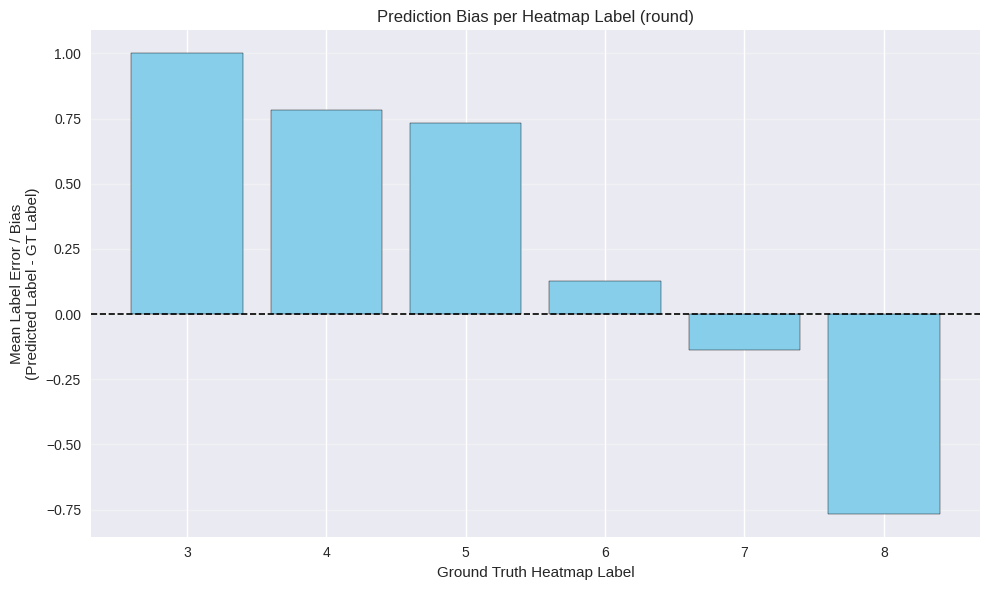

In [ ]:
heatmap_output_folder = TEST_HEATMAP_DIR
label_bias_output_folder = LABEL_BIAS_DIR

pred_power1_csv = os.path.join(
    heatmap_output_folder,
    "pred_test_weighted_average_idw_power1_heatmap.csv"
)

gt_power1_csv = os.path.join(
    heatmap_output_folder,
    "gt_test_weighted_average_idw_power1_heatmap.csv"
)

bias_power1_round, merged_bias_power1_round = plot_bias_per_heatmap_label(
    pred_csv=pred_power1_csv,
    gt_csv=gt_power1_csv,
    rounding="round",
    output_folder=label_bias_output_folder,
    save_name="weighted_average_idw_power1_gt_vs_pred",
    coord_round=10,
    valid_label_min=3,
    valid_label_max=8,
    use_cluster=True,
    show_plot=True
)

Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power2_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power2_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Bias per true heatmap label:


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error
0,3,759,0.802372,0.802372,0.959661,0.256917,0.940711,0.743083,0.000000,1.0,0,2
1,4,3937,0.611379,0.611379,0.781907,0.388621,1.000000,0.611379,0.000000,1.0,0,1
2,5,35344,0.384818,0.386063,0.642693,0.622935,0.995501,0.376443,0.000622,0.0,-1,3
3,6,84410,0.110165,0.116894,0.345070,0.884196,0.998910,0.112439,0.003365,0.0,-1,2
4,7,137170,-0.235146,0.235146,0.484919,0.764854,1.000000,0.000000,0.235146,0.0,-1,0
5,8,8380,-0.474105,0.474105,0.688899,0.526134,0.999761,0.000000,0.473866,0.0,-2,0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_round_bias_per_true_label.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_round_label_grid_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_round_bias_per_true_label.png


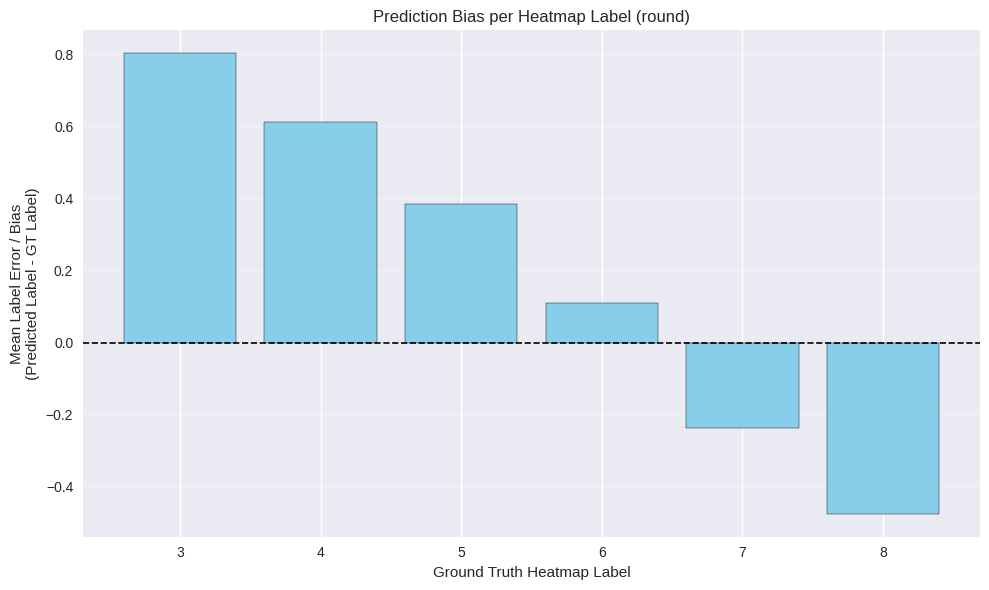

In [ ]:
pred_power2_csv = os.path.join(
    heatmap_output_folder,
    "pred_test_weighted_average_idw_power2_heatmap.csv"
)

gt_power2_csv = os.path.join(
    heatmap_output_folder,
    "gt_test_weighted_average_idw_power2_heatmap.csv"
)

bias_power2_round, merged_bias_power2_round = plot_bias_per_heatmap_label(
    pred_csv=pred_power2_csv,
    gt_csv=gt_power2_csv,
    rounding="round",
    output_folder=label_bias_output_folder,
    save_name="weighted_average_idw_power2_gt_vs_pred",
    coord_round=10,
    valid_label_min=3,
    valid_label_max=8,
    use_cluster=True,
    show_plot=True
)


Power 1 | Rounding: floor
Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power1_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power1_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Bias per true heatmap label:


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error
0,3,90,0.777778,0.777778,0.881917,0.222222,1.000000,0.777778,0.000000,1.0,0,1
1,4,2975,0.749580,0.749580,0.865783,0.250420,1.000000,0.749580,0.000000,1.0,0,1
2,5,86386,0.016693,0.017410,0.150012,0.985136,0.997453,0.014505,0.000359,0.0,-1,2
3,6,140821,-0.010190,0.014224,0.119263,0.985776,1.000000,0.002017,0.012207,0.0,-1,1
4,7,39728,-0.887384,0.887384,0.942011,0.112616,1.000000,0.000000,0.887384,-1.0,-1,0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_floor_bias_per_true_label.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_floor_label_grid_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_floor_bias_per_true_label.png


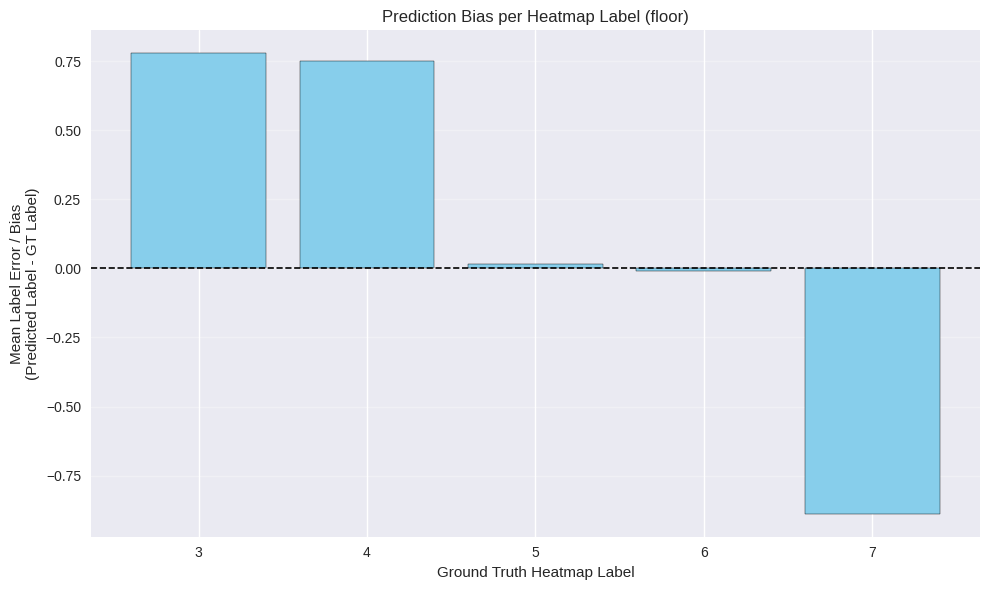


Power 1 | Rounding: round
Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power1_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power1_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Bias per true heatmap label:


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error
0,3,14,1.000000,1.000000,1.133893,0.142857,0.857143,0.857143,0.000000,1.0,0,2
1,4,480,0.783333,0.783333,0.885061,0.216667,1.000000,0.783333,0.000000,1.0,0,1
2,5,46853,0.733763,0.733763,0.857646,0.266835,0.999701,0.733165,0.000000,1.0,0,3
3,6,77944,0.128259,0.129927,0.360560,0.870112,0.999962,0.129054,0.000834,0.0,-1,2
4,7,144069,-0.136657,0.136657,0.369671,0.863343,1.000000,0.000000,0.136657,0.0,-1,0
5,8,640,-0.765625,0.765625,0.875000,0.234375,1.000000,0.000000,0.765625,-1.0,-1,0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_round_bias_per_true_label.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_round_label_grid_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_round_bias_per_true_label.png


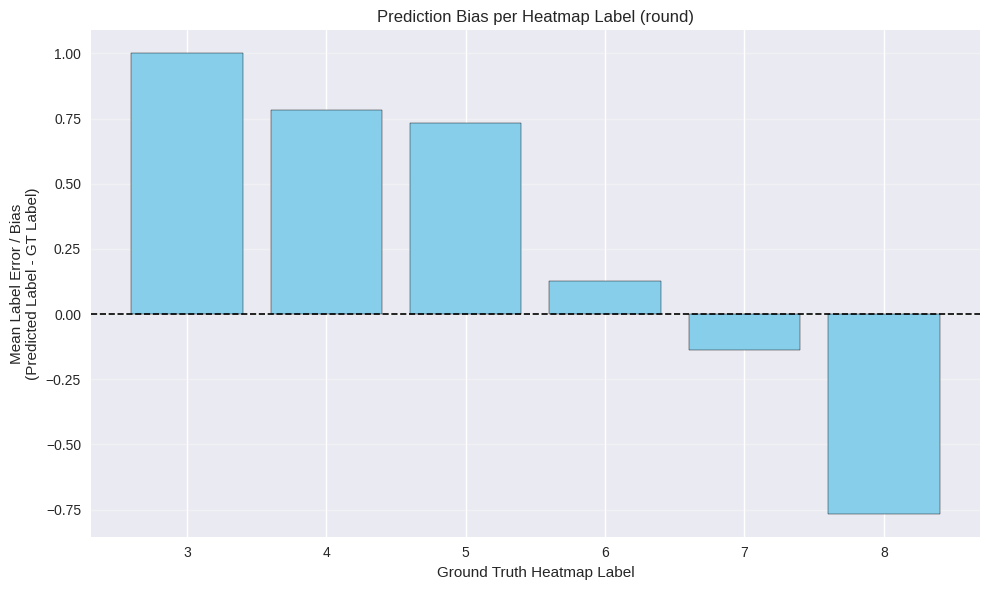


Power 1 | Rounding: ceil
Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power1_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power1_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Bias per true heatmap label:


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error
0,4,90,0.777778,0.777778,0.881917,0.222222,1.000000,0.777778,0.000000,1.0,0,1
1,5,2975,0.749580,0.749580,0.865783,0.250420,1.000000,0.749580,0.000000,1.0,0,1
2,6,86386,0.016693,0.017410,0.150012,0.985136,0.997453,0.014505,0.000359,0.0,-1,2
3,7,140821,-0.010190,0.014224,0.119263,0.985776,1.000000,0.002017,0.012207,0.0,-1,1
4,8,39728,-0.887384,0.887384,0.942011,0.112616,1.000000,0.000000,0.887384,-1.0,-1,0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_ceil_bias_per_true_label.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_ceil_label_grid_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power1_gt_vs_pred_ceil_bias_per_true_label.png


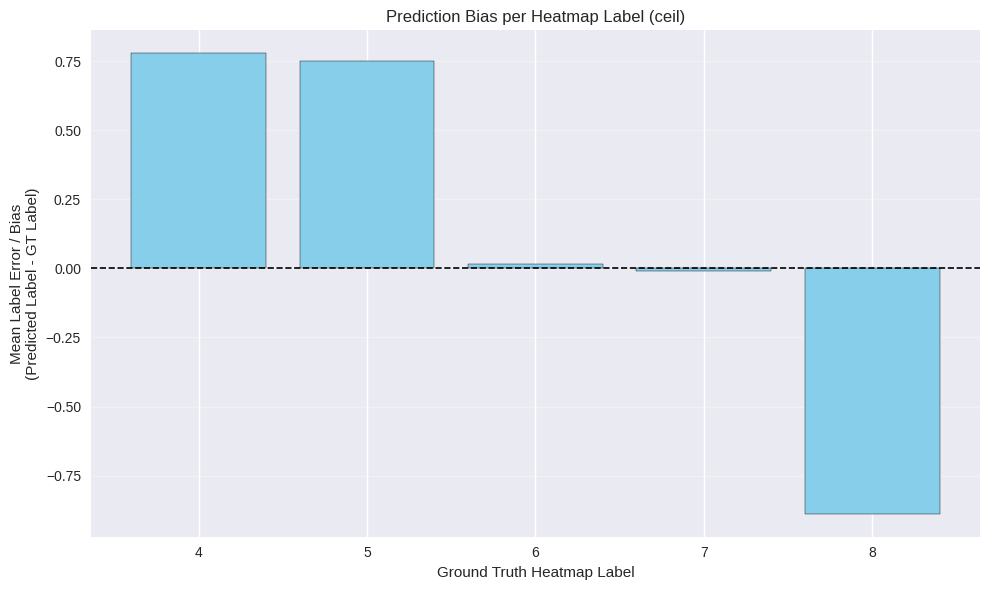


Power 2 | Rounding: floor
Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power2_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power2_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Bias per true heatmap label:


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error
0,3,2180,0.608716,0.608716,0.780202,0.391284,1.000000,0.608716,0.000000,1.0,0,1
1,4,8810,0.588422,0.588422,0.767087,0.411578,1.000000,0.588422,0.000000,1.0,0,1
2,5,73968,0.110183,0.123513,0.398326,0.894062,0.982425,0.099273,0.006665,0.0,-1,2
3,6,127753,-0.071364,0.126784,0.356067,0.873216,1.000000,0.027710,0.099074,0.0,-1,1
4,7,57289,-0.731973,0.731973,0.855758,0.268202,0.999825,0.000000,0.731798,-1.0,-2,0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_floor_bias_per_true_label.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_floor_label_grid_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_floor_bias_per_true_label.png


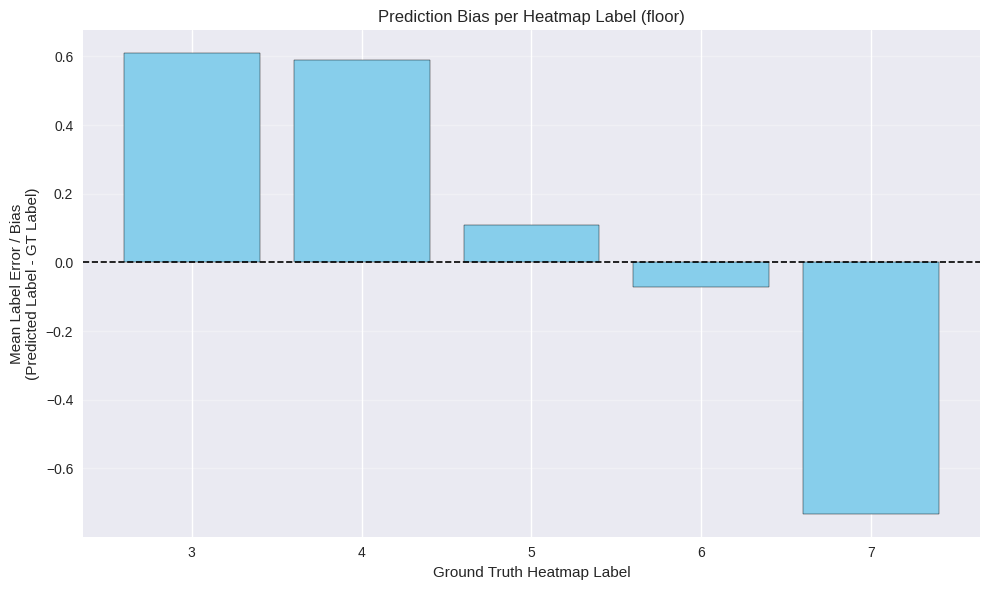


Power 2 | Rounding: round
Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power2_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power2_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Bias per true heatmap label:


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error
0,3,759,0.802372,0.802372,0.959661,0.256917,0.940711,0.743083,0.000000,1.0,0,2
1,4,3937,0.611379,0.611379,0.781907,0.388621,1.000000,0.611379,0.000000,1.0,0,1
2,5,35344,0.384818,0.386063,0.642693,0.622935,0.995501,0.376443,0.000622,0.0,-1,3
3,6,84410,0.110165,0.116894,0.345070,0.884196,0.998910,0.112439,0.003365,0.0,-1,2
4,7,137170,-0.235146,0.235146,0.484919,0.764854,1.000000,0.000000,0.235146,0.0,-1,0
5,8,8380,-0.474105,0.474105,0.688899,0.526134,0.999761,0.000000,0.473866,0.0,-2,0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_round_bias_per_true_label.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_round_label_grid_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_round_bias_per_true_label.png


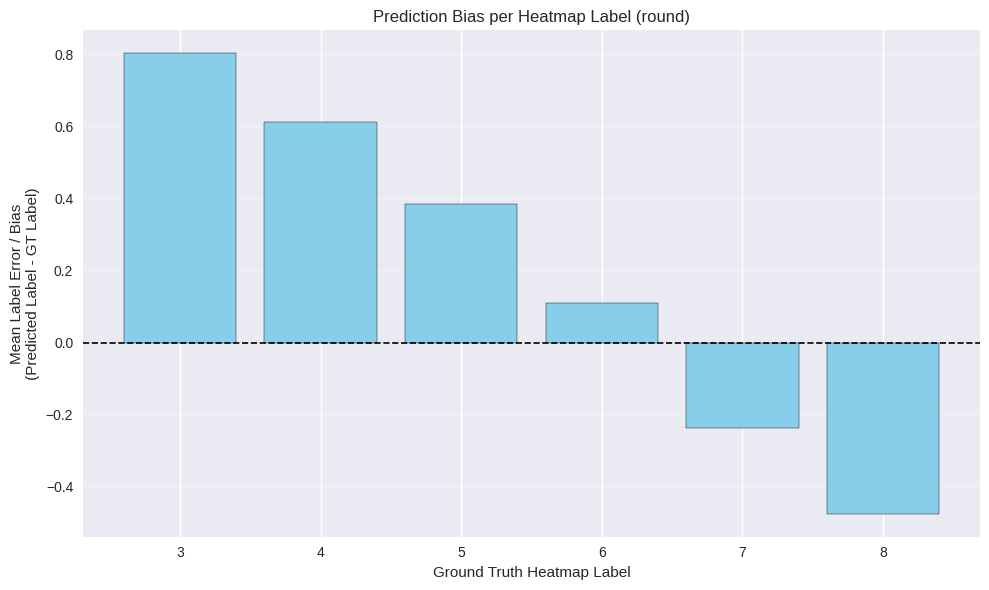


Power 2 | Rounding: ceil
Pred CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power2_heatmap.csv
Pred shape: (270000, 9)

GT CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power2_heatmap.csv
GT shape: (270000, 9)

Matched grid cells: 270000

Bias per true heatmap label:


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error
0,4,2180,0.608716,0.608716,0.780202,0.391284,1.000000,0.608716,0.000000,1.0,0,1
1,5,8810,0.588422,0.588422,0.767087,0.411578,1.000000,0.588422,0.000000,1.0,0,1
2,6,73968,0.110183,0.123513,0.398326,0.894062,0.982425,0.099273,0.006665,0.0,-1,2
3,7,127753,-0.071364,0.126784,0.356067,0.873216,1.000000,0.027710,0.099074,0.0,-1,1
4,8,57289,-0.731973,0.731973,0.855758,0.268202,0.999825,0.000000,0.731798,-1.0,-2,0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_ceil_bias_per_true_label.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_ceil_label_grid_errors.csv
Saved plot: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/weighted_average_idw_power2_gt_vs_pred_ceil_bias_per_true_label.png


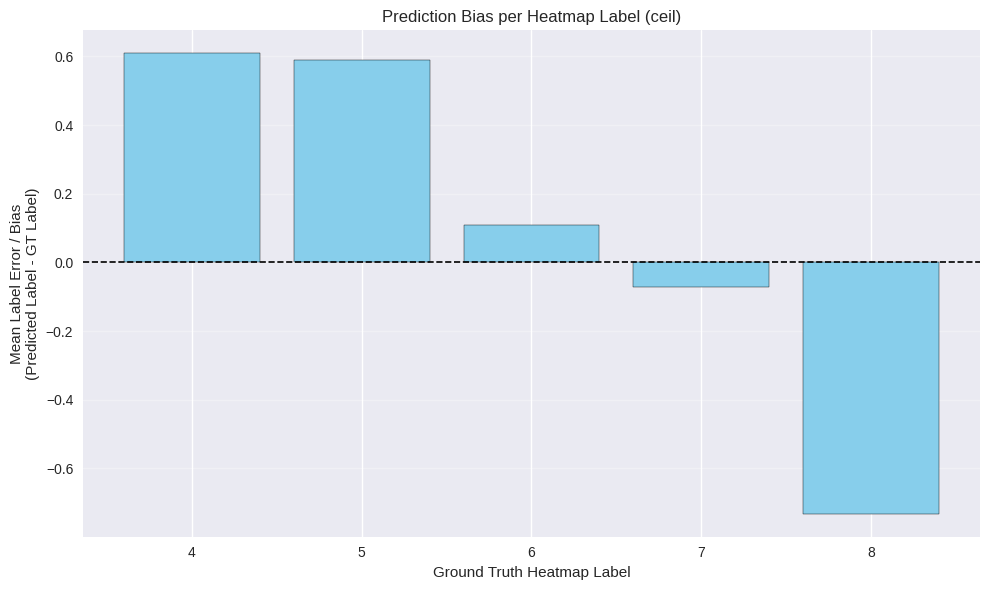


Saved combined bias table:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/label_level_heatmap_error/bias_plots/combined_bias_per_true_heatmap_label.csv


,True_Heatmap_Label,N_Grid_Cells,Bias,MAE,RMSE,Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error,Power,Rounding_Method
0,3,90,0.777778,0.777778,0.881917,0.222222,1.000000,0.777778,0.000000,1.0,0,1,1,floor
1,4,2975,0.749580,0.749580,0.865783,0.250420,1.000000,0.749580,0.000000,1.0,0,1,1,floor
2,5,86386,0.016693,0.017410,0.150012,0.985136,0.997453,0.014505,0.000359,0.0,-1,2,1,floor
3,6,140821,-0.010190,0.014224,0.119263,0.985776,1.000000,0.002017,0.012207,0.0,-1,1,1,floor
4,7,39728,-0.887384,0.887384,0.942011,0.112616,1.000000,0.000000,0.887384,-1.0,-1,0,1,floor
5,3,14,1.000000,1.000000,1.133893,0.142857,0.857143,0.857143,0.000000,1.0,0,2,1,round
6,4,480,0.783333,0.783333,0.885061,0.216667,1.000000,0.783333,0.000000,1.0,0,1,1,round
7,5,46853,0.733763,0.733763,0.857646,0.266835,0.999701,0.733165,0.000000,1.0,0,3,1,round
8,6,77944,0.128259,0.129927,0.360560,0.870112,0.999962,0.129054,0.000834,0.0,-1,2,1,round
9,7,144069,-0.136657,0.136657,0.369671,0.863343,1.000000,0.000000,0.136657,0.0,-1,0,1,round


In [ ]:
all_bias_tables = []

for power in [1, 2]:

    pred_csv = os.path.join(
        heatmap_output_folder,
        f"pred_test_weighted_average_idw_power{power}_heatmap.csv"
    )

    gt_csv = os.path.join(
        heatmap_output_folder,
        f"gt_test_weighted_average_idw_power{power}_heatmap.csv"
    )

    for rounding in ["floor", "round", "ceil"]:

        print("\n" + "=" * 80)
        print(f"Power {power} | Rounding: {rounding}")
        print("=" * 80)

        bias_df, merged_df = plot_bias_per_heatmap_label(
            pred_csv=pred_csv,
            gt_csv=gt_csv,
            rounding=rounding,
            output_folder=label_bias_output_folder,
            save_name=f"weighted_average_idw_power{power}_gt_vs_pred",
            coord_round=10,
            valid_label_min=3,
            valid_label_max=8,
            use_cluster=True,
            show_plot=True
        )

        bias_df["Power"] = power
        bias_df["Rounding_Method"] = rounding

        all_bias_tables.append(bias_df)

combined_bias_per_label = pd.concat(all_bias_tables, ignore_index=True)

combined_bias_path = os.path.join(
    label_bias_output_folder,
    "combined_bias_per_true_heatmap_label.csv"
)

combined_bias_per_label.to_csv(combined_bias_path, index=False)

print("\nSaved combined bias table:")
print(combined_bias_path)

display(combined_bias_per_label)

The bias tables show the same structure for both powers. With rounding and IDW power 1, cells whose ground-truth label is 3, 4 or 5 were assigned higher labels by the predicted heatmap (bias +1.00, +0.78 and +0.73), and cells with ground-truth label 7 or 8 lower ones (−0.14 and −0.77); label 6 was nearly unbiased (+0.13). Power 2 reduced the bias at both ends (label 5: +0.38, label 8: −0.47). Labels 3, 4 and 8 cover few cells (14, 480 and 640 of 270,000 with power 1), so their per-label values rest on small areas.

The next two cells list the range of the ground-truth and predicted test heatmaps (IDW power 1) and the number of cells that fall in each label under each conversion. They explain why some labels are rare in the tables above.

In [ ]:
gt_csv = os.path.join(TEST_HEATMAP_DIR, "gt_test_weighted_average_idw_power1_heatmap.csv")

gt_df = pd.read_csv(gt_csv)

print(gt_df["Interpolated"].describe())

gt_df["floor_label"] = np.floor(gt_df["Interpolated"]).astype(int)
gt_df["round_label"] = np.rint(gt_df["Interpolated"]).astype(int)
gt_df["ceil_label"] = np.ceil(gt_df["Interpolated"]).astype(int)

print("\nFloor label counts:")
print(gt_df["floor_label"].value_counts().sort_index())

print("\nRound label counts:")
print(gt_df["round_label"].value_counts().sort_index())

print("\nCeil label counts:")
print(gt_df["ceil_label"].value_counts().sort_index())

count    270000.000000
mean          6.353459
std           0.688123
min           3.203808
25%           5.558017
50%           6.578435
75%           6.977189
max           7.941865
Name: Interpolated, dtype: float64

Floor label counts:
floor_label
3        90
4      2975
5     86386
6    140821
7     39728
Name: count, dtype: int64

Round label counts:
round_label
3        14
4       480
5     46853
6     77944
7    144069
8       640
Name: count, dtype: int64

Ceil label counts:
ceil_label
4        90
5      2975
6     86386
7    140821
8     39728
Name: count, dtype: int64


In [ ]:
pred_csv = os.path.join(TEST_HEATMAP_DIR, "pred_test_weighted_average_idw_power1_heatmap.csv")

pred_df = pd.read_csv(pred_csv)

print(pred_df["Interpolated"].describe())

pred_df["floor_label"] = np.floor(pred_df["Interpolated"]).astype(int)
pred_df["round_label"] = np.rint(pred_df["Interpolated"]).astype(int)
pred_df["ceil_label"] = np.ceil(pred_df["Interpolated"]).astype(int)

print("\nPred floor label counts:")
print(pred_df["floor_label"].value_counts().sort_index())

print("\nPred round label counts:")
print(pred_df["round_label"].value_counts().sort_index())

print("\nPred ceil label counts:")
print(pred_df["ceil_label"].value_counts().sort_index())

count    270000.000000
mean          6.305538
std           0.520050
min           3.480727
25%           5.710707
50%           6.500324
75%           6.748678
max           7.771750
Name: Interpolated, dtype: float64

Pred floor label counts:
floor_label
3        20
4       846
5     89051
6    175105
7      4978
Name: count, dtype: int64

Pred round label counts:
round_label
3         2
4       114
5     12945
6    121845
7    134927
8       167
Name: count, dtype: int64

Pred ceil label counts:
ceil_label
4        20
5       846
6     89051
7    175105
8      4978
Name: count, dtype: int64


The ground-truth test heatmap (IDW power 1) ranges from 3.20 to 7.94 with a mean of 6.35; the predicted heatmap ranges from 3.48 to 7.77 with a mean of 6.31 and a smaller spread (standard deviation 0.52 against 0.69). After rounding, most cells fall in labels 5 to 7 in both surfaces, and the extremes are rare: label 8 covers 640 ground-truth cells but only 167 predicted cells, and labels 3 and 4 cover 14 and 480 ground-truth cells against 2 and 114 predicted cells. The narrower range of the predicted surface is consistent with the positive bias at low labels and the negative bias at high labels.

The label-level analysis reported in the manuscript uses the full-dataset IDW power 5 heatmaps of Section 8. It is computed with a second implementation, `evaluate_heatmap_error`, which also reports the continuous error of each cluster next to the label error. The first cell is a supplementary run for IDW power 1 with ceiling conversion; the second is the IDW power 5 run with rounding, whose per-label MAE is plotted in the third cell.

In [ ]:
# Define and run evaluate_heatmap_error()
# For FULL-DATASET GT vs predicted interpolated heatmaps

# 1. Define heatmap error evaluation function
def evaluate_heatmap_error(
    interp_pred,
    interp_gt,
    rounding_method="ceil",
    cluster_id=None,
    pred_value_col=None,
    gt_value_col=None
):
    """
    Evaluates label-level error between predicted and GT interpolated heatmaps.

    Parameters
    ----------
    interp_pred : pandas.DataFrame
        Predicted interpolated heatmap grid.

    interp_gt : pandas.DataFrame
        Ground-truth interpolated heatmap grid.

    rounding_method : str
        One of:
        - "ceil"
        - "floor"
        - "round"
        - "none"

    cluster_id : int or None
        If None, evaluates all clusters.
        If given, evaluates only that cluster.

    pred_value_col, gt_value_col : str or None
        Optional manual value-column names.
        If None, the function tries to detect the interpolated value column.

    Returns
    -------
    comparison_df : pandas.DataFrame
        Grid-cell-level comparison table.

    overall_metrics_df : pandas.DataFrame
        Overall heatmap label-error metrics.

    per_label_metrics_df : pandas.DataFrame
        Metrics grouped by true heatmap label.

    per_cluster_metrics_df : pandas.DataFrame
        Metrics grouped by cluster.
    """

    interp_pred = interp_pred.copy()
    interp_gt = interp_gt.copy()

    interp_pred.columns = interp_pred.columns.str.strip()
    interp_gt.columns = interp_gt.columns.str.strip()

    # Helper: detect interpolated value column
    def detect_value_col(df, name):
        possible_cols = [
            "Interpolated",
            "Interpolated_Value",
            "Value",
            "Heatmap_Value",
            "Weighted Average",
            "Weighted Average_GT",
            "Weighted Average_Pred"
        ]

        for col in possible_cols:
            if col in df.columns:
                return col

        for col in df.columns:
            col_lower = col.lower()
            if "interpolated" in col_lower or "heatmap" in col_lower:
                return col

        raise ValueError(
            f"Could not detect interpolated value column in {name} dataframe.\n"
            f"Available columns: {df.columns.tolist()}"
        )

    if pred_value_col is None:
        pred_value_col = detect_value_col(interp_pred, "predicted")

    if gt_value_col is None:
        gt_value_col = detect_value_col(interp_gt, "GT")

    print("Detected predicted value column:", pred_value_col)
    print("Detected GT value column:", gt_value_col)

    # Required columns
    required_cols = ["Latitude", "Longitude", "Cluster"]

    for name, df in [("Pred", interp_pred), ("GT", interp_gt)]:
        missing = [c for c in required_cols if c not in df.columns]
        if missing:
            raise ValueError(
                f"{name} heatmap missing required columns: {missing}\n"
                f"Available columns: {df.columns.tolist()}"
            )

    # Optional cluster filtering
    if cluster_id is not None:
        interp_pred = interp_pred[interp_pred["Cluster"] == cluster_id].copy()
        interp_gt = interp_gt[interp_gt["Cluster"] == cluster_id].copy()

        print(f"\nFiltering to cluster_id = {cluster_id}")
        print("Pred rows after filter:", len(interp_pred))
        print("GT rows after filter:", len(interp_gt))

    # Prepare merge
    pred_small = interp_pred[
        ["Latitude", "Longitude", "Cluster", pred_value_col]
    ].copy()

    gt_small = interp_gt[
        ["Latitude", "Longitude", "Cluster", gt_value_col]
    ].copy()

    pred_small = pred_small.rename(columns={pred_value_col: "Pred_Interpolated"})
    gt_small = gt_small.rename(columns={gt_value_col: "GT_Interpolated"})

    for df in [pred_small, gt_small]:
        df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
        df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")
        df["Cluster"] = pd.to_numeric(df["Cluster"], errors="coerce")

    pred_small["Pred_Interpolated"] = pd.to_numeric(
        pred_small["Pred_Interpolated"],
        errors="coerce"
    )

    gt_small["GT_Interpolated"] = pd.to_numeric(
        gt_small["GT_Interpolated"],
        errors="coerce"
    )

    pred_small = pred_small.dropna(
        subset=["Latitude", "Longitude", "Cluster", "Pred_Interpolated"]
    ).copy()

    gt_small = gt_small.dropna(
        subset=["Latitude", "Longitude", "Cluster", "GT_Interpolated"]
    ).copy()

    # Match grid cells on rounded coordinates
    pred_small["Latitude_round"] = pred_small["Latitude"].round(10)
    pred_small["Longitude_round"] = pred_small["Longitude"].round(10)

    gt_small["Latitude_round"] = gt_small["Latitude"].round(10)
    gt_small["Longitude_round"] = gt_small["Longitude"].round(10)

    comparison_df = gt_small.merge(
        pred_small,
        on=["Latitude_round", "Longitude_round", "Cluster"],
        suffixes=("_GTgrid", "_Predgrid"),
        how="inner"
    )

    if comparison_df.empty:
        raise ValueError(
            "GT and predicted heatmap grids did not align.\n"
            "Make sure both were created with the same input CSV, buffer_m, grid_res, and cluster settings."
        )

    comparison_df["Latitude"] = comparison_df["Latitude_GTgrid"]
    comparison_df["Longitude"] = comparison_df["Longitude_GTgrid"]

    # Convert continuous interpolated values to labels
    def apply_rounding(x, method):
        if method == "ceil":
            return np.ceil(x)
        elif method == "floor":
            return np.floor(x)
        elif method == "round":
            return np.round(x)
        elif method == "none":
            return x
        else:
            raise ValueError(
                "rounding_method must be one of: 'ceil', 'floor', 'round', 'none'"
            )

    comparison_df["True_Heatmap_Label"] = apply_rounding(
        comparison_df["GT_Interpolated"],
        rounding_method
    )

    comparison_df["Pred_Heatmap_Label"] = apply_rounding(
        comparison_df["Pred_Interpolated"],
        rounding_method
    )

    # Keep labels within damage class range if rounded
    if rounding_method != "none":
        comparison_df["True_Heatmap_Label"] = comparison_df["True_Heatmap_Label"].clip(3, 8)
        comparison_df["Pred_Heatmap_Label"] = comparison_df["Pred_Heatmap_Label"].clip(3, 8)

        comparison_df["True_Heatmap_Label"] = comparison_df["True_Heatmap_Label"].astype(int)
        comparison_df["Pred_Heatmap_Label"] = comparison_df["Pred_Heatmap_Label"].astype(int)

    # Error columns
    comparison_df["Error"] = (
        comparison_df["Pred_Heatmap_Label"] -
        comparison_df["True_Heatmap_Label"]
    )

    comparison_df["Abs_Error"] = comparison_df["Error"].abs()
    comparison_df["Squared_Error"] = comparison_df["Error"] ** 2

    comparison_df["Exact"] = comparison_df["Error"] == 0
    comparison_df["Adjacent"] = comparison_df["Abs_Error"] <= 1
    comparison_df["Overestimate"] = comparison_df["Error"] > 0
    comparison_df["Underestimate"] = comparison_df["Error"] < 0

    # Also keep continuous heatmap error
    comparison_df["Continuous_Error"] = (
        comparison_df["Pred_Interpolated"] -
        comparison_df["GT_Interpolated"]
    )
    comparison_df["Continuous_Abs_Error"] = comparison_df["Continuous_Error"].abs()
    comparison_df["Continuous_Squared_Error"] = comparison_df["Continuous_Error"] ** 2

    # Overall metrics
    overall_metrics = {
        "Cluster_Filter": cluster_id if cluster_id is not None else "All",
        "Rounding_Method": rounding_method,
        "N_Grid_Cells": len(comparison_df),

        "Label_Accuracy": comparison_df["Exact"].mean(),
        "Adjacent_Accuracy": comparison_df["Adjacent"].mean(),
        "Label_MAE": comparison_df["Abs_Error"].mean(),
        "Label_RMSE": np.sqrt(comparison_df["Squared_Error"].mean()),
        "Label_Bias": comparison_df["Error"].mean(),
        "Median_Label_Error": comparison_df["Error"].median(),
        "Min_Label_Error": comparison_df["Error"].min(),
        "Max_Label_Error": comparison_df["Error"].max(),
        "Overestimate_Rate": comparison_df["Overestimate"].mean(),
        "Underestimate_Rate": comparison_df["Underestimate"].mean(),

        "Continuous_MAE": comparison_df["Continuous_Abs_Error"].mean(),
        "Continuous_RMSE": np.sqrt(comparison_df["Continuous_Squared_Error"].mean()),
        "Continuous_Bias": comparison_df["Continuous_Error"].mean(),
        "Continuous_Correlation_2D": comparison_df["GT_Interpolated"].corr(
            comparison_df["Pred_Interpolated"]
        )
    }

    overall_metrics_df = pd.DataFrame([overall_metrics])

    # Per true-label metrics
    per_label_rows = []

    for label, group in comparison_df.groupby("True_Heatmap_Label"):
        per_label_rows.append({
            "True_Heatmap_Label": label,
            "N_Grid_Cells": len(group),
            "Label_Bias": group["Error"].mean(),
            "Label_MAE": group["Abs_Error"].mean(),
            "Label_RMSE": np.sqrt(group["Squared_Error"].mean()),
            "Label_Accuracy": group["Exact"].mean(),
            "Adjacent_Accuracy": group["Adjacent"].mean(),
            "Overestimate_Rate": group["Overestimate"].mean(),
            "Underestimate_Rate": group["Underestimate"].mean(),
            "Median_Error": group["Error"].median(),
            "Min_Error": group["Error"].min(),
            "Max_Error": group["Error"].max(),
            "Rounding_Method": rounding_method
        })

    per_label_metrics_df = pd.DataFrame(per_label_rows)

    # Per-cluster metrics
    per_cluster_rows = []

    for cluster, group in comparison_df.groupby("Cluster"):
        per_cluster_rows.append({
            "Cluster": int(cluster),
            "N_Grid_Cells": len(group),
            "Label_Bias": group["Error"].mean(),
            "Label_MAE": group["Abs_Error"].mean(),
            "Label_RMSE": np.sqrt(group["Squared_Error"].mean()),
            "Label_Accuracy": group["Exact"].mean(),
            "Adjacent_Accuracy": group["Adjacent"].mean(),
            "Overestimate_Rate": group["Overestimate"].mean(),
            "Underestimate_Rate": group["Underestimate"].mean(),
            "Continuous_MAE": group["Continuous_Abs_Error"].mean(),
            "Continuous_RMSE": np.sqrt(group["Continuous_Squared_Error"].mean()),
            "Continuous_Bias": group["Continuous_Error"].mean(),
            "Continuous_Correlation_2D": group["GT_Interpolated"].corr(
                group["Pred_Interpolated"]
            ),
            "Rounding_Method": rounding_method
        })

    per_cluster_metrics_df = pd.DataFrame(per_cluster_rows)

    # Display
    print("\nOverall heatmap label-error metrics:")
    display(overall_metrics_df)

    print("\nPer true heatmap label metrics:")
    display(per_label_metrics_df)

    print("\nPer-cluster heatmap label-error metrics:")
    display(per_cluster_metrics_df)

    return comparison_df, overall_metrics_df, per_label_metrics_df, per_cluster_metrics_df


# 2. Find current full-dataset GT and predicted heatmap CSVs
heatmap_output_folder = HEATMAP_DIR

print("Heatmap folder exists:", os.path.exists(heatmap_output_folder))
print("Heatmap folder:", heatmap_output_folder)

if not os.path.exists(heatmap_output_folder):
    raise FileNotFoundError(f"Heatmap folder not found:\n{heatmap_output_folder}")


def find_heatmap_csv(dataset_type, power=1):
    expected_core = f"{dataset_type}_full_weighted_average_idw_power{power}_heatmap"

    all_csvs = glob.glob(
        os.path.join(heatmap_output_folder, "**", "*.csv"),
        recursive=True
    )

    candidates = []

    for path in all_csvs:
        filename = os.path.basename(path).lower()

        if expected_core.lower() not in filename:
            continue

        bad_words = [
            "comparison",
            "metrics",
            "per_cluster",
            "difference",
            "overall"
        ]

        if any(bad in filename for bad in bad_words):
            continue

        try:
            df_head = pd.read_csv(path, nrows=3)
            cols = [c.strip() for c in df_head.columns]

            has_latlon = "Latitude" in cols and "Longitude" in cols
            has_cluster = "Cluster" in cols
            has_interp = (
                "Interpolated" in cols or
                "Interpolated_Value" in cols or
                "Value" in cols or
                any("interpolated" in c.lower() for c in cols)
            )

            score = int(has_latlon) + int(has_cluster) + int(has_interp)

            candidates.append({
                "path": path,
                "filename": os.path.basename(path),
                "score": score,
                "columns": cols
            })

        except Exception:
            continue

    if len(candidates) == 0:
        print("\nAvailable CSV files:")
        for f in all_csvs:
            print(os.path.basename(f))

        raise FileNotFoundError(
            f"No {dataset_type.upper()} heatmap CSV found for power {power}.\n"
            f"Expected filename to contain:\n{expected_core}"
        )

    candidates_df = pd.DataFrame(candidates).sort_values(
        by="score",
        ascending=False
    )

    best_path = candidates_df.iloc[0]["path"]

    print(f"\nSelected {dataset_type.upper()} power {power} heatmap CSV:")
    print(best_path)
    print("Columns:", candidates_df.iloc[0]["columns"])

    return best_path


# 3. Load heatmaps and run evaluation
power = 1  # change to 2 if you want IDW power 2

gt_heatmap_csv = find_heatmap_csv("gt", power=power)
pred_heatmap_csv = find_heatmap_csv("pred", power=power)

interp_gt = pd.read_csv(gt_heatmap_csv)
interp_pred = pd.read_csv(pred_heatmap_csv)

comparison_df, overall_metrics_df, per_label_metrics_df, per_cluster_metrics_df = evaluate_heatmap_error(
    interp_pred=interp_pred,
    interp_gt=interp_gt,
    rounding_method="ceil",
    cluster_id=None
)

# 4. Save outputs
error_output_folder = HEATMAP_LABEL_ERROR_DIR

os.makedirs(error_output_folder, exist_ok=True)

save_prefix = f"full_weighted_average_idw_power{power}_ceil"

comparison_path = os.path.join(
    error_output_folder,
    f"{save_prefix}_grid_label_error.csv"
)

overall_path = os.path.join(
    error_output_folder,
    f"{save_prefix}_overall_label_error_metrics.csv"
)

per_label_path = os.path.join(
    error_output_folder,
    f"{save_prefix}_per_true_label_metrics.csv"
)

per_cluster_path = os.path.join(
    error_output_folder,
    f"{save_prefix}_per_cluster_label_error_metrics.csv"
)

comparison_df.to_csv(comparison_path, index=False)
overall_metrics_df.to_csv(overall_path, index=False)
per_label_metrics_df.to_csv(per_label_path, index=False)
per_cluster_metrics_df.to_csv(per_cluster_path, index=False)

print("\nSaved heatmap label-error outputs:")
print(comparison_path)
print(overall_path)
print(per_label_path)
print(per_cluster_path)

Heatmap folder exists: True
Heatmap folder: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps

Selected GT power 1 heatmap CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power1_heatmap.csv
Columns: ['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']

Selected PRED power 1 heatmap CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_full_weighted_average_idw_power1_heatmap.csv
Columns: ['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']
Detected predicted value column: Interpolated
Detected GT value column: Interpolated

Overall heatmap label-error metrics:


,Cluster_Filter,Rounding_Method,N_Grid_Cells,Label_Accuracy,Adjacent_Accuracy,Label_MAE,Label_RMSE,Label_Bias,Median_Label_Error,Min_Label_Error,Max_Label_Error,Overestimate_Rate,Underestimate_Rate,Continuous_MAE,Continuous_RMSE,Continuous_Bias,Continuous_Correlation_2D
0,All,ceil,720000,0.844656,0.99999,0.155354,0.394175,0.098562,0.0,-1,2,0.126949,0.028396,0.252741,0.325832,-0.057417,0.721831



Per true heatmap label metrics:


,True_Heatmap_Label,N_Grid_Cells,Label_Bias,Label_MAE,Label_RMSE,Label_Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error,Rounding_Method
0,4,4,1.000000,1.000000,1.224745,0.250000,0.750000,0.750000,0.000000,1.0,0,2,ceil
1,5,137,0.795620,0.795620,0.891976,0.204380,1.000000,0.795620,0.000000,1.0,0,1,ceil
2,6,74101,0.481748,0.481748,0.694197,0.518333,0.999919,0.481667,0.000000,0.0,0,2,ceil
3,7,527141,0.098017,0.112928,0.336048,0.887072,1.000000,0.105473,0.007455,0.0,-1,1,ceil
4,8,118617,-0.139230,0.139230,0.373135,0.860770,1.000000,0.000000,0.139230,0.0,-1,0,ceil



Per-cluster heatmap label-error metrics:


,Cluster,N_Grid_Cells,Label_Bias,Label_MAE,Label_RMSE,Label_Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Continuous_MAE,Continuous_RMSE,Continuous_Bias,Continuous_Correlation_2D,Rounding_Method
0,0,90000,0.353556,0.358400,0.598684,0.641611,0.999989,0.355967,0.002422,0.088341,0.100200,0.084944,0.956374,ceil
1,1,90000,-0.178978,0.186733,0.432152,0.813278,0.999989,0.003867,0.182856,0.070058,0.083998,-0.053783,0.925003,ceil
2,2,90000,-0.018100,0.023389,0.153297,0.976667,0.999944,0.002589,0.020744,0.040675,0.068142,-0.013358,0.942942,ceil
3,3,90000,0.345967,0.345967,0.588189,0.654033,1.000000,0.345967,0.000000,0.420234,0.433892,0.420229,0.230964,ceil
4,4,90000,-0.020956,0.020956,0.144760,0.979044,1.000000,0.000000,0.020956,0.570188,0.570195,-0.570188,0.756054,ceil
5,5,90000,0.164489,0.164489,0.405572,0.835511,1.000000,0.164489,0.000000,0.237899,0.283123,0.213909,0.980216,ceil
6,6,90000,0.142711,0.142711,0.377771,0.857289,1.000000,0.142711,0.000000,0.166202,0.207326,-0.112760,0.994634,ceil
7,7,90000,-0.000189,0.000189,0.013744,0.999811,1.000000,0.000000,0.000189,0.428328,0.437108,-0.428328,0.997540,ceil



Saved heatmap label-error outputs:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_label_error/full_weighted_average_idw_power1_ceil_grid_label_error.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_label_error/full_weighted_average_idw_power1_ceil_overall_label_error_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_label_error/full_weighted_average_idw_power1_ceil_per_true_label_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmap_label_error/full_weighted_average_idw_power1_ceil_per_cluster_label_error_metrics.csv


In [ ]:
# Full-dataset heatmap label error, IDW power 5, rounding

# 1. Heatmap folder
heatmap_output_folder = HEATMAP_DIR

print("Heatmap folder exists:", os.path.exists(heatmap_output_folder))
print("Heatmap folder:", heatmap_output_folder)

if not os.path.exists(heatmap_output_folder):
    raise FileNotFoundError(f"Heatmap folder not found:\n{heatmap_output_folder}")

# 2. Find GT and predicted heatmap CSVs
def find_heatmap_csv(dataset_type, power=1):
    """
    dataset_type should be 'gt' or 'pred'.
    Finds files created by interpolate_clusters_heatmap().
    """

    expected_core = f"{dataset_type}_full_weighted_average_idw_power{power}_heatmap"

    all_csvs = glob.glob(
        os.path.join(heatmap_output_folder, "**", "*.csv"),
        recursive=True
    )

    candidates = []

    for path in all_csvs:
        filename = os.path.basename(path).lower()

        if expected_core.lower() not in filename:
            continue

        # Avoid comparison/metric files
        bad_words = [
            "comparison",
            "metrics",
            "per_cluster",
            "difference",
            "overall"
        ]

        if any(bad in filename for bad in bad_words):
            continue

        try:
            df_head = pd.read_csv(path, nrows=3)
            cols = [c.strip() for c in df_head.columns]

            has_latlon = "Latitude" in cols and "Longitude" in cols
            has_cluster = "Cluster" in cols
            has_interp = (
                "Interpolated" in cols or
                "Interpolated_Value" in cols or
                "Value" in cols or
                any("interpolated" in c.lower() for c in cols)
            )

            score = int(has_latlon) + int(has_cluster) + int(has_interp)

            candidates.append({
                "path": path,
                "filename": os.path.basename(path),
                "score": score,
                "columns": cols
            })

        except Exception:
            continue

    if len(candidates) == 0:
        print("\nAvailable CSVs:")
        for f in all_csvs:
            print(os.path.basename(f))

        raise FileNotFoundError(
            f"No {dataset_type.upper()} heatmap CSV found for power {power}.\n"
            f"Expected filename to contain:\n{expected_core}"
        )

    candidates_df = pd.DataFrame(candidates).sort_values(
        by="score",
        ascending=False
    )

    best_path = candidates_df.iloc[0]["path"]

    print(f"\nSelected {dataset_type.upper()} heatmap CSV:")
    print(best_path)
    print("Columns:", candidates_df.iloc[0]["columns"])

    return best_path


power = 5

gt_heatmap_csv = find_heatmap_csv("gt", power=power)
pred_heatmap_csv = find_heatmap_csv("pred", power=power)

# 3. Load heatmaps
interp_gt = pd.read_csv(gt_heatmap_csv)
interp_pred = pd.read_csv(pred_heatmap_csv)

interp_gt.columns = interp_gt.columns.str.strip()
interp_pred.columns = interp_pred.columns.str.strip()

print("\nGT heatmap shape:", interp_gt.shape)
print("Pred heatmap shape:", interp_pred.shape)

print("\nGT columns:")
print(interp_gt.columns.tolist())

print("\nPred columns:")
print(interp_pred.columns.tolist())

# 4. Evaluate heatmap error
heatmap_error_results = evaluate_heatmap_error(
    interp_pred,
    interp_gt,
    rounding_method="round",
    cluster_id=None
)

Heatmap folder exists: True
Heatmap folder: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps

Selected GT heatmap CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_full_weighted_average_idw_power5_heatmap.csv
Columns: ['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']

Selected PRED heatmap CSV:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/method_comparison/pred_full_weighted_average_idw_power5_heatmap.csv
Columns: ['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']

GT heatmap shape: (720000, 9)
Pred heatmap shape: (720000, 9)

GT columns:
['Latitude', 'Longitude', 'Interpolated', 'Cluster', 'Value_Column', 'Dataset_Tag', 'Interpolation_Method', 'Method_Params', 'Source_CSV']

Pred colum

,Cluster_Filter,Rounding_Method,N_Grid_Cells,Label_Accuracy,Adjacent_Accuracy,Label_MAE,Label_RMSE,Label_Bias,Median_Label_Error,Min_Label_Error,Max_Label_Error,Overestimate_Rate,Underestimate_Rate,Continuous_MAE,Continuous_RMSE,Continuous_Bias,Continuous_Correlation_2D
0,All,round,720000,0.584538,0.997214,0.418514,0.652033,-0.159319,0.0,-2,3,0.126632,0.288831,0.365183,0.44632,-0.053389,0.808361



Per true heatmap label metrics:


,True_Heatmap_Label,N_Grid_Cells,Label_Bias,Label_MAE,Label_RMSE,Label_Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error,Rounding_Method
0,3,5505,0.713896,0.713896,0.925175,0.357130,0.928974,0.642870,0.000000,1.0,0,2,round
1,4,4717,0.615646,0.615646,0.815111,0.405978,0.981132,0.594022,0.000000,1.0,0,3,round
2,5,37870,0.606470,0.606470,0.808540,0.412464,0.985767,0.587536,0.000000,1.0,0,3,round
3,6,167580,0.326984,0.401659,0.642425,0.603867,0.994474,0.358802,0.037331,0.0,-2,2,round
4,7,414442,-0.351518,0.363371,0.603038,0.636772,0.999858,0.005926,0.357302,0.0,-2,1,round
5,8,89886,-0.596567,0.596567,0.772406,0.403455,0.999978,0.000000,0.596545,-1.0,-2,0,round



Per-cluster heatmap label-error metrics:


,Cluster,N_Grid_Cells,Label_Bias,Label_MAE,Label_RMSE,Label_Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Continuous_MAE,Continuous_RMSE,Continuous_Bias,Continuous_Correlation_2D,Rounding_Method
0,0,90000,0.082122,0.272078,0.540607,0.738011,0.989911,0.167522,0.094467,0.253662,0.367815,0.083189,0.936489,round
1,1,90000,0.064433,0.114989,0.352215,0.889544,0.995467,0.085344,0.025111,0.231278,0.307653,-0.044462,0.869930,round
2,2,90000,-0.024300,0.198744,0.471770,0.811044,0.992333,0.077444,0.111511,0.189536,0.336260,-0.030641,0.910286,round
3,3,90000,0.398989,0.399211,0.631832,0.600789,1.000000,0.399100,0.000111,0.492645,0.549447,0.492289,0.272931,round
4,4,90000,-0.998389,0.998411,0.999205,0.001589,1.000000,0.000011,0.998400,0.569580,0.569745,-0.569496,0.687261,round
5,5,90000,0.093978,0.369289,0.607691,0.630711,1.000000,0.231633,0.137656,0.378784,0.479321,0.242961,0.975840,round
6,6,90000,-0.367722,0.471722,0.686820,0.528278,1.000000,0.052000,0.419722,0.351043,0.406875,-0.146020,0.990998,round
7,7,90000,-0.523667,0.523667,0.723648,0.476333,1.000000,0.000000,0.523667,0.454935,0.478340,-0.454935,0.981858,round


,Cluster_Filter,Rounding_Method,N_Grid_Cells,Label_Accuracy,Adjacent_Accuracy,Label_MAE,Label_RMSE,Label_Bias,Median_Label_Error,Min_Label_Error,Max_Label_Error,Overestimate_Rate,Underestimate_Rate,Continuous_MAE,Continuous_RMSE,Continuous_Bias,Continuous_Correlation_2D
0,All,round,720000,0.584538,0.997214,0.418514,0.652033,-0.159319,0.0,-2,3,0.126632,0.288831,0.365183,0.44632,-0.053389,0.808361


,True_Heatmap_Label,N_Grid_Cells,Label_Bias,Label_MAE,Label_RMSE,Label_Accuracy,Adjacent_Accuracy,Overestimate_Rate,Underestimate_Rate,Median_Error,Min_Error,Max_Error,Rounding_Method
0,3,5505,0.713896,0.713896,0.925175,0.357130,0.928974,0.642870,0.000000,1.0,0,2,round
1,4,4717,0.615646,0.615646,0.815111,0.405978,0.981132,0.594022,0.000000,1.0,0,3,round
2,5,37870,0.606470,0.606470,0.808540,0.412464,0.985767,0.587536,0.000000,1.0,0,3,round
3,6,167580,0.326984,0.401659,0.642425,0.603867,0.994474,0.358802,0.037331,0.0,-2,2,round
4,7,414442,-0.351518,0.363371,0.603038,0.636772,0.999858,0.005926,0.357302,0.0,-2,1,round
5,8,89886,-0.596567,0.596567,0.772406,0.403455,0.999978,0.000000,0.596545,-1.0,-2,0,round


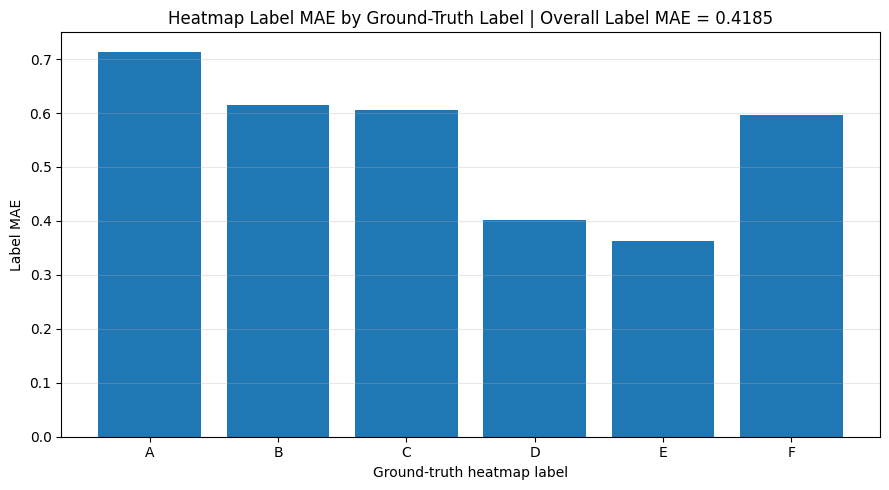

Saved per-label MAE plot:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/heatmap_label_mae_by_gt_label_idw_power5_rounding_round.png


In [ ]:
# Plot per-label heatmap MAE
# evaluate_heatmap_error() tuple structure:
# item 0 = grid-cell comparison table
# item 1 = overall metrics
# item 2 = per-label metrics
# item 3 = per-cluster metrics

# Extract per-label and overall tables
heatmap_grid_comparison = heatmap_error_results[0]
heatmap_overall_metrics = heatmap_error_results[1]
heatmap_per_label_metrics = heatmap_error_results[2]
heatmap_per_cluster_metrics = heatmap_error_results[3]

display(heatmap_overall_metrics)
display(heatmap_per_label_metrics)

# Prepare per-label plot
plot_df = heatmap_per_label_metrics.copy()
plot_df["True_Heatmap_Label"] = pd.to_numeric(plot_df["True_Heatmap_Label"], errors="coerce")
plot_df["Label_MAE"] = pd.to_numeric(plot_df["Label_MAE"], errors="coerce")
plot_df = plot_df.dropna(subset=["True_Heatmap_Label", "Label_MAE"])
plot_df = plot_df.sort_values("True_Heatmap_Label")

label_name_map = {
    3: "A",
    4: "B",
    5: "C",
    6: "D",
    7: "E",
    8: "F"
}

plot_df["Plot_Label"] = plot_df["True_Heatmap_Label"].astype(int).map(label_name_map)

overall_label_mae = float(heatmap_overall_metrics["Label_MAE"].iloc[0])
rounding_method_used = str(heatmap_overall_metrics["Rounding_Method"].iloc[0])

# Plot
plt.figure(figsize=(9, 5))
plt.bar(plot_df["Plot_Label"], plot_df["Label_MAE"])

plt.xlabel("Ground-truth heatmap label")
plt.ylabel("Label MAE")
plt.title(
    f"Heatmap Label MAE by Ground-Truth Label "
    f"| Overall Label MAE = {overall_label_mae:.4f}"
)

plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

plot_path = os.path.join(
    heatmap_output_folder,
    f"heatmap_label_mae_by_gt_label_idw_power{power}_rounding_{rounding_method_used}.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved per-label MAE plot:")
print(plot_path)

With IDW power 5 and rounding, the full-dataset heatmaps agreed on the exact label in 58.5% of the 720,000 grid cells and within one label in 99.7%, with label MAE 0.419, RMSE 0.652 and bias −0.159 (12.7% of cells overestimated, 28.9% underestimated). The per-label pattern matches the image-level results: cells with ground-truth labels 3 to 6 were labelled too high (bias +0.71, +0.62, +0.61 and +0.33) and cells with labels 7 and 8 too low (−0.35 and −0.60), and label 8 was matched exactly in 40.3% of its cells. The disagreement is concentrated in a few clusters. In cluster 4 (16 images) the predicted heatmap was one label lower almost everywhere (exact agreement 0.2%, bias −0.998), and in cluster 3 (7 images) it was higher in 39.9% of cells, while clusters 0 to 2, which hold most of the images, had exact agreement between 73.8% and 89.0%.

## 11. Heatmap error and distance to the nearest observation

An interpolated value far from any photograph is an extrapolation from the nearest scores, so larger disagreement between the predicted and ground-truth heatmaps might be expected there. For every grid cell of the test-subset heatmaps we compute the distance in metres to the nearest geotagged test image, using an equirectangular approximation centred on the images (adequate at the scale of a cluster), and relate it to the absolute difference between the two heatmaps with Spearman and Pearson correlations, overall and per cluster. The 45 non-noise test images serve as observation points. With 90,000 cells per cluster almost any correlation is formally significant, so the size and sign of the coefficients are more informative than the p-values.

In [ ]:
# Heatmap error vs distance to nearest observation point
def map_error_vs_data_distance(
    pred_heatmap_csv,
    gt_heatmap_csv,
    points_csv,
    output_folder=None,
    save_name="heatmap_error_vs_distance_to_points",
    cluster_id=None,
    heatmap_lat_col="Latitude",
    heatmap_lon_col="Longitude",
    heatmap_value_col="Interpolated",
    heatmap_cluster_col="Cluster",
    points_lat_col="Latitude_GT",
    points_lon_col="Longitude_GT",
    points_cluster_col="Cluster",
    coord_round=10,
    show_plot=True
):
    """
    Tests whether interpolated heatmap error increases with distance from
    the nearest original observation point.

    This compares:
        abs_error = |Predicted interpolated value - GT interpolated value|

    against:
        distance_to_nearest_observation

    Parameters
    ----------
    pred_heatmap_csv : str
        Predicted interpolated heatmap CSV.
        Expected columns:
        - Latitude
        - Longitude
        - Interpolated
        - Cluster

    gt_heatmap_csv : str
        GT interpolated heatmap CSV.
        Expected columns:
        - Latitude
        - Longitude
        - Interpolated
        - Cluster

    points_csv : str
        Original clustered point CSV used for interpolation.
        Usually:
        test_gt_pred_weighted_average_spatial_only_with_clusters.csv

    output_folder : str or None
        Folder to save outputs.

    save_name : str
        Base name for saved outputs.

    cluster_id : int or None
        If None, analyzes all non-noise clusters together.
        If int, analyzes only that cluster.

    points_lat_col, points_lon_col : str
        Coordinate columns in the original point CSV.
        For your merged test CSV usually:
        Latitude_GT, Longitude_GT

    Returns
    -------
    metrics_df : pandas.DataFrame
        Overall summary metrics.

    per_cluster_df : pandas.DataFrame
        Per-cluster summary metrics.

    merged : pandas.DataFrame
        Heatmap grid cells with error and nearest-point distance.
    """

    # 1. Load heatmaps
    pred = pd.read_csv(pred_heatmap_csv)
    gt = pd.read_csv(gt_heatmap_csv)

    pred.columns = pred.columns.str.strip()
    gt.columns = gt.columns.str.strip()

    print("Pred heatmap:", pred_heatmap_csv)
    print("Pred shape:", pred.shape)

    print("\nGT heatmap:", gt_heatmap_csv)
    print("GT shape:", gt.shape)

    required_heatmap_cols = [
        heatmap_lat_col,
        heatmap_lon_col,
        heatmap_value_col,
        heatmap_cluster_col
    ]

    for name, df in [("Pred", pred), ("GT", gt)]:
        missing = [col for col in required_heatmap_cols if col not in df.columns]
        if missing:
            raise ValueError(
                f"{name} heatmap CSV missing columns: {missing}\n"
                f"Available columns: {list(df.columns)}"
            )

    # 2. Clean heatmap columns
    for df in [pred, gt]:
        df[heatmap_lat_col] = pd.to_numeric(df[heatmap_lat_col], errors="coerce")
        df[heatmap_lon_col] = pd.to_numeric(df[heatmap_lon_col], errors="coerce")
        df[heatmap_value_col] = pd.to_numeric(df[heatmap_value_col], errors="coerce")
        df[heatmap_cluster_col] = pd.to_numeric(df[heatmap_cluster_col], errors="coerce")

        df.dropna(
            subset=[
                heatmap_lat_col,
                heatmap_lon_col,
                heatmap_value_col,
                heatmap_cluster_col
            ],
            inplace=True
        )

        df[heatmap_cluster_col] = df[heatmap_cluster_col].astype(int)

        df["Latitude_round"] = df[heatmap_lat_col].round(coord_round)
        df["Longitude_round"] = df[heatmap_lon_col].round(coord_round)

    # 3. Merge pred and GT heatmaps
    pred_small = pred[
        [
            heatmap_lat_col,
            heatmap_lon_col,
            "Latitude_round",
            "Longitude_round",
            heatmap_cluster_col,
            heatmap_value_col
        ]
    ].copy()

    gt_small = gt[
        [
            heatmap_lat_col,
            heatmap_lon_col,
            "Latitude_round",
            "Longitude_round",
            heatmap_cluster_col,
            heatmap_value_col
        ]
    ].copy()

    pred_small = pred_small.rename(
        columns={
            heatmap_lat_col: "Latitude_pred_grid",
            heatmap_lon_col: "Longitude_pred_grid",
            heatmap_cluster_col: "Cluster",
            heatmap_value_col: "Interpolated_pred"
        }
    )

    gt_small = gt_small.rename(
        columns={
            heatmap_lat_col: "Latitude_gt_grid",
            heatmap_lon_col: "Longitude_gt_grid",
            heatmap_cluster_col: "Cluster",
            heatmap_value_col: "Interpolated_gt"
        }
    )

    merged = pred_small.merge(
        gt_small,
        on=["Latitude_round", "Longitude_round", "Cluster"],
        how="inner"
    )

    print("\nMatched heatmap grid cells:", len(merged))

    if merged.empty:
        raise ValueError(
            "No matching heatmap grid cells found. "
            "Check that pred and GT heatmaps were created with the same grid_res, buffer_m, and clusters."
        )

    merged["Latitude"] = merged["Latitude_gt_grid"]
    merged["Longitude"] = merged["Longitude_gt_grid"]

    # Optional cluster filter
    if cluster_id is not None:
        merged = merged[merged["Cluster"] == cluster_id].copy()

        if merged.empty:
            raise ValueError(f"No heatmap grid cells found for cluster {cluster_id}.")

    # 4. Calculate heatmap errors
    merged["Raw_Error"] = merged["Interpolated_pred"] - merged["Interpolated_gt"]
    merged["Absolute_Error"] = merged["Raw_Error"].abs()
    merged["Squared_Error"] = merged["Raw_Error"] ** 2

    merged["Relative_Error"] = np.where(
        merged["Interpolated_gt"].abs() > 1e-10,
        merged["Raw_Error"] / merged["Interpolated_gt"],
        np.nan
    )

    merged["Relative_Absolute_Error"] = merged["Relative_Error"].abs()

    # 5. Load original observation points
    pts = pd.read_csv(points_csv)
    pts.columns = pts.columns.str.strip()

    print("\nPoints CSV:", points_csv)
    print("Points shape:", pts.shape)

    # Allow fallback to Latitude/Longitude if GT columns not found
    if points_lat_col not in pts.columns or points_lon_col not in pts.columns:
        if "Latitude" in pts.columns and "Longitude" in pts.columns:
            print(
                f"⚠️ {points_lat_col}/{points_lon_col} not found. "
                "Using Latitude/Longitude instead."
            )
            points_lat_col = "Latitude"
            points_lon_col = "Longitude"
        else:
            raise ValueError(
                f"Point CSV must contain either {points_lat_col}/{points_lon_col} "
                f"or Latitude/Longitude.\nAvailable columns: {list(pts.columns)}"
            )

    required_point_cols = [points_lat_col, points_lon_col]

    if points_cluster_col in pts.columns:
        required_point_cols.append(points_cluster_col)

    for col in required_point_cols:
        pts[col] = pd.to_numeric(pts[col], errors="coerce")

    pts = pts.dropna(subset=required_point_cols).copy()

    if points_cluster_col in pts.columns:
        pts[points_cluster_col] = pts[points_cluster_col].astype(int)

    # Optional cluster filter
    if cluster_id is not None and points_cluster_col in pts.columns:
        pts = pts[pts[points_cluster_col] == cluster_id].copy()

    # Remove noise points if cluster column exists and analyzing all clusters
    if cluster_id is None and points_cluster_col in pts.columns:
        pts = pts[pts[points_cluster_col] != -1].copy()

    if pts.empty:
        raise ValueError("No valid observation points remain after cleaning/filtering.")

    print("Valid observation points used:", len(pts))

    # 6. Convert lat/lon to approximate local meters
    # We use an equirectangular approximation centered on the point set.
    # This is accurate enough for small regional clusters.
    lat0 = np.deg2rad(pts[points_lat_col].mean())

    def lonlat_to_local_meters(lon, lat):
        lon = np.asarray(lon, dtype=float)
        lat = np.asarray(lat, dtype=float)

        x = lon * 111_320.0 * np.cos(lat0)
        y = lat * 110_540.0

        return np.column_stack([x, y])

    obs_coords_m = lonlat_to_local_meters(
        pts[points_lon_col].values,
        pts[points_lat_col].values
    )

    grid_coords_m = lonlat_to_local_meters(
        merged["Longitude"].values,
        merged["Latitude"].values
    )

    # 7. Distance to nearest observation point
    tree = cKDTree(obs_coords_m)

    dist_to_obs_m, nearest_idx = tree.query(
        grid_coords_m,
        k=1
    )

    merged["Distance_To_Nearest_Observation_m"] = dist_to_obs_m
    merged["Nearest_Observation_Index"] = nearest_idx

    # Optional: add nearest observation cluster if available
    if points_cluster_col in pts.columns:
        pts_reset = pts.reset_index(drop=True)
        merged["Nearest_Observation_Cluster"] = pts_reset.loc[
            nearest_idx,
            points_cluster_col
        ].values

    # 8. Correlations
    valid = merged.dropna(
        subset=["Distance_To_Nearest_Observation_m", "Absolute_Error"]
    ).copy()

    if len(valid) < 2:
        spearman_rho = np.nan
        spearman_p = np.nan
        pearson_r = np.nan
        pearson_p = np.nan
    else:
        spearman_rho, spearman_p = spearmanr(
            valid["Distance_To_Nearest_Observation_m"],
            valid["Absolute_Error"],
            nan_policy="omit"
        )

        pearson_r, pearson_p = pearsonr(
            valid["Distance_To_Nearest_Observation_m"],
            valid["Absolute_Error"]
        )

    metrics_df = pd.DataFrame([{
        "Cluster_Filter": cluster_id if cluster_id is not None else "all",
        "N_Grid_Cells": len(valid),
        "N_Observation_Points": len(pts),
        "Mean_Distance_To_Nearest_Observation_m": valid["Distance_To_Nearest_Observation_m"].mean(),
        "Median_Distance_To_Nearest_Observation_m": valid["Distance_To_Nearest_Observation_m"].median(),
        "Max_Distance_To_Nearest_Observation_m": valid["Distance_To_Nearest_Observation_m"].max(),
        "Mean_Absolute_Error": valid["Absolute_Error"].mean(),
        "Median_Absolute_Error": valid["Absolute_Error"].median(),
        "Max_Absolute_Error": valid["Absolute_Error"].max(),
        "Bias": valid["Raw_Error"].mean(),
        "Spearman_Rho_Distance_vs_AbsError": spearman_rho,
        "Spearman_PValue": spearman_p,
        "Pearson_R_Distance_vs_AbsError": pearson_r,
        "Pearson_PValue": pearson_p
    }])

    print("\nDistance-vs-error metrics:")
    display(metrics_df)

    # 9. Per-cluster distance/error metrics
    per_cluster_rows = []

    for c, group in valid.groupby("Cluster"):
        if len(group) < 2:
            rho = np.nan
            pval = np.nan
            r = np.nan
            rpval = np.nan
        else:
            rho, pval = spearmanr(
                group["Distance_To_Nearest_Observation_m"],
                group["Absolute_Error"],
                nan_policy="omit"
            )

            r, rpval = pearsonr(
                group["Distance_To_Nearest_Observation_m"],
                group["Absolute_Error"]
            )

        per_cluster_rows.append({
            "Cluster": c,
            "N_Grid_Cells": len(group),
            "Mean_Distance_To_Nearest_Observation_m": group["Distance_To_Nearest_Observation_m"].mean(),
            "Median_Distance_To_Nearest_Observation_m": group["Distance_To_Nearest_Observation_m"].median(),
            "Max_Distance_To_Nearest_Observation_m": group["Distance_To_Nearest_Observation_m"].max(),
            "Mean_Absolute_Error": group["Absolute_Error"].mean(),
            "Median_Absolute_Error": group["Absolute_Error"].median(),
            "Max_Absolute_Error": group["Absolute_Error"].max(),
            "Bias": group["Raw_Error"].mean(),
            "Spearman_Rho_Distance_vs_AbsError": rho,
            "Spearman_PValue": pval,
            "Pearson_R_Distance_vs_AbsError": r,
            "Pearson_PValue": rpval
        })

    per_cluster_df = pd.DataFrame(per_cluster_rows)

    print("\nPer-cluster distance-vs-error metrics:")
    display(per_cluster_df)

    # 10. Save tables
    if output_folder is not None:
        os.makedirs(output_folder, exist_ok=True)

        merged_path = os.path.join(
            output_folder,
            f"{save_name}_grid_error_distance_table.csv"
        )

        metrics_path = os.path.join(
            output_folder,
            f"{save_name}_overall_metrics.csv"
        )

        per_cluster_path = os.path.join(
            output_folder,
            f"{save_name}_per_cluster_metrics.csv"
        )

        merged.to_csv(merged_path, index=False)
        metrics_df.to_csv(metrics_path, index=False)
        per_cluster_df.to_csv(per_cluster_path, index=False)

        print("\nSaved tables:")
        print(merged_path)
        print(metrics_path)
        print(per_cluster_path)

    # 11. Scatter plot
    plt.style.use("seaborn-v0_8")

    fig, ax = plt.subplots(figsize=(10, 6))

    # Downsample plotting if very large, to keep notebook responsive
    max_plot_points = 50_000

    if len(valid) > max_plot_points:
        plot_df = valid.sample(max_plot_points, random_state=42)
    else:
        plot_df = valid

    ax.scatter(
        plot_df["Distance_To_Nearest_Observation_m"],
        plot_df["Absolute_Error"],
        alpha=0.25,
        s=8
    )

    ax.set_xlabel("Distance to nearest observation point (m)")
    ax.set_ylabel("Absolute heatmap error")
    ax.set_title(
        "Heatmap Error vs Distance to Nearest Observation\n"
        f"Spearman ρ = {spearman_rho:.3f}, Pearson r = {pearson_r:.3f}"
    )

    ax.grid(True, alpha=0.3)

    fig.tight_layout()

    if output_folder is not None:
        plot_path = os.path.join(
            output_folder,
            f"{save_name}_scatter.png"
        )

        fig.savefig(plot_path, dpi=300, bbox_inches="tight")
        print("Saved plot:")
        print(plot_path)

    if show_plot:
        plt.show()
    else:
        plt.close()

    return metrics_df, per_cluster_df, merged

Pred heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/pred_test_weighted_average_idw_power1_heatmap.csv
Pred shape: (270000, 9)

GT heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/heatmaps/gt_test_weighted_average_idw_power1_heatmap.csv
GT shape: (270000, 9)

Matched heatmap grid cells: 270000

Points CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/test_gt_pred_weighted_average_spatial_only_with_clusters.csv
Points shape: (53, 19)
Valid observation points used: 45

Distance-vs-error metrics:


,Cluster_Filter,N_Grid_Cells,N_Observation_Points,Mean_Distance_To_Nearest_Observation_m,Median_Distance_To_Nearest_Observation_m,Max_Distance_To_Nearest_Observation_m,Mean_Absolute_Error,Median_Absolute_Error,Max_Absolute_Error,Bias,Spearman_Rho_Distance_vs_AbsError,Spearman_PValue,Pearson_R_Distance_vs_AbsError,Pearson_PValue
0,all,270000,45,575.445878,525.316921,1750.027927,0.19921,0.171237,2.594339,-0.047921,-0.169395,0.0,-0.247804,0.0



Per-cluster distance-vs-error metrics:


,Cluster,N_Grid_Cells,Mean_Distance_To_Nearest_Observation_m,Median_Distance_To_Nearest_Observation_m,Max_Distance_To_Nearest_Observation_m,Mean_Absolute_Error,Median_Absolute_Error,Max_Absolute_Error,Bias,Spearman_Rho_Distance_vs_AbsError,Spearman_PValue,Pearson_R_Distance_vs_AbsError,Pearson_PValue
0,0,90000,501.051591,462.686904,1647.724443,0.183306,0.172099,1.154060,0.181137,0.047531,3.503825e-46,-0.067590,1.286341e-91
1,1,90000,552.680666,510.136891,1636.939957,0.295857,0.244744,1.289282,-0.291106,0.158687,0.000000e+00,-0.130518,0.000000e+00
2,2,90000,672.605377,625.206154,1750.027927,0.118467,0.097657,2.594339,-0.033793,-0.512936,0.000000e+00,-0.426969,0.000000e+00



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/distance_error_analysis/weighted_average_idw_power1_error_vs_distance_grid_error_distance_table.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/distance_error_analysis/weighted_average_idw_power1_error_vs_distance_overall_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/distance_error_analysis/weighted_average_idw_power1_error_vs_distance_per_cluster_metrics.csv
Saved plot:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/distance_error_analysis/weighted_average_idw_power1_error_vs_distance_scatter.png


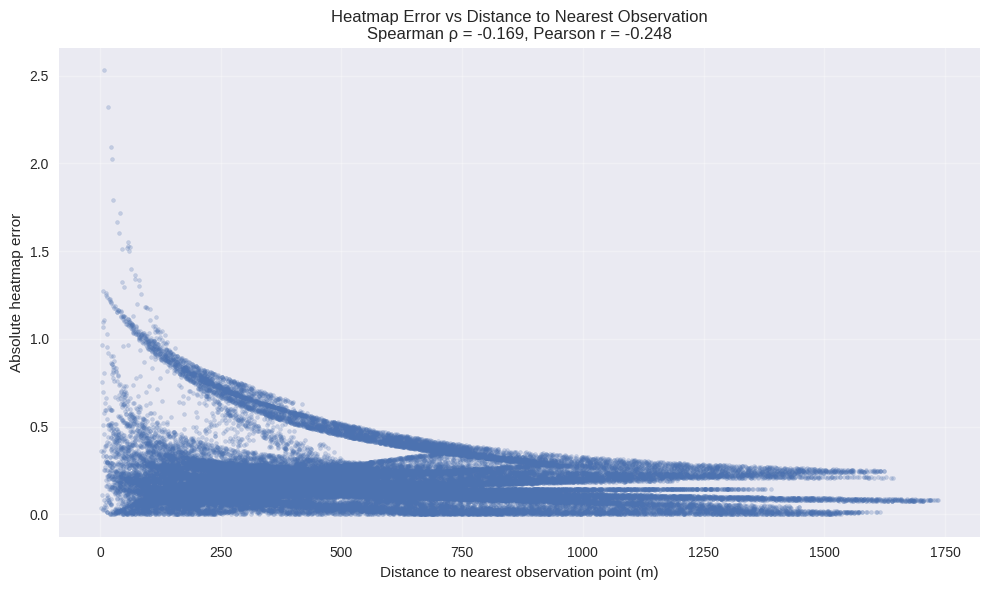

In [ ]:
distance_error_output_folder = DISTANCE_ERROR_DIR

pred_power1_csv = os.path.join(TEST_HEATMAP_DIR, "pred_test_weighted_average_idw_power1_heatmap.csv")
gt_power1_csv = os.path.join(TEST_HEATMAP_DIR, "gt_test_weighted_average_idw_power1_heatmap.csv")

metrics_dist_power1, per_cluster_dist_power1, merged_dist_power1 = map_error_vs_data_distance(
    pred_heatmap_csv=pred_power1_csv,
    gt_heatmap_csv=gt_power1_csv,
    points_csv=TEST_SPATIAL_CLUSTERED_CSV,
    output_folder=distance_error_output_folder,
    save_name="weighted_average_idw_power1_error_vs_distance",
    cluster_id=None,
    points_lat_col="Latitude_GT",
    points_lon_col="Longitude_GT",
    points_cluster_col="Cluster",
    show_plot=True
)

Pred heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/generated_heatmaps/pred_test_weighted_average_idw_power5_heatmap.csv
Pred shape: (270000, 9)

GT heatmap: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/interpolation_method_similarity/generated_heatmaps/gt_test_weighted_average_idw_power5_heatmap.csv
GT shape: (270000, 9)

Matched heatmap grid cells: 270000

Points CSV: /content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/test_gt_pred_weighted_average_spatial_only_with_clusters.csv
Points shape: (53, 19)
Valid observation points used: 45

Distance-vs-error metrics:


,Cluster_Filter,N_Grid_Cells,N_Observation_Points,Mean_Distance_To_Nearest_Observation_m,Median_Distance_To_Nearest_Observation_m,Max_Distance_To_Nearest_Observation_m,Mean_Absolute_Error,Median_Absolute_Error,Max_Absolute_Error,Bias,Spearman_Rho_Distance_vs_AbsError,Spearman_PValue,Pearson_R_Distance_vs_AbsError,Pearson_PValue
0,all,270000,45,575.445878,525.316921,1750.027927,0.383297,0.25678,2.908095,-0.128815,-0.175289,0.0,-0.238498,0.0



Per-cluster distance-vs-error metrics:


,Cluster,N_Grid_Cells,Mean_Distance_To_Nearest_Observation_m,Median_Distance_To_Nearest_Observation_m,Max_Distance_To_Nearest_Observation_m,Mean_Absolute_Error,Median_Absolute_Error,Max_Absolute_Error,Bias,Spearman_Rho_Distance_vs_AbsError,Spearman_PValue,Pearson_R_Distance_vs_AbsError,Pearson_PValue
0,0,90000,501.051591,462.686904,1647.724443,0.291822,0.191382,1.344434,0.181008,-0.318948,0.0,-0.319258,0.0
1,1,90000,552.680666,510.136891,1636.939957,0.447930,0.262622,1.304582,-0.347630,-0.156098,0.0,-0.223608,0.0
2,2,90000,672.605377,625.206154,1750.027927,0.410138,0.281033,2.908095,-0.219823,-0.216862,0.0,-0.297276,0.0



Saved tables:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/distance_error_analysis/weighted_average_idw_power5_error_vs_distance_grid_error_distance_table.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/distance_error_analysis/weighted_average_idw_power5_error_vs_distance_overall_metrics.csv
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/distance_error_analysis/weighted_average_idw_power5_error_vs_distance_per_cluster_metrics.csv
Saved plot:
/content/drive/MyDrive/segformer_checkpoints/spatial_prediction_error_analysis/distance_error_analysis/weighted_average_idw_power5_error_vs_distance_scatter.png


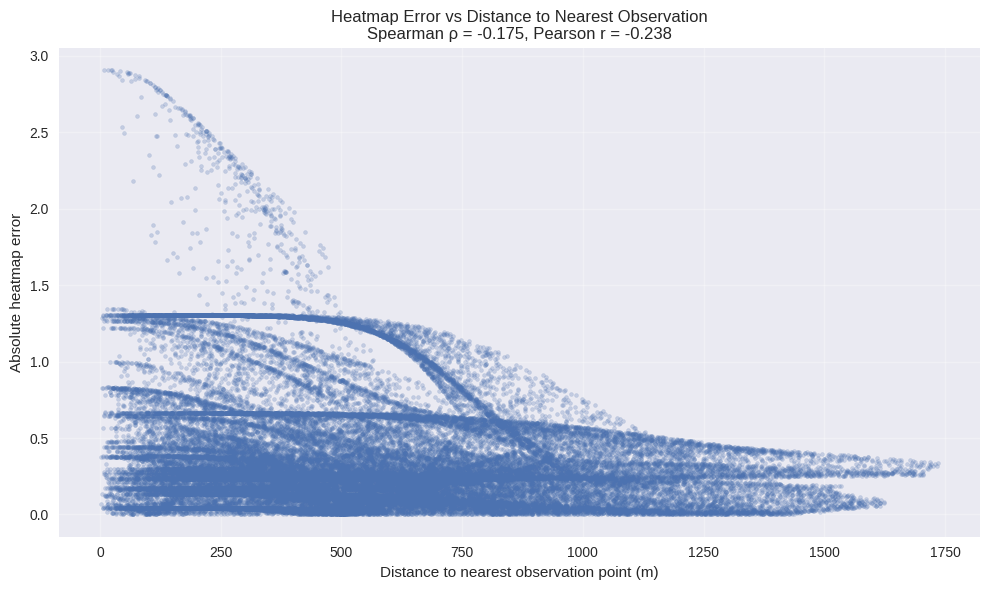

In [ ]:
pred_power5_csv = os.path.join(TEST_HEATMAP_DIR, "pred_test_weighted_average_idw_power5_heatmap.csv")
gt_power5_csv = os.path.join(TEST_HEATMAP_DIR, "gt_test_weighted_average_idw_power5_heatmap.csv")

metrics_dist_power5, per_cluster_dist_power5, merged_dist_power5 = map_error_vs_data_distance(
    pred_heatmap_csv=pred_power5_csv,
    gt_heatmap_csv=gt_power5_csv,
    points_csv=TEST_SPATIAL_CLUSTERED_CSV,
    output_folder=distance_error_output_folder,
    save_name="weighted_average_idw_power5_error_vs_distance",
    cluster_id=None,
    points_lat_col="Latitude_GT",
    points_lon_col="Longitude_GT",
    points_cluster_col="Cluster",
    show_plot=True
)

The second cell, for IDW power 5, is Figure 11 of the manuscript. The Spearman ρ = −0.175 and Pearson r = −0.238 indicate that larger errors were not primarily caused by distance from image observations. Instead, errors were often local and appeared near observation points, consistent with the behaviour of high-power IDW interpolation, which strongly preserves nearby prediction differences. This suggests that heatmap errors mainly reflect local prediction discrepancies between the ground-truth and model-derived weighted-average scores, rather than spatial extrapolation uncertainty. The coefficients were negative in all three clusters (ρ = −0.32, −0.16 and −0.22). The supplementary power 1 run gives a similar overall result (ρ = −0.169, r = −0.248), with positive coefficients in clusters 0 and 1 and a negative one in cluster 2.

## 12. Summary

At the image level, weighted-average aggregation was more accurate than mode aggregation. On the 59 test images the mode had an MAE of 1.000 damage classes, while the continuous weighted-average score reduced the MAE to 0.565 and the RMSE to 0.782. The weighted-average bias was close to zero (0.027), indicating little systematic over- or underestimation overall, although the direction depended on the true class: the lower classes A to C were overestimated and E and F underestimated. Notebook 01 shows that the rounded weighted average also outperformed the mode in balanced accuracy. Because a weighted average can yield a class that is not present in the image, the mode may still be the more useful label operationally.

Label frequency did not explain the per-label errors. The test set was representative of the full dataset, and the clearest difference between predicted and annotated masks was the larger number of classes in the predictions.

The choice of interpolation method was strongly affected by the heterogeneous nature of building damage. LOOCV favoured low IDW powers (lowest MAE at power 1.5 for weighted-average scores and at power 2 for mode scores), but higher-power IDW preserved local spatial variation better and gave the highest agreement between predicted and ground-truth heatmaps, and kriging did not provide a consistently superior result. IDW power 5 was therefore selected for the final heatmaps. Over the full geotagged dataset the predicted heatmap had a 2D correlation of 0.808 with the ground-truth heatmap and an MAE of 0.365: it captured the broad spatial structure of damage, although local errors remained, concentrated in a few clusters. The heatmap error was not driven by distance from the photographs.

The supplementary test-subset analyses with IDW powers 1 and 2 (2D correlation 0.954 and 0.894) and the label-level comparisons show the same pattern: adjacent-label accuracy of at least 99.7% in each overall label-level result printed above, with low labels pushed up and high labels pulled down in the predicted heatmap.

To apply the workflow to another dataset, replace the Kaggle datasets and the notebook 01 tables with image-level ground-truth and predicted scores and GPS coordinates for the new images, adapt `DAMAGE_LABELS` and the label maps in the helpers to the damage scale, choose a DBSCAN radius that matches the survey spacing, project the coordinates if the area is large, and compare interpolators by both LOOCV and heatmap agreement before settling on one.